<a href="https://colab.research.google.com/github/aamirrajput/Github-Aameri/blob/main/Azykh_Cave_1_LOG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

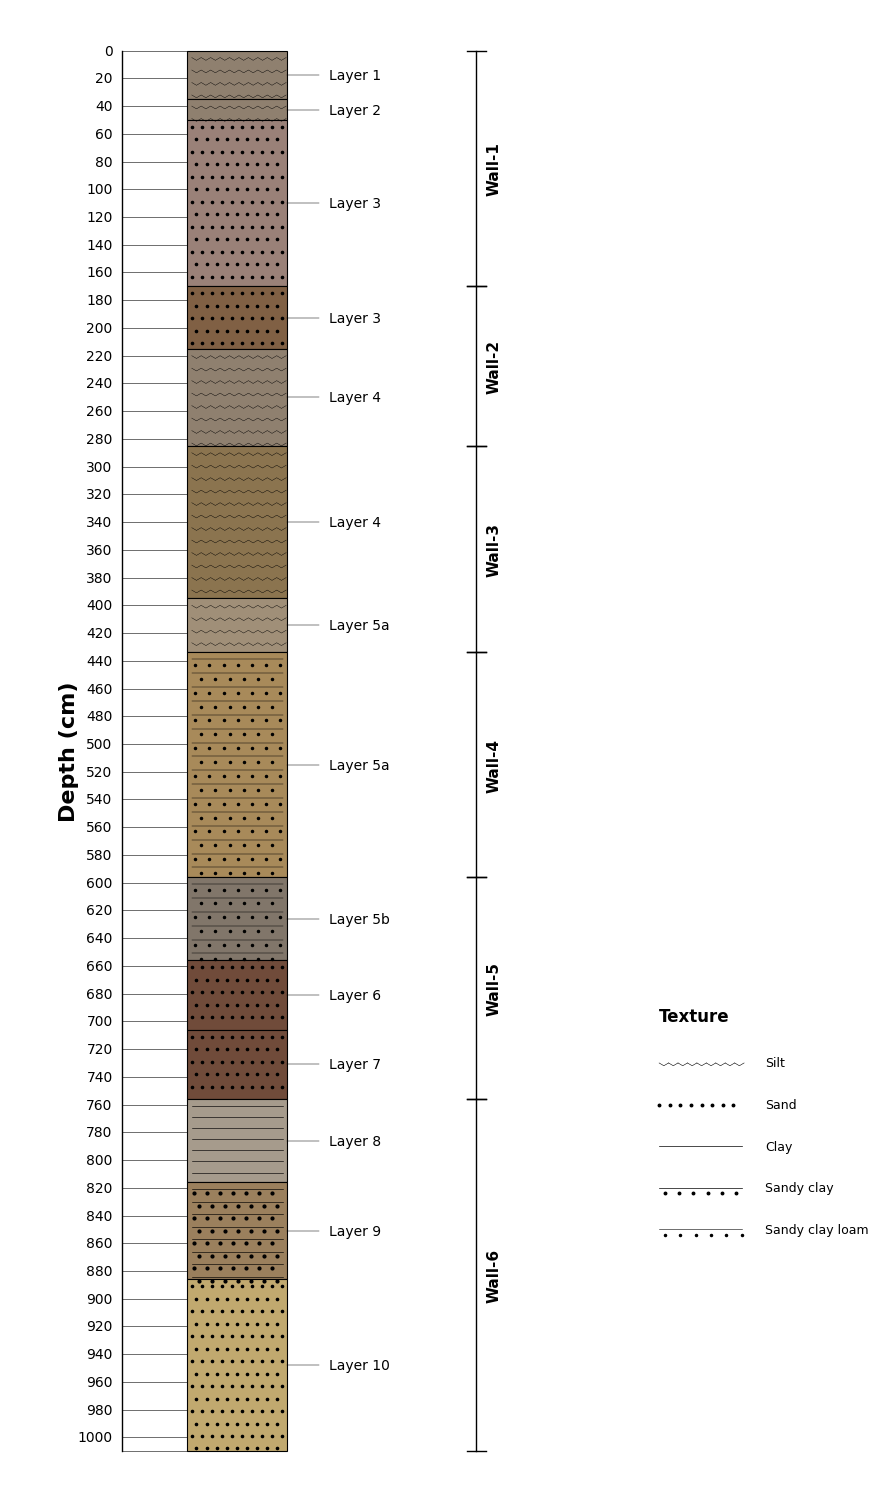

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# ============================================================
# 1. LAYER DATA
# ============================================================

layers = [
    (0,    35,   "#8F806F", "Silt loam",       "Layer 1",  "Wall-1"),
    (35,   50,   "#8F806F", "Silt loam",       "Layer 2",  "Wall-1"),
    (50,   170,  "#9A8178", "Sandy loam",      "Layer 3",  "Wall-1"),

    (170,  215,  "#806044", "Sandy loam",      "Layer 3",  "Wall-2"),
    (215,  285,  "#8F806F", "Silt loam",       "Layer 4",  "Wall-2"),

    (285,  395,  "#8B744F", "Silt loam",       "Layer 4",  "Wall-3"),
    (395,  434,  "#A08F78", "Silt loam",       "Layer 5a", "Wall-3"),

    (434,  596,  "#A88A5A", "Sandy clay loam", "Layer 5a", "Wall-4"),

    (596,  656,  "#81766A", "Sandy clay loam", "Layer 5b", "Wall-5"),
    (656,  706,  "#704B3A", "Sandy loam",      "Layer 6",  "Wall-5"),
    (706,  756,  "#704B3A", "Sandy loam",      "Layer 7",  "Wall-5"),

    (756,  816,  "#A69B8C", "Clay loam",       "Layer 8",  "Wall-6"),
    (816,  886,  "#9B805D", "Sandy clay",      "Layer 9",  "Wall-6"),
    (886, 1010, "#C1A96F", "Sandy loam",       "Layer 10", "Wall-6"),
]

# ============================================================
# 2. WALL INTERVALS
# ============================================================

walls = [
    ("Wall-1", 0, 170),
    ("Wall-2", 170, 285),
    ("Wall-3", 285, 434),
    ("Wall-4", 434, 596),
    ("Wall-5", 596, 756),
    ("Wall-6", 756, 1010),
]

# ============================================================
# 3. FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(9, 15))

# Main log position
x = 0
width = 0.85

# Depth scale
scale_x = -0.55

# Layer label position
layer_x = 1.20

# Wall label position
wall_x = 2.45

# ============================================================
# 4. ONE CONTINUOUS LITHOLOGICAL LOG
# ============================================================

for top, bottom, colour, texture, layer_name, wall_name in layers:

    # --------------------------------------------------------
    # Main lithological unit
    # --------------------------------------------------------

    ax.add_patch(
        Rectangle(
            (x, top),
            width,
            bottom - top,
            facecolor=colour,
            edgecolor="black",
            linewidth=0.8
        )
    )

    # ========================================================
    # SILT LOAM
    # Pattern: .-.-.-.-.-.-.
    # ========================================================

    if texture == "Silt loam":

        for yy in range(int(top) + 5, int(bottom), 9):

            current_x = x + 0.04

            xs = []
            ys = []

            while current_x < x + width - 0.04:

                step = 0.08

                xs.extend([
                    current_x,
                    current_x + step / 2,
                    current_x + step
                ])

                ys.extend([
                    yy,
                    yy + 2,
                    yy
                ])

                current_x += step

            ax.plot(
                xs,
                ys,
                color="black",
                linewidth=0.3
            )

    # ========================================================
    # SANDY LOAM
    # Dense sand particles
    # ========================================================

    elif texture == "Sandy loam":

        for row, yy in enumerate(
            range(int(top) + 5, int(bottom), 9)
        ):

            start_x = x + 0.04

            if row % 2 == 1:
                start_x += 0.04

            current_x = start_x

            while current_x < x + width - 0.03:

                ax.plot(
                    current_x,
                    yy,
                    marker="o",
                    markersize=1.6,
                    markerfacecolor="black",
                    markeredgecolor="black",
                    linewidth=0
                )

                current_x += 0.085

    # ========================================================
    # SANDY CLAY LOAM
    # Clay lines + sand particles
    # ========================================================

    elif texture == "Sandy clay loam":

        for row, yy in enumerate(
            range(int(top) + 5, int(bottom), 10)
        ):

            # Clay line
            ax.plot(
                [x + 0.04, x + width - 0.04],
                [yy, yy],
                color="black",
                linewidth=0.35
            )

            # Sand particles
            start_x = x + 0.07

            if row % 2 == 1:
                start_x += 0.05

            current_x = start_x

            while current_x < x + width - 0.03:

                ax.plot(
                    current_x,
                    yy + 4,
                    marker="o",
                    markersize=1.5,
                    markerfacecolor="black",
                    markeredgecolor="black",
                    linewidth=0
                )

                current_x += 0.12

    # ========================================================
    # CLAY LOAM
    # Horizontal clay lines
    # ========================================================

    elif texture == "Clay loam":

        for yy in range(int(top) + 5, int(bottom), 8):

            ax.plot(
                [x + 0.04, x + width - 0.04],
                [yy, yy],
                color="black",
                linewidth=0.45
            )

    # ========================================================
    # SANDY CLAY
    # Clay lines + prominent sand particles
    # ========================================================

    elif texture == "Sandy clay":

        for row, yy in enumerate(
            range(int(top) + 5, int(bottom), 9)
        ):

            # Clay line
            ax.plot(
                [x + 0.04, x + width - 0.04],
                [yy, yy],
                color="black",
                linewidth=0.45
            )

            # Sand particles
            start_x = x + 0.06

            if row % 2 == 1:
                start_x += 0.04

            current_x = start_x

            while current_x < x + width - 0.03:

                ax.plot(
                    current_x,
                    yy + 3,
                    marker="o",
                    markersize=2.0,
                    markerfacecolor="black",
                    markeredgecolor="black",
                    linewidth=0
                )

                current_x += 0.11


# ============================================================
# 5. DEPTH SCALE
# ============================================================

ax.plot(
    [scale_x, scale_x],
    [0, 1010],
    color="black",
    linewidth=1.0
)

# Depth title
ax.text(
    scale_x - 0.45,
    505,
    "Depth (cm)",
    rotation=90,
    fontsize=16,
    fontweight="bold",
    ha="center",
    va="center"
)

# Depth numbers every 20 cm
for depth in range(0, 1001, 20):

    ax.plot(
        [scale_x, x],
        [depth, depth],
        color="black",
        linewidth=0.4
    )

    ax.text(
        scale_x - 0.08,
        depth,
        str(depth),
        ha="right",
        va="center",
        fontsize=10
    )

# Bottom at 1010 cm
ax.plot(
    [scale_x, x],
    [1010, 1010],
    color="black",
    linewidth=0.4
)


# ============================================================
# 6. LAYER NAMES OUTSIDE THE LOG
# ============================================================

for top, bottom, colour, texture, layer_name, wall_name in layers:

    midpoint = (top + bottom) / 2

    # Connector
    ax.plot(
        [x + width, layer_x - 0.08],
        [midpoint, midpoint],
        color="black",
        linewidth=0.35
    )

    # Layer name
    ax.text(
        layer_x,
        midpoint,
        layer_name,
        ha="left",
        va="center",
        fontsize=10
    )


# ============================================================
# 7. WALL BRACKETS
# ============================================================

for wall_name, top, bottom in walls:

    # Vertical bracket
    ax.plot(
        [wall_x, wall_x],
        [top, bottom],
        color="black",
        linewidth=1.0
    )

    # Top bracket
    ax.plot(
        [wall_x - 0.08, wall_x + 0.08],
        [top, top],
        color="black",
        linewidth=1.0
    )

    # Bottom bracket
    ax.plot(
        [wall_x - 0.08, wall_x + 0.08],
        [bottom, bottom],
        color="black",
        linewidth=1.0
    )

    # Wall name
    ax.text(
        wall_x + 0.15,
        (top + bottom) / 2,
        wall_name,
        rotation=90,
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold"
    )


# ============================================================
# 8. TEXTURE LEGEND
# ============================================================

legend_x = 4.0
legend_y = 700

ax.text(
    legend_x,
    legend_y,
    "Texture",
    fontsize=12,
    fontweight="bold"
)

# ------------------------------------------------------------
# Silt
# ------------------------------------------------------------

y = legend_y + 30

current_x = legend_x

while current_x < legend_x + 0.7:

    ax.plot(
        [current_x, current_x + 0.04, current_x + 0.08],
        [y, y + 2, y],
        color="black",
        linewidth=0.4
    )

    current_x += 0.08

ax.text(
    legend_x + 0.9,
    y,
    "Silt",
    fontsize=9,
    va="center"
)

# ------------------------------------------------------------
# Sand
# ------------------------------------------------------------

y = legend_y + 60

current_x = legend_x

while current_x < legend_x + 0.7:

    ax.plot(
        current_x,
        y,
        marker="o",
        markersize=1.8,
        markerfacecolor="black",
        markeredgecolor="black"
    )

    current_x += 0.09

ax.text(
    legend_x + 0.9,
    y,
    "Sand",
    fontsize=9,
    va="center"
)

# ------------------------------------------------------------
# Clay
# ------------------------------------------------------------

y = legend_y + 90

ax.plot(
    [legend_x, legend_x + 0.7],
    [y, y],
    color="black",
    linewidth=0.5
)

ax.text(
    legend_x + 0.9,
    y,
    "Clay",
    fontsize=9,
    va="center"
)

# ------------------------------------------------------------
# Sandy clay
# ------------------------------------------------------------

y = legend_y + 120

ax.plot(
    [legend_x, legend_x + 0.7],
    [y, y],
    color="black",
    linewidth=0.5
)

current_x = legend_x + 0.05

while current_x < legend_x + 0.7:

    ax.plot(
        current_x,
        y + 4,
        marker="o",
        markersize=1.8,
        markerfacecolor="black",
        markeredgecolor="black"
    )

    current_x += 0.12

ax.text(
    legend_x + 0.9,
    y,
    "Sandy clay",
    fontsize=9,
    va="center"
)

# ------------------------------------------------------------
# Sandy clay loam
# ------------------------------------------------------------

y = legend_y + 150

ax.plot(
    [legend_x, legend_x + 0.7],
    [y, y],
    color="black",
    linewidth=0.4
)

current_x = legend_x + 0.05

while current_x < legend_x + 0.7:

    ax.plot(
        current_x,
        y + 4,
        marker="o",
        markersize=1.5,
        markerfacecolor="black",
        markeredgecolor="black"
    )

    current_x += 0.13

ax.text(
    legend_x + 0.9,
    y,
    "Sandy clay loam",
    fontsize=9,
    va="center"
)


# ============================================================
# 9. FINAL FORMAT
# ============================================================

ax.set_xlim(-1.5, 5.5)
ax.set_ylim(1030, -30)

ax.axis("off")

plt.tight_layout()

# ============================================================
# 10. SAVE
# ============================================================

plt.savefig(
    "Azykh_one_continuous_stratigraphic_log.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Azykh_one_continuous_stratigraphic_log.pdf",
    bbox_inches="tight"
)

plt.show()

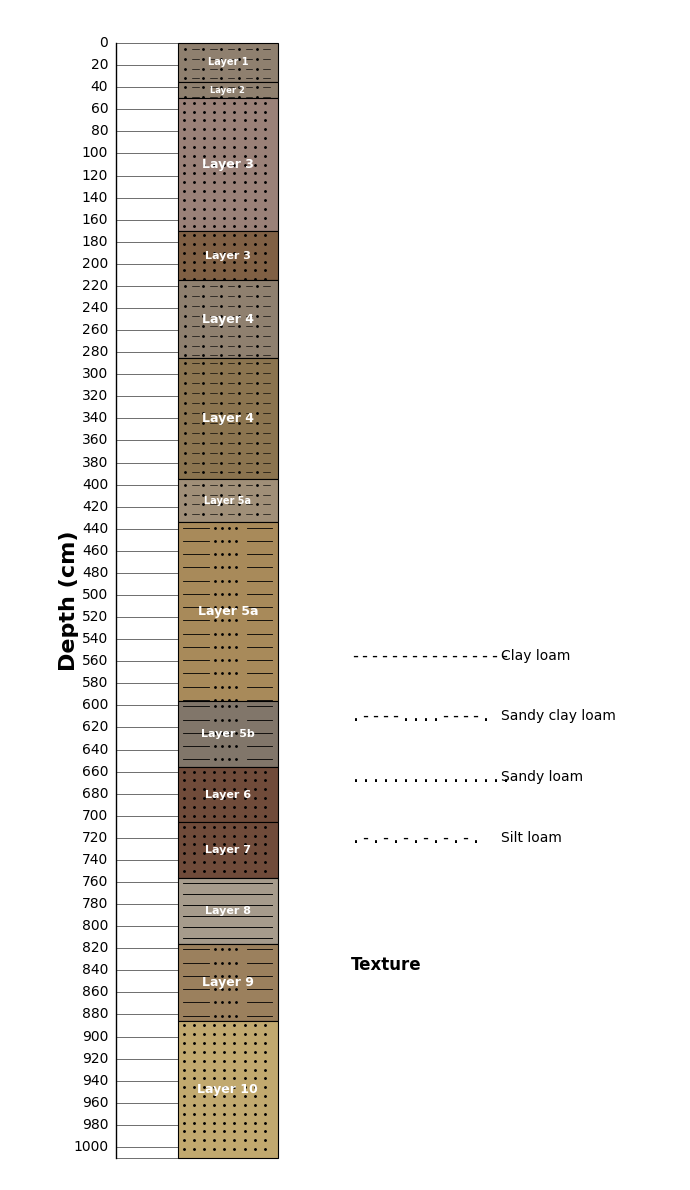

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

# ============================================================
# AZYKH CAVE — CONTINUOUS LITHOLOGICAL LOG
# 0–1010 cm
# Layer names shown INSIDE the log in WHITE
# ============================================================

layers = [
    (0,    35,   "#8F806F", "Silt loam",       "Layer 1"),
    (35,   50,   "#8F806F", "Silt loam",       "Layer 2"),
    (50,   170,  "#9A8178", "Sandy loam",      "Layer 3"),
    (170,  215,  "#806044", "Sandy loam",      "Layer 3"),
    (215,  285,  "#8F806F", "Silt loam",       "Layer 4"),
    (285,  395,  "#8B744F", "Silt loam",       "Layer 4"),
    (395,  434,  "#A08F78", "Silt loam",       "Layer 5a"),
    (434,  596,  "#A88A5A", "Sandy clay loam", "Layer 5a"),
    (596,  656,  "#81766A", "Sandy clay loam", "Layer 5b"),
    (656,  706,  "#704B3A", "Sandy loam",      "Layer 6"),
    (706,  756,  "#704B3A", "Sandy loam",      "Layer 7"),
    (756,  816,  "#A69B8C", "Clay loam",       "Layer 8"),
    (816,  886,  "#9B805D", "Sandy clay loam", "Layer 9"),
    (886, 1010, "#C1A96F", "Sandy loam",      "Layer 10"),
]

fig, ax = plt.subplots(figsize=(7, 12))

x = 0
width = 0.90

# ============================================================
# DRAW LOG
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    # Main unit
    rect = Rectangle(
        (x, top),
        width,
        bottom - top,
        facecolor=colour,
        edgecolor="black",
        linewidth=0.8
    )
    ax.add_patch(rect)

    # --------------------------------------------------------
    # SILT LOAM
    # Pattern: .-.-.-.-.-.-.
    # --------------------------------------------------------
    if texture == "Silt loam":

        for y in np.arange(top + 5, bottom, 9):

            # dots
            for xpos in np.arange(
                x + 0.07,
                x + width - 0.05,
                0.16
            ):
                ax.plot(
                    xpos, y,
                    marker=".",
                    markersize=2,
                    color="black"
                )

            # short lines
            for xpos in np.arange(
                x + 0.13,
                x + width - 0.05,
                0.16
            ):
                ax.plot(
                    [xpos, xpos + 0.06],
                    [y, y],
                    color="black",
                    linewidth=0.45
                )

    # --------------------------------------------------------
    # SANDY LOAM
    # Pattern: ................
    # --------------------------------------------------------
    elif texture == "Sandy loam":

        for y in np.arange(top + 4, bottom, 8):

            for xpos in np.arange(
                x + 0.06,
                x + width - 0.04,
                0.09
            ):
                ax.plot(
                    xpos, y,
                    marker=".",
                    markersize=2.1,
                    color="black"
                )

    # --------------------------------------------------------
    # SANDY CLAY LOAM
    # Pattern: .----....----.
    # --------------------------------------------------------
    elif texture == "Sandy clay loam":

        for y in np.arange(top + 5, bottom, 12):

            # first horizontal line
            ax.plot(
                [x + 0.05, x + 0.28],
                [y, y],
                color="black",
                linewidth=0.6
            )

            # middle dots
            for xpos in np.arange(
                x + 0.34,
                x + 0.56,
                0.06
            ):
                ax.plot(
                    xpos, y,
                    marker=".",
                    markersize=2,
                    color="black"
                )

            # second horizontal line
            ax.plot(
                [x + 0.62, x + width - 0.05],
                [y, y],
                color="black",
                linewidth=0.6
            )

    # --------------------------------------------------------
    # CLAY LOAM
    # Pattern: ----------------
    # --------------------------------------------------------
    elif texture == "Clay loam":

        for y in np.arange(top + 5, bottom, 10):

            ax.plot(
                [x + 0.05, x + width - 0.05],
                [y, y],
                color="black",
                linewidth=0.65
            )

    # ========================================================
    # LAYER NAME — WHITE INSIDE LOG
    # ========================================================

    midpoint = (top + bottom) / 2

    # Smaller text for thin units
    thickness = bottom - top

    if thickness <= 20:
        text_size = 6
    elif thickness <= 40:
        text_size = 7
    elif thickness <= 60:
        text_size = 8
    else:
        text_size = 9

    ax.text(
        x + width / 2,
        midpoint,
        layer_name,
        color="white",
        fontsize=text_size,
        fontweight="bold",
        ha="center",
        va="center",
        zorder=10
    )


# ============================================================
# DEPTH SCALE
# ============================================================

scale_x = -0.55

ax.plot(
    [scale_x, scale_x],
    [0, 1010],
    color="black",
    linewidth=1
)

# Depth title
ax.text(
    scale_x - 0.42,
    505,
    "Depth (cm)",
    rotation=90,
    fontsize=16,
    fontweight="bold",
    ha="center",
    va="center"
)

# Depth every 20 cm
for depth in range(0, 1001, 20):

    ax.plot(
        [scale_x, x],
        [depth, depth],
        color="black",
        linewidth=0.4
    )

    ax.text(
        scale_x - 0.07,
        depth,
        str(depth),
        fontsize=10,
        ha="right",
        va="center"
    )

# Final boundary at 1010 cm
ax.plot(
    [scale_x, x],
    [1010, 1010],
    color="black",
    linewidth=0.4
)


# ============================================================
# TEXTURE LEGEND
# ============================================================

legend_x = 1.55
legend_y = 720

ax.text(
    legend_x,
    legend_y + 120,
    "Texture",
    fontsize=12,
    fontweight="bold"
)

legend_items = [
    ("Silt loam", ".-.-.-.-.-.-."),
    ("Sandy loam", "................"),
    ("Sandy clay loam", ".----....----."),
    ("Clay loam", "----------------"),
]

for i, (name, pattern) in enumerate(legend_items):

    y = legend_y - i * 55

    ax.text(
        legend_x,
        y,
        pattern,
        fontsize=12,
        family="monospace",
        ha="left",
        va="center"
    )

    ax.text(
        legend_x + 1.35,
        y,
        name,
        fontsize=10,
        ha="left",
        va="center"
    )


# ============================================================
# FORMATTING
# ============================================================

ax.set_xlim(-1.5, 4.5)
ax.set_ylim(1030, -30)

ax.axis("off")

plt.tight_layout()


# ============================================================
# SAVE
# ============================================================

plt.savefig(
    "Azykh_lithological_log_layers_white.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Azykh_lithological_log_layers_white.pdf",
    bbox_inches="tight"
)

plt.show()

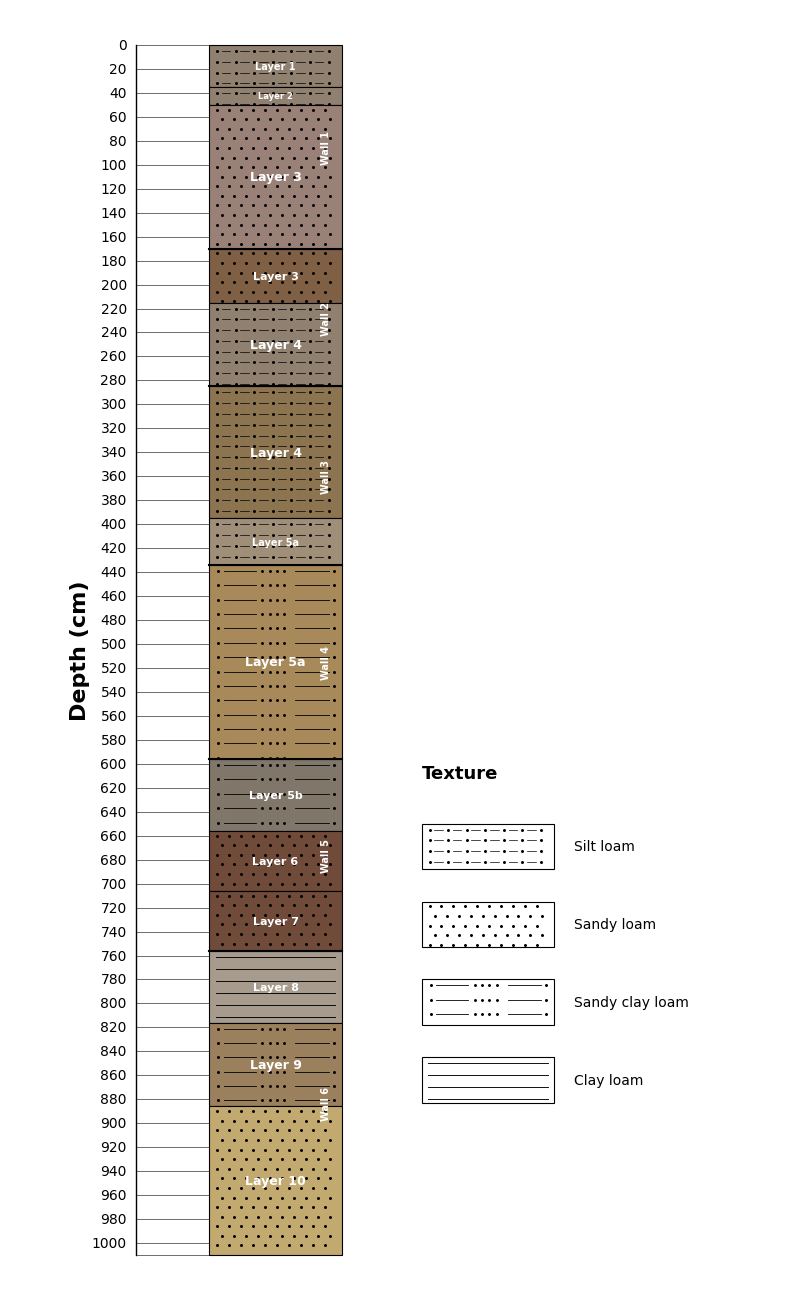

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

# ============================================================
# AZYKH CAVE — CONTINUOUS LITHOLOGICAL LOG
# Depth: 0–1010 cm
# Layer + Wall numbers shown in WHITE
# ============================================================

# ------------------------------------------------------------
# DATA
# top, bottom, colour, texture, layer
# ------------------------------------------------------------

layers = [
    (0,    35,   "#8F806F", "Silt loam",       "Layer 1"),
    (35,   50,   "#8F806F", "Silt loam",       "Layer 2"),
    (50,   170,  "#9A8178", "Sandy loam",      "Layer 3"),

    (170,  215,  "#806044", "Sandy loam",      "Layer 3"),
    (215,  285,  "#8F806F", "Silt loam",       "Layer 4"),

    (285,  395,  "#8B744F", "Silt loam",       "Layer 4"),
    (395,  434,  "#A08F78", "Silt loam",       "Layer 5a"),

    (434,  596,  "#A88A5A", "Sandy clay loam", "Layer 5a"),

    (596,  656,  "#81766A", "Sandy clay loam", "Layer 5b"),
    (656,  706,  "#704B3A", "Sandy loam",      "Layer 6"),
    (706,  756,  "#704B3A", "Sandy loam",      "Layer 7"),

    (756,  816,  "#A69B8C", "Clay loam",       "Layer 8"),
    (816,  886,  "#9B805D", "Sandy clay loam", "Layer 9"),
    (886, 1010,  "#C1A96F", "Sandy loam",      "Layer 10"),
]

# Wall intervals
walls = [
    (0,   170,  "Wall 1"),
    (170, 285,  "Wall 2"),
    (285, 434,  "Wall 3"),
    (434, 596,  "Wall 4"),
    (596, 756,  "Wall 5"),
    (756, 1010, "Wall 6"),
]


# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(8, 13))

x = 0
width = 1.0


# ============================================================
# FUNCTION FOR TEXTURE PATTERNS
# ============================================================

def draw_texture(ax, left, right, top, bottom, texture):

    # --------------------------------------------------------
    # SILT LOAM
    # . - . - . - . -
    # --------------------------------------------------------

    if texture == "Silt loam":

        for y in np.arange(top + 5, bottom, 9):

            start = left + 0.06

            while start < right - 0.05:

                # dot
                ax.plot(
                    start,
                    y,
                    marker=".",
                    markersize=2.3,
                    color="black",
                    zorder=3
                )

                # short line
                if start + 0.11 < right:

                    ax.plot(
                        [start + 0.035, start + 0.10],
                        [y, y],
                        color="black",
                        linewidth=0.5,
                        zorder=3
                    )

                start += 0.14


    # --------------------------------------------------------
    # SANDY LOAM
    # . . . . . . . . .
    # --------------------------------------------------------

    elif texture == "Sandy loam":

        row = 0

        for y in np.arange(top + 4, bottom, 8):

            offset = 0.04 if row % 2 else 0

            for xpos in np.arange(
                left + 0.06 + offset,
                right - 0.04,
                0.09
            ):

                ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.3,
                    color="black",
                    zorder=3
                )

            row += 1


    # --------------------------------------------------------
    # SANDY CLAY LOAM
    # . ----- .... ----- .
    # --------------------------------------------------------

    elif texture == "Sandy clay loam":

        for y in np.arange(top + 5, bottom, 12):

            # dot
            ax.plot(
                left + 0.07,
                y,
                marker=".",
                markersize=2.3,
                color="black",
                zorder=3
            )

            # first horizontal line
            ax.plot(
                [left + 0.11, left + 0.35],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            # middle dots
            for xpos in np.arange(
                left + 0.40,
                left + 0.61,
                0.055
            ):

                ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.2,
                    color="black",
                    zorder=3
                )

            # second line
            ax.plot(
                [left + 0.65, right - 0.10],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            # final dot
            ax.plot(
                right - 0.06,
                y,
                marker=".",
                markersize=2.3,
                color="black",
                zorder=3
            )


    # --------------------------------------------------------
    # CLAY LOAM
    # --------------------
    # --------------------------------------------------------

    elif texture == "Clay loam":

        for y in np.arange(top + 5, bottom, 10):

            ax.plot(
                [left + 0.05, right - 0.05],
                [y, y],
                color="black",
                linewidth=0.65,
                zorder=3
            )


# ============================================================
# DRAW LITHOLOGICAL COLUMN
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    # coloured rectangle
    rect = Rectangle(
        (x, top),
        width,
        bottom - top,
        facecolor=colour,
        edgecolor="black",
        linewidth=0.8,
        zorder=1
    )

    ax.add_patch(rect)

    # texture
    draw_texture(
        ax,
        x,
        x + width,
        top,
        bottom,
        texture
    )


# ============================================================
# LAYER LABELS — WHITE
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    midpoint = (top + bottom) / 2
    thickness = bottom - top

    # smaller text for thin layers
    if thickness <= 20:
        fontsize = 6
    elif thickness <= 40:
        fontsize = 7
    elif thickness <= 60:
        fontsize = 8
    else:
        fontsize = 9

    ax.text(
        x + width * 0.50,
        midpoint,
        layer_name,
        color="white",
        fontsize=fontsize,
        fontweight="bold",
        ha="center",
        va="center",
        zorder=10
    )


# ============================================================
# WALL NUMBERS — WHITE
# Placed on right side INSIDE the log
# ============================================================

for top, bottom, wall_name in walls:

    midpoint = (top + bottom) / 2

    ax.text(
        x + width * 0.88,
        midpoint,
        wall_name,
        color="white",
        fontsize=7,
        fontweight="bold",
        rotation=90,
        ha="center",
        va="center",
        zorder=11
    )


# ============================================================
# WALL BOUNDARIES
# Make wall changes slightly thicker
# ============================================================

wall_boundaries = [170, 285, 434, 596, 756]

for depth in wall_boundaries:

    ax.plot(
        [x, x + width],
        [depth, depth],
        color="black",
        linewidth=1.5,
        zorder=8
    )


# ============================================================
# DEPTH SCALE
# ============================================================

scale_x = -0.55

# vertical line
ax.plot(
    [scale_x, scale_x],
    [0, 1010],
    color="black",
    linewidth=1
)

# Depth title
ax.text(
    scale_x - 0.42,
    505,
    "Depth (cm)",
    rotation=90,
    fontsize=16,
    fontweight="bold",
    ha="center",
    va="center"
)

# ticks every 20 cm
for depth in range(0, 1001, 20):

    ax.plot(
        [scale_x, x],
        [depth, depth],
        color="black",
        linewidth=0.4
    )

    ax.text(
        scale_x - 0.07,
        depth,
        str(depth),
        fontsize=10,
        ha="right",
        va="center"
    )

# bottom boundary
ax.plot(
    [scale_x, x],
    [1010, 1010],
    color="black",
    linewidth=0.4
)


# ============================================================
# CORRECT TEXTURE LEGEND
# Same patterns used in the actual log
# ============================================================

legend_x = 1.60
legend_y = 650

legend_width = 1.0
legend_height = 38
legend_spacing = 65

ax.text(
    legend_x,
    legend_y - 35,
    "Texture",
    fontsize=13,
    fontweight="bold",
    ha="left",
    va="bottom"
)

legend_items = [
    "Silt loam",
    "Sandy loam",
    "Sandy clay loam",
    "Clay loam"
]


for i, texture in enumerate(legend_items):

    top = legend_y + i * legend_spacing
    bottom = top + legend_height

    # white legend box
    legend_box = Rectangle(
        (legend_x, top),
        legend_width,
        legend_height,
        facecolor="white",
        edgecolor="black",
        linewidth=0.8,
        zorder=1
    )

    ax.add_patch(legend_box)

    # draw EXACT SAME texture pattern
    draw_texture(
        ax,
        legend_x,
        legend_x + legend_width,
        top,
        bottom,
        texture
    )

    # Full texture name
    ax.text(
        legend_x + legend_width + 0.15,
        (top + bottom) / 2,
        texture,
        fontsize=10,
        ha="left",
        va="center"
    )


# ============================================================
# FORMATTING
# ============================================================

ax.set_xlim(-1.5, 4.3)
ax.set_ylim(1030, -30)

ax.axis("off")

plt.tight_layout()


# ============================================================
# SAVE
# ============================================================

plt.savefig(
    "Azykh_lithological_log_layers_walls.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Azykh_lithological_log_layers_walls.pdf",
    bbox_inches="tight"
)

plt.show()

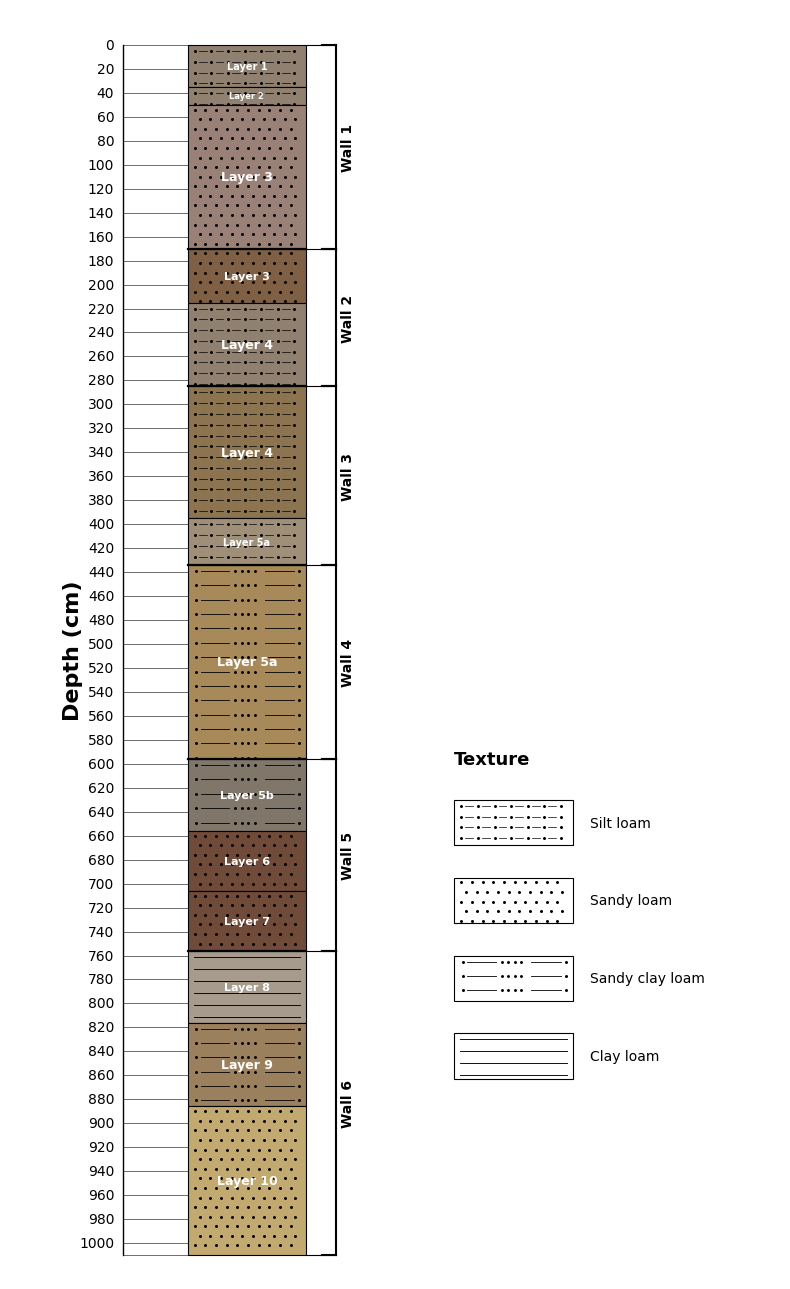

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

# ============================================================
# AZYKH CAVE — CONTINUOUS LITHOLOGICAL LOG
# Layers = white text inside log
# Walls = brackets outside log
# ============================================================

layers = [
    (0,    35,   "#8F806F", "Silt loam",       "Layer 1"),
    (35,   50,   "#8F806F", "Silt loam",       "Layer 2"),
    (50,   170,  "#9A8178", "Sandy loam",      "Layer 3"),

    (170,  215,  "#806044", "Sandy loam",      "Layer 3"),
    (215,  285,  "#8F806F", "Silt loam",       "Layer 4"),

    (285,  395,  "#8B744F", "Silt loam",       "Layer 4"),
    (395,  434,  "#A08F78", "Silt loam",       "Layer 5a"),

    (434,  596,  "#A88A5A", "Sandy clay loam", "Layer 5a"),

    (596,  656,  "#81766A", "Sandy clay loam", "Layer 5b"),
    (656,  706,  "#704B3A", "Sandy loam",      "Layer 6"),
    (706,  756,  "#704B3A", "Sandy loam",      "Layer 7"),

    (756,  816,  "#A69B8C", "Clay loam",       "Layer 8"),
    (816,  886,  "#9B805D", "Sandy clay loam", "Layer 9"),
    (886, 1010,  "#C1A96F", "Sandy loam",      "Layer 10"),
]

walls = [
    (0,    170,  "Wall 1"),
    (170,  285,  "Wall 2"),
    (285,  434,  "Wall 3"),
    (434,  596,  "Wall 4"),
    (596,  756,  "Wall 5"),
    (756, 1010,  "Wall 6"),
]


# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(8, 13))

x = 0
width = 1.0


# ============================================================
# TEXTURE FUNCTION
# ============================================================

def draw_texture(ax, left, right, top, bottom, texture):

    # --------------------------------------------------------
    # SILT LOAM
    # . - . - . - .
    # --------------------------------------------------------
    if texture == "Silt loam":

        for y in np.arange(top + 5, bottom, 9):

            start = left + 0.06

            while start < right - 0.05:

                ax.plot(
                    start, y,
                    marker=".",
                    markersize=2.3,
                    color="black",
                    zorder=3
                )

                if start + 0.10 < right:

                    ax.plot(
                        [start + 0.035, start + 0.10],
                        [y, y],
                        color="black",
                        linewidth=0.5,
                        zorder=3
                    )

                start += 0.14


    # --------------------------------------------------------
    # SANDY LOAM
    # ................
    # --------------------------------------------------------
    elif texture == "Sandy loam":

        row = 0

        for y in np.arange(top + 4, bottom, 8):

            offset = 0.04 if row % 2 else 0

            for xpos in np.arange(
                left + 0.06 + offset,
                right - 0.04,
                0.09
            ):

                ax.plot(
                    xpos, y,
                    marker=".",
                    markersize=2.3,
                    color="black",
                    zorder=3
                )

            row += 1


    # --------------------------------------------------------
    # SANDY CLAY LOAM
    # .----....----.
    # --------------------------------------------------------
    elif texture == "Sandy clay loam":

        for y in np.arange(top + 5, bottom, 12):

            ax.plot(
                left + 0.07,
                y,
                marker=".",
                markersize=2.3,
                color="black",
                zorder=3
            )

            # first clay line
            ax.plot(
                [left + 0.11, left + 0.35],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            # dots
            for xpos in np.arange(
                left + 0.40,
                left + 0.61,
                0.055
            ):

                ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.2,
                    color="black",
                    zorder=3
                )

            # second clay line
            ax.plot(
                [left + 0.65, right - 0.10],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            ax.plot(
                right - 0.06,
                y,
                marker=".",
                markersize=2.3,
                color="black",
                zorder=3
            )


    # --------------------------------------------------------
    # CLAY LOAM
    # ----------------
    # --------------------------------------------------------
    elif texture == "Clay loam":

        for y in np.arange(top + 5, bottom, 10):

            ax.plot(
                [left + 0.05, right - 0.05],
                [y, y],
                color="black",
                linewidth=0.65,
                zorder=3
            )


# ============================================================
# DRAW LITHOLOGICAL COLUMN
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    rect = Rectangle(
        (x, top),
        width,
        bottom - top,
        facecolor=colour,
        edgecolor="black",
        linewidth=0.8,
        zorder=1
    )

    ax.add_patch(rect)

    draw_texture(
        ax,
        x,
        x + width,
        top,
        bottom,
        texture
    )


# ============================================================
# LAYER LABELS
# White and centred inside the log
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    midpoint = (top + bottom) / 2
    thickness = bottom - top

    if thickness <= 20:
        fontsize = 6
    elif thickness <= 40:
        fontsize = 7
    elif thickness <= 60:
        fontsize = 8
    else:
        fontsize = 9

    ax.text(
        x + width / 2,
        midpoint,
        layer_name,
        color="white",
        fontsize=fontsize,
        fontweight="bold",
        ha="center",
        va="center",
        zorder=10
    )


# ============================================================
# WALL BRACKETS
# Clearly show which layers belong to each wall
# ============================================================

wall_x = x + width + 0.25
bracket_width = 0.12

for top, bottom, wall_name in walls:

    midpoint = (top + bottom) / 2

    # vertical bracket
    ax.plot(
        [wall_x, wall_x],
        [top, bottom],
        color="black",
        linewidth=1.5,
        zorder=10
    )

    # upper bracket arm
    ax.plot(
        [wall_x - bracket_width, wall_x],
        [top, top],
        color="black",
        linewidth=1.5,
        zorder=10
    )

    # lower bracket arm
    ax.plot(
        [wall_x - bracket_width, wall_x],
        [bottom, bottom],
        color="black",
        linewidth=1.5,
        zorder=10
    )

    # wall name
    ax.text(
        wall_x + 0.10,
        midpoint,
        wall_name,
        rotation=90,
        fontsize=10,
        fontweight="bold",
        ha="center",
        va="center"
    )


# ============================================================
# WALL BOUNDARY CONNECTORS
# Connect log directly to wall brackets
# ============================================================

wall_boundaries = [0, 170, 285, 434, 596, 756, 1010]

for depth in wall_boundaries:

    ax.plot(
        [x + width, wall_x],
        [depth, depth],
        color="black",
        linewidth=0.8,
        zorder=9
    )


# ============================================================
# MAKE WALL CHANGES CLEAR INSIDE LOG
# ============================================================

for depth in [170, 285, 434, 596, 756]:

    ax.plot(
        [x, x + width],
        [depth, depth],
        color="black",
        linewidth=1.6,
        zorder=8
    )


# ============================================================
# DEPTH SCALE
# ============================================================

scale_x = -0.55

ax.plot(
    [scale_x, scale_x],
    [0, 1010],
    color="black",
    linewidth=1
)

ax.text(
    scale_x - 0.42,
    505,
    "Depth (cm)",
    rotation=90,
    fontsize=16,
    fontweight="bold",
    ha="center",
    va="center"
)


# Depth every 20 cm
for depth in range(0, 1001, 20):

    ax.plot(
        [scale_x, x],
        [depth, depth],
        color="black",
        linewidth=0.4
    )

    ax.text(
        scale_x - 0.07,
        depth,
        str(depth),
        fontsize=10,
        ha="right",
        va="center"
    )


# 1010 boundary — no 1010 number
ax.plot(
    [scale_x, x],
    [1010, 1010],
    color="black",
    linewidth=0.4
)


# ============================================================
# TEXTURE LEGEND
# Uses EXACT SAME patterns as log
# ============================================================

legend_x = 2.25
legend_y = 630

legend_width = 1.0
legend_height = 38
legend_spacing = 65


ax.text(
    legend_x,
    legend_y - 30,
    "Texture",
    fontsize=13,
    fontweight="bold",
    ha="left"
)


legend_items = [
    "Silt loam",
    "Sandy loam",
    "Sandy clay loam",
    "Clay loam"
]


for i, texture in enumerate(legend_items):

    top = legend_y + i * legend_spacing
    bottom = top + legend_height

    box = Rectangle(
        (legend_x, top),
        legend_width,
        legend_height,
        facecolor="white",
        edgecolor="black",
        linewidth=0.8
    )

    ax.add_patch(box)

    # SAME pattern as lithological log
    draw_texture(
        ax,
        legend_x,
        legend_x + legend_width,
        top,
        bottom,
        texture
    )

    # Full texture name
    ax.text(
        legend_x + legend_width + 0.15,
        (top + bottom) / 2,
        texture,
        fontsize=10,
        ha="left",
        va="center"
    )


# ============================================================
# FORMATTING
# ============================================================

ax.set_xlim(-1.5, 5.0)
ax.set_ylim(1030, -30)

ax.axis("off")

plt.tight_layout()


# ============================================================
# SAVE
# ============================================================

plt.savefig(
    "Azykh_log_clear_wall_layer_relationship.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Azykh_log_clear_wall_layer_relationship.pdf",
    bbox_inches="tight"
)

plt.show()

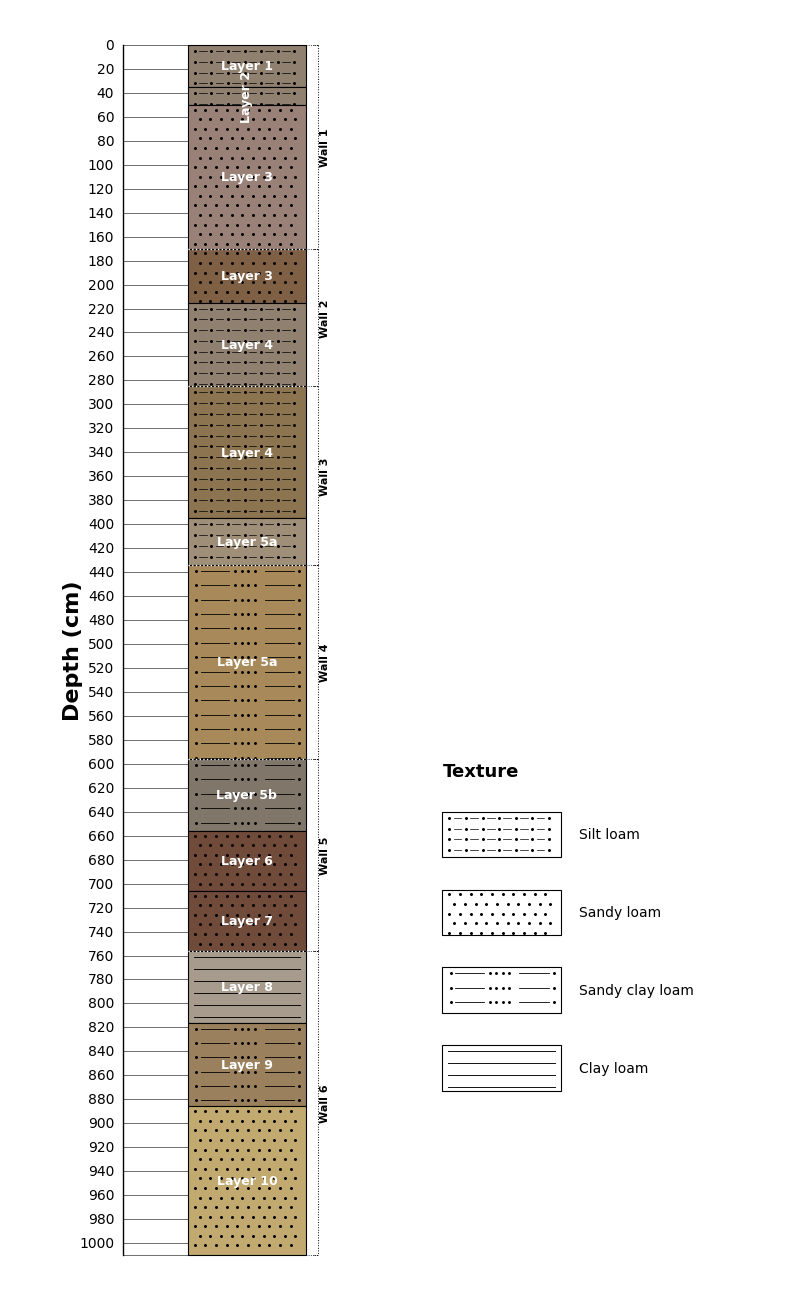

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

# ============================================================
# AZYKH CAVE — CONTINUOUS LITHOLOGICAL LOG
# Depth: 0–1010 cm
# ============================================================


# ============================================================
# DATA
# ============================================================

layers = [
    (0,    35,   "#8F806F", "Silt loam",       "Layer 1"),
    (35,   50,   "#8F806F", "Silt loam",       "Layer 2"),
    (50,   170,  "#9A8178", "Sandy loam",      "Layer 3"),

    (170,  215,  "#806044", "Sandy loam",      "Layer 3"),
    (215,  285,  "#8F806F", "Silt loam",       "Layer 4"),

    (285,  395,  "#8B744F", "Silt loam",       "Layer 4"),
    (395,  434,  "#A08F78", "Silt loam",       "Layer 5a"),

    (434,  596,  "#A88A5A", "Sandy clay loam", "Layer 5a"),

    (596,  656,  "#81766A", "Sandy clay loam", "Layer 5b"),
    (656,  706,  "#704B3A", "Sandy loam",      "Layer 6"),
    (706,  756,  "#704B3A", "Sandy loam",      "Layer 7"),

    (756,  816,  "#A69B8C", "Clay loam",       "Layer 8"),
    (816,  886,  "#9B805D", "Sandy clay loam", "Layer 9"),
    (886, 1010,  "#C1A96F", "Sandy loam",      "Layer 10"),
]


# ============================================================
# WALL INTERVALS
# ============================================================

walls = [
    (0,    170,  "Wall 1"),
    (170,  285,  "Wall 2"),
    (285,  434,  "Wall 3"),
    (434,  596,  "Wall 4"),
    (596,  756,  "Wall 5"),
    (756, 1010,  "Wall 6"),
]


# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(8, 13))

# Lithological column position
x = 0

# Lithological column width
width = 1.0


# ============================================================
# TEXTURE FUNCTION
# ============================================================

def draw_texture(ax, left, right, top, bottom, texture):

    # ========================================================
    # SILT LOAM
    # Pattern:
    # .-.-.-.-.-.-.-.
    # ========================================================

    if texture == "Silt loam":

        for y in np.arange(top + 5, bottom, 9):

            start = left + 0.06

            while start < right - 0.05:

                # Dot
                ax.plot(
                    start,
                    y,
                    marker=".",
                    markersize=2.3,
                    color="black",
                    zorder=3
                )

                # Small horizontal dash
                if start + 0.10 < right:

                    ax.plot(
                        [start + 0.035, start + 0.10],
                        [y, y],
                        color="black",
                        linewidth=0.5,
                        zorder=3
                    )

                start += 0.14


    # ========================================================
    # SANDY LOAM
    # Pattern:
    # ................
    # ========================================================

    elif texture == "Sandy loam":

        row = 0

        for y in np.arange(top + 4, bottom, 8):

            offset = 0.04 if row % 2 else 0

            for xpos in np.arange(
                left + 0.06 + offset,
                right - 0.04,
                0.09
            ):

                ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.3,
                    color="black",
                    zorder=3
                )

            row += 1


    # ========================================================
    # SANDY CLAY LOAM
    # Pattern:
    # .-----....-----.
    # ========================================================

    elif texture == "Sandy clay loam":

        for y in np.arange(top + 5, bottom, 12):

            # First dot
            ax.plot(
                left + 0.07,
                y,
                marker=".",
                markersize=2.3,
                color="black",
                zorder=3
            )

            # First horizontal clay line
            ax.plot(
                [left + 0.11, left + 0.35],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            # Middle sand dots
            for xpos in np.arange(
                left + 0.40,
                left + 0.61,
                0.055
            ):

                ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.2,
                    color="black",
                    zorder=3
                )

            # Second horizontal clay line
            ax.plot(
                [left + 0.65, right - 0.10],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            # Final dot
            ax.plot(
                right - 0.06,
                y,
                marker=".",
                markersize=2.3,
                color="black",
                zorder=3
            )


    # ========================================================
    # CLAY LOAM
    # Pattern:
    # ----------------
    # ========================================================

    elif texture == "Clay loam":

        for y in np.arange(top + 5, bottom, 10):

            ax.plot(
                [left + 0.05, right - 0.05],
                [y, y],
                color="black",
                linewidth=0.65,
                zorder=3
            )


# ============================================================
# DRAW LITHOLOGICAL COLUMN
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    # Main coloured unit
    rectangle = Rectangle(
        (x, top),
        width,
        bottom - top,
        facecolor=colour,
        edgecolor="black",
        linewidth=0.8,
        zorder=1
    )

    ax.add_patch(rectangle)

    # Add texture
    draw_texture(
        ax,
        x,
        x + width,
        top,
        bottom,
        texture
    )


# ============================================================
# LAYER LABELS
# Same font size for ALL layers
# White text
# ============================================================

layer_fontsize = 9


for top, bottom, colour, texture, layer_name in layers:

    midpoint = (top + bottom) / 2
    thickness = bottom - top

    # --------------------------------------------------------
    # Layer 2 is very thin.
    # Keep same font size but rotate it.
    # --------------------------------------------------------

    if thickness < 25:

        ax.text(
            x + width / 2,
            midpoint,
            layer_name,
            color="white",
            fontsize=layer_fontsize,
            fontweight="bold",
            rotation=90,
            ha="center",
            va="center",
            zorder=15
        )

    else:

        ax.text(
            x + width / 2,
            midpoint,
            layer_name,
            color="white",
            fontsize=layer_fontsize,
            fontweight="bold",
            ha="center",
            va="center",
            zorder=15
        )


# ============================================================
# SMALL DOTTED WALL BRACKETS
# OUTSIDE THE LOG
# ============================================================

# Very close to the log
wall_x = x + width + 0.10

# Very short bracket arms
bracket_width = 0.035


for top, bottom, wall_name in walls:

    midpoint = (top + bottom) / 2

    # --------------------------------------------------------
    # Vertical dotted bracket
    # --------------------------------------------------------

    ax.plot(
        [wall_x, wall_x],
        [top, bottom],
        color="black",
        linewidth=0.7,
        linestyle=":",
        zorder=10
    )


    # --------------------------------------------------------
    # Small top arm
    # --------------------------------------------------------

    ax.plot(
        [wall_x - bracket_width, wall_x],
        [top, top],
        color="black",
        linewidth=0.7,
        linestyle=":",
        zorder=10
    )


    # --------------------------------------------------------
    # Small bottom arm
    # --------------------------------------------------------

    ax.plot(
        [wall_x - bracket_width, wall_x],
        [bottom, bottom],
        color="black",
        linewidth=0.7,
        linestyle=":",
        zorder=10
    )


    # --------------------------------------------------------
    # Wall name
    # --------------------------------------------------------

    ax.text(
        wall_x + 0.055,
        midpoint,
        wall_name,
        rotation=90,
        fontsize=8,
        fontweight="bold",
        ha="center",
        va="center"
    )


# ============================================================
# VERY SHORT DOTTED CONNECTORS
# Log → wall bracket
# ============================================================

wall_boundaries = [
    0,
    170,
    285,
    434,
    596,
    756,
    1010
]


for depth in wall_boundaries:

    ax.plot(
        [x + width, wall_x],
        [depth, depth],
        color="black",
        linewidth=0.6,
        linestyle=":",
        zorder=9
    )


# ============================================================
# DOTTED WALL BOUNDARIES INSIDE LOG
# ============================================================

for depth in [
    170,
    285,
    434,
    596,
    756
]:

    ax.plot(
        [x, x + width],
        [depth, depth],
        color="white",
        linewidth=1.0,
        linestyle=":",
        zorder=12
    )


# ============================================================
# DEPTH SCALE
# ============================================================

scale_x = -0.55


# Vertical depth line
ax.plot(
    [scale_x, scale_x],
    [0, 1010],
    color="black",
    linewidth=1.0
)


# ============================================================
# DEPTH TITLE
# ============================================================

ax.text(
    scale_x - 0.42,
    505,
    "Depth (cm)",
    rotation=90,
    fontsize=16,
    fontweight="bold",
    ha="center",
    va="center"
)


# ============================================================
# DEPTH TICKS
# Every 20 cm
# ============================================================

for depth in range(0, 1001, 20):

    # Tick line
    ax.plot(
        [scale_x, x],
        [depth, depth],
        color="black",
        linewidth=0.4
    )

    # Depth number
    ax.text(
        scale_x - 0.07,
        depth,
        str(depth),
        fontsize=10,
        ha="right",
        va="center"
    )


# ============================================================
# 1010 cm BOTTOM BOUNDARY
# No 1010 text
# ============================================================

ax.plot(
    [scale_x, x],
    [1010, 1010],
    color="black",
    linewidth=0.4
)


# ============================================================
# TEXTURE LEGEND
# Uses EXACTLY SAME PATTERNS as the log
# ============================================================

legend_x = 2.15
legend_y = 640

legend_width = 1.0
legend_height = 38
legend_spacing = 65


# Legend title
ax.text(
    legend_x,
    legend_y - 30,
    "Texture",
    fontsize=13,
    fontweight="bold",
    ha="left"
)


# Full texture names
legend_items = [
    "Silt loam",
    "Sandy loam",
    "Sandy clay loam",
    "Clay loam"
]


for i, texture in enumerate(legend_items):

    top = legend_y + i * legend_spacing
    bottom = top + legend_height


    # --------------------------------------------------------
    # Legend box
    # --------------------------------------------------------

    box = Rectangle(
        (legend_x, top),
        legend_width,
        legend_height,
        facecolor="white",
        edgecolor="black",
        linewidth=0.8,
        zorder=1
    )

    ax.add_patch(box)


    # --------------------------------------------------------
    # Same texture used in actual log
    # --------------------------------------------------------

    draw_texture(
        ax,
        legend_x,
        legend_x + legend_width,
        top,
        bottom,
        texture
    )


    # --------------------------------------------------------
    # Full texture name
    # --------------------------------------------------------

    ax.text(
        legend_x + legend_width + 0.15,
        (top + bottom) / 2,
        texture,
        fontsize=10,
        ha="left",
        va="center"
    )


# ============================================================
# FINAL FORMATTING
# ============================================================

ax.set_xlim(-1.5, 5.0)

ax.set_ylim(
    1030,
    -30
)

ax.axis("off")

plt.tight_layout()


# ============================================================
# SAVE HIGH-RESOLUTION PNG
# ============================================================

plt.savefig(
    "Azykh_final_lithological_log.png",
    dpi=600,
    bbox_inches="tight"
)


# ============================================================
# SAVE PDF
# ============================================================

plt.savefig(
    "Azykh_final_lithological_log.pdf",
    bbox_inches="tight"
)


# ============================================================
# SHOW FIGURE
# ============================================================

plt.show()

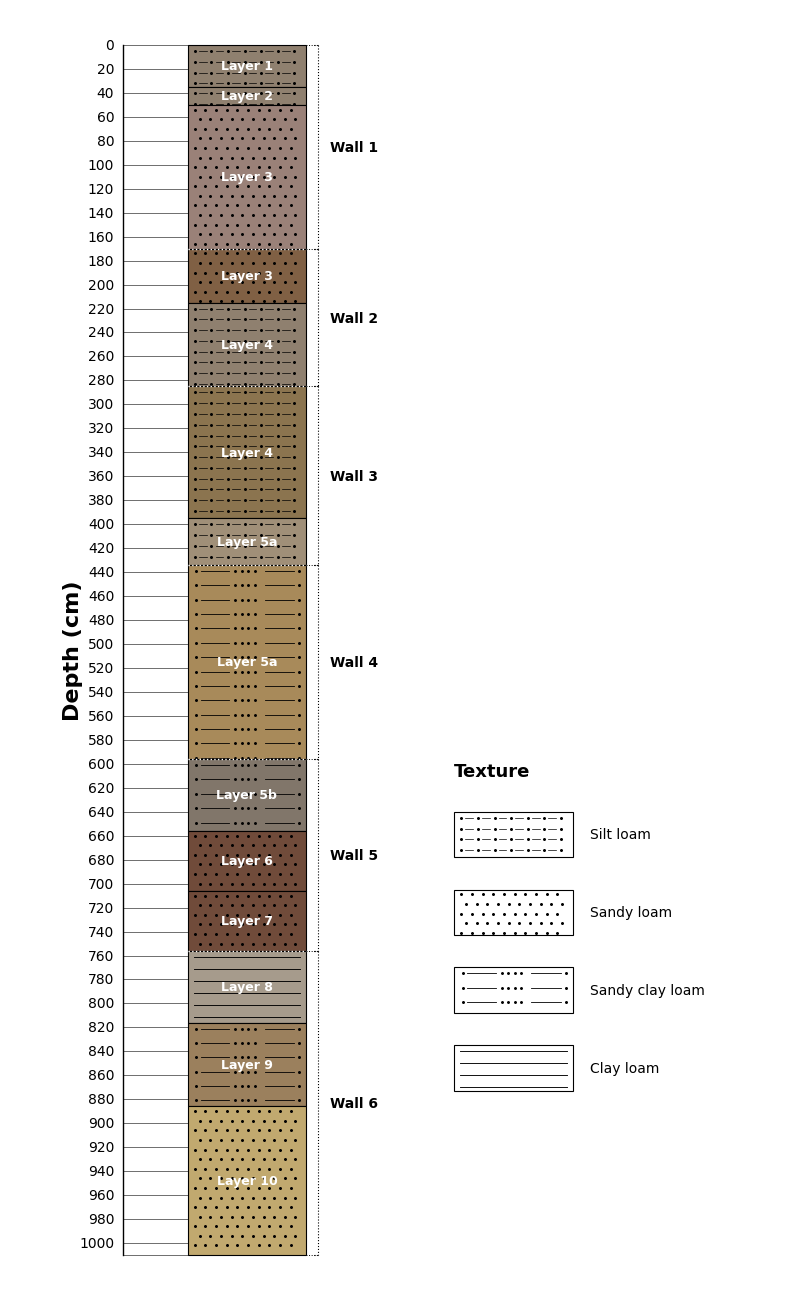

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

# ============================================================
# AZYKH CAVE — CONTINUOUS LITHOLOGICAL LOG
# Depth: 0–1010 cm
# ============================================================


# ============================================================
# DATA
# ============================================================

layers = [
    (0,    35,   "#8F806F", "Silt loam",       "Layer 1"),
    (35,   50,   "#8F806F", "Silt loam",       "Layer 2"),
    (50,   170,  "#9A8178", "Sandy loam",      "Layer 3"),

    (170,  215,  "#806044", "Sandy loam",      "Layer 3"),
    (215,  285,  "#8F806F", "Silt loam",       "Layer 4"),

    (285,  395,  "#8B744F", "Silt loam",       "Layer 4"),
    (395,  434,  "#A08F78", "Silt loam",       "Layer 5a"),

    (434,  596,  "#A88A5A", "Sandy clay loam", "Layer 5a"),

    (596,  656,  "#81766A", "Sandy clay loam", "Layer 5b"),
    (656,  706,  "#704B3A", "Sandy loam",      "Layer 6"),
    (706,  756,  "#704B3A", "Sandy loam",      "Layer 7"),

    (756,  816,  "#A69B8C", "Clay loam",       "Layer 8"),
    (816,  886,  "#9B805D", "Sandy clay loam", "Layer 9"),
    (886, 1010,  "#C1A96F", "Sandy loam",      "Layer 10"),
]


# ============================================================
# WALL INTERVALS
# ============================================================

walls = [
    (0,    170,  "Wall 1"),
    (170,  285,  "Wall 2"),
    (285,  434,  "Wall 3"),
    (434,  596,  "Wall 4"),
    (596,  756,  "Wall 5"),
    (756, 1010,  "Wall 6"),
]


# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(8, 13))

x = 0
width = 1.0


# ============================================================
# TEXTURE FUNCTION
# ============================================================

def draw_texture(ax, left, right, top, bottom, texture):

    # --------------------------------------------------------
    # SILT LOAM
    # .-.-.-.-.-.-.-.
    # --------------------------------------------------------

    if texture == "Silt loam":

        for y in np.arange(top + 5, bottom, 9):

            start = left + 0.06

            while start < right - 0.05:

                # dot
                ax.plot(
                    start,
                    y,
                    marker=".",
                    markersize=2.3,
                    color="black",
                    zorder=3
                )

                # small dash
                if start + 0.10 < right:

                    ax.plot(
                        [start + 0.035, start + 0.10],
                        [y, y],
                        color="black",
                        linewidth=0.5,
                        zorder=3
                    )

                start += 0.14


    # --------------------------------------------------------
    # SANDY LOAM
    # ................
    # --------------------------------------------------------

    elif texture == "Sandy loam":

        row = 0

        for y in np.arange(top + 4, bottom, 8):

            offset = 0.04 if row % 2 else 0

            for xpos in np.arange(
                left + 0.06 + offset,
                right - 0.04,
                0.09
            ):

                ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.3,
                    color="black",
                    zorder=3
                )

            row += 1


    # --------------------------------------------------------
    # SANDY CLAY LOAM
    # .-----....-----.
    # --------------------------------------------------------

    elif texture == "Sandy clay loam":

        for y in np.arange(top + 5, bottom, 12):

            # first dot
            ax.plot(
                left + 0.07,
                y,
                marker=".",
                markersize=2.3,
                color="black",
                zorder=3
            )

            # first horizontal line
            ax.plot(
                [left + 0.11, left + 0.35],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            # middle dots
            for xpos in np.arange(
                left + 0.40,
                left + 0.61,
                0.055
            ):

                ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.2,
                    color="black",
                    zorder=3
                )

            # second horizontal line
            ax.plot(
                [left + 0.65, right - 0.10],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            # final dot
            ax.plot(
                right - 0.06,
                y,
                marker=".",
                markersize=2.3,
                color="black",
                zorder=3
            )


    # --------------------------------------------------------
    # CLAY LOAM
    # ----------------
    # --------------------------------------------------------

    elif texture == "Clay loam":

        for y in np.arange(top + 5, bottom, 10):

            ax.plot(
                [left + 0.05, right - 0.05],
                [y, y],
                color="black",
                linewidth=0.65,
                zorder=3
            )


# ============================================================
# DRAW LITHOLOGICAL COLUMN
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    rectangle = Rectangle(
        (x, top),
        width,
        bottom - top,
        facecolor=colour,
        edgecolor="black",
        linewidth=0.8,
        zorder=1
    )

    ax.add_patch(rectangle)

    draw_texture(
        ax,
        x,
        x + width,
        top,
        bottom,
        texture
    )


# ============================================================
# LAYER LABELS
# ALL HORIZONTAL
# ALL SAME FONT SIZE
# ============================================================

layer_fontsize = 9

for top, bottom, colour, texture, layer_name in layers:

    midpoint = (top + bottom) / 2

    ax.text(
        x + width / 2,
        midpoint,
        layer_name,
        color="white",
        fontsize=layer_fontsize,
        fontweight="bold",
        ha="center",
        va="center",
        rotation=0,
        zorder=15
    )


# ============================================================
# SMALL DOTTED WALL BRACKETS
# OUTSIDE LOG
# ============================================================

# Close to lithological column
wall_x = x + width + 0.10

# Very short bracket arms
bracket_width = 0.035


for top, bottom, wall_name in walls:

    midpoint = (top + bottom) / 2

    # Vertical dotted bracket
    ax.plot(
        [wall_x, wall_x],
        [top, bottom],
        color="black",
        linewidth=0.8,
        linestyle=":",
        zorder=10
    )

    # Small top arm
    ax.plot(
        [wall_x - bracket_width, wall_x],
        [top, top],
        color="black",
        linewidth=0.8,
        linestyle=":",
        zorder=10
    )

    # Small bottom arm
    ax.plot(
        [wall_x - bracket_width, wall_x],
        [bottom, bottom],
        color="black",
        linewidth=0.8,
        linestyle=":",
        zorder=10
    )


# ============================================================
# WALL LABELS
# Larger, horizontal and professional
# ============================================================

wall_text_x = wall_x + 0.10

for top, bottom, wall_name in walls:

    midpoint = (top + bottom) / 2

    ax.text(
        wall_text_x,
        midpoint,
        wall_name,
        fontsize=10,
        fontweight="bold",
        rotation=0,
        ha="left",
        va="center",
        color="black",
        zorder=15
    )


# ============================================================
# SHORT DOTTED CONNECTORS
# Log → wall bracket
# ============================================================

wall_boundaries = [
    0,
    170,
    285,
    434,
    596,
    756,
    1010
]

for depth in wall_boundaries:

    ax.plot(
        [x + width, wall_x],
        [depth, depth],
        color="black",
        linewidth=0.7,
        linestyle=":",
        zorder=9
    )


# ============================================================
# DOTTED WALL BOUNDARIES THROUGH LOG
# ============================================================

for depth in [
    170,
    285,
    434,
    596,
    756
]:

    ax.plot(
        [x, x + width],
        [depth, depth],
        color="white",
        linewidth=1.0,
        linestyle=":",
        zorder=12
    )


# ============================================================
# DEPTH SCALE
# ============================================================

scale_x = -0.55

ax.plot(
    [scale_x, scale_x],
    [0, 1010],
    color="black",
    linewidth=1.0
)


# Depth title
ax.text(
    scale_x - 0.42,
    505,
    "Depth (cm)",
    rotation=90,
    fontsize=16,
    fontweight="bold",
    ha="center",
    va="center"
)


# ============================================================
# DEPTH TICKS — EVERY 20 CM
# ============================================================

for depth in range(0, 1001, 20):

    ax.plot(
        [scale_x, x],
        [depth, depth],
        color="black",
        linewidth=0.4
    )

    ax.text(
        scale_x - 0.07,
        depth,
        str(depth),
        fontsize=10,
        ha="right",
        va="center"
    )


# Bottom boundary 1010 cm
# No 1010 label
ax.plot(
    [scale_x, x],
    [1010, 1010],
    color="black",
    linewidth=0.4
)


# ============================================================
# TEXTURE LEGEND
# Same patterns as actual log
# ============================================================

legend_x = 2.25
legend_y = 640

legend_width = 1.0
legend_height = 38
legend_spacing = 65


# Legend title
ax.text(
    legend_x,
    legend_y - 30,
    "Texture",
    fontsize=13,
    fontweight="bold",
    ha="left"
)


legend_items = [
    "Silt loam",
    "Sandy loam",
    "Sandy clay loam",
    "Clay loam"
]


for i, texture in enumerate(legend_items):

    top = legend_y + i * legend_spacing
    bottom = top + legend_height

    # Legend box
    box = Rectangle(
        (legend_x, top),
        legend_width,
        legend_height,
        facecolor="white",
        edgecolor="black",
        linewidth=0.8,
        zorder=1
    )

    ax.add_patch(box)

    # Same pattern as lithological column
    draw_texture(
        ax,
        legend_x,
        legend_x + legend_width,
        top,
        bottom,
        texture
    )

    # Full texture name
    ax.text(
        legend_x + legend_width + 0.15,
        (top + bottom) / 2,
        texture,
        fontsize=10,
        ha="left",
        va="center"
    )


# ============================================================
# FINAL FORMATTING
# ============================================================

ax.set_xlim(-1.5, 5.0)
ax.set_ylim(1030, -30)

ax.axis("off")

plt.tight_layout()


# ============================================================
# SAVE
# ============================================================

plt.savefig(
    "Azykh_professional_lithological_log.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Azykh_professional_lithological_log.pdf",
    bbox_inches="tight"
)

plt.show()

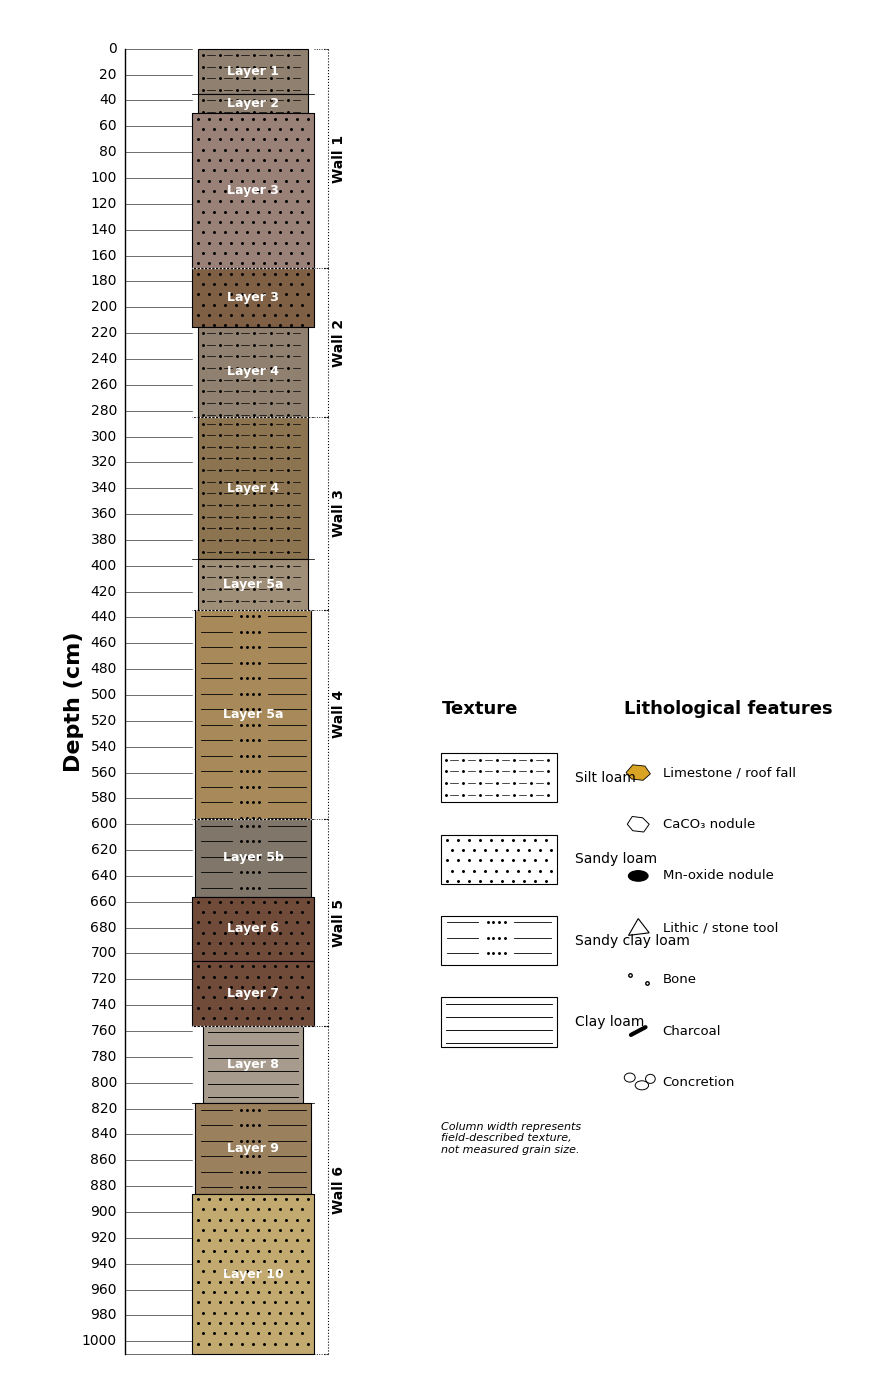

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle, Polygon, Ellipse

# ============================================================
# AZYKH CAVE — COMPOSITE LITHOLOGICAL LOG
# Depth: 0–1010 cm
# ============================================================


# ============================================================
# 1. STRATIGRAPHIC DATA
# ============================================================

layers = [
    (0,    35,   "#8F806F", "Silt loam",       "Layer 1"),
    (35,   50,   "#8F806F", "Silt loam",       "Layer 2"),
    (50,   170,  "#9A8178", "Sandy loam",      "Layer 3"),

    (170,  215,  "#806044", "Sandy loam",      "Layer 3"),
    (215,  285,  "#8F806F", "Silt loam",       "Layer 4"),

    (285,  395,  "#8B744F", "Silt loam",       "Layer 4"),
    (395,  434,  "#A08F78", "Silt loam",       "Layer 5a"),

    (434,  596,  "#A88A5A", "Sandy clay loam", "Layer 5a"),

    (596,  656,  "#81766A", "Sandy clay loam", "Layer 5b"),
    (656,  706,  "#704B3A", "Sandy loam",      "Layer 6"),
    (706,  756,  "#704B3A", "Sandy loam",      "Layer 7"),

    (756,  816,  "#A69B8C", "Clay loam",       "Layer 8"),
    (816,  886,  "#9B805D", "Sandy clay loam", "Layer 9"),
    (886, 1010,  "#C1A96F", "Sandy loam",      "Layer 10"),
]


# ============================================================
# 2. WALL INTERVALS
# ============================================================

walls = [
    (0,    170,  "Wall 1"),
    (170,  285,  "Wall 2"),
    (285,  434,  "Wall 3"),
    (434,  596,  "Wall 4"),
    (596,  756,  "Wall 5"),
    (756, 1010,  "Wall 6"),
]


# ============================================================
# 3. COLUMN WIDTH ACCORDING TO FIELD TEXTURE
#
# Only a subtle visual variation.
# This is NOT a measured grain-size scale.
# ============================================================

texture_width = {
    "Clay loam":       0.82,
    "Silt loam":       0.90,
    "Sandy clay loam": 0.96,
    "Sandy loam":      1.00,
}


# ============================================================
# 4. FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(9, 14))

x = 0

# Centre of the lithological column
column_centre = 0.50


# ============================================================
# 5. TEXTURE FUNCTION
# ============================================================

def draw_texture(ax, left, right, top, bottom, texture):

    # --------------------------------------------------------
    # SILT LOAM
    # . - . - . - . -
    # --------------------------------------------------------

    if texture == "Silt loam":

        for y in np.arange(top + 5, bottom, 9):

            xpos = left + 0.04

            while xpos < right - 0.04:

                ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.2,
                    color="black",
                    zorder=4
                )

                if xpos + 0.10 < right:

                    ax.plot(
                        [xpos + 0.035, xpos + 0.095],
                        [y, y],
                        color="black",
                        linewidth=0.5,
                        zorder=4
                    )

                xpos += 0.14


    # --------------------------------------------------------
    # SANDY LOAM
    # Dense dots
    # --------------------------------------------------------

    elif texture == "Sandy loam":

        row = 0

        for y in np.arange(top + 4, bottom, 8):

            offset = 0.04 if row % 2 else 0

            for xpos in np.arange(
                left + 0.05 + offset,
                right - 0.03,
                0.09
            ):

                ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.3,
                    color="black",
                    zorder=4
                )

            row += 1


    # --------------------------------------------------------
    # SANDY CLAY LOAM
    # Lines + groups of dots
    # --------------------------------------------------------

    elif texture == "Sandy clay loam":

        for y in np.arange(top + 5, bottom, 12):

            total_width = right - left

            ax.plot(
                [left + total_width * 0.05,
                 left + total_width * 0.32],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=4
            )

            for frac in [0.40, 0.45, 0.50, 0.55]:

                ax.plot(
                    left + total_width * frac,
                    y,
                    marker=".",
                    markersize=2.2,
                    color="black",
                    zorder=4
                )

            ax.plot(
                [left + total_width * 0.63,
                 right - total_width * 0.05],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=4
            )


    # --------------------------------------------------------
    # CLAY LOAM
    # Horizontal lines
    # --------------------------------------------------------

    elif texture == "Clay loam":

        for y in np.arange(top + 5, bottom, 10):

            ax.plot(
                [left + 0.04, right - 0.04],
                [y, y],
                color="black",
                linewidth=0.65,
                zorder=4
            )


# ============================================================
# 6. DRAW LITHOLOGICAL UNITS
# ============================================================

unit_positions = []

for top, bottom, colour, texture, layer_name in layers:

    unit_width = texture_width[texture]

    left = column_centre - unit_width / 2
    right = column_centre + unit_width / 2

    unit_positions.append(
        (top, bottom, left, right, layer_name)
    )

    rect = Rectangle(
        (left, top),
        unit_width,
        bottom - top,
        facecolor=colour,
        edgecolor="black",
        linewidth=0.8,
        zorder=2
    )

    ax.add_patch(rect)

    draw_texture(
        ax,
        left,
        right,
        top,
        bottom,
        texture
    )


# ============================================================
# 7. LAYER LABELS
# ALL HORIZONTAL
# ============================================================

for top, bottom, left, right, layer_name in unit_positions:

    midpoint = (top + bottom) / 2

    ax.text(
        column_centre,
        midpoint,
        layer_name,
        fontsize=9,
        fontweight="bold",
        color="white",
        ha="center",
        va="center",
        rotation=0,
        zorder=20
    )


# ============================================================
# 8. CONTACT LINES
# Slightly emphasised
# ============================================================

contacts = [
    35, 50, 170, 215, 285, 395,
    434, 596, 656, 706, 756, 816, 886
]

for depth in contacts:

    ax.plot(
        [0.0, 1.0],
        [depth, depth],
        color="black",
        linewidth=0.55,
        zorder=8
    )


# ============================================================
# 9. WALL BRACKETS
# SMALL + DOTTED + OUTSIDE LOG
# ============================================================

wall_x = 1.12

bracket_arm = 0.035


for top, bottom, wall_name in walls:

    midpoint = (top + bottom) / 2

    # Vertical dotted bracket
    ax.plot(
        [wall_x, wall_x],
        [top, bottom],
        color="black",
        linewidth=0.8,
        linestyle=":",
        zorder=10
    )

    # Top arm
    ax.plot(
        [wall_x - bracket_arm, wall_x],
        [top, top],
        color="black",
        linewidth=0.8,
        linestyle=":",
        zorder=10
    )

    # Bottom arm
    ax.plot(
        [wall_x - bracket_arm, wall_x],
        [bottom, bottom],
        color="black",
        linewidth=0.8,
        linestyle=":",
        zorder=10
    )

    # Vertical wall name
    ax.text(
        wall_x + 0.09,
        midpoint,
        wall_name,
        fontsize=10,
        fontweight="bold",
        rotation=90,
        ha="center",
        va="center",
        color="black",
        zorder=15
    )


# ============================================================
# 10. SHORT WALL CONNECTORS
# ============================================================

wall_boundaries = [
    0,
    170,
    285,
    434,
    596,
    756,
    1010
]

for depth in wall_boundaries:

    ax.plot(
        [1.0, wall_x],
        [depth, depth],
        color="black",
        linewidth=0.65,
        linestyle=":",
        zorder=9
    )


# ============================================================
# 11. WALL BOUNDARIES THROUGH COLUMN
# ============================================================

for depth in [
    170,
    285,
    434,
    596,
    756
]:

    ax.plot(
        [0.0, 1.0],
        [depth, depth],
        color="white",
        linewidth=1.0,
        linestyle=":",
        zorder=12
    )


# ============================================================
# 12. DEPTH SCALE
# ============================================================

scale_x = -0.55

ax.plot(
    [scale_x, scale_x],
    [0, 1010],
    color="black",
    linewidth=1
)


# ============================================================
# 13. DEPTH TITLE
# ============================================================

ax.text(
    scale_x - 0.42,
    505,
    "Depth (cm)",
    rotation=90,
    fontsize=16,
    fontweight="bold",
    ha="center",
    va="center"
)


# ============================================================
# 14. DEPTH TICKS
# ============================================================

for depth in range(0, 1001, 20):

    ax.plot(
        [scale_x, 0],
        [depth, depth],
        color="black",
        linewidth=0.4
    )

    ax.text(
        scale_x - 0.07,
        depth,
        str(depth),
        fontsize=10,
        ha="right",
        va="center"
    )


# Bottom boundary
ax.plot(
    [scale_x, 0],
    [1010, 1010],
    color="black",
    linewidth=0.4
)


# ============================================================
# 15. TEXTURE LEGEND
# ============================================================

legend_x = 2.05
legend_y = 545

legend_width = 0.95
legend_height = 38
legend_spacing = 63


ax.text(
    legend_x,
    legend_y - 30,
    "Texture",
    fontsize=13,
    fontweight="bold",
    ha="left"
)


legend_items = [
    "Silt loam",
    "Sandy loam",
    "Sandy clay loam",
    "Clay loam"
]


for i, texture in enumerate(legend_items):

    top = legend_y + i * legend_spacing
    bottom = top + legend_height

    box = Rectangle(
        (legend_x, top),
        legend_width,
        legend_height,
        facecolor="white",
        edgecolor="black",
        linewidth=0.8,
        zorder=2
    )

    ax.add_patch(box)

    draw_texture(
        ax,
        legend_x,
        legend_x + legend_width,
        top,
        bottom,
        texture
    )

    ax.text(
        legend_x + legend_width + 0.15,
        (top + bottom) / 2,
        texture,
        fontsize=10,
        ha="left",
        va="center"
    )


# ============================================================
# 16. LITHOLOGICAL FEATURE SYMBOL FUNCTIONS
#
# These reproduce the TYPE of visual information shown
# in your example logs.
# ============================================================


# ------------------------------------------------------------
# LIMESTONE / ROOF-FALL CLAST
# ------------------------------------------------------------

def limestone_symbol(ax, x, y, size=0.10):

    points = [
        [x - size,       y],
        [x - size*0.45,  y - 6],
        [x + size*0.55,  y - 5],
        [x + size,       y + 1],
        [x + size*0.40,  y + 6],
        [x - size*0.55,  y + 5]
    ]

    polygon = Polygon(
        points,
        closed=True,
        facecolor="#D9A323",
        edgecolor="black",
        linewidth=0.6
    )

    ax.add_patch(polygon)


# ------------------------------------------------------------
# CaCO3 NODULE
# ------------------------------------------------------------

def carbonate_nodule(ax, x, y, size=0.09):

    points = [
        [x - size,       y],
        [x - size*0.55,  y - 6],
        [x + size*0.40,  y - 5],
        [x + size,       y],
        [x + size*0.50,  y + 6],
        [x - size*0.50,  y + 5]
    ]

    polygon = Polygon(
        points,
        closed=True,
        facecolor="white",
        edgecolor="black",
        linewidth=0.7
    )

    ax.add_patch(polygon)


# ------------------------------------------------------------
# MANGANESE NODULE
# ------------------------------------------------------------

def manganese_symbol(ax, x, y):

    ellipse = Ellipse(
        (x, y),
        width=0.16,
        height=8,
        facecolor="black",
        edgecolor="black"
    )

    ax.add_patch(ellipse)


# ------------------------------------------------------------
# LITHIC / STONE TOOL
# ------------------------------------------------------------

def lithic_symbol(ax, x, y):

    triangle = Polygon(
        [
            [x, y - 7],
            [x - 0.08, y + 6],
            [x + 0.09, y + 4]
        ],
        closed=True,
        facecolor="white",
        edgecolor="black",
        linewidth=0.8
    )

    ax.add_patch(triangle)


# ------------------------------------------------------------
# BONE
# ------------------------------------------------------------

def bone_symbol(ax, x, y):

    ax.plot(
        [x - 0.07, x + 0.07],
        [y - 3, y + 3],
        color="white",
        linewidth=2.0,
        zorder=16
    )

    ax.plot(
        x - 0.07,
        y - 3,
        marker="o",
        markersize=2.5,
        markerfacecolor="white",
        markeredgecolor="black",
        zorder=17
    )

    ax.plot(
        x + 0.07,
        y + 3,
        marker="o",
        markersize=2.5,
        markerfacecolor="white",
        markeredgecolor="black",
        zorder=17
    )


# ------------------------------------------------------------
# CHARCOAL
# ------------------------------------------------------------

def charcoal_symbol(ax, x, y):

    ax.plot(
        [x - 0.06, x + 0.06],
        [y + 3, y - 3],
        color="black",
        linewidth=3,
        solid_capstyle="round",
        zorder=16
    )


# ------------------------------------------------------------
# CONCRETION
# ------------------------------------------------------------

def concretion_symbol(ax, x, y):

    for dx, dy, s in [
        (-0.07, -4, 0.045),
        (0.03,  2, 0.055),
        (0.10, -3, 0.040)
    ]:

        circle = Ellipse(
            (x + dx, y + dy),
            width=s * 2,
            height=7,
            facecolor="none",
            edgecolor="black",
            linewidth=0.7
        )

        ax.add_patch(circle)


# ============================================================
# 17. OPTIONAL FEATURE PLACEMENT
# ============================================================
#
# IMPORTANT:
# Keep this section empty until the occurrence of each feature
# is confirmed from the Azykh field observations.
#
# Examples of how to add confirmed features:
#
# limestone_symbol(ax, 0.30, 300)
# carbonate_nodule(ax, 0.70, 350)
# lithic_symbol(ax, 0.30, 120)
# bone_symbol(ax, 0.70, 140)
# charcoal_symbol(ax, 0.30, 160)
# concretion_symbol(ax, 0.70, 200)
#
# ============================================================


# ============================================================
# 18. LITHOLOGICAL / ARCHAEOLOGICAL FEATURE LEGEND
# ============================================================

feature_x = 3.55
feature_y = 545

ax.text(
    feature_x,
    feature_y - 30,
    "Lithological features",
    fontsize=13,
    fontweight="bold",
    ha="left"
)


# Limestone
limestone_symbol(
    ax,
    feature_x + 0.12,
    feature_y + 15
)

ax.text(
    feature_x + 0.32,
    feature_y + 15,
    "Limestone / roof fall",
    fontsize=9.5,
    va="center"
)


# Carbonate nodule
carbonate_nodule(
    ax,
    feature_x + 0.12,
    feature_y + 55
)

ax.text(
    feature_x + 0.32,
    feature_y + 55,
    "CaCO₃ nodule",
    fontsize=9.5,
    va="center"
)


# Mn nodule
manganese_symbol(
    ax,
    feature_x + 0.12,
    feature_y + 95
)

ax.text(
    feature_x + 0.32,
    feature_y + 95,
    "Mn-oxide nodule",
    fontsize=9.5,
    va="center"
)


# Lithic
lithic_symbol(
    ax,
    feature_x + 0.12,
    feature_y + 135
)

ax.text(
    feature_x + 0.32,
    feature_y + 135,
    "Lithic / stone tool",
    fontsize=9.5,
    va="center"
)


# Bone
bone_symbol(
    ax,
    feature_x + 0.12,
    feature_y + 175
)

ax.text(
    feature_x + 0.32,
    feature_y + 175,
    "Bone",
    fontsize=9.5,
    va="center"
)


# Charcoal
charcoal_symbol(
    ax,
    feature_x + 0.12,
    feature_y + 215
)

ax.text(
    feature_x + 0.32,
    feature_y + 215,
    "Charcoal",
    fontsize=9.5,
    va="center"
)


# Concretion
concretion_symbol(
    ax,
    feature_x + 0.12,
    feature_y + 255
)

ax.text(
    feature_x + 0.32,
    feature_y + 255,
    "Concretion",
    fontsize=9.5,
    va="center"
)


# ============================================================
# 19. NOTE FOR TEXTURE WIDTH
# ============================================================

ax.text(
    2.05,
    830,
    "Column width represents\nfield-described texture,\nnot measured grain size.",
    fontsize=8,
    fontstyle="italic",
    ha="left",
    va="top"
)


# ============================================================
# 20. FINAL FORMATTING
# ============================================================

ax.set_xlim(-1.5, 5.6)

ax.set_ylim(
    1030,
    -30
)

ax.axis("off")

plt.tight_layout()


# ============================================================
# 21. SAVE HIGH-RESOLUTION FIGURES
# ============================================================

plt.savefig(
    "Azykh_Cave_composite_lithological_log.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Azykh_Cave_composite_lithological_log.pdf",
    bbox_inches="tight"
)


# ============================================================
# 22. SHOW
# ============================================================

plt.show()

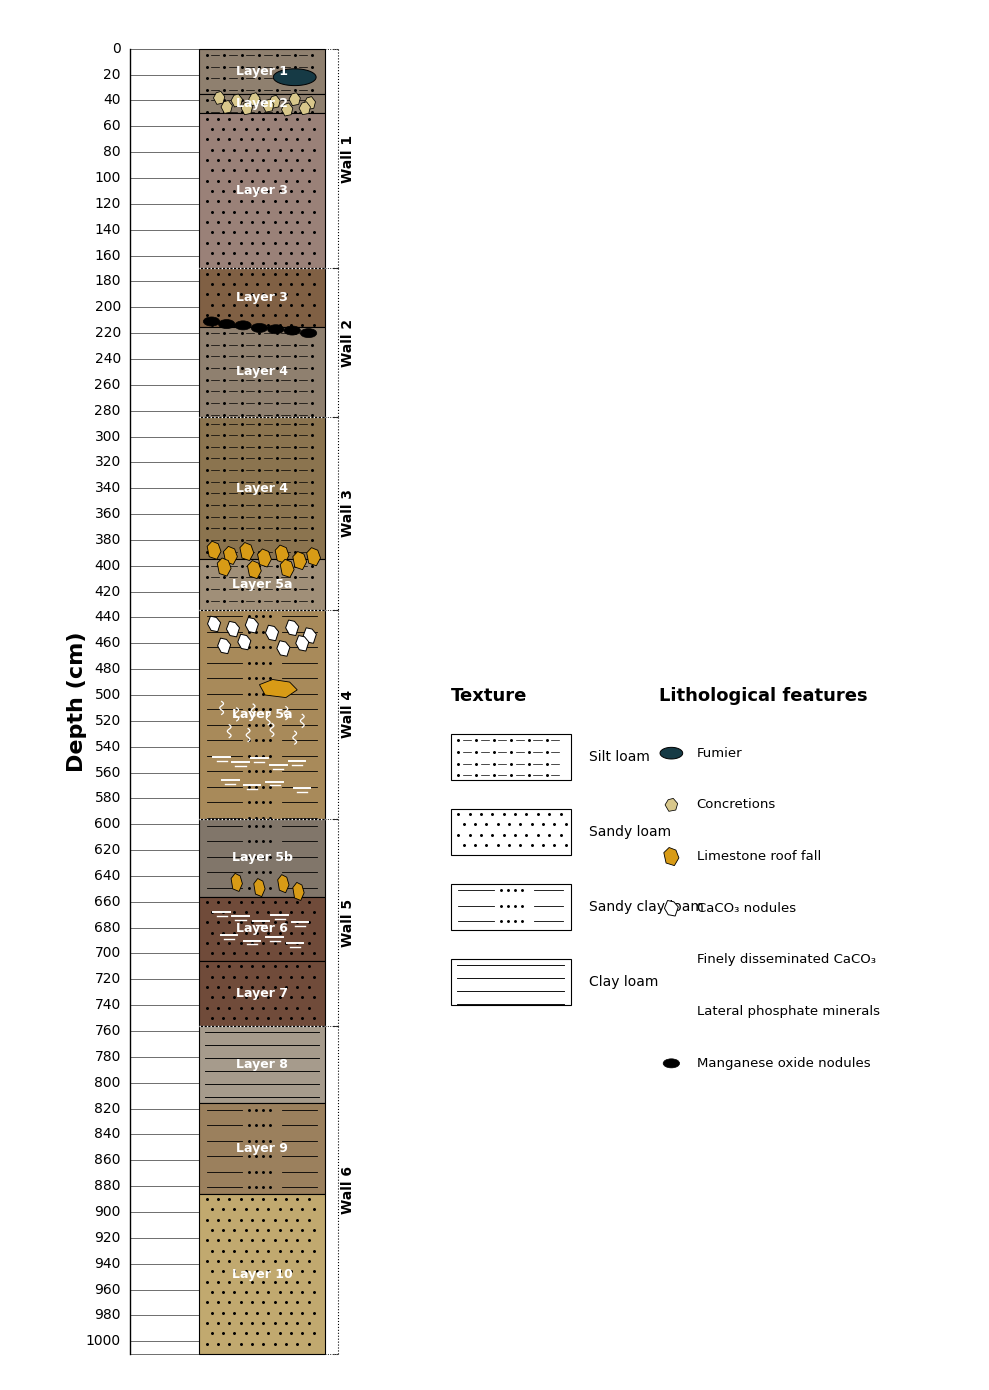

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle, Polygon, Ellipse

# ============================================================
# AZYKH CAVE — CONTINUOUS LITHOLOGICAL LOG
# Depth: 0–1010 cm
# ============================================================


# ============================================================
# 1. LAYER DATA
# ============================================================

layers = [
    (0,    35,   "#8F806F", "Silt loam",       "Layer 1"),
    (35,   50,   "#8F806F", "Silt loam",       "Layer 2"),
    (50,   170,  "#9A8178", "Sandy loam",      "Layer 3"),

    (170,  215,  "#806044", "Sandy loam",      "Layer 3"),
    (215,  285,  "#8F806F", "Silt loam",       "Layer 4"),

    (285,  395,  "#8B744F", "Silt loam",       "Layer 4"),
    (395,  434,  "#A08F78", "Silt loam",       "Layer 5a"),

    (434,  596,  "#A88A5A", "Sandy clay loam", "Layer 5a"),

    (596,  656,  "#81766A", "Sandy clay loam", "Layer 5b"),
    (656,  706,  "#704B3A", "Sandy loam",      "Layer 6"),
    (706,  756,  "#704B3A", "Sandy loam",      "Layer 7"),

    (756,  816,  "#A69B8C", "Clay loam",       "Layer 8"),
    (816,  886,  "#9B805D", "Sandy clay loam", "Layer 9"),
    (886, 1010,  "#C1A96F", "Sandy loam",      "Layer 10"),
]


# ============================================================
# 2. WALL DATA
# ============================================================

walls = [
    (0,    170,  "Wall 1"),
    (170,  285,  "Wall 2"),
    (285,  434,  "Wall 3"),
    (434,  596,  "Wall 4"),
    (596,  756,  "Wall 5"),
    (756, 1010,  "Wall 6"),
]


# ============================================================
# 3. FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(10, 14))

x = 0
width = 1.0


# ============================================================
# 4. TEXTURE PATTERNS
# ============================================================

def draw_texture(ax, left, right, top, bottom, texture):

    # SILT LOAM
    # . - . - . -
    if texture == "Silt loam":

        for y in np.arange(top + 5, bottom, 9):

            xpos = left + 0.06

            while xpos < right - 0.05:

                ax.plot(
                    xpos, y,
                    marker=".",
                    markersize=2.3,
                    color="black",
                    zorder=3
                )

                if xpos + 0.10 < right:

                    ax.plot(
                        [xpos + 0.035, xpos + 0.10],
                        [y, y],
                        color="black",
                        linewidth=0.5,
                        zorder=3
                    )

                xpos += 0.14


    # SANDY LOAM
    # dots
    elif texture == "Sandy loam":

        row = 0

        for y in np.arange(top + 4, bottom, 8):

            offset = 0.04 if row % 2 else 0

            for xpos in np.arange(
                left + 0.06 + offset,
                right - 0.04,
                0.09
            ):

                ax.plot(
                    xpos, y,
                    marker=".",
                    markersize=2.3,
                    color="black",
                    zorder=3
                )

            row += 1


    # SANDY CLAY LOAM
    # line + dots + line
    elif texture == "Sandy clay loam":

        for y in np.arange(top + 5, bottom, 12):

            ax.plot(
                [left + 0.06, left + 0.34],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            for xpos in np.arange(
                left + 0.40,
                left + 0.61,
                0.055
            ):

                ax.plot(
                    xpos, y,
                    marker=".",
                    markersize=2.2,
                    color="black",
                    zorder=3
                )

            ax.plot(
                [left + 0.66, right - 0.06],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )


    # CLAY LOAM
    # horizontal lines
    elif texture == "Clay loam":

        for y in np.arange(top + 5, bottom, 10):

            ax.plot(
                [left + 0.05, right - 0.05],
                [y, y],
                color="black",
                linewidth=0.65,
                zorder=3
            )


# ============================================================
# 5. DRAW MAIN LOG
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    rect = Rectangle(
        (x, top),
        width,
        bottom - top,
        facecolor=colour,
        edgecolor="black",
        linewidth=0.8,
        zorder=1
    )

    ax.add_patch(rect)

    draw_texture(
        ax,
        x,
        x + width,
        top,
        bottom,
        texture
    )


# ============================================================
# 6. SPECIAL LITHOLOGICAL SYMBOLS
# ============================================================


# ------------------------------------------------------------
# FUMIER
# Dark lens shape
# ------------------------------------------------------------

def fumier_symbol(ax, xc, yc, w=0.35, h=14):

    t = np.linspace(0, 2*np.pi, 100)

    xs = xc + (w / 2) * np.cos(t)
    ys = yc + (h / 2) * np.sin(t)

    ax.fill(
        xs,
        ys,
        facecolor="#163A45",
        edgecolor="black",
        linewidth=0.7,
        zorder=8
    )


# ------------------------------------------------------------
# CONCRETION
# Small irregular outlined nodules
# ------------------------------------------------------------

def concretion_symbol(ax, xc, yc, size=0.06):

    points = [
        (xc - size, yc),
        (xc - size*0.5, yc - 4),
        (xc + size*0.3, yc - 5),
        (xc + size, yc - 1),
        (xc + size*0.7, yc + 4),
        (xc - size*0.4, yc + 5)
    ]

    p = Polygon(
        points,
        closed=True,
        facecolor="#D8C78B",
        edgecolor="black",
        linewidth=0.55,
        zorder=8
    )

    ax.add_patch(p)


# ------------------------------------------------------------
# LIMESTONE ROOF FALL
# Yellow angular fragment
# ------------------------------------------------------------

def limestone_symbol(ax, xc, yc, size=0.075):

    points = [
        (xc - size, yc - 3),
        (xc - size*0.3, yc - 7),
        (xc + size*0.6, yc - 5),
        (xc + size, yc + 1),
        (xc + size*0.4, yc + 7),
        (xc - size*0.7, yc + 5)
    ]

    p = Polygon(
        points,
        closed=True,
        facecolor="#D89B16",
        edgecolor="black",
        linewidth=0.6,
        zorder=9
    )

    ax.add_patch(p)


# ------------------------------------------------------------
# CALCIUM CARBONATE NODULE
# White outlined irregular clast
# ------------------------------------------------------------

def carbonate_nodule(ax, xc, yc, size=0.07):

    points = [
        (xc - size, yc),
        (xc - size*0.55, yc - 6),
        (xc + size*0.35, yc - 5),
        (xc + size, yc - 1),
        (xc + size*0.55, yc + 6),
        (xc - size*0.45, yc + 5)
    ]

    p = Polygon(
        points,
        closed=True,
        facecolor="white",
        edgecolor="black",
        linewidth=0.7,
        zorder=9
    )

    ax.add_patch(p)


# ------------------------------------------------------------
# MANGANESE OXIDE NODULE
# Black elongated nodule
# ------------------------------------------------------------

def manganese_symbol(ax, xc, yc, angle=0):

    e = Ellipse(
        (xc, yc),
        width=0.13,
        height=7,
        angle=angle,
        facecolor="black",
        edgecolor="black",
        linewidth=0.5,
        zorder=9
    )

    ax.add_patch(e)


# ------------------------------------------------------------
# LATERAL PHOSPHATE
# Small pale horizontal curved/dashed marks
# ------------------------------------------------------------

def phosphate_symbol(ax, xc, yc):

    ax.plot(
        [xc - 0.065, xc + 0.065],
        [yc, yc],
        color="white",
        linewidth=1.4,
        zorder=9
    )

    ax.plot(
        [xc - 0.04, xc + 0.04],
        [yc + 3, yc + 3],
        color="white",
        linewidth=1.0,
        zorder=9
    )


# ------------------------------------------------------------
# FINELY DISSEMINATED CaCO3
# Small vertical/wavy white marks
# ------------------------------------------------------------

def disseminated_caco3(ax, xc, yc):

    yvals = np.linspace(yc - 5, yc + 5, 20)

    xvals = xc + 0.015 * np.sin(
        np.linspace(0, 3*np.pi, 20)
    )

    ax.plot(
        xvals,
        yvals,
        color="white",
        linewidth=0.9,
        zorder=9
    )


# ============================================================
# 7. WALL 1 FEATURES
# ============================================================

# Fumier lens in upper Wall 1 / Layer 1
fumier_symbol(
    ax,
    0.76,
    22,
    w=0.34,
    h=13
)


# Concretions mainly around Layer 2
wall1_concretions = [
    (0.16, 38),
    (0.30, 40),
    (0.44, 39),
    (0.60, 41),
    (0.76, 39),
    (0.88, 42),

    (0.22, 45),
    (0.38, 46),
    (0.55, 44),
    (0.70, 47),
    (0.84, 46)
]

for xpos, ypos in wall1_concretions:
    concretion_symbol(
        ax,
        xpos,
        ypos,
        size=0.045
    )


# ============================================================
# 8. WALL 2 FEATURES
# Mn-oxide nodules around Layer 3 → Layer 4 transition
# ============================================================

wall2_mn = [
    (0.10, 211),
    (0.22, 213),
    (0.35, 214),
    (0.48, 216),
    (0.61, 217),
    (0.74, 218),
    (0.87, 220)
]

for xpos, ypos in wall2_mn:
    manganese_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 9. WALL 3 FEATURES
# Limestone roof-fall band near Layer 4 → Layer 5a
# ============================================================

wall3_limestone = [
    (0.12, 388),
    (0.25, 392),
    (0.38, 389),
    (0.52, 394),
    (0.66, 391),
    (0.80, 396),
    (0.91, 393),

    (0.20, 401),
    (0.44, 403),
    (0.70, 402)
]

for xpos, ypos in wall3_limestone:
    limestone_symbol(
        ax,
        xpos,
        ypos,
        size=0.055
    )


# ============================================================
# 10. WALL 4 FEATURES
# Layer 5a
# ============================================================


# ------------------------------------------------------------
# CaCO3 nodules — upper Wall 4
# ------------------------------------------------------------

wall4_carbonate = [
    (0.12, 445),
    (0.27, 449),
    (0.42, 446),
    (0.58, 452),
    (0.74, 448),
    (0.88, 454),

    (0.20, 462),
    (0.36, 459),
    (0.67, 464),
    (0.82, 460)
]

for xpos, ypos in wall4_carbonate:
    carbonate_nodule(
        ax,
        xpos,
        ypos,
        size=0.052
    )


# ------------------------------------------------------------
# Large limestone / roof-fall clast
# ------------------------------------------------------------

limestone_symbol(
    ax,
    0.63,
    495,
    size=0.15
)


# ------------------------------------------------------------
# Finely disseminated CaCO3
# ------------------------------------------------------------

wall4_caco3 = [
    (0.18, 510),
    (0.30, 515),
    (0.43, 512),
    (0.55, 518),
    (0.69, 514),
    (0.82, 520),

    (0.24, 528),
    (0.39, 531),
    (0.58, 527),
    (0.76, 533)
]

for xpos, ypos in wall4_caco3:
    disseminated_caco3(
        ax,
        xpos,
        ypos
    )


# ------------------------------------------------------------
# Lateral phosphate minerals
# ------------------------------------------------------------

wall4_phosphate = [
    (0.18, 548),
    (0.33, 552),
    (0.48, 549),
    (0.63, 554),
    (0.78, 551),

    (0.25, 566),
    (0.42, 570),
    (0.60, 567),
    (0.82, 572)
]

for xpos, ypos in wall4_phosphate:
    phosphate_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 11. WALL 5 FEATURES
# ============================================================


# ------------------------------------------------------------
# Limestone roof-fall around Layer 5b → Layer 6
# ------------------------------------------------------------

wall5_limestone = [
    (0.30, 645),
    (0.48, 649),
    (0.67, 646),
    (0.79, 652)
]

for xpos, ypos in wall5_limestone:
    limestone_symbol(
        ax,
        xpos,
        ypos,
        size=0.045
    )


# ------------------------------------------------------------
# Lateral phosphate in Layer 6
# ------------------------------------------------------------

wall5_phosphate = [
    (0.18, 668),
    (0.33, 671),
    (0.49, 675),
    (0.64, 670),
    (0.80, 676),

    (0.24, 686),
    (0.42, 690),
    (0.60, 687),
    (0.76, 692)
]

for xpos, ypos in wall5_phosphate:
    phosphate_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 12. LAYER LABELS
# ALL HORIZONTAL
# ============================================================

layer_fontsize = 9

for top, bottom, colour, texture, layer_name in layers:

    midpoint = (top + bottom) / 2

    ax.text(
        x + width / 2,
        midpoint,
        layer_name,
        color="white",
        fontsize=layer_fontsize,
        fontweight="bold",
        ha="center",
        va="center",
        rotation=0,
        zorder=20
    )


# ============================================================
# 13. WALL BRACKETS
# Small + dotted + outside log
# ============================================================

wall_x = x + width + 0.10

bracket_width = 0.035


for top, bottom, wall_name in walls:

    midpoint = (top + bottom) / 2

    # Vertical dotted bracket
    ax.plot(
        [wall_x, wall_x],
        [top, bottom],
        color="black",
        linewidth=0.8,
        linestyle=":",
        zorder=10
    )

    # Top arm
    ax.plot(
        [wall_x - bracket_width, wall_x],
        [top, top],
        color="black",
        linewidth=0.8,
        linestyle=":",
        zorder=10
    )

    # Bottom arm
    ax.plot(
        [wall_x - bracket_width, wall_x],
        [bottom, bottom],
        color="black",
        linewidth=0.8,
        linestyle=":",
        zorder=10
    )

    # Vertical wall label
    ax.text(
        wall_x + 0.08,
        midpoint,
        wall_name,
        fontsize=10,
        fontweight="bold",
        rotation=90,
        ha="center",
        va="center",
        color="black",
        zorder=20
    )


# ============================================================
# 14. WALL CONNECTORS
# ============================================================

wall_boundaries = [
    0,
    170,
    285,
    434,
    596,
    756,
    1010
]

for depth in wall_boundaries:

    ax.plot(
        [x + width, wall_x],
        [depth, depth],
        color="black",
        linewidth=0.65,
        linestyle=":",
        zorder=9
    )


# ============================================================
# 15. WALL BOUNDARIES INSIDE LOG
# ============================================================

for depth in [
    170,
    285,
    434,
    596,
    756
]:

    ax.plot(
        [x, x + width],
        [depth, depth],
        color="white",
        linewidth=1.0,
        linestyle=":",
        zorder=12
    )


# ============================================================
# 16. DEPTH SCALE
# ============================================================

scale_x = -0.55

ax.plot(
    [scale_x, scale_x],
    [0, 1010],
    color="black",
    linewidth=1
)


# Depth title
ax.text(
    scale_x - 0.42,
    505,
    "Depth (cm)",
    rotation=90,
    fontsize=16,
    fontweight="bold",
    ha="center",
    va="center"
)


# Depth ticks every 20 cm
for depth in range(0, 1001, 20):

    ax.plot(
        [scale_x, x],
        [depth, depth],
        color="black",
        linewidth=0.4
    )

    ax.text(
        scale_x - 0.07,
        depth,
        str(depth),
        fontsize=10,
        ha="right",
        va="center"
    )


# 1010 cm bottom boundary
ax.plot(
    [scale_x, x],
    [1010, 1010],
    color="black",
    linewidth=0.4
)


# ============================================================
# 17. TEXTURE LEGEND
# ============================================================

legend_x = 2.0
legend_y = 530

legend_width = 0.95
legend_height = 36
legend_spacing = 58


ax.text(
    legend_x,
    legend_y - 25,
    "Texture",
    fontsize=13,
    fontweight="bold",
    ha="left"
)


legend_items = [
    "Silt loam",
    "Sandy loam",
    "Sandy clay loam",
    "Clay loam"
]


for i, texture in enumerate(legend_items):

    top = legend_y + i * legend_spacing
    bottom = top + legend_height

    box = Rectangle(
        (legend_x, top),
        legend_width,
        legend_height,
        facecolor="white",
        edgecolor="black",
        linewidth=0.8,
        zorder=1
    )

    ax.add_patch(box)

    draw_texture(
        ax,
        legend_x,
        legend_x + legend_width,
        top,
        bottom,
        texture
    )

    ax.text(
        legend_x + legend_width + 0.15,
        (top + bottom) / 2,
        texture,
        fontsize=10,
        ha="left",
        va="center"
    )


# ============================================================
# 18. LITHOLOGICAL FEATURES LEGEND
# ============================================================

feature_x = 3.65
feature_y = 530


ax.text(
    feature_x,
    feature_y - 25,
    "Lithological features",
    fontsize=13,
    fontweight="bold",
    ha="left"
)


# Fumier
fumier_symbol(
    ax,
    feature_x + 0.10,
    feature_y + 15,
    w=0.18,
    h=9
)

ax.text(
    feature_x + 0.30,
    feature_y + 15,
    "Fumier",
    fontsize=9.5,
    va="center"
)


# Concretions
concretion_symbol(
    ax,
    feature_x + 0.10,
    feature_y + 55,
    size=0.05
)

ax.text(
    feature_x + 0.30,
    feature_y + 55,
    "Concretions",
    fontsize=9.5,
    va="center"
)


# Limestone roof fall
limestone_symbol(
    ax,
    feature_x + 0.10,
    feature_y + 95,
    size=0.06
)

ax.text(
    feature_x + 0.30,
    feature_y + 95,
    "Limestone roof fall",
    fontsize=9.5,
    va="center"
)


# Calcium carbonate nodule
carbonate_nodule(
    ax,
    feature_x + 0.10,
    feature_y + 135,
    size=0.055
)

ax.text(
    feature_x + 0.30,
    feature_y + 135,
    "CaCO₃ nodules",
    fontsize=9.5,
    va="center"
)


# Disseminated CaCO3
disseminated_caco3(
    ax,
    feature_x + 0.10,
    feature_y + 175
)

ax.text(
    feature_x + 0.30,
    feature_y + 175,
    "Finely disseminated CaCO₃",
    fontsize=9.5,
    va="center"
)


# Lateral phosphate
phosphate_symbol(
    ax,
    feature_x + 0.10,
    feature_y + 215
)

ax.text(
    feature_x + 0.30,
    feature_y + 215,
    "Lateral phosphate minerals",
    fontsize=9.5,
    va="center"
)


# Manganese oxide nodules
manganese_symbol(
    ax,
    feature_x + 0.10,
    feature_y + 255
)

ax.text(
    feature_x + 0.30,
    feature_y + 255,
    "Manganese oxide nodules",
    fontsize=9.5,
    va="center"
)


# ============================================================
# 19. FINAL FORMATTING
# ============================================================

ax.set_xlim(-1.5, 6.2)

ax.set_ylim(
    1030,
    -30
)

ax.axis("off")

plt.tight_layout()


# ============================================================
# 20. SAVE
# ============================================================

plt.savefig(
    "Azykh_complete_lithological_log_features.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Azykh_complete_lithological_log_features.pdf",
    bbox_inches="tight"
)


# ============================================================
# 21. SHOW
# ============================================================

plt.show()

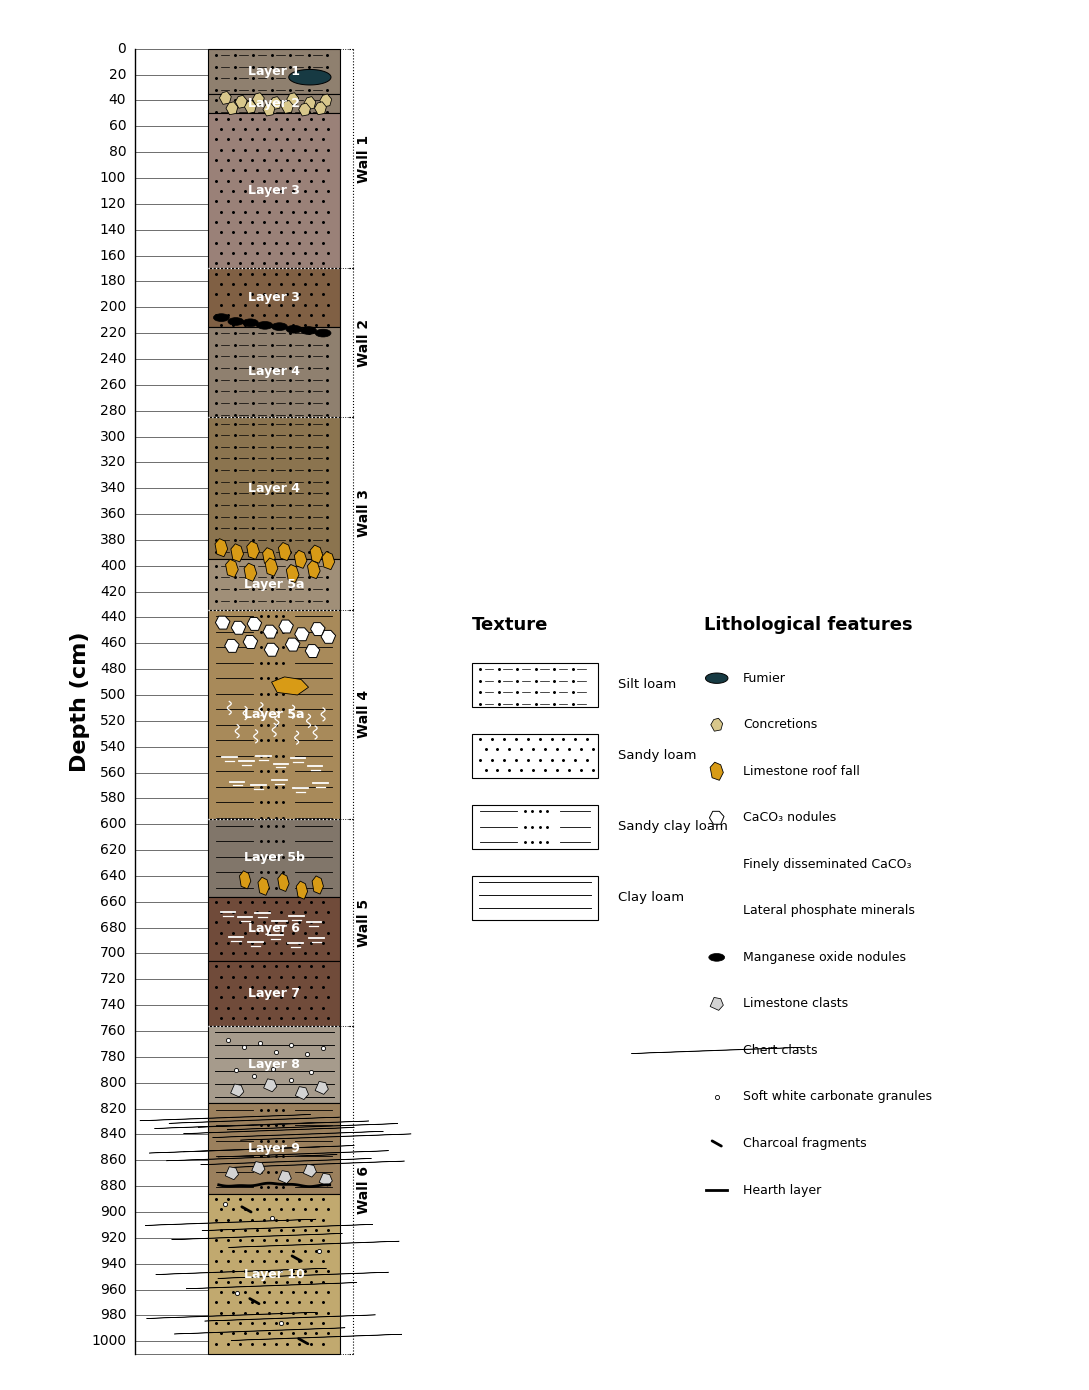

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle, Polygon, Ellipse

# ============================================================
# AZYKH CAVE — COMPOSITE LITHOLOGICAL LOG
# Depth: 0–1010 cm
# ============================================================


# ============================================================
# 1. LAYER DATA
# ============================================================

layers = [
    (0,    35,   "#8F806F", "Silt loam",       "Layer 1"),
    (35,   50,   "#8F806F", "Silt loam",       "Layer 2"),
    (50,   170,  "#9A8178", "Sandy loam",      "Layer 3"),

    (170,  215,  "#806044", "Sandy loam",      "Layer 3"),
    (215,  285,  "#8F806F", "Silt loam",       "Layer 4"),

    (285,  395,  "#8B744F", "Silt loam",       "Layer 4"),
    (395,  434,  "#A08F78", "Silt loam",       "Layer 5a"),

    (434,  596,  "#A88A5A", "Sandy clay loam", "Layer 5a"),

    (596,  656,  "#81766A", "Sandy clay loam", "Layer 5b"),
    (656,  706,  "#704B3A", "Sandy loam",      "Layer 6"),
    (706,  756,  "#704B3A", "Sandy loam",      "Layer 7"),

    (756,  816,  "#A69B8C", "Clay loam",       "Layer 8"),
    (816,  886,  "#9B805D", "Sandy clay loam", "Layer 9"),
    (886, 1010,  "#C1A96F", "Sandy loam",      "Layer 10"),
]


# ============================================================
# 2. WALL DATA
# ============================================================

walls = [
    (0,    170,  "Wall 1"),
    (170,  285,  "Wall 2"),
    (285,  434,  "Wall 3"),
    (434,  596,  "Wall 4"),
    (596,  756,  "Wall 5"),
    (756, 1010,  "Wall 6"),
]


# ============================================================
# 3. FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(11, 14))

x = 0
width = 1.0


# ============================================================
# 4. TEXTURE PATTERNS
# ============================================================

def draw_texture(ax, left, right, top, bottom, texture):

    # --------------------------------------------------------
    # SILT LOAM
    # . - . - . -
    # --------------------------------------------------------

    if texture == "Silt loam":

        for y in np.arange(top + 5, bottom, 9):

            xpos = left + 0.06

            while xpos < right - 0.05:

                ax.plot(
                    xpos, y,
                    marker=".",
                    markersize=2.3,
                    color="black",
                    zorder=3
                )

                if xpos + 0.10 < right:

                    ax.plot(
                        [xpos + 0.035, xpos + 0.10],
                        [y, y],
                        color="black",
                        linewidth=0.5,
                        zorder=3
                    )

                xpos += 0.14


    # --------------------------------------------------------
    # SANDY LOAM
    # Dots
    # --------------------------------------------------------

    elif texture == "Sandy loam":

        row = 0

        for y in np.arange(top + 4, bottom, 8):

            offset = 0.04 if row % 2 else 0

            for xpos in np.arange(
                left + 0.06 + offset,
                right - 0.04,
                0.09
            ):

                ax.plot(
                    xpos, y,
                    marker=".",
                    markersize=2.3,
                    color="black",
                    zorder=3
                )

            row += 1


    # --------------------------------------------------------
    # SANDY CLAY LOAM
    # Lines + dots + lines
    # --------------------------------------------------------

    elif texture == "Sandy clay loam":

        for y in np.arange(top + 5, bottom, 12):

            ax.plot(
                [left + 0.06, left + 0.34],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            for xpos in np.arange(
                left + 0.40,
                left + 0.61,
                0.055
            ):

                ax.plot(
                    xpos, y,
                    marker=".",
                    markersize=2.2,
                    color="black",
                    zorder=3
                )

            ax.plot(
                [left + 0.66, right - 0.06],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )


    # --------------------------------------------------------
    # CLAY LOAM
    # Horizontal lines
    # --------------------------------------------------------

    elif texture == "Clay loam":

        for y in np.arange(top + 5, bottom, 10):

            ax.plot(
                [left + 0.05, right - 0.05],
                [y, y],
                color="black",
                linewidth=0.65,
                zorder=3
            )


# ============================================================
# 5. DRAW MAIN LITHOLOGICAL LOG
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    rect = Rectangle(
        (x, top),
        width,
        bottom - top,
        facecolor=colour,
        edgecolor="black",
        linewidth=0.8,
        zorder=1
    )

    ax.add_patch(rect)

    draw_texture(
        ax,
        x,
        x + width,
        top,
        bottom,
        texture
    )


# ============================================================
# 6. FEATURE SYMBOL FUNCTIONS
# ============================================================


# ------------------------------------------------------------
# FUMIER — dark lens
# ------------------------------------------------------------

def fumier_symbol(ax, xc, yc, w=0.32, h=12):

    t = np.linspace(0, 2*np.pi, 100)

    xs = xc + (w / 2) * np.cos(t)
    ys = yc + (h / 2) * np.sin(t)

    ax.fill(
        xs,
        ys,
        facecolor="#173A43",
        edgecolor="black",
        linewidth=0.7,
        zorder=9
    )


# ------------------------------------------------------------
# CONCRETION
# ------------------------------------------------------------

def concretion_symbol(ax, xc, yc, size=0.045):

    points = [
        (xc - size, yc),
        (xc - size*0.5, yc - 4),
        (xc + size*0.3, yc - 5),
        (xc + size, yc - 1),
        (xc + size*0.7, yc + 4),
        (xc - size*0.4, yc + 5)
    ]

    polygon = Polygon(
        points,
        closed=True,
        facecolor="#D8C78B",
        edgecolor="black",
        linewidth=0.55,
        zorder=9
    )

    ax.add_patch(polygon)


# ------------------------------------------------------------
# LIMESTONE ROOF FALL — yellow angular fragment
# ------------------------------------------------------------

def limestone_roof_fall(ax, xc, yc, size=0.055):

    points = [
        (xc - size, yc - 3),
        (xc - size*0.3, yc - 7),
        (xc + size*0.6, yc - 5),
        (xc + size, yc + 1),
        (xc + size*0.4, yc + 7),
        (xc - size*0.7, yc + 5)
    ]

    polygon = Polygon(
        points,
        closed=True,
        facecolor="#D89B16",
        edgecolor="black",
        linewidth=0.6,
        zorder=9
    )

    ax.add_patch(polygon)


# ------------------------------------------------------------
# CaCO3 NODULE
# ------------------------------------------------------------

def carbonate_nodule(ax, xc, yc, size=0.055):

    points = [
        (xc - size, yc),
        (xc - size*0.55, yc - 5),
        (xc + size*0.35, yc - 5),
        (xc + size, yc - 1),
        (xc + size*0.55, yc + 5),
        (xc - size*0.45, yc + 5)
    ]

    polygon = Polygon(
        points,
        closed=True,
        facecolor="white",
        edgecolor="black",
        linewidth=0.7,
        zorder=9
    )

    ax.add_patch(polygon)


# ------------------------------------------------------------
# MANGANESE OXIDE NODULE
# ------------------------------------------------------------

def manganese_symbol(ax, xc, yc):

    ellipse = Ellipse(
        (xc, yc),
        width=0.12,
        height=6,
        facecolor="black",
        edgecolor="black",
        linewidth=0.5,
        zorder=9
    )

    ax.add_patch(ellipse)


# ------------------------------------------------------------
# LATERAL PHOSPHATE MINERAL
# ------------------------------------------------------------

def phosphate_symbol(ax, xc, yc):

    ax.plot(
        [xc - 0.055, xc + 0.055],
        [yc, yc],
        color="white",
        linewidth=1.3,
        zorder=10
    )

    ax.plot(
        [xc - 0.035, xc + 0.035],
        [yc + 3, yc + 3],
        color="white",
        linewidth=0.9,
        zorder=10
    )


# ------------------------------------------------------------
# FINELY DISSEMINATED CaCO3
# ------------------------------------------------------------

def disseminated_caco3(ax, xc, yc):

    yvals = np.linspace(yc - 5, yc + 5, 20)

    xvals = xc + 0.015 * np.sin(
        np.linspace(0, 3*np.pi, 20)
    )

    ax.plot(
        xvals,
        yvals,
        color="white",
        linewidth=0.9,
        zorder=10
    )


# ------------------------------------------------------------
# LIMESTONE CLAST — Wall 6
# ------------------------------------------------------------

def limestone_clast(ax, xc, yc, size=0.05):

    points = [
        (xc - size, yc + 2),
        (xc - size*0.4, yc - 5),
        (xc + size*0.6, yc - 4),
        (xc + size, yc + 1),
        (xc + size*0.3, yc + 5)
    ]

    polygon = Polygon(
        points,
        closed=True,
        facecolor="lightgray",
        edgecolor="black",
        linewidth=0.55,
        zorder=9
    )

    ax.add_patch(polygon)


# ------------------------------------------------------------
# CHERT CLAST
# ------------------------------------------------------------

def chert_clast(ax, xc, yc):

    ellipse = Ellipse(
        (xc, yc),
        width=0.085,
        height=5,
        angle=15,
        facecolor="dimgray",
        edgecolor="black",
        linewidth=0.4,
        zorder=9
    )

    ax.add_patch(ellipse)


# ------------------------------------------------------------
# SOFT WHITE CARBONATE GRANULE
# ------------------------------------------------------------

def carbonate_granule(ax, xc, yc):

    ax.plot(
        xc,
        yc,
        marker="o",
        markersize=3.0,
        markerfacecolor="white",
        markeredgecolor="black",
        markeredgewidth=0.6,
        zorder=10
    )


# ------------------------------------------------------------
# CHARCOAL FRAGMENT
# ------------------------------------------------------------

def charcoal_fragment(ax, xc, yc):

    ax.plot(
        [xc - 0.035, xc + 0.035],
        [yc - 2, yc + 2],
        color="black",
        linewidth=2.0,
        solid_capstyle="round",
        zorder=10
    )


# ------------------------------------------------------------
# HEARTH LAYER
# ------------------------------------------------------------

def hearth_layer(ax, y):

    xs = np.linspace(0.08, 0.92, 60)

    ys = (
        y
        + 1.0 * np.sin(np.linspace(0, 3*np.pi, 60))
        + 0.4 * np.sin(np.linspace(0, 8*np.pi, 60))
    )

    ax.plot(
        xs,
        ys,
        color="black",
        linewidth=2.0,
        zorder=11
    )


# ============================================================
# 7. WALL 1
# 0–170 cm
# Fumier + concretions
# ============================================================

fumier_symbol(
    ax,
    0.77,
    22,
    w=0.32,
    h=12
)


wall1_concretions = [
    (0.13, 38),
    (0.25, 41),
    (0.38, 39),
    (0.51, 42),
    (0.64, 39),
    (0.77, 42),
    (0.89, 40),

    (0.18, 46),
    (0.32, 45),
    (0.46, 47),
    (0.60, 45),
    (0.73, 47),
    (0.85, 46)
]

for xpos, ypos in wall1_concretions:

    concretion_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 8. WALL 2
# 170–285 cm
# Mn-oxide nodules
# ============================================================

wall2_mn = [
    (0.10, 208),
    (0.21, 211),
    (0.32, 212),
    (0.43, 214),
    (0.54, 215),
    (0.65, 217),
    (0.76, 218),
    (0.87, 220)
]

for xpos, ypos in wall2_mn:

    manganese_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 9. WALL 3
# 285–434 cm
# Limestone roof-fall band
# ============================================================

wall3_limestone = [
    (0.10, 386),
    (0.22, 390),
    (0.34, 388),
    (0.46, 393),
    (0.58, 389),
    (0.70, 395),
    (0.82, 391),
    (0.91, 396),

    (0.18, 402),
    (0.32, 405),
    (0.48, 401),
    (0.64, 406),
    (0.80, 403)
]

for xpos, ypos in wall3_limestone:

    limestone_roof_fall(
        ax,
        xpos,
        ypos,
        size=0.048
    )


# ============================================================
# 10. WALL 4
# 434–596 cm
# CaCO3 + roof fall + phosphate
# ============================================================


# CaCO3 nodules
wall4_carbonate = [
    (0.11, 444),
    (0.23, 448),
    (0.35, 445),
    (0.47, 451),
    (0.59, 447),
    (0.71, 453),
    (0.83, 449),
    (0.91, 455),

    (0.18, 462),
    (0.32, 459),
    (0.48, 465),
    (0.64, 461),
    (0.79, 466)
]

for xpos, ypos in wall4_carbonate:

    carbonate_nodule(
        ax,
        xpos,
        ypos
    )


# Large roof-fall clast
limestone_roof_fall(
    ax,
    0.62,
    493,
    size=0.14
)


# Finely disseminated CaCO3
wall4_caco3 = [
    (0.16, 510),
    (0.28, 514),
    (0.40, 511),
    (0.52, 518),
    (0.64, 513),
    (0.76, 520),
    (0.87, 515),

    (0.22, 528),
    (0.36, 532),
    (0.50, 527),
    (0.67, 533),
    (0.81, 529)
]

for xpos, ypos in wall4_caco3:

    disseminated_caco3(
        ax,
        xpos,
        ypos
    )


# Lateral phosphate minerals
wall4_phosphate = [
    (0.16, 548),
    (0.29, 551),
    (0.42, 547),
    (0.55, 553),
    (0.68, 549),
    (0.81, 555),

    (0.22, 567),
    (0.38, 570),
    (0.54, 566),
    (0.70, 572),
    (0.85, 568)
]

for xpos, ypos in wall4_phosphate:

    phosphate_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 11. WALL 5
# 596–756 cm
# Roof-fall + phosphate
# ============================================================

wall5_limestone = [
    (0.28, 643),
    (0.42, 648),
    (0.57, 645),
    (0.71, 651),
    (0.83, 647)
]

for xpos, ypos in wall5_limestone:

    limestone_roof_fall(
        ax,
        xpos,
        ypos,
        size=0.043
    )


wall5_phosphate = [
    (0.15, 668),
    (0.28, 672),
    (0.41, 669),
    (0.54, 675),
    (0.67, 671),
    (0.80, 676),

    (0.21, 687),
    (0.36, 691),
    (0.51, 686),
    (0.66, 692),
    (0.82, 688)
]

for xpos, ypos in wall5_phosphate:

    phosphate_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 12. WALL 6
# 756–1010 cm
# Adapted from Azykh published log
# ============================================================


# ------------------------------------------------------------
# LAYER 8
# Carbonate granules
# ------------------------------------------------------------

wall6_carbonate = [
    (0.15, 767),
    (0.27, 772),
    (0.39, 769),
    (0.51, 776),
    (0.63, 771),
    (0.75, 778),
    (0.87, 773),

    (0.21, 790),
    (0.35, 795),
    (0.49, 789),
    (0.63, 798),
    (0.78, 792)
]

for xpos, ypos in wall6_carbonate:

    carbonate_granule(
        ax,
        xpos,
        ypos
    )


# Limestone clasts Layer 8
for xpos, ypos in [
    (0.22, 806),
    (0.47, 802),
    (0.71, 808),
    (0.86, 804)
]:

    limestone_clast(
        ax,
        xpos,
        ypos
    )


# ------------------------------------------------------------
# LAYER 9
# Chert-rich interval
# ------------------------------------------------------------

wall6_chert = [
    (0.13, 827),
    (0.24, 833),
    (0.35, 829),
    (0.46, 837),
    (0.57, 832),
    (0.68, 840),
    (0.79, 834),
    (0.89, 842),

    (0.20, 852),
    (0.33, 858),
    (0.46, 851),
    (0.59, 861),
    (0.72, 855),
    (0.84, 863)
]

for xpos, ypos in wall6_chert:

    chert_clast(
        ax,
        xpos,
        ypos
    )


# Limestone clasts Layer 9
for xpos, ypos in [
    (0.18, 870),
    (0.38, 866),
    (0.58, 873),
    (0.77, 868),
    (0.89, 875)
]:

    limestone_clast(
        ax,
        xpos,
        ypos
    )


# Hearth horizon near bottom of Layer 9
hearth_layer(
    ax,
    879
)


# ------------------------------------------------------------
# LAYER 10
# Scattered chert + charcoal + carbonate granules
# ------------------------------------------------------------

for xpos, ypos in [
    (0.17, 908),
    (0.37, 919),
    (0.60, 912),
    (0.80, 925),

    (0.25, 946),
    (0.48, 957),
    (0.72, 949),

    (0.18, 980),
    (0.39, 992),
    (0.62, 982),
    (0.82, 997)
]:

    chert_clast(
        ax,
        xpos,
        ypos
    )


# Charcoal fragments
for xpos, ypos in [
    (0.29, 898),
    (0.67, 936),
    (0.35, 969),
    (0.72, 1000)
]:

    charcoal_fragment(
        ax,
        xpos,
        ypos
    )


# Carbonate granules
for xpos, ypos in [
    (0.13, 894),
    (0.48, 905),
    (0.84, 930),
    (0.22, 963),
    (0.55, 986)
]:

    carbonate_granule(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 13. LAYER LABELS
# ALL HORIZONTAL
# ============================================================

layer_fontsize = 9

for top, bottom, colour, texture, layer_name in layers:

    midpoint = (top + bottom) / 2

    ax.text(
        x + width / 2,
        midpoint,
        layer_name,
        color="white",
        fontsize=layer_fontsize,
        fontweight="bold",
        ha="center",
        va="center",
        rotation=0,
        zorder=30
    )


# ============================================================
# 14. WALL BRACKETS
# Small, dotted and outside the log
# ============================================================

wall_x = x + width + 0.10

bracket_width = 0.035


for top, bottom, wall_name in walls:

    midpoint = (top + bottom) / 2

    # Vertical dotted bracket
    ax.plot(
        [wall_x, wall_x],
        [top, bottom],
        color="black",
        linewidth=0.8,
        linestyle=":",
        zorder=15
    )

    # Top short arm
    ax.plot(
        [wall_x - bracket_width, wall_x],
        [top, top],
        color="black",
        linewidth=0.8,
        linestyle=":",
        zorder=15
    )

    # Bottom short arm
    ax.plot(
        [wall_x - bracket_width, wall_x],
        [bottom, bottom],
        color="black",
        linewidth=0.8,
        linestyle=":",
        zorder=15
    )

    # Vertical Wall label
    ax.text(
        wall_x + 0.08,
        midpoint,
        wall_name,
        fontsize=10,
        fontweight="bold",
        rotation=90,
        ha="center",
        va="center",
        color="black",
        zorder=20
    )


# ============================================================
# 15. WALL CONNECTORS
# ============================================================

wall_boundaries = [
    0,
    170,
    285,
    434,
    596,
    756,
    1010
]

for depth in wall_boundaries:

    ax.plot(
        [x + width, wall_x],
        [depth, depth],
        color="black",
        linewidth=0.65,
        linestyle=":",
        zorder=14
    )


# ============================================================
# 16. WALL BOUNDARIES THROUGH LOG
# ============================================================

for depth in [
    170,
    285,
    434,
    596,
    756
]:

    ax.plot(
        [x, x + width],
        [depth, depth],
        color="white",
        linewidth=1.0,
        linestyle=":",
        zorder=20
    )


# ============================================================
# 17. DEPTH SCALE
# ============================================================

scale_x = -0.55

ax.plot(
    [scale_x, scale_x],
    [0, 1010],
    color="black",
    linewidth=1
)


# Depth title
ax.text(
    scale_x - 0.42,
    505,
    "Depth (cm)",
    rotation=90,
    fontsize=16,
    fontweight="bold",
    ha="center",
    va="center"
)


# Depth ticks every 20 cm
for depth in range(0, 1001, 20):

    ax.plot(
        [scale_x, x],
        [depth, depth],
        color="black",
        linewidth=0.4
    )

    ax.text(
        scale_x - 0.07,
        depth,
        str(depth),
        fontsize=10,
        ha="right",
        va="center"
    )


# Bottom 1010 boundary
ax.plot(
    [scale_x, x],
    [1010, 1010],
    color="black",
    linewidth=0.4
)


# ============================================================
# 18. TEXTURE LEGEND
# ============================================================

legend_x = 2.0
legend_y = 475

legend_width = 0.95
legend_height = 34
legend_spacing = 55


ax.text(
    legend_x,
    legend_y - 25,
    "Texture",
    fontsize=13,
    fontweight="bold",
    ha="left"
)


legend_items = [
    "Silt loam",
    "Sandy loam",
    "Sandy clay loam",
    "Clay loam"
]


for i, texture in enumerate(legend_items):

    top = legend_y + i * legend_spacing
    bottom = top + legend_height

    box = Rectangle(
        (legend_x, top),
        legend_width,
        legend_height,
        facecolor="white",
        edgecolor="black",
        linewidth=0.8,
        zorder=1
    )

    ax.add_patch(box)

    draw_texture(
        ax,
        legend_x,
        legend_x + legend_width,
        top,
        bottom,
        texture
    )

    ax.text(
        legend_x + legend_width + 0.15,
        (top + bottom) / 2,
        texture,
        fontsize=9.5,
        ha="left",
        va="center"
    )


# ============================================================
# 19. LITHOLOGICAL FEATURES LEGEND
# ============================================================

feature_x = 3.75
feature_y = 475


ax.text(
    feature_x,
    feature_y - 25,
    "Lithological features",
    fontsize=13,
    fontweight="bold",
    ha="left"
)


# Fumier
fumier_symbol(
    ax,
    feature_x + 0.10,
    feature_y + 12,
    w=0.17,
    h=8
)

ax.text(
    feature_x + 0.30,
    feature_y + 12,
    "Fumier",
    fontsize=9,
    va="center"
)


# Concretions
concretion_symbol(
    ax,
    feature_x + 0.10,
    feature_y + 48
)

ax.text(
    feature_x + 0.30,
    feature_y + 48,
    "Concretions",
    fontsize=9,
    va="center"
)


# Limestone roof fall
limestone_roof_fall(
    ax,
    feature_x + 0.10,
    feature_y + 84,
    size=0.05
)

ax.text(
    feature_x + 0.30,
    feature_y + 84,
    "Limestone roof fall",
    fontsize=9,
    va="center"
)


# CaCO3 nodules
carbonate_nodule(
    ax,
    feature_x + 0.10,
    feature_y + 120
)

ax.text(
    feature_x + 0.30,
    feature_y + 120,
    "CaCO₃ nodules",
    fontsize=9,
    va="center"
)


# Disseminated CaCO3
disseminated_caco3(
    ax,
    feature_x + 0.10,
    feature_y + 156
)

ax.text(
    feature_x + 0.30,
    feature_y + 156,
    "Finely disseminated CaCO₃",
    fontsize=9,
    va="center"
)


# Phosphate
phosphate_symbol(
    ax,
    feature_x + 0.10,
    feature_y + 192
)

ax.text(
    feature_x + 0.30,
    feature_y + 192,
    "Lateral phosphate minerals",
    fontsize=9,
    va="center"
)


# Mn oxide
manganese_symbol(
    ax,
    feature_x + 0.10,
    feature_y + 228
)

ax.text(
    feature_x + 0.30,
    feature_y + 228,
    "Manganese oxide nodules",
    fontsize=9,
    va="center"
)


# Limestone clast
limestone_clast(
    ax,
    feature_x + 0.10,
    feature_y + 264
)

ax.text(
    feature_x + 0.30,
    feature_y + 264,
    "Limestone clasts",
    fontsize=9,
    va="center"
)


# Chert
chert_clast(
    ax,
    feature_x + 0.10,
    feature_y + 300
)

ax.text(
    feature_x + 0.30,
    feature_y + 300,
    "Chert clasts",
    fontsize=9,
    va="center"
)


# Carbonate granules
carbonate_granule(
    ax,
    feature_x + 0.10,
    feature_y + 336
)

ax.text(
    feature_x + 0.30,
    feature_y + 336,
    "Soft white carbonate granules",
    fontsize=9,
    va="center"
)


# Charcoal
charcoal_fragment(
    ax,
    feature_x + 0.10,
    feature_y + 372
)

ax.text(
    feature_x + 0.30,
    feature_y + 372,
    "Charcoal fragments",
    fontsize=9,
    va="center"
)


# Hearth
ax.plot(
    [feature_x + 0.02, feature_x + 0.18],
    [feature_y + 408, feature_y + 408],
    color="black",
    linewidth=2
)

ax.text(
    feature_x + 0.30,
    feature_y + 408,
    "Hearth layer",
    fontsize=9,
    va="center"
)


# ============================================================
# 20. FINAL FORMATTING
# ============================================================

ax.set_xlim(-1.5, 6.6)
ax.set_ylim(1030, -30)

ax.axis("off")

plt.tight_layout()


# ============================================================
# 21. SAVE
# ============================================================

plt.savefig(
    "Azykh_complete_Walls_1_to_6.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Azykh_complete_Walls_1_to_6.pdf",
    bbox_inches="tight"
)


# ============================================================
# 22. SHOW
# ============================================================

plt.show()

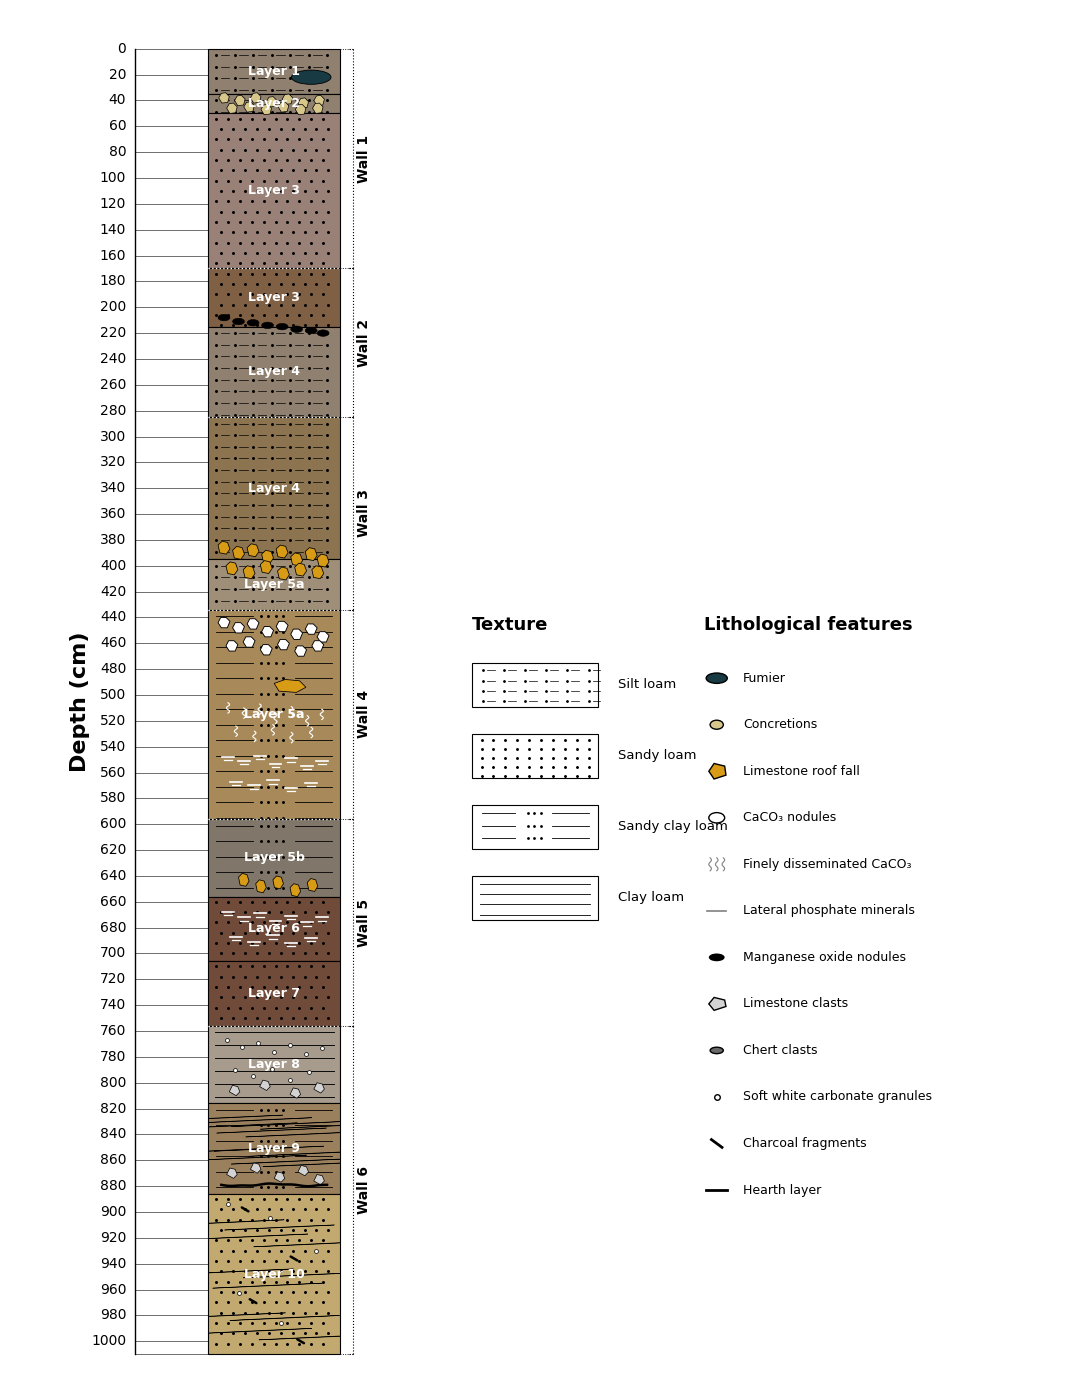

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle, Polygon, Ellipse

# ============================================================
# AZYKH CAVE — COMPOSITE LITHOLOGICAL LOG
# Depth: 0–1010 cm
# All geological symbols clipped INSIDE the log
# ============================================================


# ============================================================
# 1. LAYER DATA
# ============================================================

layers = [
    (0,    35,   "#8F806F", "Silt loam",       "Layer 1"),
    (35,   50,   "#8F806F", "Silt loam",       "Layer 2"),
    (50,   170,  "#9A8178", "Sandy loam",      "Layer 3"),

    (170,  215,  "#806044", "Sandy loam",      "Layer 3"),
    (215,  285,  "#8F806F", "Silt loam",       "Layer 4"),

    (285,  395,  "#8B744F", "Silt loam",       "Layer 4"),
    (395,  434,  "#A08F78", "Silt loam",       "Layer 5a"),

    (434,  596,  "#A88A5A", "Sandy clay loam", "Layer 5a"),

    (596,  656,  "#81766A", "Sandy clay loam", "Layer 5b"),
    (656,  706,  "#704B3A", "Sandy loam",      "Layer 6"),
    (706,  756,  "#704B3A", "Sandy loam",      "Layer 7"),

    (756,  816,  "#A69B8C", "Clay loam",       "Layer 8"),
    (816,  886,  "#9B805D", "Sandy clay loam", "Layer 9"),
    (886, 1010,  "#C1A96F", "Sandy loam",      "Layer 10"),
]


# ============================================================
# 2. WALL DATA
# ============================================================

walls = [
    (0,    170,  "Wall 1"),
    (170,  285,  "Wall 2"),
    (285,  434,  "Wall 3"),
    (434,  596,  "Wall 4"),
    (596,  756,  "Wall 5"),
    (756, 1010,  "Wall 6"),
]


# ============================================================
# 3. FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(11, 14))

x = 0
width = 1.0


# ============================================================
# 4. CLIPPING AREA
#
# Everything geological is constrained to:
# x = 0–1
# y = 0–1010
# ============================================================

clip_box = Rectangle(
    (0, 0),
    1.0,
    1010,
    transform=ax.transData
)


# ============================================================
# 5. TEXTURE FUNCTION
# ============================================================

def draw_texture(ax, left, right, top, bottom, texture):

    if texture == "Silt loam":

        for y in np.arange(top + 5, bottom, 9):

            xpos = left + 0.06

            while xpos < right - 0.05:

                p, = ax.plot(
                    xpos, y,
                    marker=".",
                    markersize=2.3,
                    color="black",
                    zorder=3
                )

                p.set_clip_path(clip_box)

                if xpos + 0.10 < right:

                    p, = ax.plot(
                        [xpos + 0.035, xpos + 0.10],
                        [y, y],
                        color="black",
                        linewidth=0.5,
                        zorder=3
                    )

                    p.set_clip_path(clip_box)

                xpos += 0.14


    elif texture == "Sandy loam":

        row = 0

        for y in np.arange(top + 4, bottom, 8):

            offset = 0.04 if row % 2 else 0

            for xpos in np.arange(
                left + 0.06 + offset,
                right - 0.04,
                0.09
            ):

                p, = ax.plot(
                    xpos, y,
                    marker=".",
                    markersize=2.3,
                    color="black",
                    zorder=3
                )

                p.set_clip_path(clip_box)

            row += 1


    elif texture == "Sandy clay loam":

        for y in np.arange(top + 5, bottom, 12):

            p, = ax.plot(
                [left + 0.06, left + 0.34],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            p.set_clip_path(clip_box)

            for xpos in np.arange(
                left + 0.40,
                left + 0.61,
                0.055
            ):

                p, = ax.plot(
                    xpos, y,
                    marker=".",
                    markersize=2.2,
                    color="black",
                    zorder=3
                )

                p.set_clip_path(clip_box)

            p, = ax.plot(
                [left + 0.66, right - 0.06],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            p.set_clip_path(clip_box)


    elif texture == "Clay loam":

        for y in np.arange(top + 5, bottom, 10):

            p, = ax.plot(
                [left + 0.05, right - 0.05],
                [y, y],
                color="black",
                linewidth=0.65,
                zorder=3
            )

            p.set_clip_path(clip_box)


# ============================================================
# 6. DRAW MAIN LOG
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    rect = Rectangle(
        (x, top),
        width,
        bottom - top,
        facecolor=colour,
        edgecolor="black",
        linewidth=0.8,
        zorder=1
    )

    ax.add_patch(rect)

    draw_texture(
        ax,
        x,
        x + width,
        top,
        bottom,
        texture
    )


# ============================================================
# 7. FEATURE SYMBOL FUNCTIONS
# ============================================================


# ------------------------------------------------------------
# FUMIER
# ------------------------------------------------------------

def fumier_symbol(ax, xc, yc, w=0.30, h=11):

    e = Ellipse(
        (xc, yc),
        width=w,
        height=h,
        facecolor="#173A43",
        edgecolor="black",
        linewidth=0.6,
        zorder=9
    )

    ax.add_patch(e)

    e.set_clip_path(clip_box)


# ------------------------------------------------------------
# CONCRETION
# ------------------------------------------------------------

def concretion_symbol(ax, xc, yc, size=0.04):

    points = [
        (xc - size, yc),
        (xc - size*0.5, yc - 3.5),
        (xc + size*0.3, yc - 4),
        (xc + size, yc - 1),
        (xc + size*0.7, yc + 3.5),
        (xc - size*0.4, yc + 4)
    ]

    p = Polygon(
        points,
        closed=True,
        facecolor="#D8C78B",
        edgecolor="black",
        linewidth=0.5,
        zorder=9
    )

    ax.add_patch(p)

    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# LIMESTONE ROOF FALL
# ------------------------------------------------------------

def limestone_roof_fall(ax, xc, yc, size=0.045):

    points = [
        (xc - size, yc - 2),
        (xc - size*0.3, yc - 5),
        (xc + size*0.6, yc - 4),
        (xc + size, yc + 1),
        (xc + size*0.4, yc + 5),
        (xc - size*0.7, yc + 4)
    ]

    p = Polygon(
        points,
        closed=True,
        facecolor="#D89B16",
        edgecolor="black",
        linewidth=0.55,
        zorder=9
    )

    ax.add_patch(p)

    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# CaCO3 NODULE
# ------------------------------------------------------------

def carbonate_nodule(ax, xc, yc, size=0.045):

    points = [
        (xc - size, yc),
        (xc - size*0.55, yc - 4),
        (xc + size*0.35, yc - 4),
        (xc + size, yc - 1),
        (xc + size*0.55, yc + 4),
        (xc - size*0.45, yc + 4)
    ]

    p = Polygon(
        points,
        closed=True,
        facecolor="white",
        edgecolor="black",
        linewidth=0.65,
        zorder=9
    )

    ax.add_patch(p)

    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# MANGANESE OXIDE NODULE
# ------------------------------------------------------------

def manganese_symbol(ax, xc, yc):

    e = Ellipse(
        (xc, yc),
        width=0.09,
        height=5,
        facecolor="black",
        edgecolor="black",
        linewidth=0.4,
        zorder=9
    )

    ax.add_patch(e)

    e.set_clip_path(clip_box)


# ------------------------------------------------------------
# LATERAL PHOSPHATE
# ------------------------------------------------------------

def phosphate_symbol(ax, xc, yc):

    p, = ax.plot(
        [xc - 0.045, xc + 0.045],
        [yc, yc],
        color="white",
        linewidth=1.2,
        zorder=10
    )

    p.set_clip_path(clip_box)

    p, = ax.plot(
        [xc - 0.030, xc + 0.030],
        [yc + 2.5, yc + 2.5],
        color="white",
        linewidth=0.9,
        zorder=10
    )

    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# DISSEMINATED CaCO3
# ------------------------------------------------------------

def disseminated_caco3(ax, xc, yc):

    yvals = np.linspace(
        yc - 4,
        yc + 4,
        20
    )

    xvals = xc + 0.012 * np.sin(
        np.linspace(0, 3*np.pi, 20)
    )

    p, = ax.plot(
        xvals,
        yvals,
        color="white",
        linewidth=0.8,
        zorder=10
    )

    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# LIMESTONE CLAST
# ------------------------------------------------------------

def limestone_clast(ax, xc, yc, size=0.04):

    points = [
        (xc - size, yc + 1),
        (xc - size*0.4, yc - 4),
        (xc + size*0.6, yc - 3),
        (xc + size, yc + 1),
        (xc + size*0.3, yc + 4)
    ]

    p = Polygon(
        points,
        closed=True,
        facecolor="lightgray",
        edgecolor="black",
        linewidth=0.5,
        zorder=9
    )

    ax.add_patch(p)

    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# CHERT CLAST
#
# Smaller so it stays clearly INSIDE the column
# ------------------------------------------------------------

def chert_clast(ax, xc, yc):

    e = Ellipse(
        (xc, yc),
        width=0.065,
        height=4,
        angle=12,
        facecolor="dimgray",
        edgecolor="black",
        linewidth=0.4,
        zorder=9
    )

    ax.add_patch(e)

    e.set_clip_path(clip_box)


# ------------------------------------------------------------
# CARBONATE GRANULE
# ------------------------------------------------------------

def carbonate_granule(ax, xc, yc):

    p, = ax.plot(
        xc,
        yc,
        marker="o",
        markersize=2.8,
        markerfacecolor="white",
        markeredgecolor="black",
        markeredgewidth=0.5,
        zorder=10
    )

    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# CHARCOAL
# ------------------------------------------------------------

def charcoal_fragment(ax, xc, yc):

    p, = ax.plot(
        [xc - 0.025, xc + 0.025],
        [yc - 1.5, yc + 1.5],
        color="black",
        linewidth=1.8,
        solid_capstyle="round",
        zorder=10
    )

    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# HEARTH
# Kept away from log edges
# ------------------------------------------------------------

def hearth_layer(ax, y):

    xs = np.linspace(
        0.10,
        0.90,
        60
    )

    ys = (
        y
        + 0.8 * np.sin(
            np.linspace(0, 3*np.pi, 60)
        )
        + 0.3 * np.sin(
            np.linspace(0, 8*np.pi, 60)
        )
    )

    p, = ax.plot(
        xs,
        ys,
        color="black",
        linewidth=1.8,
        zorder=11
    )

    p.set_clip_path(clip_box)


# ============================================================
# 8. WALL 1
# ============================================================

fumier_symbol(
    ax,
    0.78,
    22
)


# Concretions
for xpos, ypos in [

    (0.12, 38),
    (0.24, 40),
    (0.36, 38),
    (0.48, 41),
    (0.60, 39),
    (0.72, 42),
    (0.84, 40),

    (0.18, 46),
    (0.31, 45),
    (0.44, 47),
    (0.57, 45),
    (0.70, 47),
    (0.83, 46)

]:

    concretion_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 9. WALL 2
# Mn oxide nodules
# ============================================================

for xpos, ypos in [

    (0.12, 208),
    (0.23, 211),
    (0.34, 212),
    (0.45, 214),
    (0.56, 215),
    (0.67, 217),
    (0.78, 218),
    (0.87, 220)

]:

    manganese_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 10. WALL 3
# Limestone roof fall
# ============================================================

for xpos, ypos in [

    (0.12, 386),
    (0.23, 390),
    (0.34, 388),
    (0.45, 393),
    (0.56, 389),
    (0.67, 395),
    (0.78, 391),
    (0.87, 396),

    (0.18, 402),
    (0.31, 405),
    (0.44, 401),
    (0.57, 406),
    (0.70, 403),
    (0.83, 405)

]:

    limestone_roof_fall(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 11. WALL 4
# ============================================================


# CaCO3 nodules
for xpos, ypos in [

    (0.12, 444),
    (0.23, 448),
    (0.34, 445),
    (0.45, 451),
    (0.56, 447),
    (0.67, 453),
    (0.78, 449),
    (0.87, 455),

    (0.18, 462),
    (0.31, 459),
    (0.44, 465),
    (0.57, 461),
    (0.70, 466),
    (0.83, 462)

]:

    carbonate_nodule(
        ax,
        xpos,
        ypos
    )


# Large roof-fall clast
limestone_roof_fall(
    ax,
    0.62,
    493,
    size=0.12
)


# Disseminated CaCO3
for xpos, ypos in [

    (0.15, 510),
    (0.27, 514),
    (0.39, 511),
    (0.51, 518),
    (0.63, 513),
    (0.75, 520),
    (0.86, 515),

    (0.21, 528),
    (0.35, 532),
    (0.49, 527),
    (0.63, 533),
    (0.78, 529)

]:

    disseminated_caco3(
        ax,
        xpos,
        ypos
    )


# Lateral phosphate
for xpos, ypos in [

    (0.15, 548),
    (0.27, 551),
    (0.39, 547),
    (0.51, 553),
    (0.63, 549),
    (0.75, 555),
    (0.86, 551),

    (0.21, 567),
    (0.35, 570),
    (0.49, 566),
    (0.63, 572),
    (0.78, 568)

]:

    phosphate_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 12. WALL 5
# ============================================================


# Limestone roof fall
for xpos, ypos in [

    (0.27, 643),
    (0.40, 648),
    (0.53, 645),
    (0.66, 651),
    (0.79, 647)

]:

    limestone_roof_fall(
        ax,
        xpos,
        ypos,
        size=0.04
    )


# Lateral phosphate
for xpos, ypos in [

    (0.15, 668),
    (0.27, 672),
    (0.39, 669),
    (0.51, 675),
    (0.63, 671),
    (0.75, 676),
    (0.86, 672),

    (0.21, 687),
    (0.35, 691),
    (0.49, 686),
    (0.63, 692),
    (0.78, 688)

]:

    phosphate_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 13. WALL 6
# ============================================================


# ------------------------------------------------------------
# LAYER 8
# Carbonate granules
# ------------------------------------------------------------

for xpos, ypos in [

    (0.14, 767),
    (0.26, 772),
    (0.38, 769),
    (0.50, 776),
    (0.62, 771),
    (0.74, 778),
    (0.86, 773),

    (0.20, 790),
    (0.34, 795),
    (0.48, 789),
    (0.62, 798),
    (0.76, 792)

]:

    carbonate_granule(
        ax,
        xpos,
        ypos
    )


# Limestone clasts
for xpos, ypos in [

    (0.20, 806),
    (0.43, 802),
    (0.66, 808),
    (0.84, 804)

]:

    limestone_clast(
        ax,
        xpos,
        ypos
    )


# ------------------------------------------------------------
# LAYER 9
# CHERT CLASTS
# All centres safely between x = 0.15 and 0.85
# ------------------------------------------------------------

for xpos, ypos in [

    (0.15, 827),
    (0.26, 833),
    (0.37, 829),
    (0.48, 837),
    (0.59, 832),
    (0.70, 840),
    (0.81, 834),

    (0.20, 852),
    (0.33, 858),
    (0.46, 851),
    (0.59, 861),
    (0.72, 855),
    (0.83, 863)

]:

    chert_clast(
        ax,
        xpos,
        ypos
    )


# Limestone clasts
for xpos, ypos in [

    (0.18, 870),
    (0.36, 866),
    (0.54, 873),
    (0.72, 868),
    (0.84, 875)

]:

    limestone_clast(
        ax,
        xpos,
        ypos
    )


# Hearth horizon
hearth_layer(
    ax,
    879
)


# ------------------------------------------------------------
# LAYER 10
# Chert clasts
# ------------------------------------------------------------

for xpos, ypos in [

    (0.16, 908),
    (0.34, 919),
    (0.54, 912),
    (0.76, 925),

    (0.23, 946),
    (0.45, 957),
    (0.68, 949),

    (0.17, 980),
    (0.37, 992),
    (0.58, 982),
    (0.80, 997)

]:

    chert_clast(
        ax,
        xpos,
        ypos
    )


# Charcoal fragments
for xpos, ypos in [

    (0.28, 898),
    (0.65, 936),
    (0.34, 969),
    (0.70, 1000)

]:

    charcoal_fragment(
        ax,
        xpos,
        ypos
    )


# Carbonate granules
for xpos, ypos in [

    (0.15, 894),
    (0.47, 905),
    (0.82, 930),
    (0.23, 963),
    (0.55, 986)

]:

    carbonate_granule(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 14. LAYER LABELS
# ALL HORIZONTAL
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    midpoint = (top + bottom) / 2

    ax.text(
        0.50,
        midpoint,
        layer_name,
        color="white",
        fontsize=9,
        fontweight="bold",
        ha="center",
        va="center",
        rotation=0,
        zorder=30
    )


# ============================================================
# 15. WALL BRACKETS
# ============================================================

wall_x = 1.10
bracket_width = 0.035


for top, bottom, wall_name in walls:

    midpoint = (top + bottom) / 2

    # Vertical dotted bracket
    ax.plot(
        [wall_x, wall_x],
        [top, bottom],
        color="black",
        linewidth=0.8,
        linestyle=":",
        zorder=15
    )

    # Top arm
    ax.plot(
        [wall_x - bracket_width, wall_x],
        [top, top],
        color="black",
        linewidth=0.8,
        linestyle=":",
        zorder=15
    )

    # Bottom arm
    ax.plot(
        [wall_x - bracket_width, wall_x],
        [bottom, bottom],
        color="black",
        linewidth=0.8,
        linestyle=":",
        zorder=15
    )

    # Vertical wall name
    ax.text(
        wall_x + 0.08,
        midpoint,
        wall_name,
        fontsize=10,
        fontweight="bold",
        rotation=90,
        ha="center",
        va="center",
        color="black",
        zorder=20
    )


# ============================================================
# 16. WALL CONNECTORS
# ============================================================

for depth in [
    0,
    170,
    285,
    434,
    596,
    756,
    1010
]:

    ax.plot(
        [1.0, wall_x],
        [depth, depth],
        color="black",
        linewidth=0.65,
        linestyle=":",
        zorder=14
    )


# ============================================================
# 17. WALL BOUNDARIES INSIDE LOG
# ============================================================

for depth in [
    170,
    285,
    434,
    596,
    756
]:

    ax.plot(
        [0, 1],
        [depth, depth],
        color="white",
        linewidth=1.0,
        linestyle=":",
        zorder=20
    )


# ============================================================
# 18. DEPTH SCALE
# ============================================================

scale_x = -0.55


ax.plot(
    [scale_x, scale_x],
    [0, 1010],
    color="black",
    linewidth=1
)


ax.text(
    scale_x - 0.42,
    505,
    "Depth (cm)",
    rotation=90,
    fontsize=16,
    fontweight="bold",
    ha="center",
    va="center"
)


for depth in range(0, 1001, 20):

    ax.plot(
        [scale_x, 0],
        [depth, depth],
        color="black",
        linewidth=0.4
    )

    ax.text(
        scale_x - 0.07,
        depth,
        str(depth),
        fontsize=10,
        ha="right",
        va="center"
    )


ax.plot(
    [scale_x, 0],
    [1010, 1010],
    color="black",
    linewidth=0.4
)


# ============================================================
# 19. TEXTURE LEGEND
# ============================================================

legend_x = 2.0
legend_y = 475

legend_width = 0.95
legend_height = 34
legend_spacing = 55


ax.text(
    legend_x,
    legend_y - 25,
    "Texture",
    fontsize=13,
    fontweight="bold"
)


legend_items = [
    "Silt loam",
    "Sandy loam",
    "Sandy clay loam",
    "Clay loam"
]


# Important:
# legend patterns are NOT clipped to the main log.

for i, texture in enumerate(legend_items):

    top = legend_y + i * legend_spacing
    bottom = top + legend_height

    box = Rectangle(
        (legend_x, top),
        legend_width,
        legend_height,
        facecolor="white",
        edgecolor="black",
        linewidth=0.8
    )

    ax.add_patch(box)

    # Separate simplified legend patterns
    if texture == "Silt loam":

        for yy in np.arange(top + 6, bottom, 8):

            for xx in np.arange(
                legend_x + 0.08,
                legend_x + legend_width - 0.05,
                0.16
            ):

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=2,
                    color="black"
                )

                ax.plot(
                    [xx + 0.03, xx + 0.09],
                    [yy, yy],
                    color="black",
                    linewidth=0.5
                )


    elif texture == "Sandy loam":

        for yy in np.arange(top + 5, bottom, 7):

            for xx in np.arange(
                legend_x + 0.07,
                legend_x + legend_width - 0.04,
                0.09
            ):

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=2.2,
                    color="black"
                )


    elif texture == "Sandy clay loam":

        for yy in np.arange(top + 6, bottom, 10):

            ax.plot(
                [
                    legend_x + 0.07,
                    legend_x + 0.32
                ],
                [yy, yy],
                color="black",
                linewidth=0.6
            )

            for xx in [
                legend_x + 0.42,
                legend_x + 0.47,
                legend_x + 0.52
            ]:

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=2,
                    color="black"
                )

            ax.plot(
                [
                    legend_x + 0.60,
                    legend_x + 0.88
                ],
                [yy, yy],
                color="black",
                linewidth=0.6
            )


    elif texture == "Clay loam":

        for yy in np.arange(top + 6, bottom, 8):

            ax.plot(
                [
                    legend_x + 0.06,
                    legend_x + legend_width - 0.06
                ],
                [yy, yy],
                color="black",
                linewidth=0.6
            )


    ax.text(
        legend_x + legend_width + 0.15,
        (top + bottom) / 2,
        texture,
        fontsize=9.5,
        va="center"
    )


# ============================================================
# 20. LITHOLOGICAL FEATURES LEGEND
# ============================================================

feature_x = 3.75
feature_y = 475

ax.text(
    feature_x,
    feature_y - 25,
    "Lithological features",
    fontsize=13,
    fontweight="bold"
)


# Manual legend symbols
feature_items = [
    ("Fumier", 12),
    ("Concretions", 48),
    ("Limestone roof fall", 84),
    ("CaCO₃ nodules", 120),
    ("Finely disseminated CaCO₃", 156),
    ("Lateral phosphate minerals", 192),
    ("Manganese oxide nodules", 228),
    ("Limestone clasts", 264),
    ("Chert clasts", 300),
    ("Soft white carbonate granules", 336),
    ("Charcoal fragments", 372),
    ("Hearth layer", 408)
]


for name, offset in feature_items:

    yy = feature_y + offset

    ax.text(
        feature_x + 0.30,
        yy,
        name,
        fontsize=9,
        va="center"
    )


# Fumier legend
e = Ellipse(
    (feature_x + 0.10, feature_y + 12),
    0.16,
    8,
    facecolor="#173A43",
    edgecolor="black"
)
ax.add_patch(e)


# Concretion legend
e = Ellipse(
    (feature_x + 0.10, feature_y + 48),
    0.10,
    7,
    facecolor="#D8C78B",
    edgecolor="black"
)
ax.add_patch(e)


# Roof fall legend
p = Polygon(
    [
        (feature_x + 0.04, feature_y + 84),
        (feature_x + 0.08, feature_y + 78),
        (feature_x + 0.16, feature_y + 80),
        (feature_x + 0.17, feature_y + 87),
        (feature_x + 0.08, feature_y + 90)
    ],
    closed=True,
    facecolor="#D89B16",
    edgecolor="black"
)
ax.add_patch(p)


# CaCO3 nodule legend
e = Ellipse(
    (feature_x + 0.10, feature_y + 120),
    0.12,
    8,
    facecolor="white",
    edgecolor="black"
)
ax.add_patch(e)


# Disseminated CaCO3 legend
for dx in [0.05, 0.10, 0.15]:

    yy = np.linspace(
        feature_y + 151,
        feature_y + 161,
        20
    )

    xx = (
        feature_x
        + dx
        + 0.01 * np.sin(
            np.linspace(0, 3*np.pi, 20)
        )
    )

    ax.plot(
        xx,
        yy,
        color="gray",
        linewidth=0.8
    )


# Phosphate legend
ax.plot(
    [
        feature_x + 0.03,
        feature_x + 0.17
    ],
    [
        feature_y + 192,
        feature_y + 192
    ],
    color="gray",
    linewidth=1.2
)


# Mn legend
e = Ellipse(
    (feature_x + 0.10, feature_y + 228),
    0.12,
    6,
    facecolor="black"
)
ax.add_patch(e)


# Limestone clast legend
p = Polygon(
    [
        (feature_x + 0.04, feature_y + 264),
        (feature_x + 0.08, feature_y + 259),
        (feature_x + 0.16, feature_y + 261),
        (feature_x + 0.17, feature_y + 266),
        (feature_x + 0.08, feature_y + 269)
    ],
    closed=True,
    facecolor="lightgray",
    edgecolor="black"
)
ax.add_patch(p)


# Chert legend
e = Ellipse(
    (feature_x + 0.10, feature_y + 300),
    0.10,
    5,
    facecolor="dimgray",
    edgecolor="black"
)
ax.add_patch(e)


# Carbonate granule legend
ax.plot(
    feature_x + 0.10,
    feature_y + 336,
    marker="o",
    markersize=4,
    markerfacecolor="white",
    markeredgecolor="black"
)


# Charcoal legend
ax.plot(
    [
        feature_x + 0.06,
        feature_x + 0.14
    ],
    [
        feature_y + 369,
        feature_y + 375
    ],
    color="black",
    linewidth=2
)


# Hearth legend
ax.plot(
    [
        feature_x + 0.02,
        feature_x + 0.18
    ],
    [
        feature_y + 408,
        feature_y + 408
    ],
    color="black",
    linewidth=2
)


# ============================================================
# 21. FINAL FORMAT
# ============================================================

ax.set_xlim(
    -1.5,
    6.6
)

ax.set_ylim(
    1030,
    -30
)

ax.axis("off")

plt.tight_layout()


# ============================================================
# 22. SAVE
# ============================================================

plt.savefig(
    "Azykh_log_all_features_inside.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Azykh_log_all_features_inside.pdf",
    bbox_inches="tight"
)

plt.show()

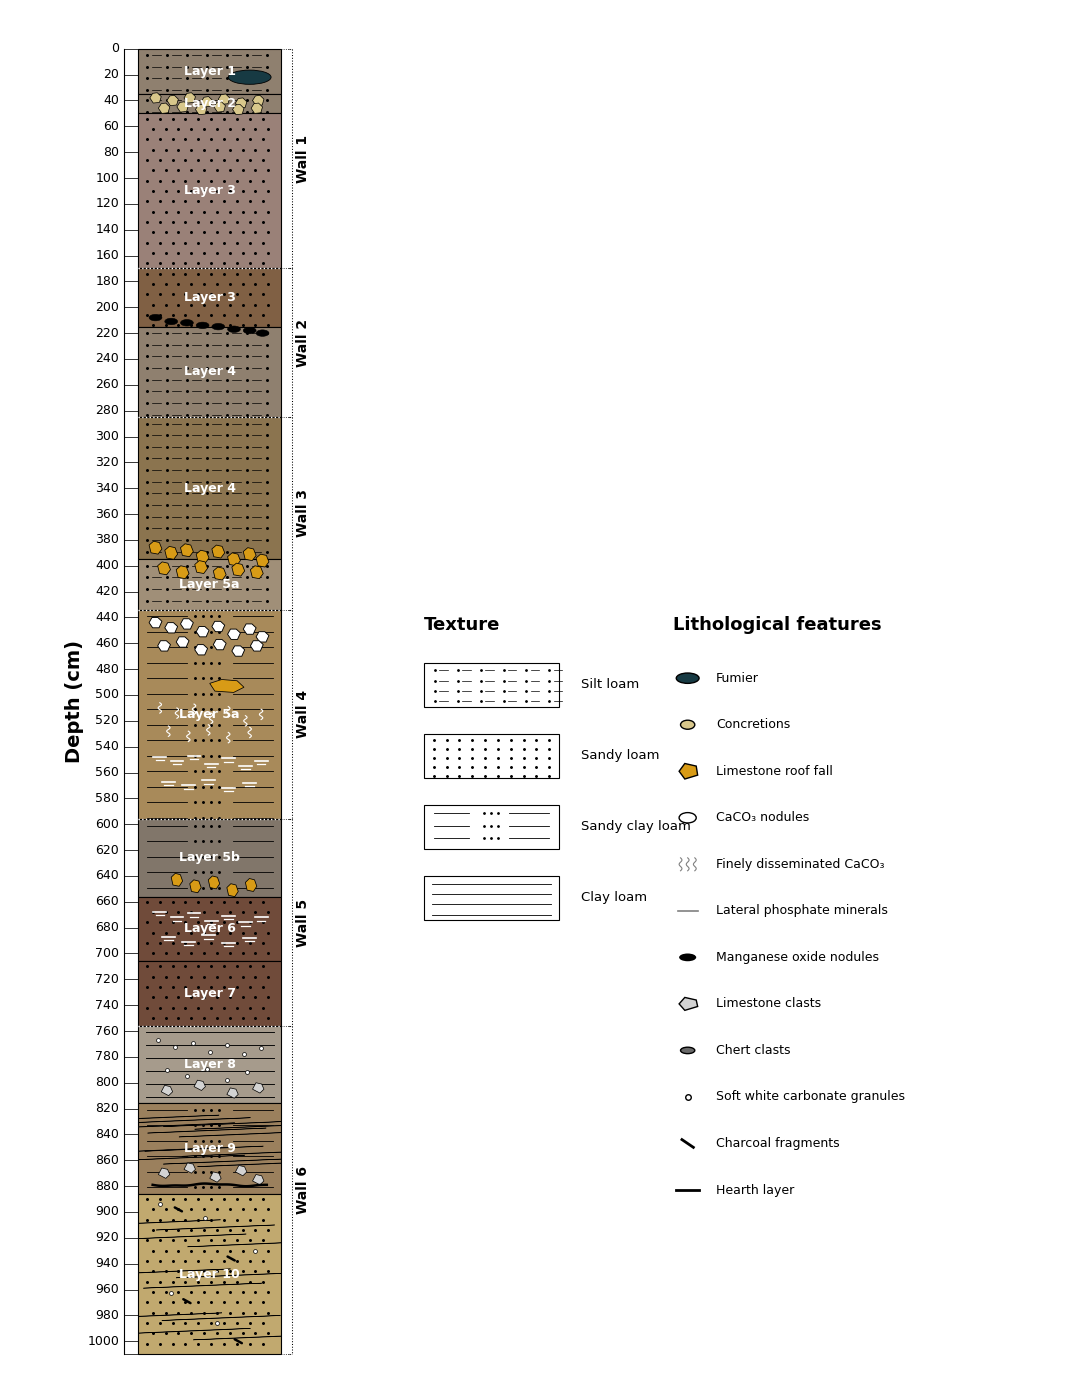

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle, Polygon, Ellipse

# ============================================================
# AZYKH CAVE — COMPOSITE LITHOLOGICAL LOG
# Depth: 0–1010 cm
# ============================================================


# ============================================================
# 1. LAYER DATA
# ============================================================

layers = [
    (0,    35,   "#8F806F", "Silt loam",       "Layer 1"),
    (35,   50,   "#8F806F", "Silt loam",       "Layer 2"),
    (50,   170,  "#9A8178", "Sandy loam",      "Layer 3"),

    (170,  215,  "#806044", "Sandy loam",      "Layer 3"),
    (215,  285,  "#8F806F", "Silt loam",       "Layer 4"),

    (285,  395,  "#8B744F", "Silt loam",       "Layer 4"),
    (395,  434,  "#A08F78", "Silt loam",       "Layer 5a"),

    (434,  596,  "#A88A5A", "Sandy clay loam", "Layer 5a"),

    (596,  656,  "#81766A", "Sandy clay loam", "Layer 5b"),
    (656,  706,  "#704B3A", "Sandy loam",      "Layer 6"),
    (706,  756,  "#704B3A", "Sandy loam",      "Layer 7"),

    (756,  816,  "#A69B8C", "Clay loam",       "Layer 8"),
    (816,  886,  "#9B805D", "Sandy clay loam", "Layer 9"),
    (886, 1010,  "#C1A96F", "Sandy loam",      "Layer 10"),
]


# ============================================================
# 2. WALL DATA
# ============================================================

walls = [
    (0,    170,  "Wall 1"),
    (170,  285,  "Wall 2"),
    (285,  434,  "Wall 3"),
    (434,  596,  "Wall 4"),
    (596,  756,  "Wall 5"),
    (756, 1010,  "Wall 6"),
]


# ============================================================
# 3. FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(11, 14))

x = 0
width = 1.0


# ============================================================
# 4. CLIPPING AREA
# Keeps all lithological features INSIDE the log
# ============================================================

clip_box = Rectangle(
    (0, 0),
    1.0,
    1010,
    transform=ax.transData
)


# ============================================================
# 5. TEXTURE PATTERNS
# ============================================================

def draw_texture(ax, left, right, top, bottom, texture):

    # SILT LOAM
    # . - . - . -
    if texture == "Silt loam":

        for y in np.arange(top + 5, bottom, 9):

            xpos = left + 0.06

            while xpos < right - 0.05:

                p, = ax.plot(
                    xpos, y,
                    marker=".",
                    markersize=2.3,
                    color="black",
                    zorder=3
                )

                p.set_clip_path(clip_box)

                if xpos + 0.10 < right:

                    p, = ax.plot(
                        [xpos + 0.035, xpos + 0.10],
                        [y, y],
                        color="black",
                        linewidth=0.5,
                        zorder=3
                    )

                    p.set_clip_path(clip_box)

                xpos += 0.14


    # SANDY LOAM
    # dots
    elif texture == "Sandy loam":

        row = 0

        for y in np.arange(top + 4, bottom, 8):

            offset = 0.04 if row % 2 else 0

            for xpos in np.arange(
                left + 0.06 + offset,
                right - 0.04,
                0.09
            ):

                p, = ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.3,
                    color="black",
                    zorder=3
                )

                p.set_clip_path(clip_box)

            row += 1


    # SANDY CLAY LOAM
    # lines + dots + lines
    elif texture == "Sandy clay loam":

        for y in np.arange(top + 5, bottom, 12):

            p, = ax.plot(
                [left + 0.06, left + 0.34],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            p.set_clip_path(clip_box)

            for xpos in np.arange(
                left + 0.40,
                left + 0.61,
                0.055
            ):

                p, = ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.2,
                    color="black",
                    zorder=3
                )

                p.set_clip_path(clip_box)

            p, = ax.plot(
                [left + 0.66, right - 0.06],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            p.set_clip_path(clip_box)


    # CLAY LOAM
    # horizontal lines
    elif texture == "Clay loam":

        for y in np.arange(top + 5, bottom, 10):

            p, = ax.plot(
                [left + 0.05, right - 0.05],
                [y, y],
                color="black",
                linewidth=0.65,
                zorder=3
            )

            p.set_clip_path(clip_box)


# ============================================================
# 6. DRAW MAIN LOG
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    rect = Rectangle(
        (x, top),
        width,
        bottom - top,
        facecolor=colour,
        edgecolor="black",
        linewidth=0.8,
        zorder=1
    )

    ax.add_patch(rect)

    draw_texture(
        ax,
        x,
        x + width,
        top,
        bottom,
        texture
    )


# ============================================================
# 7. FEATURE SYMBOL FUNCTIONS
# ============================================================


# ------------------------------------------------------------
# FUMIER
# ------------------------------------------------------------

def fumier_symbol(ax, xc, yc, w=0.30, h=11):

    e = Ellipse(
        (xc, yc),
        width=w,
        height=h,
        facecolor="#173A43",
        edgecolor="black",
        linewidth=0.6,
        zorder=9
    )

    ax.add_patch(e)
    e.set_clip_path(clip_box)


# ------------------------------------------------------------
# CONCRETION
# ------------------------------------------------------------

def concretion_symbol(ax, xc, yc, size=0.04):

    points = [
        (xc - size, yc),
        (xc - size*0.5, yc - 3.5),
        (xc + size*0.3, yc - 4),
        (xc + size, yc - 1),
        (xc + size*0.7, yc + 3.5),
        (xc - size*0.4, yc + 4)
    ]

    p = Polygon(
        points,
        closed=True,
        facecolor="#D8C78B",
        edgecolor="black",
        linewidth=0.5,
        zorder=9
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# LIMESTONE ROOF FALL
# ------------------------------------------------------------

def limestone_roof_fall(ax, xc, yc, size=0.045):

    points = [
        (xc - size, yc - 2),
        (xc - size*0.3, yc - 5),
        (xc + size*0.6, yc - 4),
        (xc + size, yc + 1),
        (xc + size*0.4, yc + 5),
        (xc - size*0.7, yc + 4)
    ]

    p = Polygon(
        points,
        closed=True,
        facecolor="#D89B16",
        edgecolor="black",
        linewidth=0.55,
        zorder=9
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# CaCO3 NODULE
# ------------------------------------------------------------

def carbonate_nodule(ax, xc, yc, size=0.045):

    points = [
        (xc - size, yc),
        (xc - size*0.55, yc - 4),
        (xc + size*0.35, yc - 4),
        (xc + size, yc - 1),
        (xc + size*0.55, yc + 4),
        (xc - size*0.45, yc + 4)
    ]

    p = Polygon(
        points,
        closed=True,
        facecolor="white",
        edgecolor="black",
        linewidth=0.65,
        zorder=9
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# MANGANESE OXIDE NODULE
# ------------------------------------------------------------

def manganese_symbol(ax, xc, yc):

    e = Ellipse(
        (xc, yc),
        width=0.09,
        height=5,
        facecolor="black",
        edgecolor="black",
        linewidth=0.4,
        zorder=9
    )

    ax.add_patch(e)
    e.set_clip_path(clip_box)


# ------------------------------------------------------------
# LATERAL PHOSPHATE
# ------------------------------------------------------------

def phosphate_symbol(ax, xc, yc):

    p, = ax.plot(
        [xc - 0.045, xc + 0.045],
        [yc, yc],
        color="white",
        linewidth=1.2,
        zorder=10
    )

    p.set_clip_path(clip_box)

    p, = ax.plot(
        [xc - 0.030, xc + 0.030],
        [yc + 2.5, yc + 2.5],
        color="white",
        linewidth=0.9,
        zorder=10
    )

    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# FINELY DISSEMINATED CaCO3
# ------------------------------------------------------------

def disseminated_caco3(ax, xc, yc):

    yvals = np.linspace(
        yc - 4,
        yc + 4,
        20
    )

    xvals = xc + 0.012 * np.sin(
        np.linspace(0, 3*np.pi, 20)
    )

    p, = ax.plot(
        xvals,
        yvals,
        color="white",
        linewidth=0.8,
        zorder=10
    )

    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# LIMESTONE CLAST
# ------------------------------------------------------------

def limestone_clast(ax, xc, yc, size=0.04):

    points = [
        (xc - size, yc + 1),
        (xc - size*0.4, yc - 4),
        (xc + size*0.6, yc - 3),
        (xc + size, yc + 1),
        (xc + size*0.3, yc + 4)
    ]

    p = Polygon(
        points,
        closed=True,
        facecolor="lightgray",
        edgecolor="black",
        linewidth=0.5,
        zorder=9
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# CHERT CLAST
# ------------------------------------------------------------

def chert_clast(ax, xc, yc):

    e = Ellipse(
        (xc, yc),
        width=0.065,
        height=4,
        angle=12,
        facecolor="dimgray",
        edgecolor="black",
        linewidth=0.4,
        zorder=9
    )

    ax.add_patch(e)
    e.set_clip_path(clip_box)


# ------------------------------------------------------------
# SOFT WHITE CARBONATE GRANULE
# ------------------------------------------------------------

def carbonate_granule(ax, xc, yc):

    p, = ax.plot(
        xc,
        yc,
        marker="o",
        markersize=2.8,
        markerfacecolor="white",
        markeredgecolor="black",
        markeredgewidth=0.5,
        zorder=10
    )

    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# CHARCOAL FRAGMENT
# ------------------------------------------------------------

def charcoal_fragment(ax, xc, yc):

    p, = ax.plot(
        [xc - 0.025, xc + 0.025],
        [yc - 1.5, yc + 1.5],
        color="black",
        linewidth=1.8,
        solid_capstyle="round",
        zorder=10
    )

    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# HEARTH LAYER
# ------------------------------------------------------------

def hearth_layer(ax, y):

    xs = np.linspace(
        0.10,
        0.90,
        60
    )

    ys = (
        y
        + 0.8 * np.sin(np.linspace(0, 3*np.pi, 60))
        + 0.3 * np.sin(np.linspace(0, 8*np.pi, 60))
    )

    p, = ax.plot(
        xs,
        ys,
        color="black",
        linewidth=1.8,
        zorder=11
    )

    p.set_clip_path(clip_box)


# ============================================================
# 8. WALL 1 FEATURES
# ============================================================

# Fumier
fumier_symbol(
    ax,
    0.78,
    22
)


# Concretions
for xpos, ypos in [

    (0.12, 38),
    (0.24, 40),
    (0.36, 38),
    (0.48, 41),
    (0.60, 39),
    (0.72, 42),
    (0.84, 40),

    (0.18, 46),
    (0.31, 45),
    (0.44, 47),
    (0.57, 45),
    (0.70, 47),
    (0.83, 46)

]:

    concretion_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 9. WALL 2 FEATURES
# Mn oxide nodules
# ============================================================

for xpos, ypos in [

    (0.12, 208),
    (0.23, 211),
    (0.34, 212),
    (0.45, 214),
    (0.56, 215),
    (0.67, 217),
    (0.78, 218),
    (0.87, 220)

]:

    manganese_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 10. WALL 3 FEATURES
# Limestone roof fall
# ============================================================

for xpos, ypos in [

    (0.12, 386),
    (0.23, 390),
    (0.34, 388),
    (0.45, 393),
    (0.56, 389),
    (0.67, 395),
    (0.78, 391),
    (0.87, 396),

    (0.18, 402),
    (0.31, 405),
    (0.44, 401),
    (0.57, 406),
    (0.70, 403),
    (0.83, 405)

]:

    limestone_roof_fall(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 11. WALL 4 FEATURES
# ============================================================

# CaCO3 nodules
for xpos, ypos in [

    (0.12, 444),
    (0.23, 448),
    (0.34, 445),
    (0.45, 451),
    (0.56, 447),
    (0.67, 453),
    (0.78, 449),
    (0.87, 455),

    (0.18, 462),
    (0.31, 459),
    (0.44, 465),
    (0.57, 461),
    (0.70, 466),
    (0.83, 462)

]:

    carbonate_nodule(
        ax,
        xpos,
        ypos
    )


# Large limestone roof-fall clast
limestone_roof_fall(
    ax,
    0.62,
    493,
    size=0.12
)


# Finely disseminated CaCO3
for xpos, ypos in [

    (0.15, 510),
    (0.27, 514),
    (0.39, 511),
    (0.51, 518),
    (0.63, 513),
    (0.75, 520),
    (0.86, 515),

    (0.21, 528),
    (0.35, 532),
    (0.49, 527),
    (0.63, 533),
    (0.78, 529)

]:

    disseminated_caco3(
        ax,
        xpos,
        ypos
    )


# Lateral phosphate minerals
for xpos, ypos in [

    (0.15, 548),
    (0.27, 551),
    (0.39, 547),
    (0.51, 553),
    (0.63, 549),
    (0.75, 555),
    (0.86, 551),

    (0.21, 567),
    (0.35, 570),
    (0.49, 566),
    (0.63, 572),
    (0.78, 568)

]:

    phosphate_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 12. WALL 5 FEATURES
# ============================================================

# Limestone roof fall
for xpos, ypos in [

    (0.27, 643),
    (0.40, 648),
    (0.53, 645),
    (0.66, 651),
    (0.79, 647)

]:

    limestone_roof_fall(
        ax,
        xpos,
        ypos,
        size=0.04
    )


# Lateral phosphate
for xpos, ypos in [

    (0.15, 668),
    (0.27, 672),
    (0.39, 669),
    (0.51, 675),
    (0.63, 671),
    (0.75, 676),
    (0.86, 672),

    (0.21, 687),
    (0.35, 691),
    (0.49, 686),
    (0.63, 692),
    (0.78, 688)

]:

    phosphate_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 13. WALL 6 FEATURES
# ============================================================


# ------------------------------------------------------------
# LAYER 8 — carbonate granules
# ------------------------------------------------------------

for xpos, ypos in [

    (0.14, 767),
    (0.26, 772),
    (0.38, 769),
    (0.50, 776),
    (0.62, 771),
    (0.74, 778),
    (0.86, 773),

    (0.20, 790),
    (0.34, 795),
    (0.48, 789),
    (0.62, 798),
    (0.76, 792)

]:

    carbonate_granule(
        ax,
        xpos,
        ypos
    )


# Limestone clasts
for xpos, ypos in [

    (0.20, 806),
    (0.43, 802),
    (0.66, 808),
    (0.84, 804)

]:

    limestone_clast(
        ax,
        xpos,
        ypos
    )


# ------------------------------------------------------------
# LAYER 9 — chert clasts
# ------------------------------------------------------------

for xpos, ypos in [

    (0.15, 827),
    (0.26, 833),
    (0.37, 829),
    (0.48, 837),
    (0.59, 832),
    (0.70, 840),
    (0.81, 834),

    (0.20, 852),
    (0.33, 858),
    (0.46, 851),
    (0.59, 861),
    (0.72, 855),
    (0.83, 863)

]:

    chert_clast(
        ax,
        xpos,
        ypos
    )


# Limestone clasts
for xpos, ypos in [

    (0.18, 870),
    (0.36, 866),
    (0.54, 873),
    (0.72, 868),
    (0.84, 875)

]:

    limestone_clast(
        ax,
        xpos,
        ypos
    )


# Hearth horizon
hearth_layer(
    ax,
    879
)


# ------------------------------------------------------------
# LAYER 10 — chert clasts
# ------------------------------------------------------------

for xpos, ypos in [

    (0.16, 908),
    (0.34, 919),
    (0.54, 912),
    (0.76, 925),

    (0.23, 946),
    (0.45, 957),
    (0.68, 949),

    (0.17, 980),
    (0.37, 992),
    (0.58, 982),
    (0.80, 997)

]:

    chert_clast(
        ax,
        xpos,
        ypos
    )


# Charcoal fragments
for xpos, ypos in [

    (0.28, 898),
    (0.65, 936),
    (0.34, 969),
    (0.70, 1000)

]:

    charcoal_fragment(
        ax,
        xpos,
        ypos
    )


# Carbonate granules
for xpos, ypos in [

    (0.15, 894),
    (0.47, 905),
    (0.82, 930),
    (0.23, 963),
    (0.55, 986)

]:

    carbonate_granule(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 14. LAYER LABELS
# ALL HORIZONTAL
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    midpoint = (top + bottom) / 2

    ax.text(
        0.50,
        midpoint,
        layer_name,
        color="white",
        fontsize=9,
        fontweight="bold",
        ha="center",
        va="center",
        rotation=0,
        zorder=30
    )


# ============================================================
# 15. WALL BRACKETS
# SMALL + DOTTED + OUTSIDE LOG
# ============================================================

wall_x = 1.08
bracket_width = 0.025


for top, bottom, wall_name in walls:

    midpoint = (top + bottom) / 2

    # Vertical dotted bracket
    ax.plot(
        [wall_x, wall_x],
        [top, bottom],
        color="black",
        linewidth=0.75,
        linestyle=":",
        zorder=15
    )

    # Top arm
    ax.plot(
        [wall_x - bracket_width, wall_x],
        [top, top],
        color="black",
        linewidth=0.75,
        linestyle=":",
        zorder=15
    )

    # Bottom arm
    ax.plot(
        [wall_x - bracket_width, wall_x],
        [bottom, bottom],
        color="black",
        linewidth=0.75,
        linestyle=":",
        zorder=15
    )

    # Wall name
    ax.text(
        wall_x + 0.075,
        midpoint,
        wall_name,
        fontsize=10,
        fontweight="bold",
        rotation=90,
        ha="center",
        va="center",
        color="black",
        zorder=20
    )


# ============================================================
# 16. WALL CONNECTORS
# ============================================================

for depth in [
    0,
    170,
    285,
    434,
    596,
    756,
    1010
]:

    ax.plot(
        [1.0, wall_x],
        [depth, depth],
        color="black",
        linewidth=0.6,
        linestyle=":",
        zorder=14
    )


# ============================================================
# 17. WALL BOUNDARIES INSIDE LOG
# ============================================================

for depth in [
    170,
    285,
    434,
    596,
    756
]:

    ax.plot(
        [0, 1],
        [depth, depth],
        color="white",
        linewidth=1.0,
        linestyle=":",
        zorder=20
    )


# ============================================================
# 18. DEPTH SCALE
# COMPACT — VERY CLOSE TO LOG
# ============================================================

# Log starts at x = 0.
# Scale is placed immediately outside the log.
scale_x = -0.10


# Vertical scale line
ax.plot(
    [scale_x, scale_x],
    [0, 1010],
    color="black",
    linewidth=0.8,
    zorder=20
)


# ------------------------------------------------------------
# TICKS + NUMBERS
# 0, 20, 40 ... 1000
# ------------------------------------------------------------

for depth in range(0, 1001, 20):

    # Short tick/spike toward the log
    ax.plot(
        [scale_x, 0],
        [depth, depth],
        color="black",
        linewidth=0.55,
        zorder=20
    )

    # Number outside scale
    ax.text(
        scale_x - 0.035,
        depth,
        str(depth),
        fontsize=9,
        ha="right",
        va="center"
    )


# Bottom boundary = 1010 cm
# No 1010 number
ax.plot(
    [scale_x, 0],
    [1010, 1010],
    color="black",
    linewidth=0.55,
    zorder=20
)


# Depth title
ax.text(
    scale_x - 0.35,
    505,
    "Depth (cm)",
    rotation=90,
    fontsize=14,
    fontweight="bold",
    ha="center",
    va="center"
)


# ============================================================
# 19. TEXTURE LEGEND
# ============================================================

legend_x = 2.0
legend_y = 475

legend_width = 0.95
legend_height = 34
legend_spacing = 55


ax.text(
    legend_x,
    legend_y - 25,
    "Texture",
    fontsize=13,
    fontweight="bold"
)


legend_items = [
    "Silt loam",
    "Sandy loam",
    "Sandy clay loam",
    "Clay loam"
]


for i, texture in enumerate(legend_items):

    top = legend_y + i * legend_spacing
    bottom = top + legend_height

    box = Rectangle(
        (legend_x, top),
        legend_width,
        legend_height,
        facecolor="white",
        edgecolor="black",
        linewidth=0.8
    )

    ax.add_patch(box)


    # SILT LOAM LEGEND
    if texture == "Silt loam":

        for yy in np.arange(top + 6, bottom, 8):

            for xx in np.arange(
                legend_x + 0.08,
                legend_x + legend_width - 0.05,
                0.16
            ):

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=2,
                    color="black"
                )

                ax.plot(
                    [xx + 0.03, xx + 0.09],
                    [yy, yy],
                    color="black",
                    linewidth=0.5
                )


    # SANDY LOAM LEGEND
    elif texture == "Sandy loam":

        for yy in np.arange(top + 5, bottom, 7):

            for xx in np.arange(
                legend_x + 0.07,
                legend_x + legend_width - 0.04,
                0.09
            ):

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=2.2,
                    color="black"
                )


    # SANDY CLAY LOAM LEGEND
    elif texture == "Sandy clay loam":

        for yy in np.arange(top + 6, bottom, 10):

            ax.plot(
                [
                    legend_x + 0.07,
                    legend_x + 0.32
                ],
                [yy, yy],
                color="black",
                linewidth=0.6
            )

            for xx in [
                legend_x + 0.42,
                legend_x + 0.47,
                legend_x + 0.52
            ]:

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=2,
                    color="black"
                )

            ax.plot(
                [
                    legend_x + 0.60,
                    legend_x + 0.88
                ],
                [yy, yy],
                color="black",
                linewidth=0.6
            )


    # CLAY LOAM LEGEND
    elif texture == "Clay loam":

        for yy in np.arange(top + 6, bottom, 8):

            ax.plot(
                [
                    legend_x + 0.06,
                    legend_x + legend_width - 0.06
                ],
                [yy, yy],
                color="black",
                linewidth=0.6
            )


    ax.text(
        legend_x + legend_width + 0.15,
        (top + bottom) / 2,
        texture,
        fontsize=9.5,
        va="center"
    )


# ============================================================
# 20. LITHOLOGICAL FEATURES LEGEND
# ============================================================

feature_x = 3.75
feature_y = 475


ax.text(
    feature_x,
    feature_y - 25,
    "Lithological features",
    fontsize=13,
    fontweight="bold"
)


feature_items = [
    ("Fumier", 12),
    ("Concretions", 48),
    ("Limestone roof fall", 84),
    ("CaCO₃ nodules", 120),
    ("Finely disseminated CaCO₃", 156),
    ("Lateral phosphate minerals", 192),
    ("Manganese oxide nodules", 228),
    ("Limestone clasts", 264),
    ("Chert clasts", 300),
    ("Soft white carbonate granules", 336),
    ("Charcoal fragments", 372),
    ("Hearth layer", 408)
]


for name, offset in feature_items:

    yy = feature_y + offset

    ax.text(
        feature_x + 0.30,
        yy,
        name,
        fontsize=9,
        va="center"
    )


# ------------------------------------------------------------
# Fumier legend
# ------------------------------------------------------------

e = Ellipse(
    (feature_x + 0.10, feature_y + 12),
    0.16,
    8,
    facecolor="#173A43",
    edgecolor="black"
)

ax.add_patch(e)


# ------------------------------------------------------------
# Concretion legend
# ------------------------------------------------------------

e = Ellipse(
    (feature_x + 0.10, feature_y + 48),
    0.10,
    7,
    facecolor="#D8C78B",
    edgecolor="black"
)

ax.add_patch(e)


# ------------------------------------------------------------
# Limestone roof fall legend
# ------------------------------------------------------------

p = Polygon(
    [
        (feature_x + 0.04, feature_y + 84),
        (feature_x + 0.08, feature_y + 78),
        (feature_x + 0.16, feature_y + 80),
        (feature_x + 0.17, feature_y + 87),
        (feature_x + 0.08, feature_y + 90)
    ],
    closed=True,
    facecolor="#D89B16",
    edgecolor="black"
)

ax.add_patch(p)


# ------------------------------------------------------------
# CaCO3 nodule legend
# ------------------------------------------------------------

e = Ellipse(
    (feature_x + 0.10, feature_y + 120),
    0.12,
    8,
    facecolor="white",
    edgecolor="black"
)

ax.add_patch(e)


# ------------------------------------------------------------
# Finely disseminated CaCO3 legend
# ------------------------------------------------------------

for dx in [0.05, 0.10, 0.15]:

    yy = np.linspace(
        feature_y + 151,
        feature_y + 161,
        20
    )

    xx = (
        feature_x
        + dx
        + 0.01 * np.sin(
            np.linspace(0, 3*np.pi, 20)
        )
    )

    ax.plot(
        xx,
        yy,
        color="gray",
        linewidth=0.8
    )


# ------------------------------------------------------------
# Lateral phosphate legend
# ------------------------------------------------------------

ax.plot(
    [
        feature_x + 0.03,
        feature_x + 0.17
    ],
    [
        feature_y + 192,
        feature_y + 192
    ],
    color="gray",
    linewidth=1.2
)


# ------------------------------------------------------------
# Mn oxide legend
# ------------------------------------------------------------

e = Ellipse(
    (feature_x + 0.10, feature_y + 228),
    0.12,
    6,
    facecolor="black"
)

ax.add_patch(e)


# ------------------------------------------------------------
# Limestone clast legend
# ------------------------------------------------------------

p = Polygon(
    [
        (feature_x + 0.04, feature_y + 264),
        (feature_x + 0.08, feature_y + 259),
        (feature_x + 0.16, feature_y + 261),
        (feature_x + 0.17, feature_y + 266),
        (feature_x + 0.08, feature_y + 269)
    ],
    closed=True,
    facecolor="lightgray",
    edgecolor="black"
)

ax.add_patch(p)


# ------------------------------------------------------------
# Chert clast legend
# ------------------------------------------------------------

e = Ellipse(
    (feature_x + 0.10, feature_y + 300),
    0.10,
    5,
    facecolor="dimgray",
    edgecolor="black"
)

ax.add_patch(e)


# ------------------------------------------------------------
# Carbonate granule legend
# ------------------------------------------------------------

ax.plot(
    feature_x + 0.10,
    feature_y + 336,
    marker="o",
    markersize=4,
    markerfacecolor="white",
    markeredgecolor="black"
)


# ------------------------------------------------------------
# Charcoal legend
# ------------------------------------------------------------

ax.plot(
    [
        feature_x + 0.06,
        feature_x + 0.14
    ],
    [
        feature_y + 369,
        feature_y + 375
    ],
    color="black",
    linewidth=2
)


# ------------------------------------------------------------
# Hearth legend
# ------------------------------------------------------------

ax.plot(
    [
        feature_x + 0.02,
        feature_x + 0.18
    ],
    [
        feature_y + 408,
        feature_y + 408
    ],
    color="black",
    linewidth=2
)


# ============================================================
# 21. FINAL FORMATTING
# ============================================================

ax.set_xlim(
    -0.90,
    6.60
)

ax.set_ylim(
    1030,
    -30
)

ax.axis("off")

plt.tight_layout()


# ============================================================
# 22. SAVE
# ============================================================

plt.savefig(
    "Azykh_complete_log_compact_depth_scale.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Azykh_complete_log_compact_depth_scale.pdf",
    bbox_inches="tight"
)


# ============================================================
# 23. SHOW
# ============================================================

plt.show()

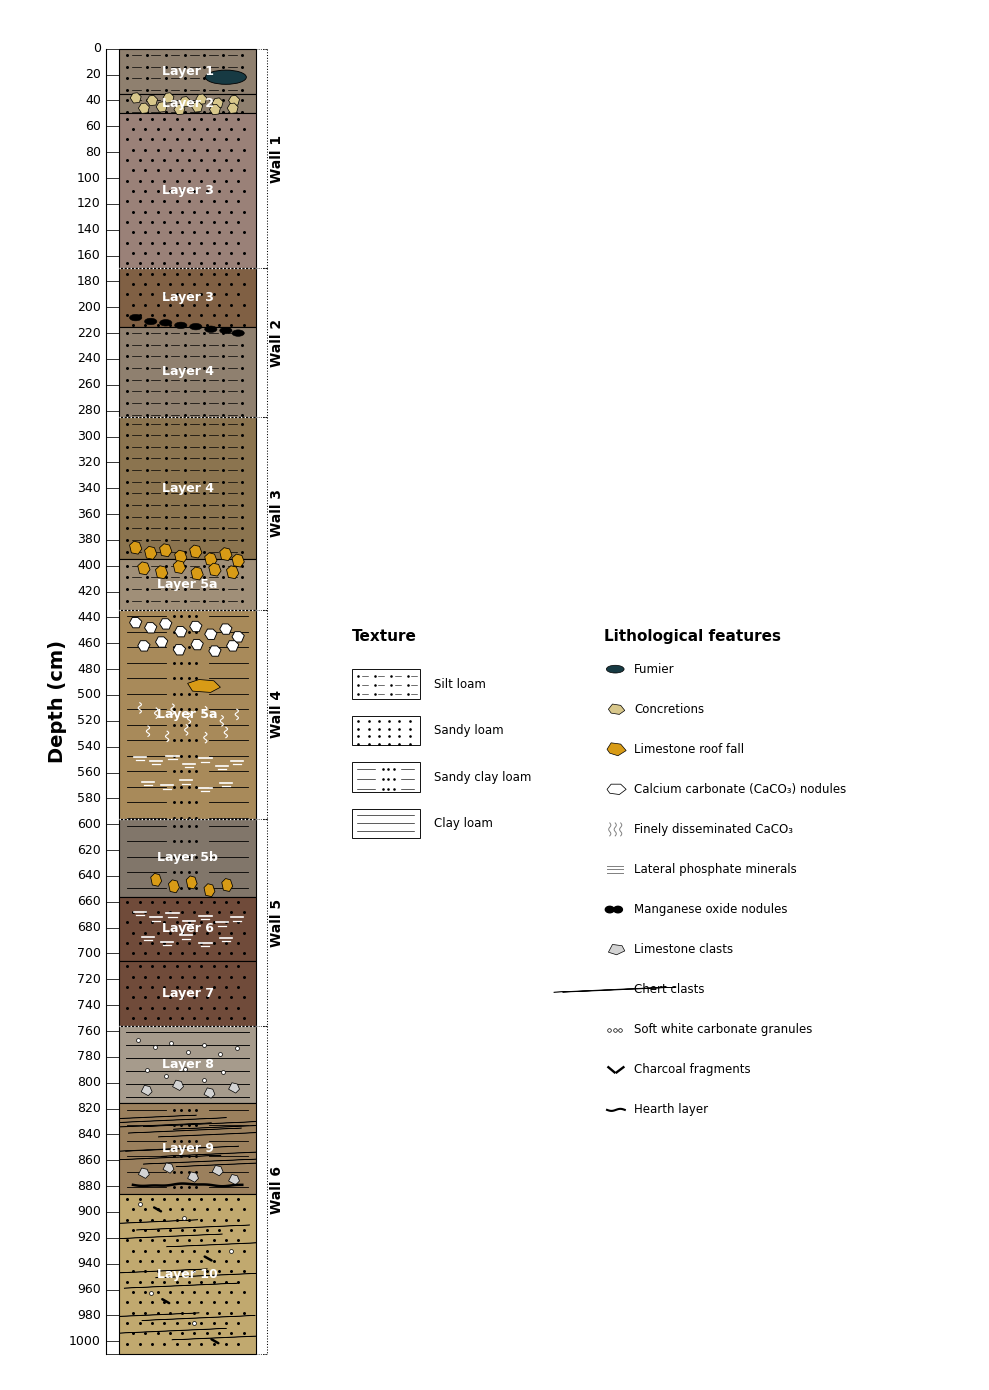

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle, Polygon, Ellipse


# ============================================================
# AZYKH CAVE — COMPOSITE LITHOLOGICAL LOG
# Depth: 0–1010 cm
# ============================================================


# ============================================================
# 1. LAYER DATA
# ============================================================

layers = [
    (0,    35,   "#8F806F", "Silt loam",       "Layer 1"),
    (35,   50,   "#8F806F", "Silt loam",       "Layer 2"),
    (50,   170,  "#9A8178", "Sandy loam",      "Layer 3"),

    (170,  215,  "#806044", "Sandy loam",      "Layer 3"),
    (215,  285,  "#8F806F", "Silt loam",       "Layer 4"),

    (285,  395,  "#8B744F", "Silt loam",       "Layer 4"),
    (395,  434,  "#A08F78", "Silt loam",       "Layer 5a"),

    (434,  596,  "#A88A5A", "Sandy clay loam", "Layer 5a"),

    (596,  656,  "#81766A", "Sandy clay loam", "Layer 5b"),
    (656,  706,  "#704B3A", "Sandy loam",      "Layer 6"),
    (706,  756,  "#704B3A", "Sandy loam",      "Layer 7"),

    (756,  816,  "#A69B8C", "Clay loam",       "Layer 8"),
    (816,  886,  "#9B805D", "Sandy clay loam", "Layer 9"),
    (886, 1010,  "#C1A96F", "Sandy loam",      "Layer 10"),
]


# ============================================================
# 2. WALL DATA
# ============================================================

walls = [
    (0,    170,  "Wall 1"),
    (170,  285,  "Wall 2"),
    (285,  434,  "Wall 3"),
    (434,  596,  "Wall 4"),
    (596,  756,  "Wall 5"),
    (756, 1010,  "Wall 6"),
]


# ============================================================
# 3. FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(10, 14))

x = 0
width = 1.0


# ============================================================
# 4. CLIPPING AREA
# ============================================================

clip_box = Rectangle(
    (0, 0),
    1.0,
    1010,
    transform=ax.transData
)


# ============================================================
# 5. TEXTURE FUNCTION
# ============================================================

def draw_texture(ax, left, right, top, bottom, texture):

    # --------------------------------------------------------
    # SILT LOAM
    # . - . - . -
    # --------------------------------------------------------

    if texture == "Silt loam":

        for y in np.arange(top + 5, bottom, 9):

            xpos = left + 0.06

            while xpos < right - 0.05:

                p, = ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.3,
                    color="black",
                    zorder=3
                )

                p.set_clip_path(clip_box)

                if xpos + 0.10 < right:

                    p, = ax.plot(
                        [xpos + 0.035, xpos + 0.10],
                        [y, y],
                        color="black",
                        linewidth=0.5,
                        zorder=3
                    )

                    p.set_clip_path(clip_box)

                xpos += 0.14


    # --------------------------------------------------------
    # SANDY LOAM
    # dots
    # --------------------------------------------------------

    elif texture == "Sandy loam":

        row = 0

        for y in np.arange(top + 4, bottom, 8):

            offset = 0.04 if row % 2 else 0

            for xpos in np.arange(
                left + 0.06 + offset,
                right - 0.04,
                0.09
            ):

                p, = ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.3,
                    color="black",
                    zorder=3
                )

                p.set_clip_path(clip_box)

            row += 1


    # --------------------------------------------------------
    # SANDY CLAY LOAM
    # --------------------------------------------------------

    elif texture == "Sandy clay loam":

        for y in np.arange(top + 5, bottom, 12):

            p, = ax.plot(
                [left + 0.06, left + 0.34],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            p.set_clip_path(clip_box)

            for xpos in np.arange(
                left + 0.40,
                left + 0.61,
                0.055
            ):

                p, = ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.2,
                    color="black",
                    zorder=3
                )

                p.set_clip_path(clip_box)

            p, = ax.plot(
                [left + 0.66, right - 0.06],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            p.set_clip_path(clip_box)


    # --------------------------------------------------------
    # CLAY LOAM
    # --------------------------------------------------------

    elif texture == "Clay loam":

        for y in np.arange(top + 5, bottom, 10):

            p, = ax.plot(
                [left + 0.05, right - 0.05],
                [y, y],
                color="black",
                linewidth=0.65,
                zorder=3
            )

            p.set_clip_path(clip_box)


# ============================================================
# 6. DRAW MAIN LOG
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    rect = Rectangle(
        (x, top),
        width,
        bottom - top,
        facecolor=colour,
        edgecolor="black",
        linewidth=0.8,
        zorder=1
    )

    ax.add_patch(rect)

    draw_texture(
        ax,
        x,
        x + width,
        top,
        bottom,
        texture
    )


# ============================================================
# 7. LITHOLOGICAL SYMBOL FUNCTIONS
# ============================================================


# ------------------------------------------------------------
# FUMIER
# ------------------------------------------------------------

def fumier_symbol(ax, xc, yc, w=0.30, h=11):

    e = Ellipse(
        (xc, yc),
        width=w,
        height=h,
        facecolor="#173A43",
        edgecolor="black",
        linewidth=0.6,
        zorder=9
    )

    ax.add_patch(e)
    e.set_clip_path(clip_box)


# ------------------------------------------------------------
# CONCRETION
# ------------------------------------------------------------

def concretion_symbol(ax, xc, yc, size=0.04):

    points = [
        (xc - size, yc),
        (xc - size*0.5, yc - 3.5),
        (xc + size*0.3, yc - 4),
        (xc + size, yc - 1),
        (xc + size*0.7, yc + 3.5),
        (xc - size*0.4, yc + 4)
    ]

    p = Polygon(
        points,
        closed=True,
        facecolor="#D8C78B",
        edgecolor="black",
        linewidth=0.5,
        zorder=9
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# LIMESTONE ROOF FALL
# ------------------------------------------------------------

def limestone_roof_fall(ax, xc, yc, size=0.045):

    points = [
        (xc - size, yc - 2),
        (xc - size*0.3, yc - 5),
        (xc + size*0.6, yc - 4),
        (xc + size, yc + 1),
        (xc + size*0.4, yc + 5),
        (xc - size*0.7, yc + 4)
    ]

    p = Polygon(
        points,
        closed=True,
        facecolor="#D89B16",
        edgecolor="black",
        linewidth=0.55,
        zorder=9
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# CALCIUM CARBONATE NODULE
# ------------------------------------------------------------

def carbonate_nodule(ax, xc, yc, size=0.045):

    points = [
        (xc - size, yc),
        (xc - size*0.55, yc - 4),
        (xc + size*0.35, yc - 4),
        (xc + size, yc - 1),
        (xc + size*0.55, yc + 4),
        (xc - size*0.45, yc + 4)
    ]

    p = Polygon(
        points,
        closed=True,
        facecolor="white",
        edgecolor="black",
        linewidth=0.65,
        zorder=9
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# MANGANESE OXIDE NODULE
# ------------------------------------------------------------

def manganese_symbol(ax, xc, yc):

    e = Ellipse(
        (xc, yc),
        width=0.09,
        height=5,
        facecolor="black",
        edgecolor="black",
        linewidth=0.4,
        zorder=9
    )

    ax.add_patch(e)
    e.set_clip_path(clip_box)


# ------------------------------------------------------------
# LATERAL PHOSPHATE
# ------------------------------------------------------------

def phosphate_symbol(ax, xc, yc):

    p, = ax.plot(
        [xc - 0.045, xc + 0.045],
        [yc, yc],
        color="white",
        linewidth=1.2,
        zorder=10
    )

    p.set_clip_path(clip_box)

    p, = ax.plot(
        [xc - 0.030, xc + 0.030],
        [yc + 2.5, yc + 2.5],
        color="white",
        linewidth=0.9,
        zorder=10
    )

    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# FINELY DISSEMINATED CaCO3
# ------------------------------------------------------------

def disseminated_caco3(ax, xc, yc):

    yvals = np.linspace(
        yc - 4,
        yc + 4,
        20
    )

    xvals = (
        xc
        + 0.012
        * np.sin(
            np.linspace(0, 3*np.pi, 20)
        )
    )

    p, = ax.plot(
        xvals,
        yvals,
        color="white",
        linewidth=0.8,
        zorder=10
    )

    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# LIMESTONE CLAST
# ------------------------------------------------------------

def limestone_clast(ax, xc, yc, size=0.04):

    points = [
        (xc - size, yc + 1),
        (xc - size*0.4, yc - 4),
        (xc + size*0.6, yc - 3),
        (xc + size, yc + 1),
        (xc + size*0.3, yc + 4)
    ]

    p = Polygon(
        points,
        closed=True,
        facecolor="lightgray",
        edgecolor="black",
        linewidth=0.5,
        zorder=9
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# CHERT CLAST
# ------------------------------------------------------------

def chert_clast(ax, xc, yc):

    e = Ellipse(
        (xc, yc),
        width=0.065,
        height=4,
        angle=12,
        facecolor="dimgray",
        edgecolor="black",
        linewidth=0.4,
        zorder=9
    )

    ax.add_patch(e)
    e.set_clip_path(clip_box)


# ------------------------------------------------------------
# SOFT WHITE CARBONATE GRANULE
# ------------------------------------------------------------

def carbonate_granule(ax, xc, yc):

    p, = ax.plot(
        xc,
        yc,
        marker="o",
        markersize=2.8,
        markerfacecolor="white",
        markeredgecolor="black",
        markeredgewidth=0.5,
        zorder=10
    )

    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# CHARCOAL FRAGMENT
# ------------------------------------------------------------

def charcoal_fragment(ax, xc, yc):

    p, = ax.plot(
        [xc - 0.025, xc + 0.025],
        [yc - 1.5, yc + 1.5],
        color="black",
        linewidth=1.8,
        solid_capstyle="round",
        zorder=10
    )

    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# HEARTH LAYER
# ------------------------------------------------------------

def hearth_layer(ax, y):

    xs = np.linspace(
        0.10,
        0.90,
        60
    )

    ys = (
        y
        + 0.8 * np.sin(
            np.linspace(0, 3*np.pi, 60)
        )
        + 0.3 * np.sin(
            np.linspace(0, 8*np.pi, 60)
        )
    )

    p, = ax.plot(
        xs,
        ys,
        color="black",
        linewidth=1.8,
        zorder=11
    )

    p.set_clip_path(clip_box)


# ============================================================
# 8. WALL 1 FEATURES
# ============================================================

# Fumier
fumier_symbol(
    ax,
    0.78,
    22
)


# Concretions
for xpos, ypos in [
    (0.12, 38),
    (0.24, 40),
    (0.36, 38),
    (0.48, 41),
    (0.60, 39),
    (0.72, 42),
    (0.84, 40),

    (0.18, 46),
    (0.31, 45),
    (0.44, 47),
    (0.57, 45),
    (0.70, 47),
    (0.83, 46)
]:

    concretion_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 9. WALL 2 FEATURES
# Manganese oxide nodules
# ============================================================

for xpos, ypos in [
    (0.12, 208),
    (0.23, 211),
    (0.34, 212),
    (0.45, 214),
    (0.56, 215),
    (0.67, 217),
    (0.78, 218),
    (0.87, 220)
]:

    manganese_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 10. WALL 3 FEATURES
# Limestone roof fall
# ============================================================

for xpos, ypos in [
    (0.12, 386),
    (0.23, 390),
    (0.34, 388),
    (0.45, 393),
    (0.56, 389),
    (0.67, 395),
    (0.78, 391),
    (0.87, 396),

    (0.18, 402),
    (0.31, 405),
    (0.44, 401),
    (0.57, 406),
    (0.70, 403),
    (0.83, 405)
]:

    limestone_roof_fall(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 11. WALL 4 FEATURES
# ============================================================

# CaCO3 nodules
for xpos, ypos in [
    (0.12, 444),
    (0.23, 448),
    (0.34, 445),
    (0.45, 451),
    (0.56, 447),
    (0.67, 453),
    (0.78, 449),
    (0.87, 455),

    (0.18, 462),
    (0.31, 459),
    (0.44, 465),
    (0.57, 461),
    (0.70, 466),
    (0.83, 462)
]:

    carbonate_nodule(
        ax,
        xpos,
        ypos
    )


# Large limestone roof-fall clast
limestone_roof_fall(
    ax,
    0.62,
    493,
    size=0.12
)


# Finely disseminated CaCO3
for xpos, ypos in [
    (0.15, 510),
    (0.27, 514),
    (0.39, 511),
    (0.51, 518),
    (0.63, 513),
    (0.75, 520),
    (0.86, 515),

    (0.21, 528),
    (0.35, 532),
    (0.49, 527),
    (0.63, 533),
    (0.78, 529)
]:

    disseminated_caco3(
        ax,
        xpos,
        ypos
    )


# Lateral phosphate minerals
for xpos, ypos in [
    (0.15, 548),
    (0.27, 551),
    (0.39, 547),
    (0.51, 553),
    (0.63, 549),
    (0.75, 555),
    (0.86, 551),

    (0.21, 567),
    (0.35, 570),
    (0.49, 566),
    (0.63, 572),
    (0.78, 568)
]:

    phosphate_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 12. WALL 5 FEATURES
# ============================================================

# Limestone roof fall
for xpos, ypos in [
    (0.27, 643),
    (0.40, 648),
    (0.53, 645),
    (0.66, 651),
    (0.79, 647)
]:

    limestone_roof_fall(
        ax,
        xpos,
        ypos,
        size=0.04
    )


# Lateral phosphate
for xpos, ypos in [
    (0.15, 668),
    (0.27, 672),
    (0.39, 669),
    (0.51, 675),
    (0.63, 671),
    (0.75, 676),
    (0.86, 672),

    (0.21, 687),
    (0.35, 691),
    (0.49, 686),
    (0.63, 692),
    (0.78, 688)
]:

    phosphate_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 13. WALL 6 FEATURES
# ============================================================


# ------------------------------------------------------------
# LAYER 8
# Soft white carbonate granules
# ------------------------------------------------------------

for xpos, ypos in [
    (0.14, 767),
    (0.26, 772),
    (0.38, 769),
    (0.50, 776),
    (0.62, 771),
    (0.74, 778),
    (0.86, 773),

    (0.20, 790),
    (0.34, 795),
    (0.48, 789),
    (0.62, 798),
    (0.76, 792)
]:

    carbonate_granule(
        ax,
        xpos,
        ypos
    )


# Limestone clasts
for xpos, ypos in [
    (0.20, 806),
    (0.43, 802),
    (0.66, 808),
    (0.84, 804)
]:

    limestone_clast(
        ax,
        xpos,
        ypos
    )


# ------------------------------------------------------------
# LAYER 9
# Chert clasts
# ------------------------------------------------------------

for xpos, ypos in [
    (0.15, 827),
    (0.26, 833),
    (0.37, 829),
    (0.48, 837),
    (0.59, 832),
    (0.70, 840),
    (0.81, 834),

    (0.20, 852),
    (0.33, 858),
    (0.46, 851),
    (0.59, 861),
    (0.72, 855),
    (0.83, 863)
]:

    chert_clast(
        ax,
        xpos,
        ypos
    )


# Limestone clasts
for xpos, ypos in [
    (0.18, 870),
    (0.36, 866),
    (0.54, 873),
    (0.72, 868),
    (0.84, 875)
]:

    limestone_clast(
        ax,
        xpos,
        ypos
    )


# Hearth layer
hearth_layer(
    ax,
    879
)


# ------------------------------------------------------------
# LAYER 10
# ------------------------------------------------------------

# Chert clasts
for xpos, ypos in [
    (0.16, 908),
    (0.34, 919),
    (0.54, 912),
    (0.76, 925),

    (0.23, 946),
    (0.45, 957),
    (0.68, 949),

    (0.17, 980),
    (0.37, 992),
    (0.58, 982),
    (0.80, 997)
]:

    chert_clast(
        ax,
        xpos,
        ypos
    )


# Charcoal fragments
for xpos, ypos in [
    (0.28, 898),
    (0.65, 936),
    (0.34, 969),
    (0.70, 1000)
]:

    charcoal_fragment(
        ax,
        xpos,
        ypos
    )


# Carbonate granules
for xpos, ypos in [
    (0.15, 894),
    (0.47, 905),
    (0.82, 930),
    (0.23, 963),
    (0.55, 986)
]:

    carbonate_granule(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 14. LAYER LABELS
# ALL HORIZONTAL
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    midpoint = (top + bottom) / 2

    ax.text(
        0.50,
        midpoint,
        layer_name,
        color="white",
        fontsize=9,
        fontweight="bold",
        ha="center",
        va="center",
        rotation=0,
        zorder=30
    )


# ============================================================
# 15. WALL BRACKETS
# SMALL + DOTTED + OUTSIDE LOG
# ============================================================

wall_x = 1.08
bracket_width = 0.025


for top, bottom, wall_name in walls:

    midpoint = (top + bottom) / 2

    # Vertical dotted bracket
    ax.plot(
        [wall_x, wall_x],
        [top, bottom],
        color="black",
        linewidth=0.75,
        linestyle=":",
        zorder=15
    )

    # Top small arm
    ax.plot(
        [wall_x - bracket_width, wall_x],
        [top, top],
        color="black",
        linewidth=0.75,
        linestyle=":",
        zorder=15
    )

    # Bottom small arm
    ax.plot(
        [wall_x - bracket_width, wall_x],
        [bottom, bottom],
        color="black",
        linewidth=0.75,
        linestyle=":",
        zorder=15
    )

    # Wall name
    ax.text(
        wall_x + 0.075,
        midpoint,
        wall_name,
        fontsize=10,
        fontweight="bold",
        rotation=90,
        ha="center",
        va="center",
        color="black",
        zorder=20
    )


# ============================================================
# 16. WALL CONNECTOR LINES
# ============================================================

for depth in [
    0,
    170,
    285,
    434,
    596,
    756,
    1010
]:

    ax.plot(
        [1.0, wall_x],
        [depth, depth],
        color="black",
        linewidth=0.6,
        linestyle=":",
        zorder=14
    )


# ============================================================
# 17. WALL BOUNDARIES INSIDE LOG
# ============================================================

for depth in [
    170,
    285,
    434,
    596,
    756
]:

    ax.plot(
        [0, 1],
        [depth, depth],
        color="white",
        linewidth=1.0,
        linestyle=":",
        zorder=20
    )


# ============================================================
# 18. COMPACT DEPTH SCALE
# ============================================================

# Close to left edge of log
scale_x = -0.10


# Vertical depth line
ax.plot(
    [scale_x, scale_x],
    [0, 1010],
    color="black",
    linewidth=0.8,
    zorder=20
)


# Depth ticks and numbers
for depth in range(0, 1001, 20):

    # Short tick toward log
    ax.plot(
        [scale_x, 0],
        [depth, depth],
        color="black",
        linewidth=0.55,
        zorder=20
    )

    # Number outside
    ax.text(
        scale_x - 0.035,
        depth,
        str(depth),
        fontsize=9,
        ha="right",
        va="center"
    )


# Bottom 1010 boundary
# No 1010 label
ax.plot(
    [scale_x, 0],
    [1010, 1010],
    color="black",
    linewidth=0.55,
    zorder=20
)


# Depth title
ax.text(
    scale_x - 0.35,
    505,
    "Depth (cm)",
    rotation=90,
    fontsize=14,
    fontweight="bold",
    ha="center",
    va="center"
)


# ============================================================
# 19. SMALL SEPARATE TEXTURE LEGEND
# ============================================================

texture_x = 1.70
texture_y = 480

box_w = 0.50
box_h = 23
row_gap = 36


ax.text(
    texture_x,
    texture_y - 22,
    "Texture",
    fontsize=11,
    fontweight="bold",
    ha="left"
)


texture_items = [
    "Silt loam",
    "Sandy loam",
    "Sandy clay loam",
    "Clay loam"
]


for i, texture in enumerate(texture_items):

    top = texture_y + i * row_gap
    bottom = top + box_h

    # Pattern box
    box = Rectangle(
        (texture_x, top),
        box_w,
        box_h,
        facecolor="white",
        edgecolor="black",
        linewidth=0.65
    )

    ax.add_patch(box)


    # --------------------------------------------------------
    # SILT LOAM
    # --------------------------------------------------------

    if texture == "Silt loam":

        for yy in np.arange(
            top + 5,
            bottom,
            7
        ):

            for xx in np.arange(
                texture_x + 0.05,
                texture_x + box_w - 0.04,
                0.12
            ):

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.7,
                    color="black"
                )

                if xx + 0.07 < texture_x + box_w:

                    ax.plot(
                        [
                            xx + 0.025,
                            xx + 0.07
                        ],
                        [
                            yy,
                            yy
                        ],
                        color="black",
                        linewidth=0.4
                    )


    # --------------------------------------------------------
    # SANDY LOAM
    # --------------------------------------------------------

    elif texture == "Sandy loam":

        for yy in np.arange(
            top + 4,
            bottom,
            6
        ):

            for xx in np.arange(
                texture_x + 0.05,
                texture_x + box_w - 0.03,
                0.075
            ):

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.8,
                    color="black"
                )


    # --------------------------------------------------------
    # SANDY CLAY LOAM
    # --------------------------------------------------------

    elif texture == "Sandy clay loam":

        for yy in np.arange(
            top + 5,
            bottom,
            8
        ):

            ax.plot(
                [
                    texture_x + 0.04,
                    texture_x + 0.17
                ],
                [yy, yy],
                color="black",
                linewidth=0.45
            )

            for xx in [
                texture_x + 0.23,
                texture_x + 0.27,
                texture_x + 0.31
            ]:

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.7,
                    color="black"
                )

            ax.plot(
                [
                    texture_x + 0.36,
                    texture_x + 0.46
                ],
                [yy, yy],
                color="black",
                linewidth=0.45
            )


    # --------------------------------------------------------
    # CLAY LOAM
    # --------------------------------------------------------

    elif texture == "Clay loam":

        for yy in np.arange(
            top + 5,
            bottom,
            6
        ):

            ax.plot(
                [
                    texture_x + 0.04,
                    texture_x + box_w - 0.04
                ],
                [yy, yy],
                color="black",
                linewidth=0.45
            )


    # Texture name
    ax.text(
        texture_x + box_w + 0.10,
        (top + bottom) / 2,
        texture,
        fontsize=8.5,
        ha="left",
        va="center"
    )


# ============================================================
# 20. SMALL SEPARATE LITHOLOGICAL FEATURES LEGEND
# ============================================================

feature_x = 3.55
feature_y = 480

feature_gap = 31


ax.text(
    feature_x,
    feature_y - 22,
    "Lithological features",
    fontsize=11,
    fontweight="bold",
    ha="left"
)


# ------------------------------------------------------------
# FUMIER
# ------------------------------------------------------------

yy = feature_y

e = Ellipse(
    (feature_x + 0.08, yy),
    width=0.13,
    height=6,
    facecolor="#173A43",
    edgecolor="black",
    linewidth=0.5
)

ax.add_patch(e)

ax.text(
    feature_x + 0.22,
    yy,
    "Fumier",
    fontsize=8.5,
    va="center"
)


# ------------------------------------------------------------
# CONCRETIONS
# ------------------------------------------------------------

yy = feature_y + feature_gap

p = Polygon(
    [
        (feature_x + 0.03, yy),
        (feature_x + 0.06, yy - 4),
        (feature_x + 0.12, yy - 3),
        (feature_x + 0.15, yy + 1),
        (feature_x + 0.11, yy + 4),
        (feature_x + 0.05, yy + 3)
    ],
    closed=True,
    facecolor="#D8C78B",
    edgecolor="black",
    linewidth=0.5
)

ax.add_patch(p)

ax.text(
    feature_x + 0.22,
    yy,
    "Concretions",
    fontsize=8.5,
    va="center"
)


# ------------------------------------------------------------
# LIMESTONE ROOF FALL
# ------------------------------------------------------------

yy = feature_y + 2 * feature_gap

p = Polygon(
    [
        (feature_x + 0.02, yy),
        (feature_x + 0.05, yy - 5),
        (feature_x + 0.12, yy - 4),
        (feature_x + 0.16, yy + 1),
        (feature_x + 0.10, yy + 5),
        (feature_x + 0.04, yy + 3)
    ],
    closed=True,
    facecolor="#D89B16",
    edgecolor="black",
    linewidth=0.5
)

ax.add_patch(p)

ax.text(
    feature_x + 0.22,
    yy,
    "Limestone roof fall",
    fontsize=8.5,
    va="center"
)


# ------------------------------------------------------------
# CaCO3 NODULES
# ------------------------------------------------------------

yy = feature_y + 3 * feature_gap

p = Polygon(
    [
        (feature_x + 0.02, yy),
        (feature_x + 0.05, yy - 4),
        (feature_x + 0.12, yy - 4),
        (feature_x + 0.16, yy),
        (feature_x + 0.11, yy + 4),
        (feature_x + 0.04, yy + 3)
    ],
    closed=True,
    facecolor="white",
    edgecolor="black",
    linewidth=0.55
)

ax.add_patch(p)

ax.text(
    feature_x + 0.22,
    yy,
    "Calcium carbonate (CaCO₃) nodules",
    fontsize=8.5,
    va="center"
)


# ------------------------------------------------------------
# FINELY DISSEMINATED CaCO3
# ------------------------------------------------------------

yy = feature_y + 4 * feature_gap

for dx in [
    0.04,
    0.08,
    0.12
]:

    y_wave = np.linspace(
        yy - 5,
        yy + 5,
        20
    )

    x_wave = (
        feature_x
        + dx
        + 0.008
        * np.sin(
            np.linspace(
                0,
                3*np.pi,
                20
            )
        )
    )

    ax.plot(
        x_wave,
        y_wave,
        color="gray",
        linewidth=0.7
    )


ax.text(
    feature_x + 0.22,
    yy,
    "Finely disseminated CaCO₃",
    fontsize=8.5,
    va="center"
)


# ------------------------------------------------------------
# LATERAL PHOSPHATE
# ------------------------------------------------------------

yy = feature_y + 5 * feature_gap

for dy in [
    -3,
    0,
    3
]:

    ax.plot(
        [
            feature_x + 0.02,
            feature_x + 0.14
        ],
        [
            yy + dy,
            yy + dy
        ],
        color="gray",
        linewidth=0.7
    )


ax.text(
    feature_x + 0.22,
    yy,
    "Lateral phosphate minerals",
    fontsize=8.5,
    va="center"
)


# ------------------------------------------------------------
# MANGANESE OXIDE NODULES
# ------------------------------------------------------------

yy = feature_y + 6 * feature_gap

for dx in [
    0.04,
    0.10
]:

    e = Ellipse(
        (feature_x + dx, yy),
        width=0.065,
        height=5,
        facecolor="black",
        edgecolor="black"
    )

    ax.add_patch(e)


ax.text(
    feature_x + 0.22,
    yy,
    "Manganese oxide nodules",
    fontsize=8.5,
    va="center"
)


# ------------------------------------------------------------
# LIMESTONE CLASTS
# ------------------------------------------------------------

yy = feature_y + 7 * feature_gap

p = Polygon(
    [
        (feature_x + 0.03, yy + 2),
        (feature_x + 0.06, yy - 4),
        (feature_x + 0.13, yy - 3),
        (feature_x + 0.15, yy + 1),
        (feature_x + 0.09, yy + 4)
    ],
    closed=True,
    facecolor="lightgray",
    edgecolor="black",
    linewidth=0.5
)

ax.add_patch(p)

ax.text(
    feature_x + 0.22,
    yy,
    "Limestone clasts",
    fontsize=8.5,
    va="center"
)


# ------------------------------------------------------------
# CHERT CLASTS
# ------------------------------------------------------------

yy = feature_y + 8 * feature_gap

for dx in [
    0.045,
    0.11
]:

    e = Ellipse(
        (feature_x + dx, yy),
        width=0.065,
        height=4,
        angle=12,
        facecolor="dimgray",
        edgecolor="black",
        linewidth=0.4
    )

    ax.add_patch(e)


ax.text(
    feature_x + 0.22,
    yy,
    "Chert clasts",
    fontsize=8.5,
    va="center"
)


# ------------------------------------------------------------
# SOFT WHITE CARBONATE GRANULES
# ------------------------------------------------------------

yy = feature_y + 9 * feature_gap

for dx in [
    0.035,
    0.075,
    0.115
]:

    ax.plot(
        feature_x + dx,
        yy,
        marker="o",
        markersize=2.6,
        markerfacecolor="white",
        markeredgecolor="black",
        markeredgewidth=0.5
    )


ax.text(
    feature_x + 0.22,
    yy,
    "Soft white carbonate granules",
    fontsize=8.5,
    va="center"
)


# ------------------------------------------------------------
# CHARCOAL FRAGMENTS
# ------------------------------------------------------------

yy = feature_y + 10 * feature_gap

ax.plot(
    [
        feature_x + 0.03,
        feature_x + 0.075
    ],
    [
        yy - 2,
        yy + 2
    ],
    color="black",
    linewidth=1.7
)

ax.plot(
    [
        feature_x + 0.09,
        feature_x + 0.14
    ],
    [
        yy + 2,
        yy - 2
    ],
    color="black",
    linewidth=1.7
)


ax.text(
    feature_x + 0.22,
    yy,
    "Charcoal fragments",
    fontsize=8.5,
    va="center"
)


# ------------------------------------------------------------
# HEARTH LAYER
# ------------------------------------------------------------

yy = feature_y + 11 * feature_gap

xx = np.linspace(
    feature_x + 0.02,
    feature_x + 0.15,
    30
)

hearth_y = (
    yy
    + 0.8
    * np.sin(
        np.linspace(
            0,
            2*np.pi,
            30
        )
    )
)

ax.plot(
    xx,
    hearth_y,
    color="black",
    linewidth=1.5
)


ax.text(
    feature_x + 0.22,
    yy,
    "Hearth layer",
    fontsize=8.5,
    va="center"
)


# ============================================================
# 21. FINAL FORMAT
# ============================================================

ax.set_xlim(
    -0.80,
    6.3
)

ax.set_ylim(
    1030,
    -30
)

ax.axis("off")

plt.tight_layout()


# ============================================================
# 22. SAVE
# ============================================================

plt.savefig(
    "Azykh_complete_lithological_log.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Azykh_complete_lithological_log.pdf",
    bbox_inches="tight"
)


# ============================================================
# 23. SHOW
# ============================================================

plt.show()

In [ ]:
# ============================================================
# 19. ONE SMALL COMPACT LEGEND BOX
# ============================================================

from matplotlib.patches import Rectangle, Polygon, Ellipse

# ------------------------------------------------------------
# LEGEND POSITION
# ------------------------------------------------------------

legend_x = 1.65
legend_y = 500

legend_w = 3.15
legend_h = 245

# Outer box
legend_box = Rectangle(
    (legend_x, legend_y),
    legend_w,
    legend_h,
    facecolor="white",
    edgecolor="black",
    linewidth=0.7,
    zorder=40
)

ax.add_patch(legend_box)


# ============================================================
# LEFT COLUMN — TEXTURE
# ============================================================

left_x = legend_x + 0.12
left_text_x = left_x + 0.48

ax.text(
    left_x,
    legend_y + 18,
    "Texture",
    fontsize=9,
    fontweight="bold",
    ha="left",
    va="center",
    zorder=45
)

texture_items = [
    ("Silt loam", 48),
    ("Sandy loam", 92),
    ("Sandy clay loam", 136),
    ("Clay loam", 180)
]

box_w = 0.36
box_h = 25


for texture, offset in texture_items:

    top = legend_y + offset
    bottom = top + box_h

    # Small pattern box
    box = Rectangle(
        (left_x, top),
        box_w,
        box_h,
        facecolor="white",
        edgecolor="black",
        linewidth=0.55,
        zorder=42
    )

    ax.add_patch(box)


    # --------------------------------------------------------
    # SILT LOAM
    # --------------------------------------------------------

    if texture == "Silt loam":

        for yy in np.arange(top + 5, bottom, 7):

            for xx in np.arange(
                left_x + 0.04,
                left_x + box_w - 0.03,
                0.09
            ):

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.5,
                    color="black",
                    zorder=43
                )

                if xx + 0.055 < left_x + box_w:

                    ax.plot(
                        [xx + 0.02, xx + 0.055],
                        [yy, yy],
                        color="black",
                        linewidth=0.35,
                        zorder=43
                    )


    # --------------------------------------------------------
    # SANDY LOAM
    # --------------------------------------------------------

    elif texture == "Sandy loam":

        for yy in np.arange(top + 4, bottom, 6):

            for xx in np.arange(
                left_x + 0.04,
                left_x + box_w - 0.02,
                0.055
            ):

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.5,
                    color="black",
                    zorder=43
                )


    # --------------------------------------------------------
    # SANDY CLAY LOAM
    # --------------------------------------------------------

    elif texture == "Sandy clay loam":

        for yy in np.arange(top + 5, bottom, 7):

            ax.plot(
                [
                    left_x + 0.03,
                    left_x + 0.11
                ],
                [yy, yy],
                color="black",
                linewidth=0.4,
                zorder=43
            )

            for xx in [
                left_x + 0.16,
                left_x + 0.19,
                left_x + 0.22
            ]:

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.4,
                    color="black",
                    zorder=43
                )

            ax.plot(
                [
                    left_x + 0.26,
                    left_x + 0.33
                ],
                [yy, yy],
                color="black",
                linewidth=0.4,
                zorder=43
            )


    # --------------------------------------------------------
    # CLAY LOAM
    # --------------------------------------------------------

    elif texture == "Clay loam":

        for yy in np.arange(top + 5, bottom, 6):

            ax.plot(
                [
                    left_x + 0.03,
                    left_x + box_w - 0.03
                ],
                [yy, yy],
                color="black",
                linewidth=0.4,
                zorder=43
            )


    # Texture label
    ax.text(
        left_text_x,
        top + box_h / 2,
        texture,
        fontsize=7.5,
        ha="left",
        va="center",
        zorder=45
    )


# ============================================================
# RIGHT COLUMN — LITHOLOGICAL FEATURES
# ============================================================

right_x = legend_x + 1.60
right_text_x = right_x + 0.27

ax.text(
    right_x,
    legend_y + 18,
    "Lithological features",
    fontsize=9,
    fontweight="bold",
    ha="left",
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# 1. LIMESTONE ROOF FALL
# ------------------------------------------------------------

yy = legend_y + 47

for dx in [0.03, 0.12]:

    p = Polygon(
        [
            (right_x + dx, yy),
            (right_x + dx + 0.025, yy - 5),
            (right_x + dx + 0.085, yy - 4),
            (right_x + dx + 0.11, yy + 1),
            (right_x + dx + 0.07, yy + 5),
            (right_x + dx + 0.02, yy + 4)
        ],
        closed=True,
        facecolor="#D89B16",
        edgecolor="black",
        linewidth=0.4,
        zorder=43
    )

    ax.add_patch(p)


ax.text(
    right_text_x,
    yy,
    "Limestone roof fall",
    fontsize=7.5,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# 2. CALCIUM CARBONATE NODULES
# ------------------------------------------------------------

yy = legend_y + 80

for dx in [0.03, 0.12]:

    p = Polygon(
        [
            (right_x + dx, yy),
            (right_x + dx + 0.025, yy - 4),
            (right_x + dx + 0.075, yy - 4),
            (right_x + dx + 0.105, yy),
            (right_x + dx + 0.07, yy + 4),
            (right_x + dx + 0.02, yy + 3)
        ],
        closed=True,
        facecolor="white",
        edgecolor="black",
        linewidth=0.45,
        zorder=43
    )

    ax.add_patch(p)


ax.text(
    right_text_x,
    yy,
    "CaCO₃ nodules",
    fontsize=7.5,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# 3. FINELY DISSEMINATED CaCO3
# ------------------------------------------------------------

yy = legend_y + 113

for dx in [0.04, 0.09, 0.14]:

    y_wave = np.linspace(
        yy - 6,
        yy + 6,
        20
    )

    x_wave = (
        right_x
        + dx
        + 0.008 *
        np.sin(
            np.linspace(
                0,
                3*np.pi,
                20
            )
        )
    )

    ax.plot(
        x_wave,
        y_wave,
        color="gray",
        linewidth=0.55,
        zorder=43
    )


ax.text(
    right_text_x,
    yy,
    "Finely disseminated CaCO₃",
    fontsize=7.5,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# 4. LATERAL PHOSPHATE MINERALS
# ------------------------------------------------------------

yy = legend_y + 146

for dy in [-3, 0, 3]:

    ax.plot(
        [
            right_x + 0.03,
            right_x + 0.18
        ],
        [
            yy + dy,
            yy + dy
        ],
        color="gray",
        linewidth=0.55,
        zorder=43
    )


ax.text(
    right_text_x,
    yy,
    "Lateral phosphate minerals",
    fontsize=7.5,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# 5. MANGANESE OXIDE NODULES
# ------------------------------------------------------------

yy = legend_y + 179

for dx in [0.065, 0.16]:

    e = Ellipse(
        (right_x + dx, yy),
        width=0.075,
        height=5,
        angle=10,
        facecolor="black",
        edgecolor="black",
        linewidth=0.4,
        zorder=43
    )

    ax.add_patch(e)


ax.text(
    right_text_x,
    yy,
    "Manganese oxide nodules",
    fontsize=7.5,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# 6. LIMESTONE / CHERT CLASTS
# ------------------------------------------------------------

yy = legend_y + 212

p = Polygon(
    [
        (right_x + 0.03, yy + 2),
        (right_x + 0.06, yy - 4),
        (right_x + 0.13, yy - 3),
        (right_x + 0.16, yy + 1),
        (right_x + 0.09, yy + 4)
    ],
    closed=True,
    facecolor="lightgray",
    edgecolor="black",
    linewidth=0.4,
    zorder=43
)

ax.add_patch(p)

e = Ellipse(
    (right_x + 0.20, yy),
    width=0.055,
    height=4,
    angle=10,
    facecolor="dimgray",
    edgecolor="black",
    linewidth=0.35,
    zorder=43
)

ax.add_patch(e)


ax.text(
    right_text_x,
    yy,
    "Limestone / chert clasts",
    fontsize=7.5,
    va="center",
    zorder=45
)

Text(3.52, 712, 'Limestone / chert clasts')

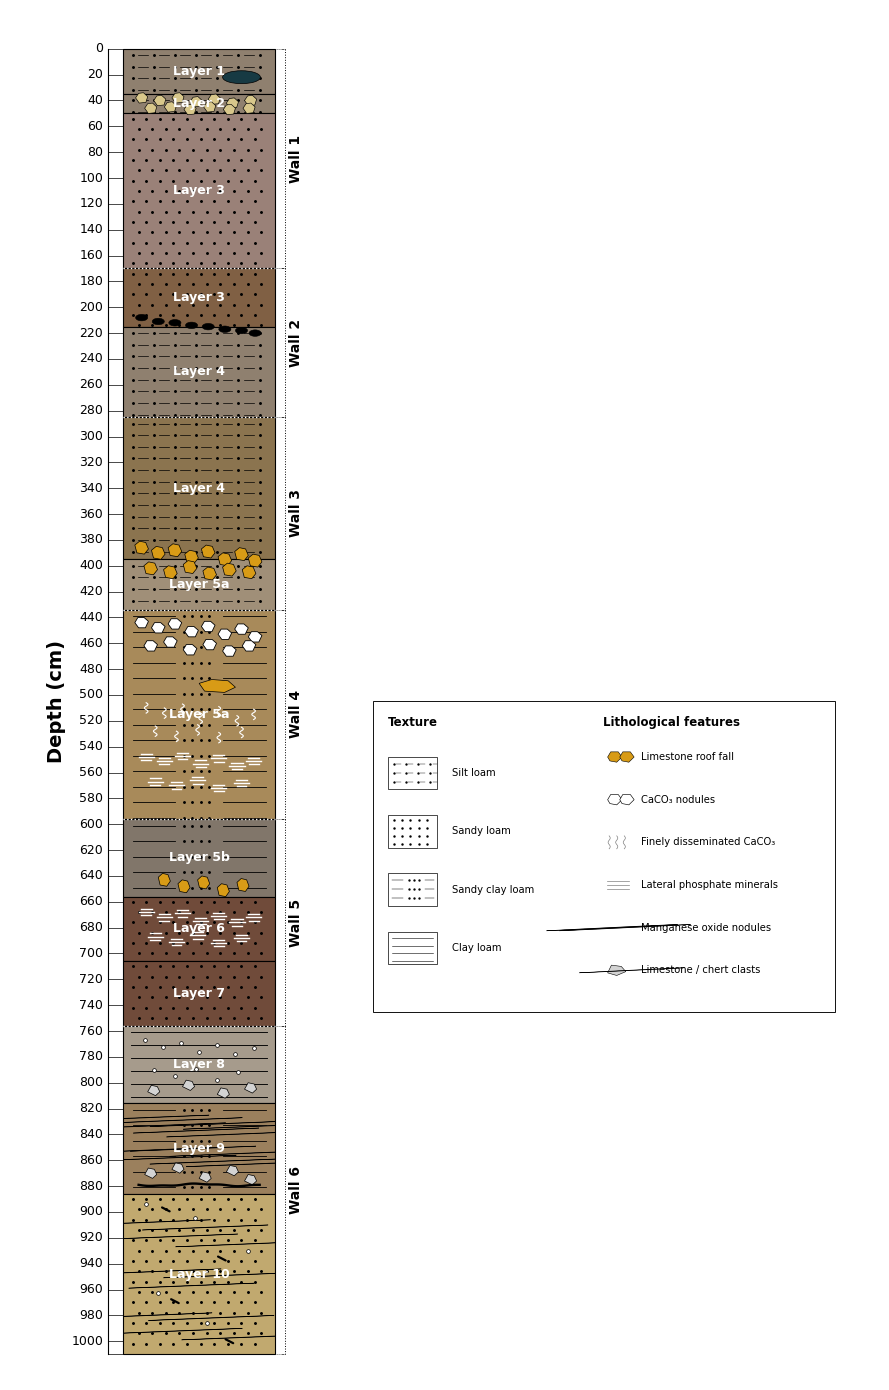

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle, Polygon, Ellipse


# ============================================================
# AZYKH CAVE — COMPOSITE LITHOLOGICAL LOG
# ============================================================


# ============================================================
# 1. LAYER DATA
# ============================================================

layers = [
    (0,    35,   "#8F806F", "Silt loam",       "Layer 1"),
    (35,   50,   "#8F806F", "Silt loam",       "Layer 2"),
    (50,   170,  "#9A8178", "Sandy loam",      "Layer 3"),

    (170,  215,  "#806044", "Sandy loam",      "Layer 3"),
    (215,  285,  "#8F806F", "Silt loam",       "Layer 4"),

    (285,  395,  "#8B744F", "Silt loam",       "Layer 4"),
    (395,  434,  "#A08F78", "Silt loam",       "Layer 5a"),

    (434,  596,  "#A88A5A", "Sandy clay loam", "Layer 5a"),

    (596,  656,  "#81766A", "Sandy clay loam", "Layer 5b"),
    (656,  706,  "#704B3A", "Sandy loam",      "Layer 6"),
    (706,  756,  "#704B3A", "Sandy loam",      "Layer 7"),

    (756,  816,  "#A69B8C", "Clay loam",       "Layer 8"),
    (816,  886,  "#9B805D", "Sandy clay loam", "Layer 9"),
    (886, 1010,  "#C1A96F", "Sandy loam",      "Layer 10"),
]


# ============================================================
# 2. WALL DATA
# ============================================================

walls = [
    (0,    170,  "Wall 1"),
    (170,  285,  "Wall 2"),
    (285,  434,  "Wall 3"),
    (434,  596,  "Wall 4"),
    (596,  756,  "Wall 5"),
    (756, 1010,  "Wall 6"),
]


# ============================================================
# 3. FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(9, 14))

x = 0
width = 1.0


# ============================================================
# 4. CLIPPING AREA
# Everything geological stays INSIDE the log
# ============================================================

clip_box = Rectangle(
    (x, 0),
    width,
    1010,
    transform=ax.transData
)


# ============================================================
# 5. TEXTURE FUNCTION
# ============================================================

def draw_texture(ax, left, right, top, bottom, texture):

    # SILT LOAM
    if texture == "Silt loam":

        for y in np.arange(top + 5, bottom, 9):

            xpos = left + 0.06

            while xpos < right - 0.05:

                p, = ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.2,
                    color="black",
                    zorder=3
                )
                p.set_clip_path(clip_box)

                if xpos + 0.10 < right:

                    p, = ax.plot(
                        [xpos + 0.035, xpos + 0.10],
                        [y, y],
                        color="black",
                        linewidth=0.5,
                        zorder=3
                    )
                    p.set_clip_path(clip_box)

                xpos += 0.14


    # SANDY LOAM
    elif texture == "Sandy loam":

        row = 0

        for y in np.arange(top + 4, bottom, 8):

            offset = 0.04 if row % 2 else 0

            for xpos in np.arange(
                left + 0.06 + offset,
                right - 0.04,
                0.09
            ):

                p, = ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.2,
                    color="black",
                    zorder=3
                )
                p.set_clip_path(clip_box)

            row += 1


    # SANDY CLAY LOAM
    elif texture == "Sandy clay loam":

        for y in np.arange(top + 5, bottom, 12):

            p, = ax.plot(
                [left + 0.06, left + 0.34],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )
            p.set_clip_path(clip_box)

            for xpos in np.arange(
                left + 0.40,
                left + 0.61,
                0.055
            ):

                p, = ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.1,
                    color="black",
                    zorder=3
                )
                p.set_clip_path(clip_box)

            p, = ax.plot(
                [left + 0.66, right - 0.06],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )
            p.set_clip_path(clip_box)


    # CLAY LOAM
    elif texture == "Clay loam":

        for y in np.arange(top + 5, bottom, 10):

            p, = ax.plot(
                [left + 0.05, right - 0.05],
                [y, y],
                color="black",
                linewidth=0.65,
                zorder=3
            )
            p.set_clip_path(clip_box)


# ============================================================
# 6. DRAW MAIN LOG
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    rect = Rectangle(
        (x, top),
        width,
        bottom - top,
        facecolor=colour,
        edgecolor="black",
        linewidth=0.8,
        zorder=1
    )

    ax.add_patch(rect)

    draw_texture(
        ax,
        x,
        x + width,
        top,
        bottom,
        texture
    )


# ============================================================
# 7. GEOLOGICAL SYMBOL FUNCTIONS
# ============================================================

def fumier_symbol(ax, xc, yc, w=0.25, h=10):

    e = Ellipse(
        (xc, yc),
        width=w,
        height=h,
        facecolor="#173A43",
        edgecolor="black",
        linewidth=0.5,
        zorder=9
    )

    ax.add_patch(e)
    e.set_clip_path(clip_box)


def concretion_symbol(ax, xc, yc, size=0.04):

    p = Polygon(
        [
            (xc - size, yc),
            (xc - size*0.5, yc - 3.5),
            (xc + size*0.3, yc - 4),
            (xc + size, yc - 1),
            (xc + size*0.7, yc + 3.5),
            (xc - size*0.4, yc + 4)
        ],
        closed=True,
        facecolor="#D8C78B",
        edgecolor="black",
        linewidth=0.45,
        zorder=9
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


def limestone_roof_fall(ax, xc, yc, size=0.045):

    p = Polygon(
        [
            (xc - size, yc - 2),
            (xc - size*0.3, yc - 5),
            (xc + size*0.6, yc - 4),
            (xc + size, yc + 1),
            (xc + size*0.4, yc + 5),
            (xc - size*0.7, yc + 4)
        ],
        closed=True,
        facecolor="#D89B16",
        edgecolor="black",
        linewidth=0.5,
        zorder=9
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


def carbonate_nodule(ax, xc, yc, size=0.045):

    p = Polygon(
        [
            (xc - size, yc),
            (xc - size*0.55, yc - 4),
            (xc + size*0.35, yc - 4),
            (xc + size, yc - 1),
            (xc + size*0.55, yc + 4),
            (xc - size*0.45, yc + 4)
        ],
        closed=True,
        facecolor="white",
        edgecolor="black",
        linewidth=0.6,
        zorder=9
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


def manganese_symbol(ax, xc, yc):

    e = Ellipse(
        (xc, yc),
        width=0.08,
        height=5,
        facecolor="black",
        edgecolor="black",
        linewidth=0.4,
        zorder=9
    )

    ax.add_patch(e)
    e.set_clip_path(clip_box)


def phosphate_symbol(ax, xc, yc):

    for dy, length in [
        (-2.5, 0.075),
        (0, 0.10),
        (2.5, 0.065)
    ]:

        p, = ax.plot(
            [xc - length/2, xc + length/2],
            [yc + dy, yc + dy],
            color="white",
            linewidth=1.0,
            zorder=10
        )

        p.set_clip_path(clip_box)


def disseminated_caco3(ax, xc, yc):

    yvals = np.linspace(yc - 4, yc + 4, 20)

    xvals = (
        xc
        + 0.012
        * np.sin(np.linspace(0, 3*np.pi, 20))
    )

    p, = ax.plot(
        xvals,
        yvals,
        color="white",
        linewidth=0.8,
        zorder=10
    )

    p.set_clip_path(clip_box)


def limestone_clast(ax, xc, yc, size=0.04):

    p = Polygon(
        [
            (xc - size, yc + 1),
            (xc - size*0.4, yc - 4),
            (xc + size*0.6, yc - 3),
            (xc + size, yc + 1),
            (xc + size*0.3, yc + 4)
        ],
        closed=True,
        facecolor="lightgray",
        edgecolor="black",
        linewidth=0.5,
        zorder=9
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


def chert_clast(ax, xc, yc):

    e = Ellipse(
        (xc, yc),
        width=0.065,
        height=4,
        angle=12,
        facecolor="dimgray",
        edgecolor="black",
        linewidth=0.4,
        zorder=9
    )

    ax.add_patch(e)
    e.set_clip_path(clip_box)


def carbonate_granule(ax, xc, yc):

    p, = ax.plot(
        xc,
        yc,
        marker="o",
        markersize=2.7,
        markerfacecolor="white",
        markeredgecolor="black",
        markeredgewidth=0.5,
        zorder=10
    )

    p.set_clip_path(clip_box)


def charcoal_fragment(ax, xc, yc):

    p, = ax.plot(
        [xc - 0.025, xc + 0.025],
        [yc - 1.5, yc + 1.5],
        color="black",
        linewidth=1.6,
        solid_capstyle="round",
        zorder=10
    )

    p.set_clip_path(clip_box)


def hearth_layer(ax, y):

    xs = np.linspace(0.10, 0.90, 60)

    ys = (
        y
        + 0.8 * np.sin(np.linspace(0, 3*np.pi, 60))
        + 0.3 * np.sin(np.linspace(0, 8*np.pi, 60))
    )

    p, = ax.plot(
        xs,
        ys,
        color="black",
        linewidth=1.7,
        zorder=11
    )

    p.set_clip_path(clip_box)


# ============================================================
# 8. WALL 1
# ============================================================

fumier_symbol(ax, 0.78, 22)

for xpos, ypos in [
    (0.12,38), (0.24,40), (0.36,38),
    (0.48,41), (0.60,39), (0.72,42),
    (0.84,40), (0.18,46), (0.31,45),
    (0.44,47), (0.57,45), (0.70,47),
    (0.83,46)
]:
    concretion_symbol(ax, xpos, ypos)


# ============================================================
# 9. WALL 2
# ============================================================

for xpos, ypos in [
    (0.12,208), (0.23,211), (0.34,212),
    (0.45,214), (0.56,215), (0.67,217),
    (0.78,218), (0.87,220)
]:
    manganese_symbol(ax, xpos, ypos)


# ============================================================
# 10. WALL 3
# ============================================================

for xpos, ypos in [
    (0.12,386), (0.23,390), (0.34,388),
    (0.45,393), (0.56,389), (0.67,395),
    (0.78,391), (0.87,396), (0.18,402),
    (0.31,405), (0.44,401), (0.57,406),
    (0.70,403), (0.83,405)
]:
    limestone_roof_fall(ax, xpos, ypos)


# ============================================================
# 11. WALL 4
# ============================================================

for xpos, ypos in [
    (0.12,444), (0.23,448), (0.34,445),
    (0.45,451), (0.56,447), (0.67,453),
    (0.78,449), (0.87,455), (0.18,462),
    (0.31,459), (0.44,465), (0.57,461),
    (0.70,466), (0.83,462)
]:
    carbonate_nodule(ax, xpos, ypos)


limestone_roof_fall(
    ax,
    0.62,
    493,
    size=0.12
)


for xpos, ypos in [
    (0.15,510), (0.27,514), (0.39,511),
    (0.51,518), (0.63,513), (0.75,520),
    (0.86,515), (0.21,528), (0.35,532),
    (0.49,527), (0.63,533), (0.78,529)
]:
    disseminated_caco3(ax, xpos, ypos)


for xpos, ypos in [
    (0.15,548), (0.27,551), (0.39,547),
    (0.51,553), (0.63,549), (0.75,555),
    (0.86,551), (0.21,567), (0.35,570),
    (0.49,566), (0.63,572), (0.78,568)
]:
    phosphate_symbol(ax, xpos, ypos)


# ============================================================
# 12. WALL 5
# ============================================================

for xpos, ypos in [
    (0.27,643),
    (0.40,648),
    (0.53,645),
    (0.66,651),
    (0.79,647)
]:
    limestone_roof_fall(
        ax,
        xpos,
        ypos,
        size=0.04
    )


for xpos, ypos in [
    (0.15,668), (0.27,672), (0.39,669),
    (0.51,675), (0.63,671), (0.75,676),
    (0.86,672), (0.21,687), (0.35,691),
    (0.49,686), (0.63,692), (0.78,688)
]:
    phosphate_symbol(ax, xpos, ypos)


# ============================================================
# 13. WALL 6
# ============================================================

# Layer 8
for xpos, ypos in [
    (0.14,767), (0.26,772), (0.38,769),
    (0.50,776), (0.62,771), (0.74,778),
    (0.86,773), (0.20,790), (0.34,795),
    (0.48,789), (0.62,798), (0.76,792)
]:
    carbonate_granule(ax, xpos, ypos)


for xpos, ypos in [
    (0.20,806),
    (0.43,802),
    (0.66,808),
    (0.84,804)
]:
    limestone_clast(ax, xpos, ypos)


# Layer 9
for xpos, ypos in [
    (0.15,827), (0.26,833), (0.37,829),
    (0.48,837), (0.59,832), (0.70,840),
    (0.81,834), (0.20,852), (0.33,858),
    (0.46,851), (0.59,861), (0.72,855),
    (0.83,863)
]:
    chert_clast(ax, xpos, ypos)


for xpos, ypos in [
    (0.18,870),
    (0.36,866),
    (0.54,873),
    (0.72,868),
    (0.84,875)
]:
    limestone_clast(ax, xpos, ypos)


hearth_layer(ax, 879)


# Layer 10
for xpos, ypos in [
    (0.16,908), (0.34,919),
    (0.54,912), (0.76,925),
    (0.23,946), (0.45,957),
    (0.68,949), (0.17,980),
    (0.37,992), (0.58,982),
    (0.80,997)
]:
    chert_clast(ax, xpos, ypos)


for xpos, ypos in [
    (0.28,898),
    (0.65,936),
    (0.34,969),
    (0.70,1000)
]:
    charcoal_fragment(ax, xpos, ypos)


for xpos, ypos in [
    (0.15,894),
    (0.47,905),
    (0.82,930),
    (0.23,963),
    (0.55,986)
]:
    carbonate_granule(ax, xpos, ypos)


# ============================================================
# 14. LAYER LABELS
# ALL HORIZONTAL
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    midpoint = (top + bottom) / 2

    ax.text(
        0.50,
        midpoint,
        layer_name,
        color="white",
        fontsize=9,
        fontweight="bold",
        ha="center",
        va="center",
        rotation=0,
        zorder=30
    )


# ============================================================
# 15. SMALL DOTTED WALL BRACKETS
# ============================================================

wall_x = 1.07
bracket_width = 0.025


for top, bottom, wall_name in walls:

    midpoint = (top + bottom) / 2

    ax.plot(
        [wall_x, wall_x],
        [top, bottom],
        color="black",
        linewidth=0.7,
        linestyle=":",
        zorder=15
    )

    ax.plot(
        [wall_x - bracket_width, wall_x],
        [top, top],
        color="black",
        linewidth=0.7,
        linestyle=":",
        zorder=15
    )

    ax.plot(
        [wall_x - bracket_width, wall_x],
        [bottom, bottom],
        color="black",
        linewidth=0.7,
        linestyle=":",
        zorder=15
    )

    ax.text(
        wall_x + 0.07,
        midpoint,
        wall_name,
        fontsize=10,
        fontweight="bold",
        rotation=90,
        ha="center",
        va="center",
        zorder=20
    )


# ============================================================
# 16. WALL CONNECTORS
# ============================================================

for depth in [
    0, 170, 285, 434,
    596, 756, 1010
]:

    ax.plot(
        [1.0, wall_x],
        [depth, depth],
        color="black",
        linewidth=0.55,
        linestyle=":",
        zorder=14
    )


# ============================================================
# 17. WALL BOUNDARIES INSIDE LOG
# ============================================================

for depth in [
    170, 285, 434,
    596, 756
]:

    ax.plot(
        [0, 1],
        [depth, depth],
        color="white",
        linewidth=1,
        linestyle=":",
        zorder=20
    )


# ============================================================
# 18. COMPACT DEPTH SCALE
# ============================================================

scale_x = -0.10


ax.plot(
    [scale_x, scale_x],
    [0, 1010],
    color="black",
    linewidth=0.8
)


for depth in range(0, 1001, 20):

    # Short scale spike toward log
    ax.plot(
        [scale_x, 0],
        [depth, depth],
        color="black",
        linewidth=0.5
    )

    # Depth number outside
    ax.text(
        scale_x - 0.035,
        depth,
        str(depth),
        fontsize=9,
        ha="right",
        va="center"
    )


# Bottom line only
ax.plot(
    [scale_x, 0],
    [1010, 1010],
    color="black",
    linewidth=0.5
)


ax.text(
    scale_x - 0.34,
    505,
    "Depth (cm)",
    rotation=90,
    fontsize=14,
    fontweight="bold",
    ha="center",
    va="center"
)


# ============================================================
# 19. ONE SMALL COMPACT LEGEND BOX
# ============================================================

legend_x = 1.65
legend_y = 505

legend_w = 3.05
legend_h = 240


legend_box = Rectangle(
    (legend_x, legend_y),
    legend_w,
    legend_h,
    facecolor="white",
    edgecolor="black",
    linewidth=0.65,
    zorder=40
)

ax.add_patch(legend_box)


# ============================================================
# 20. LEFT SIDE — TEXTURE
# ============================================================

left_x = legend_x + 0.10
left_text_x = left_x + 0.42


ax.text(
    left_x,
    legend_y + 16,
    "Texture",
    fontsize=8.5,
    fontweight="bold",
    ha="left",
    va="center",
    zorder=45
)


texture_items = [
    ("Silt loam", 43),
    ("Sandy loam", 88),
    ("Sandy clay loam", 133),
    ("Clay loam", 178)
]


box_w = 0.32
box_h = 25


for texture, offset in texture_items:

    top = legend_y + offset
    bottom = top + box_h


    box = Rectangle(
        (left_x, top),
        box_w,
        box_h,
        facecolor="white",
        edgecolor="black",
        linewidth=0.5,
        zorder=42
    )

    ax.add_patch(box)


    # SILT LOAM
    if texture == "Silt loam":

        for yy in np.arange(top + 5, bottom, 7):

            for xx in np.arange(
                left_x + 0.035,
                left_x + box_w - 0.02,
                0.08
            ):

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.4,
                    color="black",
                    zorder=43
                )

                ax.plot(
                    [xx + 0.018, xx + 0.05],
                    [yy, yy],
                    color="black",
                    linewidth=0.3,
                    zorder=43
                )


    # SANDY LOAM
    elif texture == "Sandy loam":

        for yy in np.arange(top + 4, bottom, 6):

            for xx in np.arange(
                left_x + 0.035,
                left_x + box_w - 0.02,
                0.055
            ):

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.5,
                    color="black",
                    zorder=43
                )


    # SANDY CLAY LOAM
    elif texture == "Sandy clay loam":

        for yy in np.arange(top + 5, bottom, 7):

            ax.plot(
                [
                    left_x + 0.025,
                    left_x + 0.095
                ],
                [yy, yy],
                color="black",
                linewidth=0.35,
                zorder=43
            )

            for xx in [
                left_x + 0.14,
                left_x + 0.17,
                left_x + 0.20
            ]:

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.4,
                    color="black",
                    zorder=43
                )

            ax.plot(
                [
                    left_x + 0.24,
                    left_x + 0.30
                ],
                [yy, yy],
                color="black",
                linewidth=0.35,
                zorder=43
            )


    # CLAY LOAM
    elif texture == "Clay loam":

        for yy in np.arange(top + 5, bottom, 6):

            ax.plot(
                [
                    left_x + 0.025,
                    left_x + box_w - 0.025
                ],
                [yy, yy],
                color="black",
                linewidth=0.4,
                zorder=43
            )


    ax.text(
        left_text_x,
        top + box_h / 2,
        texture,
        fontsize=7.2,
        ha="left",
        va="center",
        zorder=45
    )


# ============================================================
# 21. RIGHT SIDE — LITHOLOGICAL FEATURES
# ============================================================

right_x = legend_x + 1.52
right_text_x = right_x + 0.25


ax.text(
    right_x,
    legend_y + 16,
    "Lithological features",
    fontsize=8.5,
    fontweight="bold",
    ha="left",
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# LIMESTONE ROOF FALL
# ------------------------------------------------------------

yy = legend_y + 43

for dx in [0.03, 0.11]:

    p = Polygon(
        [
            (right_x + dx, yy),
            (right_x + dx + 0.02, yy - 4),
            (right_x + dx + 0.07, yy - 4),
            (right_x + dx + 0.095, yy),
            (right_x + dx + 0.06, yy + 4),
            (right_x + dx + 0.015, yy + 3)
        ],
        closed=True,
        facecolor="#D89B16",
        edgecolor="black",
        linewidth=0.4,
        zorder=43
    )

    ax.add_patch(p)


ax.text(
    right_text_x,
    yy,
    "Limestone roof fall",
    fontsize=7.2,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# CALCIUM CARBONATE NODULES
# ------------------------------------------------------------

yy = legend_y + 76

for dx in [0.03, 0.11]:

    p = Polygon(
        [
            (right_x + dx, yy),
            (right_x + dx + 0.02, yy - 4),
            (right_x + dx + 0.07, yy - 4),
            (right_x + dx + 0.095, yy),
            (right_x + dx + 0.06, yy + 4),
            (right_x + dx + 0.015, yy + 3)
        ],
        closed=True,
        facecolor="white",
        edgecolor="black",
        linewidth=0.45,
        zorder=43
    )

    ax.add_patch(p)


ax.text(
    right_text_x,
    yy,
    "CaCO₃ nodules",
    fontsize=7.2,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# FINELY DISSEMINATED CaCO3
# ------------------------------------------------------------

yy = legend_y + 109

for dx in [0.04, 0.09, 0.14]:

    y_wave = np.linspace(
        yy - 5,
        yy + 5,
        20
    )

    x_wave = (
        right_x
        + dx
        + 0.007 *
        np.sin(
            np.linspace(
                0,
                3*np.pi,
                20
            )
        )
    )

    ax.plot(
        x_wave,
        y_wave,
        color="gray",
        linewidth=0.5,
        zorder=43
    )


ax.text(
    right_text_x,
    yy,
    "Finely disseminated CaCO₃",
    fontsize=7.2,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# LATERAL PHOSPHATE MINERALS
# ------------------------------------------------------------

yy = legend_y + 142

for dy in [-3, 0, 3]:

    ax.plot(
        [
            right_x + 0.025,
            right_x + 0.17
        ],
        [
            yy + dy,
            yy + dy
        ],
        color="gray",
        linewidth=0.5,
        zorder=43
    )


ax.text(
    right_text_x,
    yy,
    "Lateral phosphate minerals",
    fontsize=7.2,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# MANGANESE OXIDE NODULES
# ------------------------------------------------------------

yy = legend_y + 175

for dx in [0.06, 0.145]:

    e = Ellipse(
        (right_x + dx, yy),
        width=0.065,
        height=5,
        angle=10,
        facecolor="black",
        edgecolor="black",
        linewidth=0.35,
        zorder=43
    )

    ax.add_patch(e)


ax.text(
    right_text_x,
    yy,
    "Manganese oxide nodules",
    fontsize=7.2,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# LIMESTONE / CHERT CLASTS
# ------------------------------------------------------------

yy = legend_y + 208


p = Polygon(
    [
        (right_x + 0.03, yy + 2),
        (right_x + 0.055, yy - 4),
        (right_x + 0.12, yy - 3),
        (right_x + 0.15, yy + 1),
        (right_x + 0.09, yy + 4)
    ],
    closed=True,
    facecolor="lightgray",
    edgecolor="black",
    linewidth=0.4,
    zorder=43
)

ax.add_patch(p)


e = Ellipse(
    (right_x + 0.19, yy),
    width=0.05,
    height=4,
    angle=10,
    facecolor="dimgray",
    edgecolor="black",
    linewidth=0.35,
    zorder=43
)

ax.add_patch(e)


ax.text(
    right_text_x,
    yy,
    "Limestone / chert clasts",
    fontsize=7.2,
    va="center",
    zorder=45
)


# ============================================================
# 22. FINAL FORMAT
# ============================================================

ax.set_xlim(
    -0.75,
    5.0
)

ax.set_ylim(
    1030,
    -30
)

ax.axis("off")

plt.tight_layout()


# ============================================================
# 23. SAVE
# ============================================================

plt.savefig(
    "Azykh_complete_compact_log.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Azykh_complete_compact_log.pdf",
    bbox_inches="tight"
)


# ============================================================
# 24. SHOW
# ============================================================

plt.show()

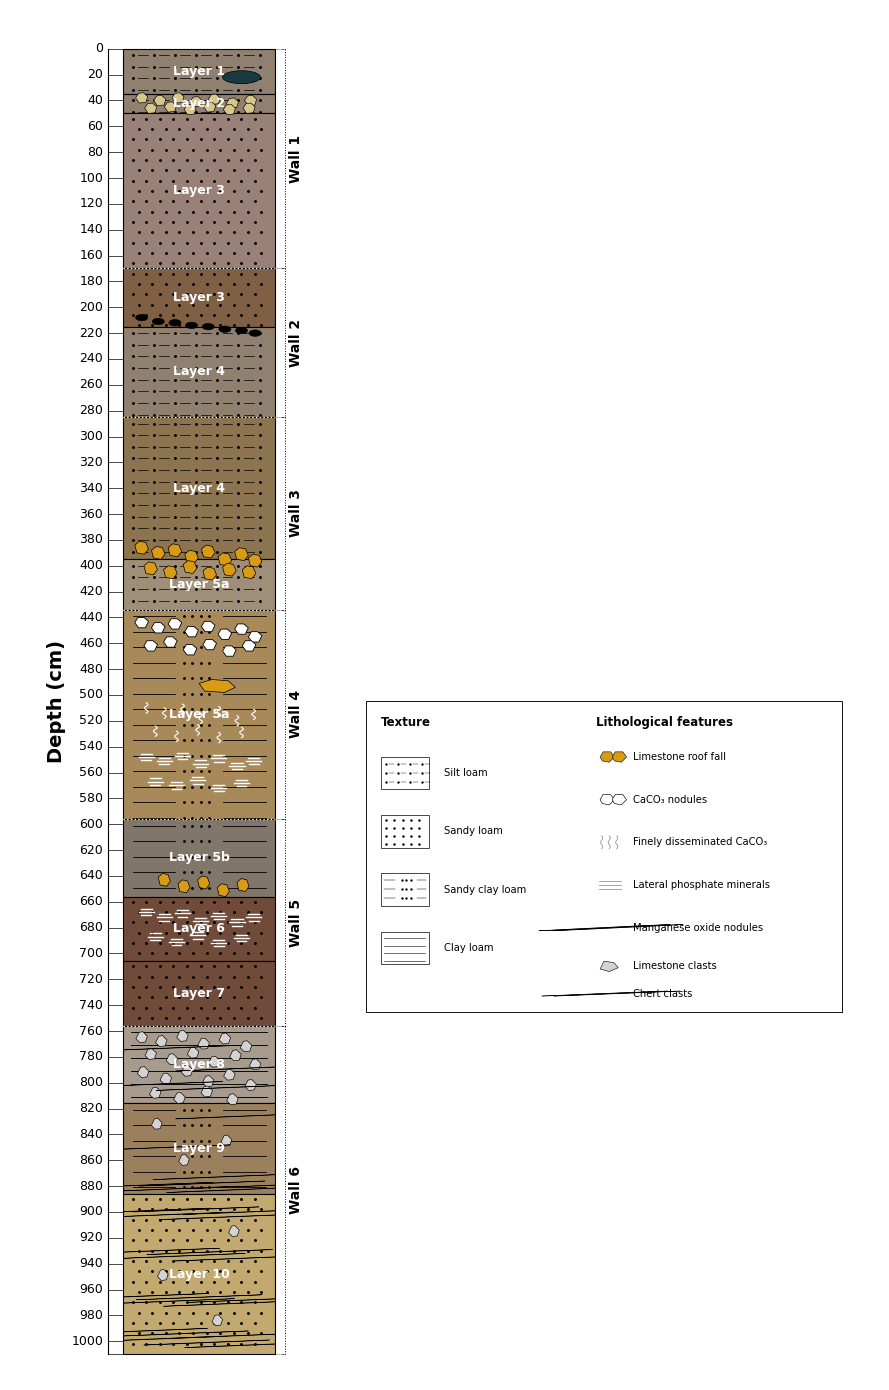

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle, Polygon, Ellipse


# ============================================================
# AZYKH CAVE — COMPOSITE LITHOLOGICAL LOG
# Depth: 0–1010 cm
# ============================================================


# ============================================================
# 1. LAYER DATA
# ============================================================

layers = [
    (0,    35,   "#8F806F", "Silt loam",       "Layer 1"),
    (35,   50,   "#8F806F", "Silt loam",       "Layer 2"),
    (50,   170,  "#9A8178", "Sandy loam",      "Layer 3"),

    (170,  215,  "#806044", "Sandy loam",      "Layer 3"),
    (215,  285,  "#8F806F", "Silt loam",       "Layer 4"),

    (285,  395,  "#8B744F", "Silt loam",       "Layer 4"),
    (395,  434,  "#A08F78", "Silt loam",       "Layer 5a"),

    (434,  596,  "#A88A5A", "Sandy clay loam", "Layer 5a"),

    (596,  656,  "#81766A", "Sandy clay loam", "Layer 5b"),
    (656,  706,  "#704B3A", "Sandy loam",      "Layer 6"),
    (706,  756,  "#704B3A", "Sandy loam",      "Layer 7"),

    (756,  816,  "#A69B8C", "Clay loam",       "Layer 8"),
    (816,  886,  "#9B805D", "Sandy clay loam", "Layer 9"),
    (886, 1010,  "#C1A96F", "Sandy loam",      "Layer 10"),
]


# ============================================================
# 2. WALL DATA
# ============================================================

walls = [
    (0,    170,  "Wall 1"),
    (170,  285,  "Wall 2"),
    (285,  434,  "Wall 3"),
    (434,  596,  "Wall 4"),
    (596,  756,  "Wall 5"),
    (756, 1010,  "Wall 6"),
]


# ============================================================
# 3. FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(9, 14))

x = 0
width = 1.0


# ============================================================
# 4. CLIPPING AREA
# Keeps all geological symbols inside the log
# ============================================================

clip_box = Rectangle(
    (x, 0),
    width,
    1010,
    transform=ax.transData
)


# ============================================================
# 5. TEXTURE FUNCTION
# ============================================================

def draw_texture(ax, left, right, top, bottom, texture):

    # --------------------------------------------------------
    # SILT LOAM
    # dot + short dash
    # --------------------------------------------------------
    if texture == "Silt loam":

        for y in np.arange(top + 5, bottom, 9):

            xpos = left + 0.06

            while xpos < right - 0.05:

                p, = ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.2,
                    color="black",
                    zorder=3
                )

                p.set_clip_path(clip_box)

                if xpos + 0.10 < right:

                    p, = ax.plot(
                        [xpos + 0.035, xpos + 0.10],
                        [y, y],
                        color="black",
                        linewidth=0.5,
                        zorder=3
                    )

                    p.set_clip_path(clip_box)

                xpos += 0.14


    # --------------------------------------------------------
    # SANDY LOAM
    # dots
    # --------------------------------------------------------
    elif texture == "Sandy loam":

        row = 0

        for y in np.arange(top + 4, bottom, 8):

            offset = 0.04 if row % 2 else 0

            for xpos in np.arange(
                left + 0.06 + offset,
                right - 0.04,
                0.09
            ):

                p, = ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.2,
                    color="black",
                    zorder=3
                )

                p.set_clip_path(clip_box)

            row += 1


    # --------------------------------------------------------
    # SANDY CLAY LOAM
    # line + dots + line
    # --------------------------------------------------------
    elif texture == "Sandy clay loam":

        for y in np.arange(top + 5, bottom, 12):

            p, = ax.plot(
                [left + 0.06, left + 0.34],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            p.set_clip_path(clip_box)

            for xpos in np.arange(
                left + 0.40,
                left + 0.61,
                0.055
            ):

                p, = ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.1,
                    color="black",
                    zorder=3
                )

                p.set_clip_path(clip_box)

            p, = ax.plot(
                [left + 0.66, right - 0.06],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            p.set_clip_path(clip_box)


    # --------------------------------------------------------
    # CLAY LOAM
    # horizontal lines
    # --------------------------------------------------------
    elif texture == "Clay loam":

        for y in np.arange(top + 5, bottom, 10):

            p, = ax.plot(
                [left + 0.05, right - 0.05],
                [y, y],
                color="black",
                linewidth=0.65,
                zorder=3
            )

            p.set_clip_path(clip_box)


# ============================================================
# 6. DRAW MAIN LOG
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    rect = Rectangle(
        (x, top),
        width,
        bottom - top,
        facecolor=colour,
        edgecolor="black",
        linewidth=0.8,
        zorder=1
    )

    ax.add_patch(rect)

    draw_texture(
        ax,
        x,
        x + width,
        top,
        bottom,
        texture
    )


# ============================================================
# 7. LITHOLOGICAL SYMBOL FUNCTIONS
# ============================================================


# ------------------------------------------------------------
# FUMIER
# ------------------------------------------------------------

def fumier_symbol(ax, xc, yc):

    e = Ellipse(
        (xc, yc),
        width=0.25,
        height=10,
        facecolor="#173A43",
        edgecolor="black",
        linewidth=0.5,
        zorder=9
    )

    ax.add_patch(e)
    e.set_clip_path(clip_box)


# ------------------------------------------------------------
# CONCRETIONS
# ------------------------------------------------------------

def concretion_symbol(ax, xc, yc, size=0.04):

    p = Polygon(
        [
            (xc - size, yc),
            (xc - size*0.5, yc - 3.5),
            (xc + size*0.3, yc - 4),
            (xc + size, yc - 1),
            (xc + size*0.7, yc + 3.5),
            (xc - size*0.4, yc + 4)
        ],
        closed=True,
        facecolor="#D8C78B",
        edgecolor="black",
        linewidth=0.45,
        zorder=9
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# LIMESTONE ROOF FALL
# ------------------------------------------------------------

def limestone_roof_fall(ax, xc, yc, size=0.045):

    p = Polygon(
        [
            (xc - size, yc - 2),
            (xc - size*0.3, yc - 5),
            (xc + size*0.6, yc - 4),
            (xc + size, yc + 1),
            (xc + size*0.4, yc + 5),
            (xc - size*0.7, yc + 4)
        ],
        closed=True,
        facecolor="#D89B16",
        edgecolor="black",
        linewidth=0.5,
        zorder=9
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# CALCIUM CARBONATE NODULE
# ------------------------------------------------------------

def carbonate_nodule(ax, xc, yc, size=0.045):

    p = Polygon(
        [
            (xc - size, yc),
            (xc - size*0.55, yc - 4),
            (xc + size*0.35, yc - 4),
            (xc + size, yc - 1),
            (xc + size*0.55, yc + 4),
            (xc - size*0.45, yc + 4)
        ],
        closed=True,
        facecolor="white",
        edgecolor="black",
        linewidth=0.6,
        zorder=9
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# MANGANESE OXIDE NODULE
# ------------------------------------------------------------

def manganese_symbol(ax, xc, yc):

    e = Ellipse(
        (xc, yc),
        width=0.08,
        height=5,
        facecolor="black",
        edgecolor="black",
        linewidth=0.4,
        zorder=9
    )

    ax.add_patch(e)
    e.set_clip_path(clip_box)


# ------------------------------------------------------------
# LATERAL PHOSPHATE
# ------------------------------------------------------------

def phosphate_symbol(ax, xc, yc):

    for dy, length in [
        (-2.5, 0.075),
        (0, 0.10),
        (2.5, 0.065)
    ]:

        p, = ax.plot(
            [xc - length/2, xc + length/2],
            [yc + dy, yc + dy],
            color="white",
            linewidth=1.0,
            zorder=10
        )

        p.set_clip_path(clip_box)


# ------------------------------------------------------------
# FINELY DISSEMINATED CaCO3
# ------------------------------------------------------------

def disseminated_caco3(ax, xc, yc):

    yvals = np.linspace(
        yc - 4,
        yc + 4,
        20
    )

    xvals = (
        xc
        + 0.012
        * np.sin(
            np.linspace(0, 3*np.pi, 20)
        )
    )

    p, = ax.plot(
        xvals,
        yvals,
        color="white",
        linewidth=0.8,
        zorder=10
    )

    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# LIMESTONE CLAST
# Light grey angular fragment
# ------------------------------------------------------------

def limestone_clast(ax, xc, yc, size=0.04):

    p = Polygon(
        [
            (xc - size,       yc + 1),
            (xc - size*0.45,  yc - 4),
            (xc + size*0.20,  yc - 4.5),
            (xc + size,       yc - 1),
            (xc + size*0.65,  yc + 3.5),
            (xc - size*0.30,  yc + 4)
        ],
        closed=True,
        facecolor="lightgray",
        edgecolor="black",
        linewidth=0.45,
        zorder=9
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# CHERT CLAST
# Dark grey elongated fragment
# ------------------------------------------------------------

def chert_clast(ax, xc, yc, size=0.065):

    e = Ellipse(
        (xc, yc),
        width=size,
        height=4,
        angle=12,
        facecolor="dimgray",
        edgecolor="black",
        linewidth=0.4,
        zorder=9
    )

    ax.add_patch(e)
    e.set_clip_path(clip_box)


# ============================================================
# 8. WALL 1
# ============================================================

fumier_symbol(
    ax,
    0.78,
    22
)


for xpos, ypos in [

    (0.12, 38),
    (0.24, 40),
    (0.36, 38),
    (0.48, 41),
    (0.60, 39),
    (0.72, 42),
    (0.84, 40),

    (0.18, 46),
    (0.31, 45),
    (0.44, 47),
    (0.57, 45),
    (0.70, 47),
    (0.83, 46)

]:

    concretion_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 9. WALL 2
# Manganese oxide nodules
# ============================================================

for xpos, ypos in [

    (0.12, 208),
    (0.23, 211),
    (0.34, 212),
    (0.45, 214),
    (0.56, 215),
    (0.67, 217),
    (0.78, 218),
    (0.87, 220)

]:

    manganese_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 10. WALL 3
# Limestone roof fall
# ============================================================

for xpos, ypos in [

    (0.12, 386),
    (0.23, 390),
    (0.34, 388),
    (0.45, 393),
    (0.56, 389),
    (0.67, 395),
    (0.78, 391),
    (0.87, 396),

    (0.18, 402),
    (0.31, 405),
    (0.44, 401),
    (0.57, 406),
    (0.70, 403),
    (0.83, 405)

]:

    limestone_roof_fall(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 11. WALL 4
# ============================================================


# ------------------------------------------------------------
# CaCO3 nodules
# ------------------------------------------------------------

for xpos, ypos in [

    (0.12, 444),
    (0.23, 448),
    (0.34, 445),
    (0.45, 451),
    (0.56, 447),
    (0.67, 453),
    (0.78, 449),
    (0.87, 455),

    (0.18, 462),
    (0.31, 459),
    (0.44, 465),
    (0.57, 461),
    (0.70, 466),
    (0.83, 462)

]:

    carbonate_nodule(
        ax,
        xpos,
        ypos
    )


# Large roof-fall fragment
limestone_roof_fall(
    ax,
    0.62,
    493,
    size=0.12
)


# ------------------------------------------------------------
# Finely disseminated CaCO3
# ------------------------------------------------------------

for xpos, ypos in [

    (0.15, 510),
    (0.27, 514),
    (0.39, 511),
    (0.51, 518),
    (0.63, 513),
    (0.75, 520),
    (0.86, 515),

    (0.21, 528),
    (0.35, 532),
    (0.49, 527),
    (0.63, 533),
    (0.78, 529)

]:

    disseminated_caco3(
        ax,
        xpos,
        ypos
    )


# ------------------------------------------------------------
# Lateral phosphate
# ------------------------------------------------------------

for xpos, ypos in [

    (0.15, 548),
    (0.27, 551),
    (0.39, 547),
    (0.51, 553),
    (0.63, 549),
    (0.75, 555),
    (0.86, 551),

    (0.21, 567),
    (0.35, 570),
    (0.49, 566),
    (0.63, 572),
    (0.78, 568)

]:

    phosphate_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 12. WALL 5
# ============================================================


# Limestone roof fall
for xpos, ypos in [

    (0.27, 643),
    (0.40, 648),
    (0.53, 645),
    (0.66, 651),
    (0.79, 647)

]:

    limestone_roof_fall(
        ax,
        xpos,
        ypos,
        size=0.04
    )


# Lateral phosphate
for xpos, ypos in [

    (0.15, 668),
    (0.27, 672),
    (0.39, 669),
    (0.51, 675),
    (0.63, 671),
    (0.75, 676),
    (0.86, 672),

    (0.21, 687),
    (0.35, 691),
    (0.49, 686),
    (0.63, 692),
    (0.78, 688)

]:

    phosphate_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 13. WALL 6
# ONLY LIMESTONE CLASTS + CHERT CLASTS
# ============================================================


# ============================================================
# LAYER 8
# 756–816 cm
# Clast-rich interval
# ============================================================

# Limestone clasts
for xpos, ypos in [

    (0.12, 765),
    (0.25, 768),
    (0.39, 764),
    (0.53, 770),
    (0.67, 766),
    (0.81, 772),

    (0.18, 778),
    (0.32, 782),
    (0.46, 777),
    (0.60, 784),
    (0.74, 779),
    (0.87, 786),

    (0.13, 792),
    (0.28, 797),
    (0.42, 791),
    (0.56, 799),
    (0.70, 794),
    (0.84, 802),

    (0.21, 808),
    (0.37, 812),
    (0.55, 807),
    (0.72, 813)

]:

    limestone_clast(
        ax,
        xpos,
        ypos,
        size=0.038
    )


# A few chert clasts
for xpos, ypos in [

    (0.34, 773),
    (0.76, 789),
    (0.24, 801),
    (0.63, 804)

]:

    chert_clast(
        ax,
        xpos,
        ypos,
        size=0.055
    )


# ============================================================
# LAYER 9
# 816–886 cm
# Mostly sediment, sparse clasts
# ============================================================


# Sparse limestone clasts
for xpos, ypos in [

    (0.22, 832),
    (0.68, 845),
    (0.40, 860)

]:

    limestone_clast(
        ax,
        xpos,
        ypos,
        size=0.035
    )


# Sparse chert clasts
for xpos, ypos in [

    (0.76, 826),
    (0.29, 850),
    (0.61, 873)

]:

    chert_clast(
        ax,
        xpos,
        ypos,
        size=0.052
    )


# Chert concentration near base of Layer 9
for xpos, ypos in [

    (0.18, 879),
    (0.35, 882),
    (0.52, 878),
    (0.70, 883),
    (0.84, 880)

]:

    chert_clast(
        ax,
        xpos,
        ypos,
        size=0.055
    )


# ============================================================
# LAYER 10
# 886–1010 cm
# Distinct chert-rich horizons
# ============================================================


# ------------------------------------------------------------
# Chert horizon 1
# ------------------------------------------------------------

for xpos, ypos in [

    (0.16, 899),
    (0.31, 902),
    (0.48, 898),
    (0.65, 904),
    (0.81, 900)

]:

    chert_clast(
        ax,
        xpos,
        ypos,
        size=0.060
    )


# ------------------------------------------------------------
# Chert horizon 2
# ------------------------------------------------------------

for xpos, ypos in [

    (0.22, 930),
    (0.39, 934),
    (0.57, 931),
    (0.75, 936)

]:

    chert_clast(
        ax,
        xpos,
        ypos,
        size=0.060
    )


# ------------------------------------------------------------
# Chert horizon 3
# ------------------------------------------------------------

for xpos, ypos in [

    (0.15, 965),
    (0.32, 969),
    (0.50, 966),
    (0.68, 971),
    (0.84, 968)

]:

    chert_clast(
        ax,
        xpos,
        ypos,
        size=0.060
    )


# ------------------------------------------------------------
# Chert concentration near base
# ------------------------------------------------------------

for xpos, ypos in [

    (0.14, 992),
    (0.27, 998),
    (0.41, 994),
    (0.55, 1001),
    (0.69, 996),
    (0.82, 1003)

]:

    chert_clast(
        ax,
        xpos,
        ypos,
        size=0.062
    )


# A few limestone clasts in Layer 10
for xpos, ypos in [

    (0.73, 915),
    (0.26, 949),
    (0.62, 984)

]:

    limestone_clast(
        ax,
        xpos,
        ypos,
        size=0.035
    )


# ============================================================
# 14. LAYER LABELS
# ALL HORIZONTAL — INCLUDING LAYER 2
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    midpoint = (top + bottom) / 2

    ax.text(
        0.50,
        midpoint,
        layer_name,
        color="white",
        fontsize=9,
        fontweight="bold",
        ha="center",
        va="center",
        rotation=0,
        zorder=30
    )


# ============================================================
# 15. WALL BRACKETS
# Outside log, small and dotted
# ============================================================

wall_x = 1.07
bracket_width = 0.025


for top, bottom, wall_name in walls:

    midpoint = (top + bottom) / 2

    # Vertical dotted bracket
    ax.plot(
        [wall_x, wall_x],
        [top, bottom],
        color="black",
        linewidth=0.7,
        linestyle=":",
        zorder=15
    )

    # Top arm
    ax.plot(
        [wall_x - bracket_width, wall_x],
        [top, top],
        color="black",
        linewidth=0.7,
        linestyle=":",
        zorder=15
    )

    # Bottom arm
    ax.plot(
        [wall_x - bracket_width, wall_x],
        [bottom, bottom],
        color="black",
        linewidth=0.7,
        linestyle=":",
        zorder=15
    )

    # Wall name
    ax.text(
        wall_x + 0.07,
        midpoint,
        wall_name,
        fontsize=10,
        fontweight="bold",
        rotation=90,
        ha="center",
        va="center",
        color="black",
        zorder=20
    )


# ============================================================
# 16. WALL CONNECTORS
# ============================================================

for depth in [
    0,
    170,
    285,
    434,
    596,
    756,
    1010
]:

    ax.plot(
        [1.0, wall_x],
        [depth, depth],
        color="black",
        linewidth=0.55,
        linestyle=":",
        zorder=14
    )


# ============================================================
# 17. WALL BOUNDARIES INSIDE LOG
# ============================================================

for depth in [
    170,
    285,
    434,
    596,
    756
]:

    ax.plot(
        [0, 1],
        [depth, depth],
        color="white",
        linewidth=1,
        linestyle=":",
        zorder=20
    )


# ============================================================
# 18. COMPACT DEPTH SCALE
# ============================================================

scale_x = -0.10


# Vertical scale line
ax.plot(
    [scale_x, scale_x],
    [0, 1010],
    color="black",
    linewidth=0.8
)


# Ticks and numbers
for depth in range(0, 1001, 20):

    ax.plot(
        [scale_x, 0],
        [depth, depth],
        color="black",
        linewidth=0.5
    )

    ax.text(
        scale_x - 0.035,
        depth,
        str(depth),
        fontsize=9,
        ha="right",
        va="center"
    )


# 1010 bottom line but no number
ax.plot(
    [scale_x, 0],
    [1010, 1010],
    color="black",
    linewidth=0.5
)


# Depth title
ax.text(
    scale_x - 0.34,
    505,
    "Depth (cm)",
    rotation=90,
    fontsize=14,
    fontweight="bold",
    ha="center",
    va="center"
)


# ============================================================
# 19. SMALL COMPACT LEGEND
# ONE BOX — TWO COLUMNS
# ============================================================

legend_x = 1.60
legend_y = 505

legend_w = 3.15
legend_h = 240


legend_box = Rectangle(
    (legend_x, legend_y),
    legend_w,
    legend_h,
    facecolor="white",
    edgecolor="black",
    linewidth=0.65,
    zorder=40
)

ax.add_patch(legend_box)


# ============================================================
# 20. LEGEND — LEFT COLUMN: TEXTURE
# ============================================================

left_x = legend_x + 0.10
left_text_x = left_x + 0.42


ax.text(
    left_x,
    legend_y + 16,
    "Texture",
    fontsize=8.5,
    fontweight="bold",
    ha="left",
    va="center",
    zorder=45
)


texture_items = [
    ("Silt loam", 43),
    ("Sandy loam", 88),
    ("Sandy clay loam", 133),
    ("Clay loam", 178)
]


box_w = 0.32
box_h = 25


for texture, offset in texture_items:

    top = legend_y + offset
    bottom = top + box_h


    box = Rectangle(
        (left_x, top),
        box_w,
        box_h,
        facecolor="white",
        edgecolor="black",
        linewidth=0.5,
        zorder=42
    )

    ax.add_patch(box)


    # Silt loam
    if texture == "Silt loam":

        for yy in np.arange(top + 5, bottom, 7):

            for xx in np.arange(
                left_x + 0.035,
                left_x + box_w - 0.02,
                0.08
            ):

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.4,
                    color="black",
                    zorder=43
                )

                ax.plot(
                    [xx + 0.018, xx + 0.05],
                    [yy, yy],
                    color="black",
                    linewidth=0.3,
                    zorder=43
                )


    # Sandy loam
    elif texture == "Sandy loam":

        for yy in np.arange(top + 4, bottom, 6):

            for xx in np.arange(
                left_x + 0.035,
                left_x + box_w - 0.02,
                0.055
            ):

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.5,
                    color="black",
                    zorder=43
                )


    # Sandy clay loam
    elif texture == "Sandy clay loam":

        for yy in np.arange(top + 5, bottom, 7):

            ax.plot(
                [
                    left_x + 0.025,
                    left_x + 0.095
                ],
                [yy, yy],
                color="black",
                linewidth=0.35,
                zorder=43
            )

            for xx in [
                left_x + 0.14,
                left_x + 0.17,
                left_x + 0.20
            ]:

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.4,
                    color="black",
                    zorder=43
                )

            ax.plot(
                [
                    left_x + 0.24,
                    left_x + 0.30
                ],
                [yy, yy],
                color="black",
                linewidth=0.35,
                zorder=43
            )


    # Clay loam
    elif texture == "Clay loam":

        for yy in np.arange(top + 5, bottom, 6):

            ax.plot(
                [
                    left_x + 0.025,
                    left_x + box_w - 0.025
                ],
                [yy, yy],
                color="black",
                linewidth=0.4,
                zorder=43
            )


    ax.text(
        left_text_x,
        top + box_h / 2,
        texture,
        fontsize=7.2,
        ha="left",
        va="center",
        zorder=45
    )


# ============================================================
# 21. LEGEND — RIGHT COLUMN: LITHOLOGICAL FEATURES
# ============================================================

right_x = legend_x + 1.52
right_text_x = right_x + 0.25


ax.text(
    right_x,
    legend_y + 16,
    "Lithological features",
    fontsize=8.5,
    fontweight="bold",
    ha="left",
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# LIMESTONE ROOF FALL
# ------------------------------------------------------------

yy = legend_y + 43

for dx in [0.03, 0.11]:

    p = Polygon(
        [
            (right_x + dx, yy),
            (right_x + dx + 0.02, yy - 4),
            (right_x + dx + 0.07, yy - 4),
            (right_x + dx + 0.095, yy),
            (right_x + dx + 0.06, yy + 4),
            (right_x + dx + 0.015, yy + 3)
        ],
        closed=True,
        facecolor="#D89B16",
        edgecolor="black",
        linewidth=0.4,
        zorder=43
    )

    ax.add_patch(p)


ax.text(
    right_text_x,
    yy,
    "Limestone roof fall",
    fontsize=7.2,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# CALCIUM CARBONATE NODULES
# ------------------------------------------------------------

yy = legend_y + 76

for dx in [0.03, 0.11]:

    p = Polygon(
        [
            (right_x + dx, yy),
            (right_x + dx + 0.02, yy - 4),
            (right_x + dx + 0.07, yy - 4),
            (right_x + dx + 0.095, yy),
            (right_x + dx + 0.06, yy + 4),
            (right_x + dx + 0.015, yy + 3)
        ],
        closed=True,
        facecolor="white",
        edgecolor="black",
        linewidth=0.45,
        zorder=43
    )

    ax.add_patch(p)


ax.text(
    right_text_x,
    yy,
    "CaCO₃ nodules",
    fontsize=7.2,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# FINELY DISSEMINATED CaCO3
# ------------------------------------------------------------

yy = legend_y + 109

for dx in [
    0.04,
    0.09,
    0.14
]:

    y_wave = np.linspace(
        yy - 5,
        yy + 5,
        20
    )

    x_wave = (
        right_x
        + dx
        + 0.007
        * np.sin(
            np.linspace(
                0,
                3*np.pi,
                20
            )
        )
    )

    ax.plot(
        x_wave,
        y_wave,
        color="gray",
        linewidth=0.5,
        zorder=43
    )


ax.text(
    right_text_x,
    yy,
    "Finely disseminated CaCO₃",
    fontsize=7.2,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# LATERAL PHOSPHATE
# ------------------------------------------------------------

yy = legend_y + 142

for dy in [
    -3,
    0,
    3
]:

    ax.plot(
        [
            right_x + 0.025,
            right_x + 0.17
        ],
        [
            yy + dy,
            yy + dy
        ],
        color="gray",
        linewidth=0.5,
        zorder=43
    )


ax.text(
    right_text_x,
    yy,
    "Lateral phosphate minerals",
    fontsize=7.2,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# MANGANESE OXIDE NODULES
# ------------------------------------------------------------

yy = legend_y + 175

for dx in [
    0.06,
    0.145
]:

    e = Ellipse(
        (right_x + dx, yy),
        width=0.065,
        height=5,
        angle=10,
        facecolor="black",
        edgecolor="black",
        linewidth=0.35,
        zorder=43
    )

    ax.add_patch(e)


ax.text(
    right_text_x,
    yy,
    "Manganese oxide nodules",
    fontsize=7.2,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# LIMESTONE CLASTS
# ------------------------------------------------------------

yy = legend_y + 205

p = Polygon(
    [
        (right_x + 0.03, yy + 2),
        (right_x + 0.055, yy - 4),
        (right_x + 0.12, yy - 3),
        (right_x + 0.15, yy + 1),
        (right_x + 0.09, yy + 4)
    ],
    closed=True,
    facecolor="lightgray",
    edgecolor="black",
    linewidth=0.4,
    zorder=43
)

ax.add_patch(p)


ax.text(
    right_text_x,
    yy,
    "Limestone clasts",
    fontsize=7.2,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# CHERT CLASTS
# ------------------------------------------------------------

yy = legend_y + 226

for dx in [
    0.06,
    0.14
]:

    e = Ellipse(
        (right_x + dx, yy),
        width=0.055,
        height=4,
        angle=12,
        facecolor="dimgray",
        edgecolor="black",
        linewidth=0.35,
        zorder=43
    )

    ax.add_patch(e)


ax.text(
    right_text_x,
    yy,
    "Chert clasts",
    fontsize=7.2,
    va="center",
    zorder=45
)


# ============================================================
# 22. FINAL FORMAT
# ============================================================

ax.set_xlim(
    -0.75,
    5.0
)

ax.set_ylim(
    1030,
    -30
)

ax.axis("off")

plt.tight_layout()


# ============================================================
# 23. SAVE HIGH-RESOLUTION FILES
# ============================================================

plt.savefig(
    "Azykh_complete_lithological_log_updated.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Azykh_complete_lithological_log_updated.pdf",
    bbox_inches="tight"
)


# ============================================================
# 24. SHOW
# ============================================================

plt.show()

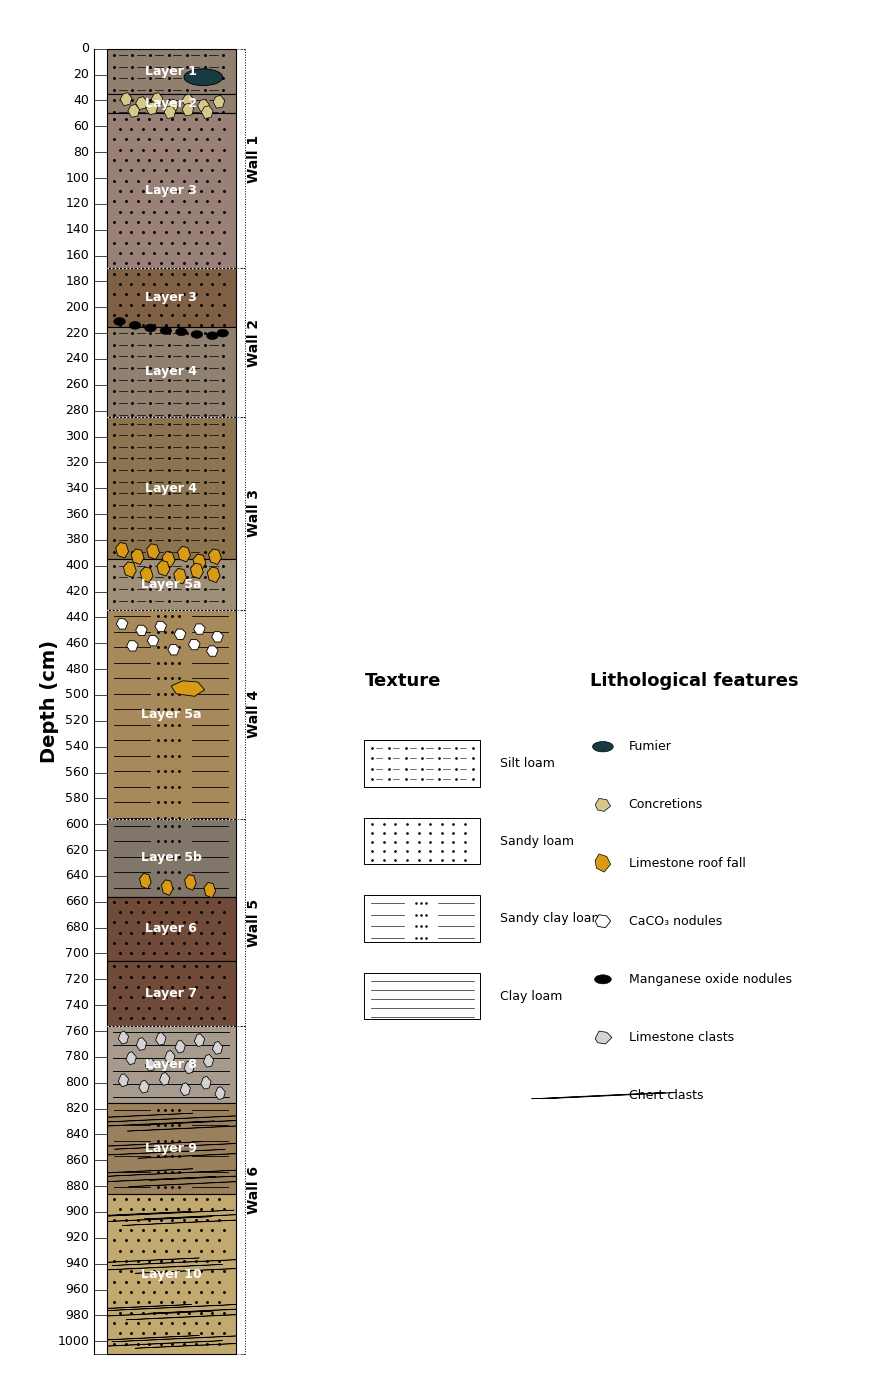

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle, Polygon, Ellipse


# ============================================================
# AZYKH CAVE — COMPLETE LITHOLOGICAL LOG
# Depth = 0–1010 cm
# ============================================================


# ============================================================
# 1. LAYER DATA
# ============================================================

layers = [
    (0,    35,   "#8F806F", "Silt loam",       "Layer 1"),
    (35,   50,   "#8F806F", "Silt loam",       "Layer 2"),
    (50,   170,  "#9A8178", "Sandy loam",      "Layer 3"),

    (170,  215,  "#806044", "Sandy loam",      "Layer 3"),
    (215,  285,  "#8F806F", "Silt loam",       "Layer 4"),

    (285,  395,  "#8B744F", "Silt loam",       "Layer 4"),
    (395,  434,  "#A08F78", "Silt loam",       "Layer 5a"),

    (434,  596,  "#A88A5A", "Sandy clay loam", "Layer 5a"),

    (596,  656,  "#81766A", "Sandy clay loam", "Layer 5b"),
    (656,  706,  "#704B3A", "Sandy loam",      "Layer 6"),
    (706,  756,  "#704B3A", "Sandy loam",      "Layer 7"),

    (756,  816,  "#A69B8C", "Clay loam",       "Layer 8"),
    (816,  886,  "#9B805D", "Sandy clay loam", "Layer 9"),
    (886, 1010,  "#C1A96F", "Sandy loam",      "Layer 10"),
]


# ============================================================
# 2. WALL DATA
# ============================================================

walls = [
    (0,    170,  "Wall 1"),
    (170,  285,  "Wall 2"),
    (285,  434,  "Wall 3"),
    (434,  596,  "Wall 4"),
    (596,  756,  "Wall 5"),
    (756, 1010,  "Wall 6"),
]


# ============================================================
# 3. FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(9, 14))

log_x = 0
log_width = 1.0


# ============================================================
# 4. CLIPPING AREA
# ============================================================

clip_box = Rectangle(
    (log_x, 0),
    log_width,
    1010,
    transform=ax.transData
)


# ============================================================
# 5. TEXTURE FUNCTION
# ============================================================

def draw_texture(ax, left, right, top, bottom, texture):

    # --------------------------------------------------------
    # SILT LOAM
    # dot + short dash
    # --------------------------------------------------------

    if texture == "Silt loam":

        for y in np.arange(top + 5, bottom, 9):

            xpos = left + 0.06

            while xpos < right - 0.05:

                p, = ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.2,
                    color="black",
                    zorder=3
                )

                p.set_clip_path(clip_box)

                if xpos + 0.10 < right:

                    p, = ax.plot(
                        [xpos + 0.035, xpos + 0.10],
                        [y, y],
                        color="black",
                        linewidth=0.5,
                        zorder=3
                    )

                    p.set_clip_path(clip_box)

                xpos += 0.14


    # --------------------------------------------------------
    # SANDY LOAM
    # dots
    # --------------------------------------------------------

    elif texture == "Sandy loam":

        row = 0

        for y in np.arange(top + 4, bottom, 8):

            offset = 0.04 if row % 2 else 0

            for xpos in np.arange(
                left + 0.06 + offset,
                right - 0.04,
                0.09
            ):

                p, = ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.2,
                    color="black",
                    zorder=3
                )

                p.set_clip_path(clip_box)

            row += 1


    # --------------------------------------------------------
    # SANDY CLAY LOAM
    # line + dots + line
    # --------------------------------------------------------

    elif texture == "Sandy clay loam":

        for y in np.arange(top + 5, bottom, 12):

            p, = ax.plot(
                [left + 0.06, left + 0.34],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            p.set_clip_path(clip_box)

            for xpos in np.arange(
                left + 0.40,
                left + 0.61,
                0.055
            ):

                p, = ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.1,
                    color="black",
                    zorder=3
                )

                p.set_clip_path(clip_box)

            p, = ax.plot(
                [left + 0.66, right - 0.06],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            p.set_clip_path(clip_box)


    # --------------------------------------------------------
    # CLAY LOAM
    # horizontal lines
    # --------------------------------------------------------

    elif texture == "Clay loam":

        for y in np.arange(top + 5, bottom, 10):

            p, = ax.plot(
                [left + 0.05, right - 0.05],
                [y, y],
                color="black",
                linewidth=0.65,
                zorder=3
            )

            p.set_clip_path(clip_box)


# ============================================================
# 6. DRAW MAIN LOG
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    rect = Rectangle(
        (log_x, top),
        log_width,
        bottom - top,
        facecolor=colour,
        edgecolor="black",
        linewidth=0.8,
        zorder=1
    )

    ax.add_patch(rect)

    draw_texture(
        ax,
        log_x,
        log_x + log_width,
        top,
        bottom,
        texture
    )


# ============================================================
# 7. SYMBOL FUNCTIONS
# ============================================================


# ------------------------------------------------------------
# FUMIER
# ------------------------------------------------------------

def fumier_symbol(ax, xc, yc):

    e = Ellipse(
        (xc, yc),
        width=0.30,
        height=13,
        facecolor="#173A43",
        edgecolor="black",
        linewidth=0.6,
        zorder=10
    )

    ax.add_patch(e)
    e.set_clip_path(clip_box)


# ------------------------------------------------------------
# CONCRETIONS
# ------------------------------------------------------------

def concretion_symbol(ax, xc, yc, size=0.045):

    p = Polygon(
        [
            (xc - size,       yc),
            (xc - size*0.50,  yc - 4),
            (xc + size*0.30,  yc - 5),
            (xc + size,       yc - 1),
            (xc + size*0.70,  yc + 4),
            (xc - size*0.40,  yc + 5)
        ],
        closed=True,
        facecolor="#D8C78B",
        edgecolor="black",
        linewidth=0.5,
        zorder=10
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# LIMESTONE ROOF FALL
# ------------------------------------------------------------

def limestone_roof_fall(ax, xc, yc, size=0.05):

    p = Polygon(
        [
            (xc - size,       yc - 2),
            (xc - size*0.30,  yc - 6),
            (xc + size*0.60,  yc - 5),
            (xc + size,       yc + 1),
            (xc + size*0.40,  yc + 6),
            (xc - size*0.70,  yc + 4)
        ],
        closed=True,
        facecolor="#D89B16",
        edgecolor="black",
        linewidth=0.6,
        zorder=10
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# CALCIUM CARBONATE NODULE
# ------------------------------------------------------------

def carbonate_nodule(ax, xc, yc, size=0.045):

    p = Polygon(
        [
            (xc - size,       yc),
            (xc - size*0.55,  yc - 4),
            (xc + size*0.35,  yc - 4),
            (xc + size,       yc - 1),
            (xc + size*0.55,  yc + 4),
            (xc - size*0.45,  yc + 4)
        ],
        closed=True,
        facecolor="white",
        edgecolor="black",
        linewidth=0.6,
        zorder=10
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# MANGANESE OXIDE NODULE
# ------------------------------------------------------------

def manganese_symbol(ax, xc, yc):

    e = Ellipse(
        (xc, yc),
        width=0.09,
        height=6,
        facecolor="black",
        edgecolor="black",
        linewidth=0.4,
        zorder=10
    )

    ax.add_patch(e)
    e.set_clip_path(clip_box)


# ------------------------------------------------------------
# LIMESTONE CLAST
# ------------------------------------------------------------

def limestone_clast(ax, xc, yc, size=0.045):

    p = Polygon(
        [
            (xc - size,       yc + 1),
            (xc - size*0.50,  yc - 4),
            (xc + size*0.15,  yc - 5),
            (xc + size,       yc - 1),
            (xc + size*0.65,  yc + 4),
            (xc - size*0.30,  yc + 5)
        ],
        closed=True,
        facecolor="lightgray",
        edgecolor="black",
        linewidth=0.55,
        zorder=12
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# CHERT CLAST
# ------------------------------------------------------------

def chert_clast(ax, xc, yc, size=0.075):

    e = Ellipse(
        (xc, yc),
        width=size,
        height=5,
        angle=12,
        facecolor="dimgray",
        edgecolor="black",
        linewidth=0.45,
        zorder=12
    )

    ax.add_patch(e)
    e.set_clip_path(clip_box)


# ============================================================
# 8. WALL 1
# Fumier + concretions
# ============================================================

fumier_symbol(
    ax,
    0.75,
    22
)


for xpos, ypos in [

    (0.15, 39),
    (0.27, 42),
    (0.39, 39),
    (0.51, 44),
    (0.63, 40),
    (0.75, 44),
    (0.87, 41),

    (0.21, 48),
    (0.35, 46),
    (0.49, 49),
    (0.63, 47),
    (0.78, 49)

]:

    concretion_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 9. WALL 2
# Manganese oxide nodules
# ============================================================

for xpos, ypos in [

    (0.10, 211),
    (0.22, 214),
    (0.34, 216),
    (0.46, 218),
    (0.58, 219),
    (0.70, 221),
    (0.82, 222),
    (0.90, 220)

]:

    manganese_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 10. WALL 3
# Limestone roof fall
# ============================================================

for xpos, ypos in [

    (0.12, 388),
    (0.24, 393),
    (0.36, 389),
    (0.48, 395),
    (0.60, 391),
    (0.72, 397),
    (0.84, 393),

    (0.18, 403),
    (0.31, 407),
    (0.44, 402),
    (0.57, 408),
    (0.70, 404),
    (0.83, 407)

]:

    limestone_roof_fall(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 11. WALL 4
# CaCO3 nodules + limestone roof fall
# ============================================================

for xpos, ypos in [

    (0.12, 445),
    (0.27, 450),
    (0.42, 447),
    (0.57, 453),
    (0.72, 449),
    (0.86, 455),

    (0.20, 462),
    (0.36, 458),
    (0.52, 465),
    (0.68, 461),
    (0.82, 466)

]:

    carbonate_nodule(
        ax,
        xpos,
        ypos
    )


limestone_roof_fall(
    ax,
    0.63,
    495,
    size=0.13
)


# ============================================================
# 12. WALL 5
# Limestone roof fall
# ============================================================

for xpos, ypos in [

    (0.30, 644),
    (0.47, 649),
    (0.65, 645),
    (0.80, 651)

]:

    limestone_roof_fall(
        ax,
        xpos,
        ypos,
        size=0.045
    )


# ============================================================
# 13. WALL 6
# ============================================================


# ============================================================
# LAYER 8 — 756–816 cm
# LIMESTONE CLASTS ONLY
# ============================================================

for xpos, ypos in [

    (0.13, 765),
    (0.27, 770),
    (0.42, 766),
    (0.57, 772),
    (0.72, 767),
    (0.86, 773),

    (0.19, 781),
    (0.34, 786),
    (0.49, 780),
    (0.64, 788),
    (0.79, 783),

    (0.13, 798),
    (0.29, 803),
    (0.45, 797),
    (0.61, 805),
    (0.77, 800),
    (0.88, 808)

]:

    limestone_clast(
        ax,
        xpos,
        ypos,
        size=0.040
    )


# ============================================================
# LAYER 9 — 816–886 cm
# CHERT CLASTS
# ============================================================

for xpos, ypos in [

    (0.15, 826),
    (0.32, 832),
    (0.50, 828),
    (0.68, 835),
    (0.84, 830),

    (0.22, 848),
    (0.40, 854),
    (0.58, 849),
    (0.76, 856),

    (0.15, 869),
    (0.33, 875),
    (0.51, 870),
    (0.69, 878),
    (0.85, 873)

]:

    chert_clast(
        ax,
        xpos,
        ypos,
        size=0.065
    )


# ============================================================
# LAYER 10 — 886–1010 cm
# CHERT CLASTS
# ============================================================


# ------------------------------------------------------------
# UPPER CHERT HORIZON
# ------------------------------------------------------------

for xpos, ypos in [

    (0.14, 902),
    (0.30, 906),
    (0.47, 901),
    (0.64, 908),
    (0.81, 903)

]:

    chert_clast(
        ax,
        xpos,
        ypos,
        size=0.065
    )


# ------------------------------------------------------------
# SECOND CHERT HORIZON
# ------------------------------------------------------------

for xpos, ypos in [

    (0.20, 938),
    (0.38, 943),
    (0.56, 939),
    (0.74, 945)

]:

    chert_clast(
        ax,
        xpos,
        ypos,
        size=0.065
    )


# ------------------------------------------------------------
# THIRD CHERT HORIZON
# ------------------------------------------------------------

for xpos, ypos in [

    (0.14, 974),
    (0.31, 979),
    (0.49, 974),
    (0.67, 981),
    (0.84, 976)

]:

    chert_clast(
        ax,
        xpos,
        ypos,
        size=0.065
    )


# ------------------------------------------------------------
# BASAL CHERT HORIZON
# ------------------------------------------------------------

for xpos, ypos in [

    (0.20, 998),
    (0.38, 1002),
    (0.56, 998),
    (0.74, 1003)

]:

    chert_clast(
        ax,
        xpos,
        ypos,
        size=0.065
    )


# ============================================================
# 14. LAYER LABELS
# ALL HORIZONTAL
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    midpoint = (top + bottom) / 2

    ax.text(
        0.50,
        midpoint,
        layer_name,
        color="white",
        fontsize=9,
        fontweight="bold",
        ha="center",
        va="center",
        rotation=0,
        zorder=30
    )


# ============================================================
# 15. WALL BRACKETS
# Small + dotted + outside log
# ============================================================

wall_x = 1.07
bracket_width = 0.025


for top, bottom, wall_name in walls:

    midpoint = (top + bottom) / 2

    # Vertical dotted line
    ax.plot(
        [wall_x, wall_x],
        [top, bottom],
        color="black",
        linewidth=0.7,
        linestyle=":",
        zorder=15
    )

    # Top bracket
    ax.plot(
        [wall_x - bracket_width, wall_x],
        [top, top],
        color="black",
        linewidth=0.7,
        linestyle=":",
        zorder=15
    )

    # Bottom bracket
    ax.plot(
        [wall_x - bracket_width, wall_x],
        [bottom, bottom],
        color="black",
        linewidth=0.7,
        linestyle=":",
        zorder=15
    )

    # Wall name
    ax.text(
        wall_x + 0.07,
        midpoint,
        wall_name,
        fontsize=10,
        fontweight="bold",
        rotation=90,
        ha="center",
        va="center",
        zorder=20
    )


# ============================================================
# 16. WALL CONNECTORS
# ============================================================

for depth in [
    0,
    170,
    285,
    434,
    596,
    756,
    1010
]:

    ax.plot(
        [1.0, wall_x],
        [depth, depth],
        color="black",
        linewidth=0.55,
        linestyle=":",
        zorder=14
    )


# ============================================================
# 17. WALL BOUNDARIES INSIDE LOG
# ============================================================

for depth in [
    170,
    285,
    434,
    596,
    756
]:

    ax.plot(
        [0, 1],
        [depth, depth],
        color="white",
        linewidth=1,
        linestyle=":",
        zorder=20
    )


# ============================================================
# 18. DEPTH SCALE
# ============================================================

scale_x = -0.10


ax.plot(
    [scale_x, scale_x],
    [0, 1010],
    color="black",
    linewidth=0.8
)


for depth in range(0, 1001, 20):

    # Short tick from scale to log
    ax.plot(
        [scale_x, 0],
        [depth, depth],
        color="black",
        linewidth=0.5
    )

    # Number outside scale
    ax.text(
        scale_x - 0.035,
        depth,
        str(depth),
        fontsize=9,
        ha="right",
        va="center"
    )


# 1010 boundary without number
ax.plot(
    [scale_x, 0],
    [1010, 1010],
    color="black",
    linewidth=0.5
)


ax.text(
    scale_x - 0.34,
    505,
    "Depth (cm)",
    rotation=90,
    fontsize=14,
    fontweight="bold",
    ha="center",
    va="center"
)


# ============================================================
# 19. TEXTURE LEGEND
# ============================================================

texture_x = 2.00
legend_y = 505


ax.text(
    texture_x,
    legend_y - 12,
    "Texture",
    fontsize=13,
    fontweight="bold",
    ha="left"
)


texture_items = [
    ("Silt loam",       30),
    ("Sandy loam",      90),
    ("Sandy clay loam", 150),
    ("Clay loam",       210)
]


legend_box_w = 0.90
legend_box_h = 36


for texture, offset in texture_items:

    top = legend_y + offset
    bottom = top + legend_box_h

    box = Rectangle(
        (texture_x, top),
        legend_box_w,
        legend_box_h,
        facecolor="white",
        edgecolor="black",
        linewidth=0.7,
        zorder=40
    )

    ax.add_patch(box)


    # --------------------------------------------------------
    # SILT LOAM
    # --------------------------------------------------------

    if texture == "Silt loam":

        for yy in np.arange(top + 6, bottom, 8):

            xx = texture_x + 0.06

            while xx < texture_x + legend_box_w - 0.05:

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.8,
                    color="black",
                    zorder=42
                )

                if xx + 0.09 < texture_x + legend_box_w:

                    ax.plot(
                        [xx + 0.03, xx + 0.08],
                        [yy, yy],
                        color="black",
                        linewidth=0.4,
                        zorder=42
                    )

                xx += 0.13


    # --------------------------------------------------------
    # SANDY LOAM
    # --------------------------------------------------------

    elif texture == "Sandy loam":

        for yy in np.arange(top + 5, bottom, 7):

            for xx in np.arange(
                texture_x + 0.06,
                texture_x + legend_box_w - 0.04,
                0.09
            ):

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.8,
                    color="black",
                    zorder=42
                )


    # --------------------------------------------------------
    # SANDY CLAY LOAM
    # --------------------------------------------------------

    elif texture == "Sandy clay loam":

        for yy in np.arange(top + 6, bottom, 9):

            ax.plot(
                [
                    texture_x + 0.05,
                    texture_x + 0.31
                ],
                [yy, yy],
                color="black",
                linewidth=0.45,
                zorder=42
            )

            for xx in [
                texture_x + 0.40,
                texture_x + 0.44,
                texture_x + 0.48
            ]:

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.6,
                    color="black",
                    zorder=42
                )

            ax.plot(
                [
                    texture_x + 0.57,
                    texture_x + 0.85
                ],
                [yy, yy],
                color="black",
                linewidth=0.45,
                zorder=42
            )


    # --------------------------------------------------------
    # CLAY LOAM
    # --------------------------------------------------------

    elif texture == "Clay loam":

        for yy in np.arange(top + 6, bottom, 7):

            ax.plot(
                [
                    texture_x + 0.05,
                    texture_x + 0.85
                ],
                [yy, yy],
                color="black",
                linewidth=0.45,
                zorder=42
            )


    ax.text(
        texture_x + 1.05,
        (top + bottom) / 2,
        texture,
        fontsize=9,
        ha="left",
        va="center"
    )


# ============================================================
# 20. LITHOLOGICAL FEATURES LEGEND
# ============================================================

feature_x = 3.75
feature_text_x = 4.05


ax.text(
    feature_x,
    legend_y - 12,
    "Lithological features",
    fontsize=13,
    fontweight="bold",
    ha="left"
)


# ------------------------------------------------------------
# FUMIER
# ------------------------------------------------------------

yy = legend_y + 35

e = Ellipse(
    (feature_x + 0.10, yy),
    width=0.16,
    height=8,
    facecolor="#173A43",
    edgecolor="black",
    linewidth=0.5,
    zorder=40
)

ax.add_patch(e)

ax.text(
    feature_text_x,
    yy,
    "Fumier",
    fontsize=9,
    va="center"
)


# ------------------------------------------------------------
# CONCRETIONS
# ------------------------------------------------------------

yy = legend_y + 80

p = Polygon(
    [
        (feature_x + 0.04, yy),
        (feature_x + 0.07, yy - 5),
        (feature_x + 0.13, yy - 4),
        (feature_x + 0.16, yy + 1),
        (feature_x + 0.11, yy + 5),
        (feature_x + 0.06, yy + 4)
    ],
    closed=True,
    facecolor="#D8C78B",
    edgecolor="black",
    linewidth=0.5,
    zorder=40
)

ax.add_patch(p)

ax.text(
    feature_text_x,
    yy,
    "Concretions",
    fontsize=9,
    va="center"
)


# ------------------------------------------------------------
# LIMESTONE ROOF FALL
# ------------------------------------------------------------

yy = legend_y + 125

p = Polygon(
    [
        (feature_x + 0.04, yy - 2),
        (feature_x + 0.07, yy - 7),
        (feature_x + 0.13, yy - 5),
        (feature_x + 0.16, yy + 1),
        (feature_x + 0.11, yy + 7),
        (feature_x + 0.05, yy + 4)
    ],
    closed=True,
    facecolor="#D89B16",
    edgecolor="black",
    linewidth=0.5,
    zorder=40
)

ax.add_patch(p)

ax.text(
    feature_text_x,
    yy,
    "Limestone roof fall",
    fontsize=9,
    va="center"
)


# ------------------------------------------------------------
# CaCO3 NODULES
# ------------------------------------------------------------

yy = legend_y + 170

p = Polygon(
    [
        (feature_x + 0.04, yy),
        (feature_x + 0.07, yy - 5),
        (feature_x + 0.13, yy - 4),
        (feature_x + 0.16, yy),
        (feature_x + 0.12, yy + 5),
        (feature_x + 0.06, yy + 4)
    ],
    closed=True,
    facecolor="white",
    edgecolor="black",
    linewidth=0.6,
    zorder=40
)

ax.add_patch(p)

ax.text(
    feature_text_x,
    yy,
    "CaCO₃ nodules",
    fontsize=9,
    va="center"
)


# ------------------------------------------------------------
# MANGANESE OXIDE NODULES
# ------------------------------------------------------------

yy = legend_y + 215

e = Ellipse(
    (feature_x + 0.10, yy),
    width=0.13,
    height=7,
    facecolor="black",
    edgecolor="black",
    linewidth=0.4,
    zorder=40
)

ax.add_patch(e)

ax.text(
    feature_text_x,
    yy,
    "Manganese oxide nodules",
    fontsize=9,
    va="center"
)


# ------------------------------------------------------------
# LIMESTONE CLASTS
# ------------------------------------------------------------

yy = legend_y + 260

p = Polygon(
    [
        (feature_x + 0.04, yy + 1),
        (feature_x + 0.07, yy - 5),
        (feature_x + 0.13, yy - 4),
        (feature_x + 0.17, yy),
        (feature_x + 0.12, yy + 5),
        (feature_x + 0.06, yy + 4)
    ],
    closed=True,
    facecolor="lightgray",
    edgecolor="black",
    linewidth=0.55,
    zorder=40
)

ax.add_patch(p)

ax.text(
    feature_text_x,
    yy,
    "Limestone clasts",
    fontsize=9,
    va="center"
)


# ------------------------------------------------------------
# CHERT CLASTS
# ------------------------------------------------------------

yy = legend_y + 305

for dx in [
    0.065,
    0.15
]:

    e = Ellipse(
        (feature_x + dx, yy),
        width=0.065,
        height=5,
        angle=12,
        facecolor="dimgray",
        edgecolor="black",
        linewidth=0.4,
        zorder=40
    )

    ax.add_patch(e)


ax.text(
    feature_text_x,
    yy,
    "Chert clasts",
    fontsize=9,
    va="center"
)


# ============================================================
# 21. FINAL FORMAT
# ============================================================

ax.set_xlim(
    -0.75,
    6.0
)

ax.set_ylim(
    1030,
    -30
)

ax.axis("off")

plt.tight_layout()


# ============================================================
# 22. SAVE HIGH-RESOLUTION OUTPUT
# ============================================================

plt.savefig(
    "Azykh_final_complete_log.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Azykh_final_complete_log.pdf",
    bbox_inches="tight"
)


# ============================================================
# 23. SHOW
# ============================================================

plt.show()

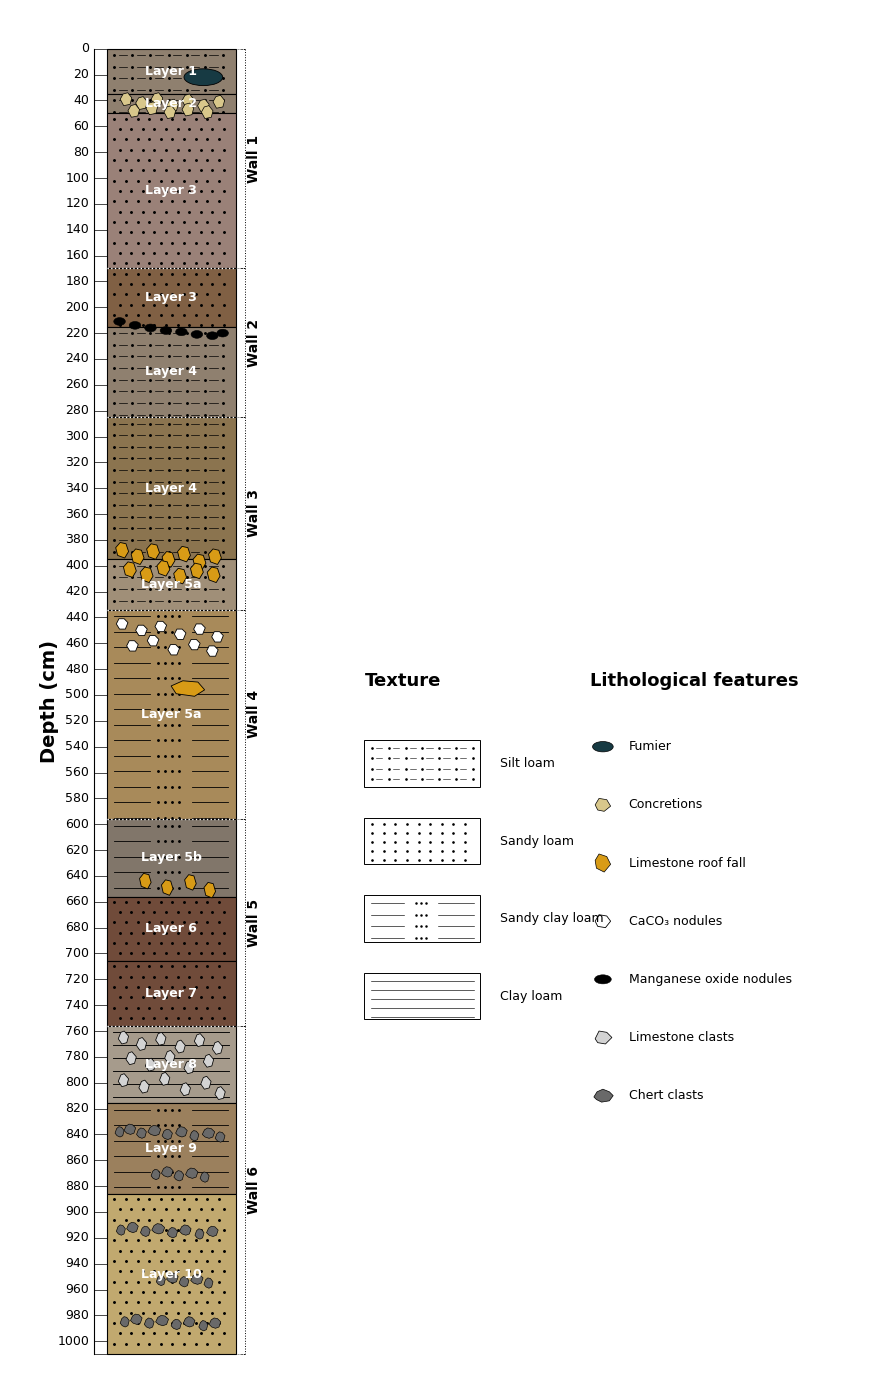

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle, Polygon, Ellipse


# ============================================================
# AZYKH CAVE — COMPLETE LITHOLOGICAL LOG
# Depth: 0–1010 cm
# ============================================================


# ============================================================
# 1. LAYER DATA
# ============================================================

layers = [
    (0,    35,   "#8F806F", "Silt loam",       "Layer 1"),
    (35,   50,   "#8F806F", "Silt loam",       "Layer 2"),
    (50,   170,  "#9A8178", "Sandy loam",      "Layer 3"),

    (170,  215,  "#806044", "Sandy loam",      "Layer 3"),
    (215,  285,  "#8F806F", "Silt loam",       "Layer 4"),

    (285,  395,  "#8B744F", "Silt loam",       "Layer 4"),
    (395,  434,  "#A08F78", "Silt loam",       "Layer 5a"),

    (434,  596,  "#A88A5A", "Sandy clay loam", "Layer 5a"),

    (596,  656,  "#81766A", "Sandy clay loam", "Layer 5b"),
    (656,  706,  "#704B3A", "Sandy loam",      "Layer 6"),
    (706,  756,  "#704B3A", "Sandy loam",      "Layer 7"),

    (756,  816,  "#A69B8C", "Clay loam",       "Layer 8"),
    (816,  886,  "#9B805D", "Sandy clay loam", "Layer 9"),
    (886, 1010,  "#C1A96F", "Sandy loam",      "Layer 10"),
]


# ============================================================
# 2. WALL DATA
# ============================================================

walls = [
    (0,    170,  "Wall 1"),
    (170,  285,  "Wall 2"),
    (285,  434,  "Wall 3"),
    (434,  596,  "Wall 4"),
    (596,  756,  "Wall 5"),
    (756, 1010,  "Wall 6"),
]


# ============================================================
# 3. FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(9, 14))

log_x = 0
log_width = 1.0


# ============================================================
# 4. CLIPPING AREA
# ============================================================

clip_box = Rectangle(
    (log_x, 0),
    log_width,
    1010,
    transform=ax.transData
)


# ============================================================
# 5. TEXTURE FUNCTION
# ============================================================

def draw_texture(ax, left, right, top, bottom, texture):

    # SILT LOAM
    if texture == "Silt loam":

        for y in np.arange(top + 5, bottom, 9):

            xpos = left + 0.06

            while xpos < right - 0.05:

                p, = ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.2,
                    color="black",
                    zorder=3
                )

                p.set_clip_path(clip_box)

                if xpos + 0.10 < right:

                    p, = ax.plot(
                        [xpos + 0.035, xpos + 0.10],
                        [y, y],
                        color="black",
                        linewidth=0.5,
                        zorder=3
                    )

                    p.set_clip_path(clip_box)

                xpos += 0.14


    # SANDY LOAM
    elif texture == "Sandy loam":

        row = 0

        for y in np.arange(top + 4, bottom, 8):

            offset = 0.04 if row % 2 else 0

            for xpos in np.arange(
                left + 0.06 + offset,
                right - 0.04,
                0.09
            ):

                p, = ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.2,
                    color="black",
                    zorder=3
                )

                p.set_clip_path(clip_box)

            row += 1


    # SANDY CLAY LOAM
    elif texture == "Sandy clay loam":

        for y in np.arange(top + 5, bottom, 12):

            p, = ax.plot(
                [left + 0.06, left + 0.34],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            p.set_clip_path(clip_box)

            for xpos in np.arange(
                left + 0.40,
                left + 0.61,
                0.055
            ):

                p, = ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.1,
                    color="black",
                    zorder=3
                )

                p.set_clip_path(clip_box)

            p, = ax.plot(
                [left + 0.66, right - 0.06],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            p.set_clip_path(clip_box)


    # CLAY LOAM
    elif texture == "Clay loam":

        for y in np.arange(top + 5, bottom, 10):

            p, = ax.plot(
                [left + 0.05, right - 0.05],
                [y, y],
                color="black",
                linewidth=0.65,
                zorder=3
            )

            p.set_clip_path(clip_box)


# ============================================================
# 6. DRAW MAIN LOG
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    rect = Rectangle(
        (log_x, top),
        log_width,
        bottom - top,
        facecolor=colour,
        edgecolor="black",
        linewidth=0.8,
        zorder=1
    )

    ax.add_patch(rect)

    draw_texture(
        ax,
        log_x,
        log_x + log_width,
        top,
        bottom,
        texture
    )


# ============================================================
# 7. LITHOLOGICAL SYMBOL FUNCTIONS
# ============================================================


# ------------------------------------------------------------
# FUMIER
# ------------------------------------------------------------

def fumier_symbol(ax, xc, yc):

    e = Ellipse(
        (xc, yc),
        width=0.30,
        height=13,
        facecolor="#173A43",
        edgecolor="black",
        linewidth=0.6,
        zorder=10
    )

    ax.add_patch(e)
    e.set_clip_path(clip_box)


# ------------------------------------------------------------
# CONCRETION
# ------------------------------------------------------------

def concretion_symbol(ax, xc, yc, size=0.045):

    p = Polygon(
        [
            (xc-size, yc),
            (xc-size*0.50, yc-4),
            (xc+size*0.30, yc-5),
            (xc+size, yc-1),
            (xc+size*0.70, yc+4),
            (xc-size*0.40, yc+5)
        ],
        closed=True,
        facecolor="#D8C78B",
        edgecolor="black",
        linewidth=0.5,
        zorder=10
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# LIMESTONE ROOF FALL
# ------------------------------------------------------------

def limestone_roof_fall(ax, xc, yc, size=0.05):

    p = Polygon(
        [
            (xc-size, yc-2),
            (xc-size*0.30, yc-6),
            (xc+size*0.60, yc-5),
            (xc+size, yc+1),
            (xc+size*0.40, yc+6),
            (xc-size*0.70, yc+4)
        ],
        closed=True,
        facecolor="#D89B16",
        edgecolor="black",
        linewidth=0.6,
        zorder=10
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# CaCO3 NODULE
# ------------------------------------------------------------

def carbonate_nodule(ax, xc, yc, size=0.045):

    p = Polygon(
        [
            (xc-size, yc),
            (xc-size*0.55, yc-4),
            (xc+size*0.35, yc-4),
            (xc+size, yc-1),
            (xc+size*0.55, yc+4),
            (xc-size*0.45, yc+4)
        ],
        closed=True,
        facecolor="white",
        edgecolor="black",
        linewidth=0.6,
        zorder=10
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# MANGANESE OXIDE NODULE
# ------------------------------------------------------------

def manganese_symbol(ax, xc, yc):

    e = Ellipse(
        (xc, yc),
        width=0.09,
        height=6,
        facecolor="black",
        edgecolor="black",
        linewidth=0.4,
        zorder=10
    )

    ax.add_patch(e)
    e.set_clip_path(clip_box)


# ------------------------------------------------------------
# LIMESTONE CLAST
# ------------------------------------------------------------

def limestone_clast(ax, xc, yc, size=0.045):

    p = Polygon(
        [
            (xc-size, yc+1),
            (xc-size*0.50, yc-4),
            (xc+size*0.15, yc-5),
            (xc+size, yc-1),
            (xc+size*0.65, yc+4),
            (xc-size*0.30, yc+5)
        ],
        closed=True,
        facecolor="lightgray",
        edgecolor="black",
        linewidth=0.55,
        zorder=12
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# CHERT CLAST
# Irregular dark-grey fragment
# ------------------------------------------------------------

def chert_clast(ax, xc, yc, size=0.045):

    p = Polygon(
        [
            (xc-size,       yc+1),
            (xc-size*0.65,  yc-2.5),
            (xc-size*0.15,  yc-4),
            (xc+size*0.45,  yc-3.5),
            (xc+size,       yc-1),
            (xc+size*0.70,  yc+3),
            (xc+size*0.10,  yc+4),
            (xc-size*0.55,  yc+3)
        ],
        closed=True,
        facecolor="dimgray",
        edgecolor="black",
        linewidth=0.45,
        zorder=12
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ============================================================
# 8. WALL 1
# Fumier + concretions
# ============================================================

fumier_symbol(
    ax,
    0.75,
    22
)


for xpos, ypos in [

    (0.15, 39),
    (0.27, 42),
    (0.39, 39),
    (0.51, 44),
    (0.63, 40),
    (0.75, 44),
    (0.87, 41),

    (0.21, 48),
    (0.35, 46),
    (0.49, 49),
    (0.63, 47),
    (0.78, 49)

]:

    concretion_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 9. WALL 2
# Manganese oxide nodules
# ============================================================

for xpos, ypos in [

    (0.10, 211),
    (0.22, 214),
    (0.34, 216),
    (0.46, 218),
    (0.58, 219),
    (0.70, 221),
    (0.82, 222),
    (0.90, 220)

]:

    manganese_symbol(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 10. WALL 3
# Limestone roof fall
# ============================================================

for xpos, ypos in [

    (0.12, 388),
    (0.24, 393),
    (0.36, 389),
    (0.48, 395),
    (0.60, 391),
    (0.72, 397),
    (0.84, 393),

    (0.18, 403),
    (0.31, 407),
    (0.44, 402),
    (0.57, 408),
    (0.70, 404),
    (0.83, 407)

]:

    limestone_roof_fall(
        ax,
        xpos,
        ypos
    )


# ============================================================
# 11. WALL 4
# CaCO3 nodules + limestone roof fall
# ============================================================

for xpos, ypos in [

    (0.12, 445),
    (0.27, 450),
    (0.42, 447),
    (0.57, 453),
    (0.72, 449),
    (0.86, 455),

    (0.20, 462),
    (0.36, 458),
    (0.52, 465),
    (0.68, 461),
    (0.82, 466)

]:

    carbonate_nodule(
        ax,
        xpos,
        ypos
    )


limestone_roof_fall(
    ax,
    0.63,
    495,
    size=0.13
)


# ============================================================
# 12. WALL 5
# Limestone roof fall
# ============================================================

for xpos, ypos in [

    (0.30, 644),
    (0.47, 649),
    (0.65, 645),
    (0.80, 651)

]:

    limestone_roof_fall(
        ax,
        xpos,
        ypos,
        size=0.045
    )


# ============================================================
# 13. WALL 6
# ============================================================


# ============================================================
# LAYER 8 — 756–816 cm
# LIMESTONE CLASTS
# ============================================================

for xpos, ypos in [

    (0.13, 765),
    (0.27, 770),
    (0.42, 766),
    (0.57, 772),
    (0.72, 767),
    (0.86, 773),

    (0.19, 781),
    (0.34, 786),
    (0.49, 780),
    (0.64, 788),
    (0.79, 783),

    (0.13, 798),
    (0.29, 803),
    (0.45, 797),
    (0.61, 805),
    (0.77, 800),
    (0.88, 808)

]:

    limestone_clast(
        ax,
        xpos,
        ypos,
        size=0.040
    )


# ============================================================
# LAYER 9 — 816–886 cm
# THIN IRREGULAR CHERT CLAST HORIZON 1
# ============================================================

for xpos, ypos, size in [

    (0.10, 838, 0.035),
    (0.18, 836, 0.045),
    (0.27, 839, 0.038),
    (0.37, 837, 0.050),
    (0.47, 840, 0.040),
    (0.58, 838, 0.045),
    (0.68, 841, 0.035),
    (0.79, 839, 0.048),
    (0.88, 842, 0.038)

]:

    chert_clast(
        ax,
        xpos,
        ypos,
        size=size
    )


# ============================================================
# LAYER 9 — THIN IRREGULAR CHERT CLAST HORIZON 2
# Short and discontinuous
# ============================================================

for xpos, ypos, size in [

    (0.38, 871, 0.035),
    (0.47, 869, 0.045),
    (0.56, 872, 0.038),
    (0.66, 870, 0.048),
    (0.76, 873, 0.035)

]:

    chert_clast(
        ax,
        xpos,
        ypos,
        size=size
    )


# ============================================================
# LAYER 10 — 886–1010 cm
# UPPER THIN CHERT CLAST HORIZON
# ============================================================

for xpos, ypos, size in [

    (0.11, 914, 0.035),
    (0.20, 912, 0.045),
    (0.30, 915, 0.038),
    (0.40, 913, 0.050),
    (0.51, 916, 0.040),
    (0.61, 914, 0.045),
    (0.72, 917, 0.035),
    (0.82, 915, 0.045)

]:

    chert_clast(
        ax,
        xpos,
        ypos,
        size=size
    )


# ============================================================
# LAYER 10 — MIDDLE SHORT CHERT CLAST HORIZON
# ============================================================

for xpos, ypos, size in [

    (0.42, 953, 0.035),
    (0.51, 951, 0.045),
    (0.60, 954, 0.038),
    (0.70, 952, 0.048),
    (0.79, 955, 0.035)

]:

    chert_clast(
        ax,
        xpos,
        ypos,
        size=size
    )


# ============================================================
# LAYER 10 — LOWER THIN CHERT CLAST HORIZON
# ============================================================

for xpos, ypos, size in [

    (0.14, 985, 0.035),
    (0.23, 983, 0.045),
    (0.33, 986, 0.038),
    (0.43, 984, 0.050),
    (0.54, 987, 0.040),
    (0.64, 985, 0.045),
    (0.75, 988, 0.035),
    (0.84, 986, 0.045)

]:

    chert_clast(
        ax,
        xpos,
        ypos,
        size=size
    )


# ============================================================
# 14. LAYER LABELS
# All horizontal
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    midpoint = (top + bottom) / 2

    ax.text(
        0.50,
        midpoint,
        layer_name,
        color="white",
        fontsize=9,
        fontweight="bold",
        ha="center",
        va="center",
        rotation=0,
        zorder=30
    )


# ============================================================
# 15. WALL BRACKETS
# Small, dotted, outside log
# ============================================================

wall_x = 1.07
bracket_width = 0.025


for top, bottom, wall_name in walls:

    midpoint = (top + bottom) / 2

    ax.plot(
        [wall_x, wall_x],
        [top, bottom],
        color="black",
        linewidth=0.7,
        linestyle=":",
        zorder=15
    )

    ax.plot(
        [wall_x - bracket_width, wall_x],
        [top, top],
        color="black",
        linewidth=0.7,
        linestyle=":",
        zorder=15
    )

    ax.plot(
        [wall_x - bracket_width, wall_x],
        [bottom, bottom],
        color="black",
        linewidth=0.7,
        linestyle=":",
        zorder=15
    )

    ax.text(
        wall_x + 0.07,
        midpoint,
        wall_name,
        fontsize=10,
        fontweight="bold",
        rotation=90,
        ha="center",
        va="center",
        zorder=20
    )


# ============================================================
# 16. WALL CONNECTOR LINES
# ============================================================

for depth in [
    0,
    170,
    285,
    434,
    596,
    756,
    1010
]:

    ax.plot(
        [1.0, wall_x],
        [depth, depth],
        color="black",
        linewidth=0.55,
        linestyle=":",
        zorder=14
    )


# ============================================================
# 17. WALL BOUNDARIES INSIDE LOG
# ============================================================

for depth in [
    170,
    285,
    434,
    596,
    756
]:

    ax.plot(
        [0, 1],
        [depth, depth],
        color="white",
        linewidth=1.0,
        linestyle=":",
        zorder=20
    )


# ============================================================
# 18. DEPTH SCALE
# ============================================================

scale_x = -0.10


ax.plot(
    [scale_x, scale_x],
    [0, 1010],
    color="black",
    linewidth=0.8
)


for depth in range(0, 1001, 20):

    ax.plot(
        [scale_x, 0],
        [depth, depth],
        color="black",
        linewidth=0.5
    )

    ax.text(
        scale_x - 0.035,
        depth,
        str(depth),
        fontsize=9,
        ha="right",
        va="center"
    )


# Bottom 1010 boundary — no number
ax.plot(
    [scale_x, 0],
    [1010, 1010],
    color="black",
    linewidth=0.5
)


ax.text(
    scale_x - 0.34,
    505,
    "Depth (cm)",
    rotation=90,
    fontsize=14,
    fontweight="bold",
    ha="center",
    va="center"
)


# ============================================================
# 19. TEXTURE LEGEND
# ============================================================

texture_x = 2.00
legend_y = 505


ax.text(
    texture_x,
    legend_y - 12,
    "Texture",
    fontsize=13,
    fontweight="bold",
    ha="left"
)


texture_items = [
    ("Silt loam",       30),
    ("Sandy loam",      90),
    ("Sandy clay loam", 150),
    ("Clay loam",       210)
]


legend_box_w = 0.90
legend_box_h = 36


for texture, offset in texture_items:

    top = legend_y + offset
    bottom = top + legend_box_h

    box = Rectangle(
        (texture_x, top),
        legend_box_w,
        legend_box_h,
        facecolor="white",
        edgecolor="black",
        linewidth=0.7,
        zorder=40
    )

    ax.add_patch(box)


    # SILT LOAM
    if texture == "Silt loam":

        for yy in np.arange(top + 6, bottom, 8):

            xx = texture_x + 0.06

            while xx < texture_x + legend_box_w - 0.05:

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.8,
                    color="black",
                    zorder=42
                )

                if xx + 0.09 < texture_x + legend_box_w:

                    ax.plot(
                        [xx + 0.03, xx + 0.08],
                        [yy, yy],
                        color="black",
                        linewidth=0.4,
                        zorder=42
                    )

                xx += 0.13


    # SANDY LOAM
    elif texture == "Sandy loam":

        for yy in np.arange(top + 5, bottom, 7):

            for xx in np.arange(
                texture_x + 0.06,
                texture_x + legend_box_w - 0.04,
                0.09
            ):

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.8,
                    color="black",
                    zorder=42
                )


    # SANDY CLAY LOAM
    elif texture == "Sandy clay loam":

        for yy in np.arange(top + 6, bottom, 9):

            ax.plot(
                [
                    texture_x + 0.05,
                    texture_x + 0.31
                ],
                [yy, yy],
                color="black",
                linewidth=0.45,
                zorder=42
            )

            for xx in [
                texture_x + 0.40,
                texture_x + 0.44,
                texture_x + 0.48
            ]:

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.6,
                    color="black",
                    zorder=42
                )

            ax.plot(
                [
                    texture_x + 0.57,
                    texture_x + 0.85
                ],
                [yy, yy],
                color="black",
                linewidth=0.45,
                zorder=42
            )


    # CLAY LOAM
    elif texture == "Clay loam":

        for yy in np.arange(top + 6, bottom, 7):

            ax.plot(
                [
                    texture_x + 0.05,
                    texture_x + 0.85
                ],
                [yy, yy],
                color="black",
                linewidth=0.45,
                zorder=42
            )


    ax.text(
        texture_x + 1.05,
        (top + bottom) / 2,
        texture,
        fontsize=9,
        ha="left",
        va="center"
    )


# ============================================================
# 20. LITHOLOGICAL FEATURES LEGEND
# ============================================================

feature_x = 3.75
feature_text_x = 4.05


ax.text(
    feature_x,
    legend_y - 12,
    "Lithological features",
    fontsize=13,
    fontweight="bold",
    ha="left"
)


# ------------------------------------------------------------
# FUMIER
# ------------------------------------------------------------

yy = legend_y + 35

e = Ellipse(
    (feature_x + 0.10, yy),
    width=0.16,
    height=8,
    facecolor="#173A43",
    edgecolor="black",
    linewidth=0.5,
    zorder=40
)

ax.add_patch(e)

ax.text(
    feature_text_x,
    yy,
    "Fumier",
    fontsize=9,
    va="center"
)


# ------------------------------------------------------------
# CONCRETIONS
# ------------------------------------------------------------

yy = legend_y + 80

p = Polygon(
    [
        (feature_x + 0.04, yy),
        (feature_x + 0.07, yy - 5),
        (feature_x + 0.13, yy - 4),
        (feature_x + 0.16, yy + 1),
        (feature_x + 0.11, yy + 5),
        (feature_x + 0.06, yy + 4)
    ],
    closed=True,
    facecolor="#D8C78B",
    edgecolor="black",
    linewidth=0.5
)

ax.add_patch(p)

ax.text(
    feature_text_x,
    yy,
    "Concretions",
    fontsize=9,
    va="center"
)


# ------------------------------------------------------------
# LIMESTONE ROOF FALL
# ------------------------------------------------------------

yy = legend_y + 125

p = Polygon(
    [
        (feature_x + 0.04, yy - 2),
        (feature_x + 0.07, yy - 7),
        (feature_x + 0.13, yy - 5),
        (feature_x + 0.16, yy + 1),
        (feature_x + 0.11, yy + 7),
        (feature_x + 0.05, yy + 4)
    ],
    closed=True,
    facecolor="#D89B16",
    edgecolor="black",
    linewidth=0.5
)

ax.add_patch(p)

ax.text(
    feature_text_x,
    yy,
    "Limestone roof fall",
    fontsize=9,
    va="center"
)


# ------------------------------------------------------------
# CaCO3 NODULES
# ------------------------------------------------------------

yy = legend_y + 170

p = Polygon(
    [
        (feature_x + 0.04, yy),
        (feature_x + 0.07, yy - 5),
        (feature_x + 0.13, yy - 4),
        (feature_x + 0.16, yy),
        (feature_x + 0.12, yy + 5),
        (feature_x + 0.06, yy + 4)
    ],
    closed=True,
    facecolor="white",
    edgecolor="black",
    linewidth=0.6
)

ax.add_patch(p)

ax.text(
    feature_text_x,
    yy,
    "CaCO₃ nodules",
    fontsize=9,
    va="center"
)


# ------------------------------------------------------------
# MANGANESE OXIDE NODULES
# ------------------------------------------------------------

yy = legend_y + 215

e = Ellipse(
    (feature_x + 0.10, yy),
    width=0.13,
    height=7,
    facecolor="black",
    edgecolor="black",
    linewidth=0.4
)

ax.add_patch(e)

ax.text(
    feature_text_x,
    yy,
    "Manganese oxide nodules",
    fontsize=9,
    va="center"
)


# ------------------------------------------------------------
# LIMESTONE CLASTS
# ------------------------------------------------------------

yy = legend_y + 260

p = Polygon(
    [
        (feature_x + 0.04, yy + 1),
        (feature_x + 0.07, yy - 5),
        (feature_x + 0.13, yy - 4),
        (feature_x + 0.17, yy),
        (feature_x + 0.12, yy + 5),
        (feature_x + 0.06, yy + 4)
    ],
    closed=True,
    facecolor="lightgray",
    edgecolor="black",
    linewidth=0.55
)

ax.add_patch(p)

ax.text(
    feature_text_x,
    yy,
    "Limestone clasts",
    fontsize=9,
    va="center"
)


# ------------------------------------------------------------
# CHERT CLASTS
# Irregular dark-grey fragment
# ------------------------------------------------------------

yy = legend_y + 305

p = Polygon(
    [
        (feature_x + 0.03, yy + 1),
        (feature_x + 0.055, yy - 3),
        (feature_x + 0.10, yy - 5),
        (feature_x + 0.15, yy - 3),
        (feature_x + 0.18, yy),
        (feature_x + 0.15, yy + 4),
        (feature_x + 0.09, yy + 5),
        (feature_x + 0.05, yy + 3)
    ],
    closed=True,
    facecolor="dimgray",
    edgecolor="black",
    linewidth=0.5
)

ax.add_patch(p)

ax.text(
    feature_text_x,
    yy,
    "Chert clasts",
    fontsize=9,
    va="center"
)


# ============================================================
# 21. FINAL FORMAT
# ============================================================

ax.set_xlim(
    -0.75,
    6.0
)

ax.set_ylim(
    1030,
    -30
)

ax.axis("off")

plt.tight_layout()


# ============================================================
# 22. SAVE
# ============================================================

plt.savefig(
    "Azykh_final_lithological_log.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Azykh_final_lithological_log.pdf",
    bbox_inches="tight"
)


# ============================================================
# 23. SHOW
# ============================================================

plt.show()

In [ ]:
# ============================================================
# 19. COMPACT COMBINED LEGEND
# ============================================================

# Position of legend
legend_x = 1.75
legend_y = 500

# Small outer legend box
box_x = legend_x - 0.12
box_y = legend_y - 18
box_width = 3.45
box_height = 325

legend_outer = Rectangle(
    (box_x, box_y),
    box_width,
    box_height,
    facecolor="white",
    edgecolor="black",
    linewidth=0.7,
    zorder=35
)

ax.add_patch(legend_outer)


# ============================================================
# LEFT COLUMN — TEXTURES
# ============================================================

texture_x = legend_x
texture_text_x = legend_x + 0.90

texture_items = [
    ("Silt loam",       15),
    ("Sandy loam",      75),
    ("Sandy clay loam", 135),
    ("Clay loam",       195)
]

sample_w = 0.72
sample_h = 32


for texture, offset in texture_items:

    top = legend_y + offset
    bottom = top + sample_h

    # Small sample box
    sample_box = Rectangle(
        (texture_x, top),
        sample_w,
        sample_h,
        facecolor="white",
        edgecolor="black",
        linewidth=0.6,
        zorder=40
    )

    ax.add_patch(sample_box)


    # --------------------------------------------------------
    # SILT LOAM
    # --------------------------------------------------------

    if texture == "Silt loam":

        for yy in np.arange(top + 6, bottom, 8):

            xx = texture_x + 0.05

            while xx < texture_x + sample_w - 0.04:

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.6,
                    color="black",
                    zorder=42
                )

                if xx + 0.08 < texture_x + sample_w:

                    ax.plot(
                        [xx + 0.025, xx + 0.07],
                        [yy, yy],
                        color="black",
                        linewidth=0.4,
                        zorder=42
                    )

                xx += 0.12


    # --------------------------------------------------------
    # SANDY LOAM
    # --------------------------------------------------------

    elif texture == "Sandy loam":

        for yy in np.arange(top + 5, bottom, 7):

            for xx in np.arange(
                texture_x + 0.05,
                texture_x + sample_w - 0.04,
                0.08
            ):

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.6,
                    color="black",
                    zorder=42
                )


    # --------------------------------------------------------
    # SANDY CLAY LOAM
    # --------------------------------------------------------

    elif texture == "Sandy clay loam":

        for yy in np.arange(top + 6, bottom, 9):

            ax.plot(
                [
                    texture_x + 0.04,
                    texture_x + 0.25
                ],
                [yy, yy],
                color="black",
                linewidth=0.4,
                zorder=42
            )

            for xx in [
                texture_x + 0.32,
                texture_x + 0.36,
                texture_x + 0.40
            ]:

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.5,
                    color="black",
                    zorder=42
                )

            ax.plot(
                [
                    texture_x + 0.47,
                    texture_x + 0.68
                ],
                [yy, yy],
                color="black",
                linewidth=0.4,
                zorder=42
            )


    # --------------------------------------------------------
    # CLAY LOAM
    # --------------------------------------------------------

    elif texture == "Clay loam":

        for yy in np.arange(top + 6, bottom, 7):

            ax.plot(
                [
                    texture_x + 0.04,
                    texture_x + 0.68
                ],
                [yy, yy],
                color="black",
                linewidth=0.4,
                zorder=42
            )


    # Texture name
    ax.text(
        texture_text_x,
        (top + bottom) / 2,
        texture,
        fontsize=8.5,
        ha="left",
        va="center",
        zorder=45
    )


# ============================================================
# RIGHT COLUMN — LITHOLOGICAL SYMBOLS
# ============================================================

symbol_x = legend_x + 1.90
symbol_text_x = symbol_x + 0.28


# ------------------------------------------------------------
# FUMIER
# ------------------------------------------------------------

yy = legend_y + 18

e = Ellipse(
    (symbol_x + 0.08, yy),
    width=0.15,
    height=7,
    facecolor="#173A43",
    edgecolor="black",
    linewidth=0.5,
    zorder=42
)

ax.add_patch(e)

ax.text(
    symbol_text_x,
    yy,
    "Fumier",
    fontsize=8.5,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# CONCRETIONS
# ------------------------------------------------------------

yy = legend_y + 62

p = Polygon(
    [
        (symbol_x + 0.03, yy),
        (symbol_x + 0.06, yy - 5),
        (symbol_x + 0.12, yy - 4),
        (symbol_x + 0.15, yy),
        (symbol_x + 0.11, yy + 5),
        (symbol_x + 0.05, yy + 4)
    ],
    closed=True,
    facecolor="#D8C78B",
    edgecolor="black",
    linewidth=0.5,
    zorder=42
)

ax.add_patch(p)

ax.text(
    symbol_text_x,
    yy,
    "Concretions",
    fontsize=8.5,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# LIMESTONE ROOF FALL
# ------------------------------------------------------------

yy = legend_y + 106

p = Polygon(
    [
        (symbol_x + 0.03, yy - 2),
        (symbol_x + 0.06, yy - 7),
        (symbol_x + 0.12, yy - 5),
        (symbol_x + 0.16, yy + 1),
        (symbol_x + 0.11, yy + 7),
        (symbol_x + 0.04, yy + 4)
    ],
    closed=True,
    facecolor="#D89B16",
    edgecolor="black",
    linewidth=0.5,
    zorder=42
)

ax.add_patch(p)

ax.text(
    symbol_text_x,
    yy,
    "Limestone roof fall",
    fontsize=8.5,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# CaCO3 NODULES
# ------------------------------------------------------------

yy = legend_y + 150

p = Polygon(
    [
        (symbol_x + 0.03, yy),
        (symbol_x + 0.06, yy - 5),
        (symbol_x + 0.12, yy - 4),
        (symbol_x + 0.16, yy),
        (symbol_x + 0.12, yy + 5),
        (symbol_x + 0.05, yy + 4)
    ],
    closed=True,
    facecolor="white",
    edgecolor="black",
    linewidth=0.55,
    zorder=42
)

ax.add_patch(p)

ax.text(
    symbol_text_x,
    yy,
    "CaCO₃ nodules",
    fontsize=8.5,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# MANGANESE OXIDE NODULES
# ------------------------------------------------------------

yy = legend_y + 194

e = Ellipse(
    (symbol_x + 0.08, yy),
    width=0.13,
    height=6,
    facecolor="black",
    edgecolor="black",
    linewidth=0.4,
    zorder=42
)

ax.add_patch(e)

ax.text(
    symbol_text_x,
    yy,
    "Manganese oxide nodules",
    fontsize=8.5,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# LIMESTONE CLASTS
# ------------------------------------------------------------

yy = legend_y + 238

p = Polygon(
    [
        (symbol_x + 0.03, yy + 1),
        (symbol_x + 0.06, yy - 5),
        (symbol_x + 0.12, yy - 4),
        (symbol_x + 0.16, yy),
        (symbol_x + 0.12, yy + 5),
        (symbol_x + 0.05, yy + 4)
    ],
    closed=True,
    facecolor="lightgray",
    edgecolor="black",
    linewidth=0.55,
    zorder=42
)

ax.add_patch(p)

ax.text(
    symbol_text_x,
    yy,
    "Limestone clasts",
    fontsize=8.5,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# CHERT CLASTS
# ------------------------------------------------------------

yy = legend_y + 282

p = Polygon(
    [
        (symbol_x + 0.025, yy + 1),
        (symbol_x + 0.05, yy - 3),
        (symbol_x + 0.10, yy - 5),
        (symbol_x + 0.15, yy - 3),
        (symbol_x + 0.18, yy),
        (symbol_x + 0.15, yy + 4),
        (symbol_x + 0.09, yy + 5),
        (symbol_x + 0.045, yy + 3)
    ],
    closed=True,
    facecolor="dimgray",
    edgecolor="black",
    linewidth=0.5,
    zorder=42
)

ax.add_patch(p)

ax.text(
    symbol_text_x,
    yy,
    "Chert clasts",
    fontsize=8.5,
    va="center",
    zorder=45
)

Text(3.9299999999999997, 782, 'Chert clasts')

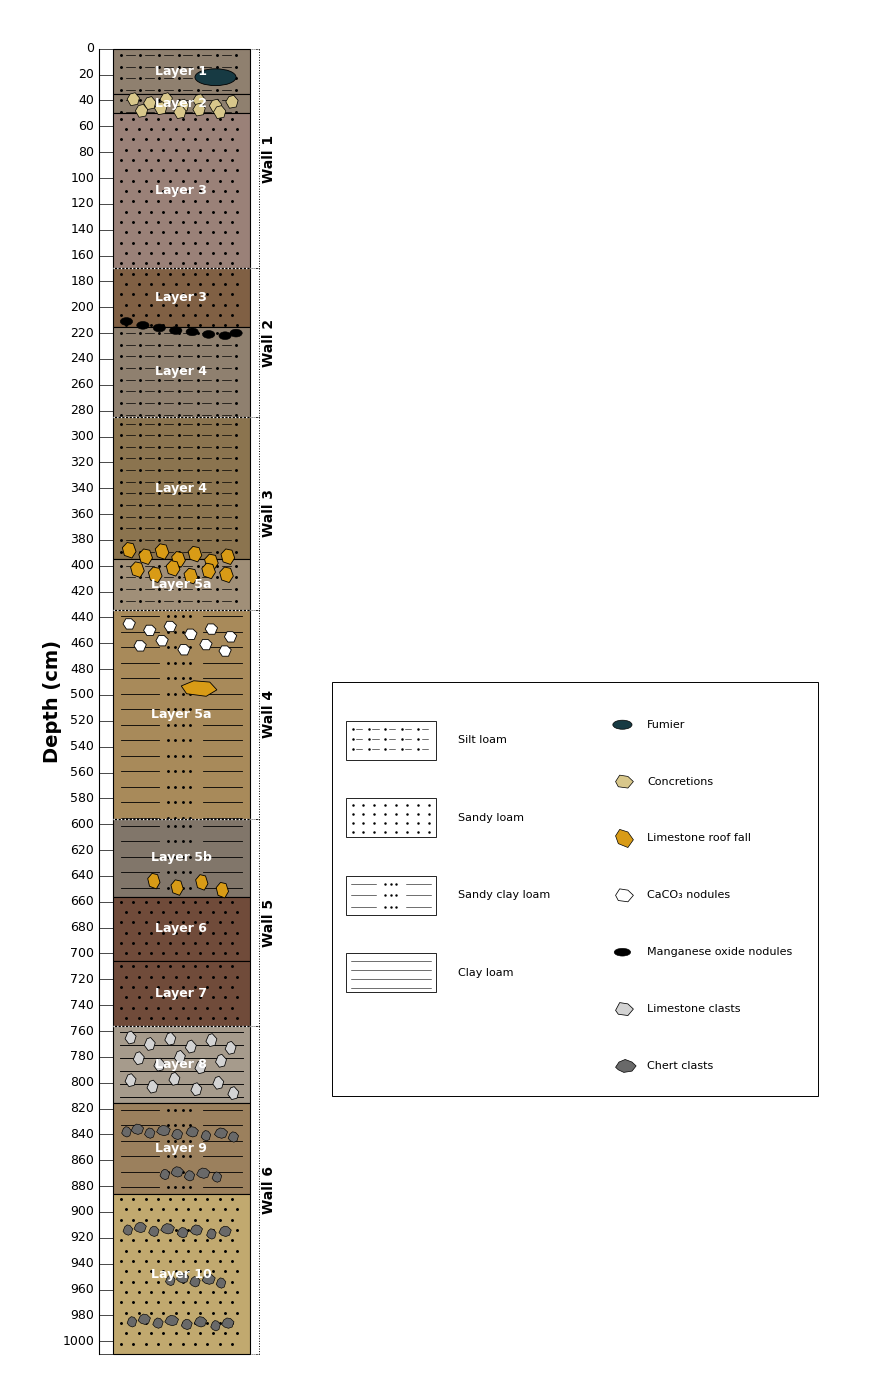

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle, Polygon, Ellipse


# ============================================================
# AZYKH CAVE — COMPLETE LITHOLOGICAL LOG
# Depth: 0–1010 cm
# ============================================================


# ============================================================
# 1. LAYER DATA
# ============================================================

layers = [
    (0,    35,   "#8F806F", "Silt loam",       "Layer 1"),
    (35,   50,   "#8F806F", "Silt loam",       "Layer 2"),
    (50,   170,  "#9A8178", "Sandy loam",      "Layer 3"),

    (170,  215,  "#806044", "Sandy loam",      "Layer 3"),
    (215,  285,  "#8F806F", "Silt loam",       "Layer 4"),

    (285,  395,  "#8B744F", "Silt loam",       "Layer 4"),
    (395,  434,  "#A08F78", "Silt loam",       "Layer 5a"),

    (434,  596,  "#A88A5A", "Sandy clay loam", "Layer 5a"),

    (596,  656,  "#81766A", "Sandy clay loam", "Layer 5b"),
    (656,  706,  "#704B3A", "Sandy loam",      "Layer 6"),
    (706,  756,  "#704B3A", "Sandy loam",      "Layer 7"),

    (756,  816,  "#A69B8C", "Clay loam",       "Layer 8"),
    (816,  886,  "#9B805D", "Sandy clay loam", "Layer 9"),
    (886, 1010,  "#C1A96F", "Sandy loam",      "Layer 10"),
]


# ============================================================
# 2. WALL DATA
# ============================================================

walls = [
    (0,    170,  "Wall 1"),
    (170,  285,  "Wall 2"),
    (285,  434,  "Wall 3"),
    (434,  596,  "Wall 4"),
    (596,  756,  "Wall 5"),
    (756, 1010,  "Wall 6"),
]


# ============================================================
# 3. FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(9, 14))

log_x = 0
log_width = 1.0


# ============================================================
# 4. CLIPPING AREA
# ============================================================

clip_box = Rectangle(
    (log_x, 0),
    log_width,
    1010,
    transform=ax.transData
)


# ============================================================
# 5. TEXTURE FUNCTION
# ============================================================

def draw_texture(ax, left, right, top, bottom, texture):

    # --------------------------------------------------------
    # SILT LOAM
    # --------------------------------------------------------

    if texture == "Silt loam":

        for y in np.arange(top + 5, bottom, 9):

            xpos = left + 0.06

            while xpos < right - 0.05:

                p, = ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.2,
                    color="black",
                    zorder=3
                )

                p.set_clip_path(clip_box)

                if xpos + 0.10 < right:

                    p, = ax.plot(
                        [xpos + 0.035, xpos + 0.10],
                        [y, y],
                        color="black",
                        linewidth=0.5,
                        zorder=3
                    )

                    p.set_clip_path(clip_box)

                xpos += 0.14


    # --------------------------------------------------------
    # SANDY LOAM
    # --------------------------------------------------------

    elif texture == "Sandy loam":

        row = 0

        for y in np.arange(top + 4, bottom, 8):

            offset = 0.04 if row % 2 else 0

            for xpos in np.arange(
                left + 0.06 + offset,
                right - 0.04,
                0.09
            ):

                p, = ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.2,
                    color="black",
                    zorder=3
                )

                p.set_clip_path(clip_box)

            row += 1


    # --------------------------------------------------------
    # SANDY CLAY LOAM
    # --------------------------------------------------------

    elif texture == "Sandy clay loam":

        for y in np.arange(top + 5, bottom, 12):

            p, = ax.plot(
                [left + 0.06, left + 0.34],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            p.set_clip_path(clip_box)

            for xpos in np.arange(
                left + 0.40,
                left + 0.61,
                0.055
            ):

                p, = ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.1,
                    color="black",
                    zorder=3
                )

                p.set_clip_path(clip_box)

            p, = ax.plot(
                [left + 0.66, right - 0.06],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            p.set_clip_path(clip_box)


    # --------------------------------------------------------
    # CLAY LOAM
    # --------------------------------------------------------

    elif texture == "Clay loam":

        for y in np.arange(top + 5, bottom, 10):

            p, = ax.plot(
                [left + 0.05, right - 0.05],
                [y, y],
                color="black",
                linewidth=0.65,
                zorder=3
            )

            p.set_clip_path(clip_box)


# ============================================================
# 6. DRAW MAIN LOG
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    rect = Rectangle(
        (log_x, top),
        log_width,
        bottom - top,
        facecolor=colour,
        edgecolor="black",
        linewidth=0.8,
        zorder=1
    )

    ax.add_patch(rect)

    draw_texture(
        ax,
        log_x,
        log_x + log_width,
        top,
        bottom,
        texture
    )


# ============================================================
# 7. SYMBOL FUNCTIONS
# ============================================================


# ------------------------------------------------------------
# FUMIER
# ------------------------------------------------------------

def fumier_symbol(ax, xc, yc):

    e = Ellipse(
        (xc, yc),
        width=0.30,
        height=13,
        facecolor="#173A43",
        edgecolor="black",
        linewidth=0.6,
        zorder=10
    )

    ax.add_patch(e)
    e.set_clip_path(clip_box)


# ------------------------------------------------------------
# CONCRETIONS
# ------------------------------------------------------------

def concretion_symbol(ax, xc, yc, size=0.045):

    p = Polygon(
        [
            (xc-size, yc),
            (xc-size*0.50, yc-4),
            (xc+size*0.30, yc-5),
            (xc+size, yc-1),
            (xc+size*0.70, yc+4),
            (xc-size*0.40, yc+5)
        ],
        closed=True,
        facecolor="#D8C78B",
        edgecolor="black",
        linewidth=0.5,
        zorder=10
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# LIMESTONE ROOF FALL
# ------------------------------------------------------------

def limestone_roof_fall(ax, xc, yc, size=0.05):

    p = Polygon(
        [
            (xc-size, yc-2),
            (xc-size*0.30, yc-6),
            (xc+size*0.60, yc-5),
            (xc+size, yc+1),
            (xc+size*0.40, yc+6),
            (xc-size*0.70, yc+4)
        ],
        closed=True,
        facecolor="#D89B16",
        edgecolor="black",
        linewidth=0.6,
        zorder=10
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# CaCO3 NODULE
# ------------------------------------------------------------

def carbonate_nodule(ax, xc, yc, size=0.045):

    p = Polygon(
        [
            (xc-size, yc),
            (xc-size*0.55, yc-4),
            (xc+size*0.35, yc-4),
            (xc+size, yc-1),
            (xc+size*0.55, yc+4),
            (xc-size*0.45, yc+4)
        ],
        closed=True,
        facecolor="white",
        edgecolor="black",
        linewidth=0.6,
        zorder=10
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# MANGANESE OXIDE NODULE
# ------------------------------------------------------------

def manganese_symbol(ax, xc, yc):

    e = Ellipse(
        (xc, yc),
        width=0.09,
        height=6,
        facecolor="black",
        edgecolor="black",
        linewidth=0.4,
        zorder=10
    )

    ax.add_patch(e)
    e.set_clip_path(clip_box)


# ------------------------------------------------------------
# LIMESTONE CLAST
# ------------------------------------------------------------

def limestone_clast(ax, xc, yc, size=0.045):

    p = Polygon(
        [
            (xc-size, yc+1),
            (xc-size*0.50, yc-4),
            (xc+size*0.15, yc-5),
            (xc+size, yc-1),
            (xc+size*0.65, yc+4),
            (xc-size*0.30, yc+5)
        ],
        closed=True,
        facecolor="lightgray",
        edgecolor="black",
        linewidth=0.55,
        zorder=12
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ------------------------------------------------------------
# CHERT CLAST
# Irregular dark-grey fragment
# ------------------------------------------------------------

def chert_clast(ax, xc, yc, size=0.045):

    p = Polygon(
        [
            (xc-size,       yc+1),
            (xc-size*0.65,  yc-2.5),
            (xc-size*0.15,  yc-4),
            (xc+size*0.45,  yc-3.5),
            (xc+size,       yc-1),
            (xc+size*0.70,  yc+3),
            (xc+size*0.10,  yc+4),
            (xc-size*0.55,  yc+3)
        ],
        closed=True,
        facecolor="dimgray",
        edgecolor="black",
        linewidth=0.45,
        zorder=12
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ============================================================
# 8. WALL 1
# Fumier + concretions
# ============================================================

fumier_symbol(
    ax,
    0.75,
    22
)


for xpos, ypos in [

    (0.15, 39),
    (0.27, 42),
    (0.39, 39),
    (0.51, 44),
    (0.63, 40),
    (0.75, 44),
    (0.87, 41),

    (0.21, 48),
    (0.35, 46),
    (0.49, 49),
    (0.63, 47),
    (0.78, 49)

]:

    concretion_symbol(ax, xpos, ypos)


# ============================================================
# 9. WALL 2
# Manganese oxide nodules
# ============================================================

for xpos, ypos in [

    (0.10, 211),
    (0.22, 214),
    (0.34, 216),
    (0.46, 218),
    (0.58, 219),
    (0.70, 221),
    (0.82, 222),
    (0.90, 220)

]:

    manganese_symbol(ax, xpos, ypos)


# ============================================================
# 10. WALL 3
# Limestone roof fall
# ============================================================

for xpos, ypos in [

    (0.12, 388),
    (0.24, 393),
    (0.36, 389),
    (0.48, 395),
    (0.60, 391),
    (0.72, 397),
    (0.84, 393),

    (0.18, 403),
    (0.31, 407),
    (0.44, 402),
    (0.57, 408),
    (0.70, 404),
    (0.83, 407)

]:

    limestone_roof_fall(ax, xpos, ypos)


# ============================================================
# 11. WALL 4
# CaCO3 nodules + limestone roof fall
# ============================================================

for xpos, ypos in [

    (0.12, 445),
    (0.27, 450),
    (0.42, 447),
    (0.57, 453),
    (0.72, 449),
    (0.86, 455),

    (0.20, 462),
    (0.36, 458),
    (0.52, 465),
    (0.68, 461),
    (0.82, 466)

]:

    carbonate_nodule(ax, xpos, ypos)


limestone_roof_fall(
    ax,
    0.63,
    495,
    size=0.13
)


# ============================================================
# 12. WALL 5
# Limestone roof fall
# ============================================================

for xpos, ypos in [

    (0.30, 644),
    (0.47, 649),
    (0.65, 645),
    (0.80, 651)

]:

    limestone_roof_fall(
        ax,
        xpos,
        ypos,
        size=0.045
    )


# ============================================================
# 13. WALL 6
# ============================================================


# ============================================================
# LAYER 8 — LIMESTONE CLASTS
# ============================================================

for xpos, ypos in [

    (0.13, 765),
    (0.27, 770),
    (0.42, 766),
    (0.57, 772),
    (0.72, 767),
    (0.86, 773),

    (0.19, 781),
    (0.34, 786),
    (0.49, 780),
    (0.64, 788),
    (0.79, 783),

    (0.13, 798),
    (0.29, 803),
    (0.45, 797),
    (0.61, 805),
    (0.77, 800),
    (0.88, 808)

]:

    limestone_clast(
        ax,
        xpos,
        ypos,
        size=0.040
    )


# ============================================================
# LAYER 9
# THIN IRREGULAR CHERT HORIZON 1
# ============================================================

for xpos, ypos, size in [

    (0.10, 838, 0.035),
    (0.18, 836, 0.045),
    (0.27, 839, 0.038),
    (0.37, 837, 0.050),
    (0.47, 840, 0.040),
    (0.58, 838, 0.045),
    (0.68, 841, 0.035),
    (0.79, 839, 0.048),
    (0.88, 842, 0.038)

]:

    chert_clast(ax, xpos, ypos, size=size)


# ============================================================
# LAYER 9
# THIN IRREGULAR CHERT HORIZON 2
# ============================================================

for xpos, ypos, size in [

    (0.38, 871, 0.035),
    (0.47, 869, 0.045),
    (0.56, 872, 0.038),
    (0.66, 870, 0.048),
    (0.76, 873, 0.035)

]:

    chert_clast(ax, xpos, ypos, size=size)


# ============================================================
# LAYER 10
# UPPER THIN CHERT HORIZON
# ============================================================

for xpos, ypos, size in [

    (0.11, 914, 0.035),
    (0.20, 912, 0.045),
    (0.30, 915, 0.038),
    (0.40, 913, 0.050),
    (0.51, 916, 0.040),
    (0.61, 914, 0.045),
    (0.72, 917, 0.035),
    (0.82, 915, 0.045)

]:

    chert_clast(ax, xpos, ypos, size=size)


# ============================================================
# LAYER 10
# MIDDLE SHORT CHERT HORIZON
# ============================================================

for xpos, ypos, size in [

    (0.42, 953, 0.035),
    (0.51, 951, 0.045),
    (0.60, 954, 0.038),
    (0.70, 952, 0.048),
    (0.79, 955, 0.035)

]:

    chert_clast(ax, xpos, ypos, size=size)


# ============================================================
# LAYER 10
# LOWER THIN CHERT HORIZON
# ============================================================

for xpos, ypos, size in [

    (0.14, 985, 0.035),
    (0.23, 983, 0.045),
    (0.33, 986, 0.038),
    (0.43, 984, 0.050),
    (0.54, 987, 0.040),
    (0.64, 985, 0.045),
    (0.75, 988, 0.035),
    (0.84, 986, 0.045)

]:

    chert_clast(ax, xpos, ypos, size=size)


# ============================================================
# 14. LAYER LABELS
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    midpoint = (top + bottom) / 2

    ax.text(
        0.50,
        midpoint,
        layer_name,
        color="white",
        fontsize=9,
        fontweight="bold",
        ha="center",
        va="center",
        rotation=0,
        zorder=30
    )


# ============================================================
# 15. WALL BRACKETS
# Small, dotted, outside log
# ============================================================

wall_x = 1.07
bracket_width = 0.025


for top, bottom, wall_name in walls:

    midpoint = (top + bottom) / 2

    ax.plot(
        [wall_x, wall_x],
        [top, bottom],
        color="black",
        linewidth=0.7,
        linestyle=":",
        zorder=15
    )

    ax.plot(
        [wall_x - bracket_width, wall_x],
        [top, top],
        color="black",
        linewidth=0.7,
        linestyle=":",
        zorder=15
    )

    ax.plot(
        [wall_x - bracket_width, wall_x],
        [bottom, bottom],
        color="black",
        linewidth=0.7,
        linestyle=":",
        zorder=15
    )

    ax.text(
        wall_x + 0.07,
        midpoint,
        wall_name,
        fontsize=10,
        fontweight="bold",
        rotation=90,
        ha="center",
        va="center",
        zorder=20
    )


# ============================================================
# 16. WALL CONNECTORS
# ============================================================

for depth in [
    0,
    170,
    285,
    434,
    596,
    756,
    1010
]:

    ax.plot(
        [1.0, wall_x],
        [depth, depth],
        color="black",
        linewidth=0.55,
        linestyle=":",
        zorder=14
    )


# ============================================================
# 17. WALL BOUNDARIES INSIDE LOG
# ============================================================

for depth in [
    170,
    285,
    434,
    596,
    756
]:

    ax.plot(
        [0, 1],
        [depth, depth],
        color="white",
        linewidth=1.0,
        linestyle=":",
        zorder=20
    )


# ============================================================
# 18. DEPTH SCALE
# ============================================================

scale_x = -0.10


ax.plot(
    [scale_x, scale_x],
    [0, 1010],
    color="black",
    linewidth=0.8
)


for depth in range(0, 1001, 20):

    ax.plot(
        [scale_x, 0],
        [depth, depth],
        color="black",
        linewidth=0.5
    )

    ax.text(
        scale_x - 0.035,
        depth,
        str(depth),
        fontsize=9,
        ha="right",
        va="center"
    )


# Bottom boundary at 1010 — no number
ax.plot(
    [scale_x, 0],
    [1010, 1010],
    color="black",
    linewidth=0.5
)


ax.text(
    scale_x - 0.34,
    505,
    "Depth (cm)",
    rotation=90,
    fontsize=14,
    fontweight="bold",
    ha="center",
    va="center"
)


# ============================================================
# 19. ONE SMALL COMBINED LEGEND BOX
# ============================================================

legend_x = 1.70
legend_y = 505

box_x = legend_x - 0.10
box_y = legend_y - 15

box_width = 3.55
box_height = 320


legend_outer = Rectangle(
    (box_x, box_y),
    box_width,
    box_height,
    facecolor="white",
    edgecolor="black",
    linewidth=0.7,
    zorder=35
)

ax.add_patch(legend_outer)


# ============================================================
# 20. LEFT SIDE OF LEGEND — TEXTURES
# ============================================================

texture_x = legend_x
texture_text_x = legend_x + 0.82

sample_w = 0.66
sample_h = 30


texture_items = [
    ("Silt loam",       15),
    ("Sandy loam",      75),
    ("Sandy clay loam", 135),
    ("Clay loam",       195)
]


for texture, offset in texture_items:

    top = legend_y + offset
    bottom = top + sample_h

    sample_box = Rectangle(
        (texture_x, top),
        sample_w,
        sample_h,
        facecolor="white",
        edgecolor="black",
        linewidth=0.6,
        zorder=40
    )

    ax.add_patch(sample_box)


    # --------------------------------------------------------
    # SILT LOAM
    # --------------------------------------------------------

    if texture == "Silt loam":

        for yy in np.arange(top + 6, bottom, 8):

            xx = texture_x + 0.05

            while xx < texture_x + sample_w - 0.04:

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.6,
                    color="black",
                    zorder=42
                )

                if xx + 0.08 < texture_x + sample_w:

                    ax.plot(
                        [xx + 0.025, xx + 0.07],
                        [yy, yy],
                        color="black",
                        linewidth=0.4,
                        zorder=42
                    )

                xx += 0.12


    # --------------------------------------------------------
    # SANDY LOAM
    # --------------------------------------------------------

    elif texture == "Sandy loam":

        for yy in np.arange(top + 5, bottom, 7):

            for xx in np.arange(
                texture_x + 0.05,
                texture_x + sample_w - 0.04,
                0.08
            ):

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.6,
                    color="black",
                    zorder=42
                )


    # --------------------------------------------------------
    # SANDY CLAY LOAM
    # --------------------------------------------------------

    elif texture == "Sandy clay loam":

        for yy in np.arange(top + 6, bottom, 9):

            ax.plot(
                [
                    texture_x + 0.04,
                    texture_x + 0.22
                ],
                [yy, yy],
                color="black",
                linewidth=0.4,
                zorder=42
            )

            for xx in [
                texture_x + 0.29,
                texture_x + 0.33,
                texture_x + 0.37
            ]:

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.5,
                    color="black",
                    zorder=42
                )

            ax.plot(
                [
                    texture_x + 0.44,
                    texture_x + 0.62
                ],
                [yy, yy],
                color="black",
                linewidth=0.4,
                zorder=42
            )


    # --------------------------------------------------------
    # CLAY LOAM
    # --------------------------------------------------------

    elif texture == "Clay loam":

        for yy in np.arange(top + 6, bottom, 7):

            ax.plot(
                [
                    texture_x + 0.04,
                    texture_x + 0.62
                ],
                [yy, yy],
                color="black",
                linewidth=0.4,
                zorder=42
            )


    ax.text(
        texture_text_x,
        (top + bottom) / 2,
        texture,
        fontsize=8,
        ha="left",
        va="center",
        zorder=45
    )


# ============================================================
# 21. RIGHT SIDE OF LEGEND — LITHOLOGICAL FEATURES
# ============================================================

symbol_x = legend_x + 1.95
symbol_text_x = symbol_x + 0.25


# ------------------------------------------------------------
# FUMIER
# ------------------------------------------------------------

yy = legend_y + 18

e = Ellipse(
    (symbol_x + 0.07, yy),
    width=0.14,
    height=7,
    facecolor="#173A43",
    edgecolor="black",
    linewidth=0.5,
    zorder=42
)

ax.add_patch(e)

ax.text(
    symbol_text_x,
    yy,
    "Fumier",
    fontsize=8,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# CONCRETIONS
# ------------------------------------------------------------

yy = legend_y + 62

p = Polygon(
    [
        (symbol_x + 0.02, yy),
        (symbol_x + 0.05, yy - 5),
        (symbol_x + 0.11, yy - 4),
        (symbol_x + 0.15, yy),
        (symbol_x + 0.11, yy + 5),
        (symbol_x + 0.04, yy + 4)
    ],
    closed=True,
    facecolor="#D8C78B",
    edgecolor="black",
    linewidth=0.5,
    zorder=42
)

ax.add_patch(p)

ax.text(
    symbol_text_x,
    yy,
    "Concretions",
    fontsize=8,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# LIMESTONE ROOF FALL
# ------------------------------------------------------------

yy = legend_y + 106

p = Polygon(
    [
        (symbol_x + 0.02, yy - 2),
        (symbol_x + 0.05, yy - 7),
        (symbol_x + 0.11, yy - 5),
        (symbol_x + 0.15, yy + 1),
        (symbol_x + 0.11, yy + 7),
        (symbol_x + 0.04, yy + 4)
    ],
    closed=True,
    facecolor="#D89B16",
    edgecolor="black",
    linewidth=0.5,
    zorder=42
)

ax.add_patch(p)

ax.text(
    symbol_text_x,
    yy,
    "Limestone roof fall",
    fontsize=8,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# CaCO3 NODULES
# ------------------------------------------------------------

yy = legend_y + 150

p = Polygon(
    [
        (symbol_x + 0.02, yy),
        (symbol_x + 0.05, yy - 5),
        (symbol_x + 0.11, yy - 4),
        (symbol_x + 0.15, yy),
        (symbol_x + 0.11, yy + 5),
        (symbol_x + 0.04, yy + 4)
    ],
    closed=True,
    facecolor="white",
    edgecolor="black",
    linewidth=0.55,
    zorder=42
)

ax.add_patch(p)

ax.text(
    symbol_text_x,
    yy,
    "CaCO₃ nodules",
    fontsize=8,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# MANGANESE OXIDE NODULES
# ------------------------------------------------------------

yy = legend_y + 194

e = Ellipse(
    (symbol_x + 0.07, yy),
    width=0.12,
    height=6,
    facecolor="black",
    edgecolor="black",
    linewidth=0.4,
    zorder=42
)

ax.add_patch(e)

ax.text(
    symbol_text_x,
    yy,
    "Manganese oxide nodules",
    fontsize=8,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# LIMESTONE CLASTS
# ------------------------------------------------------------

yy = legend_y + 238

p = Polygon(
    [
        (symbol_x + 0.02, yy + 1),
        (symbol_x + 0.05, yy - 5),
        (symbol_x + 0.11, yy - 4),
        (symbol_x + 0.15, yy),
        (symbol_x + 0.11, yy + 5),
        (symbol_x + 0.04, yy + 4)
    ],
    closed=True,
    facecolor="lightgray",
    edgecolor="black",
    linewidth=0.55,
    zorder=42
)

ax.add_patch(p)

ax.text(
    symbol_text_x,
    yy,
    "Limestone clasts",
    fontsize=8,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# CHERT CLASTS
# ------------------------------------------------------------

yy = legend_y + 282

p = Polygon(
    [
        (symbol_x + 0.02, yy + 1),
        (symbol_x + 0.045, yy - 3),
        (symbol_x + 0.09, yy - 5),
        (symbol_x + 0.14, yy - 3),
        (symbol_x + 0.17, yy),
        (symbol_x + 0.14, yy + 4),
        (symbol_x + 0.08, yy + 5),
        (symbol_x + 0.04, yy + 3)
    ],
    closed=True,
    facecolor="dimgray",
    edgecolor="black",
    linewidth=0.5,
    zorder=42
)

ax.add_patch(p)

ax.text(
    symbol_text_x,
    yy,
    "Chert clasts",
    fontsize=8,
    va="center",
    zorder=45
)


# ============================================================
# 22. FINAL FORMAT
# ============================================================

ax.set_xlim(
    -0.75,
    5.6
)

ax.set_ylim(
    1030,
    -30
)

ax.axis("off")

plt.tight_layout()


# ============================================================
# 23. SAVE HIGH-RESOLUTION FILES
# ============================================================

plt.savefig(
    "Azykh_complete_log_compact_legend.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Azykh_complete_log_compact_legend.pdf",
    bbox_inches="tight"
)


# ============================================================
# 24. SHOW
# ============================================================

plt.show()

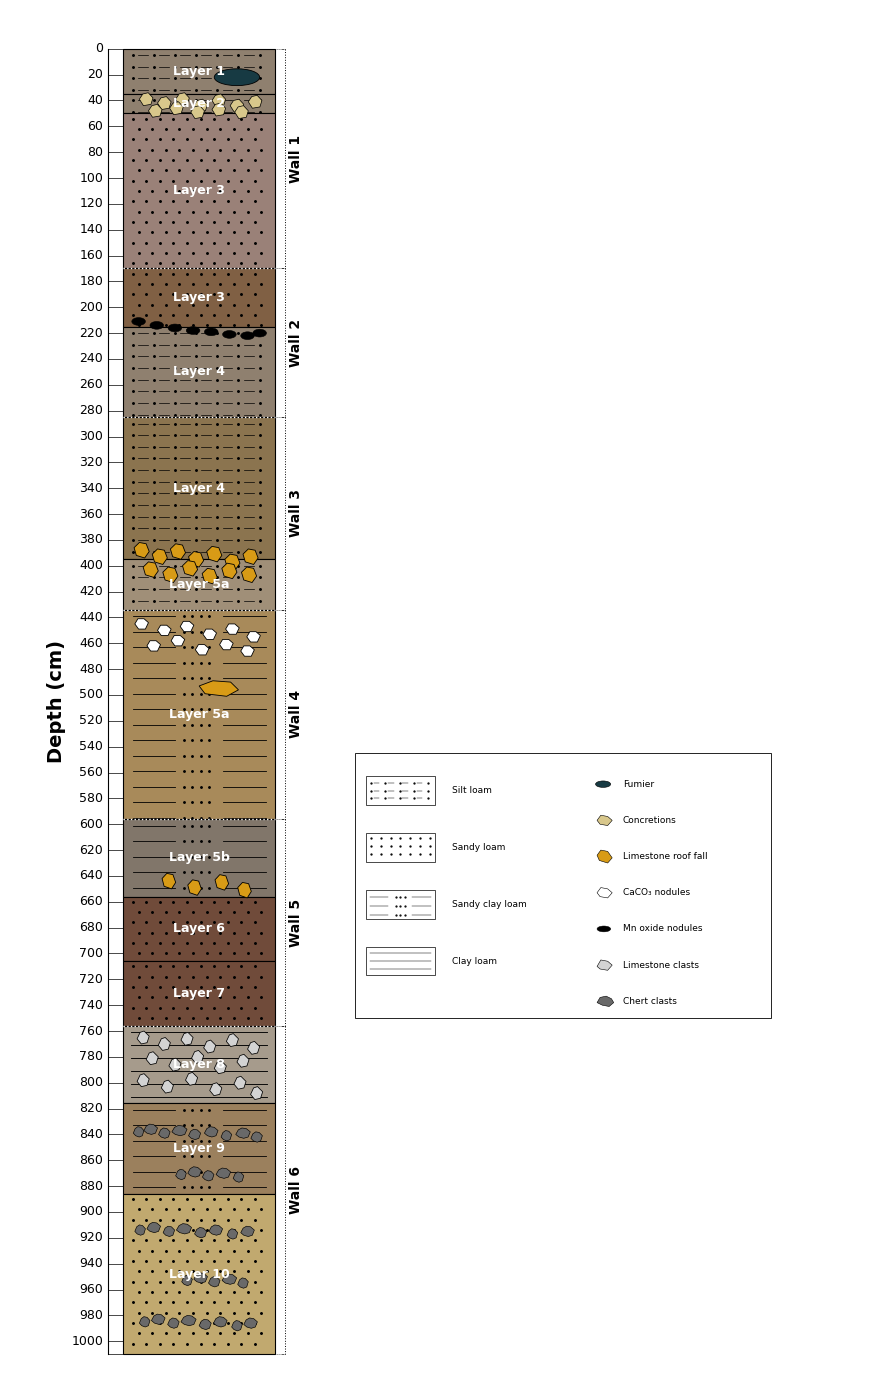

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle, Polygon, Ellipse


# ============================================================
# AZYKH CAVE — COMPLETE LITHOLOGICAL LOG
# Depth: 0–1010 cm
# ============================================================


# ============================================================
# 1. LAYER DATA
# ============================================================

layers = [
    (0,    35,   "#8F806F", "Silt loam",       "Layer 1"),
    (35,   50,   "#8F806F", "Silt loam",       "Layer 2"),
    (50,   170,  "#9A8178", "Sandy loam",      "Layer 3"),

    (170,  215,  "#806044", "Sandy loam",      "Layer 3"),
    (215,  285,  "#8F806F", "Silt loam",       "Layer 4"),

    (285,  395,  "#8B744F", "Silt loam",       "Layer 4"),
    (395,  434,  "#A08F78", "Silt loam",       "Layer 5a"),

    (434,  596,  "#A88A5A", "Sandy clay loam", "Layer 5a"),

    (596,  656,  "#81766A", "Sandy clay loam", "Layer 5b"),
    (656,  706,  "#704B3A", "Sandy loam",      "Layer 6"),
    (706,  756,  "#704B3A", "Sandy loam",      "Layer 7"),

    (756,  816,  "#A69B8C", "Clay loam",       "Layer 8"),
    (816,  886,  "#9B805D", "Sandy clay loam", "Layer 9"),
    (886, 1010,  "#C1A96F", "Sandy loam",      "Layer 10"),
]


# ============================================================
# 2. WALL DATA
# ============================================================

walls = [
    (0,    170,  "Wall 1"),
    (170,  285,  "Wall 2"),
    (285,  434,  "Wall 3"),
    (434,  596,  "Wall 4"),
    (596,  756,  "Wall 5"),
    (756, 1010,  "Wall 6"),
]


# ============================================================
# 3. FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(9, 14))

log_x = 0
log_width = 1.0


# ============================================================
# 4. CLIPPING AREA
# ============================================================

clip_box = Rectangle(
    (log_x, 0),
    log_width,
    1010,
    transform=ax.transData
)


# ============================================================
# 5. TEXTURE FUNCTION
# ============================================================

def draw_texture(ax, left, right, top, bottom, texture):

    # SILT LOAM
    if texture == "Silt loam":

        for y in np.arange(top + 5, bottom, 9):

            xpos = left + 0.06

            while xpos < right - 0.05:

                p, = ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.2,
                    color="black",
                    zorder=3
                )

                p.set_clip_path(clip_box)

                if xpos + 0.10 < right:

                    p, = ax.plot(
                        [xpos + 0.035, xpos + 0.10],
                        [y, y],
                        color="black",
                        linewidth=0.5,
                        zorder=3
                    )

                    p.set_clip_path(clip_box)

                xpos += 0.14


    # SANDY LOAM
    elif texture == "Sandy loam":

        row = 0

        for y in np.arange(top + 4, bottom, 8):

            offset = 0.04 if row % 2 else 0

            for xpos in np.arange(
                left + 0.06 + offset,
                right - 0.04,
                0.09
            ):

                p, = ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.2,
                    color="black",
                    zorder=3
                )

                p.set_clip_path(clip_box)

            row += 1


    # SANDY CLAY LOAM
    elif texture == "Sandy clay loam":

        for y in np.arange(top + 5, bottom, 12):

            p, = ax.plot(
                [left + 0.06, left + 0.34],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            p.set_clip_path(clip_box)

            for xpos in np.arange(
                left + 0.40,
                left + 0.61,
                0.055
            ):

                p, = ax.plot(
                    xpos,
                    y,
                    marker=".",
                    markersize=2.1,
                    color="black",
                    zorder=3
                )

                p.set_clip_path(clip_box)

            p, = ax.plot(
                [left + 0.66, right - 0.06],
                [y, y],
                color="black",
                linewidth=0.6,
                zorder=3
            )

            p.set_clip_path(clip_box)


    # CLAY LOAM
    elif texture == "Clay loam":

        for y in np.arange(top + 5, bottom, 10):

            p, = ax.plot(
                [left + 0.05, right - 0.05],
                [y, y],
                color="black",
                linewidth=0.65,
                zorder=3
            )

            p.set_clip_path(clip_box)


# ============================================================
# 6. DRAW MAIN LOG
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    rect = Rectangle(
        (log_x, top),
        log_width,
        bottom - top,
        facecolor=colour,
        edgecolor="black",
        linewidth=0.8,
        zorder=1
    )

    ax.add_patch(rect)

    draw_texture(
        ax,
        log_x,
        log_x + log_width,
        top,
        bottom,
        texture
    )


# ============================================================
# 7. LITHOLOGICAL SYMBOL FUNCTIONS
# ============================================================

def fumier_symbol(ax, xc, yc):

    e = Ellipse(
        (xc, yc),
        width=0.30,
        height=13,
        facecolor="#173A43",
        edgecolor="black",
        linewidth=0.6,
        zorder=10
    )

    ax.add_patch(e)
    e.set_clip_path(clip_box)


def concretion_symbol(ax, xc, yc, size=0.045):

    p = Polygon(
        [
            (xc-size, yc),
            (xc-size*0.50, yc-4),
            (xc+size*0.30, yc-5),
            (xc+size, yc-1),
            (xc+size*0.70, yc+4),
            (xc-size*0.40, yc+5)
        ],
        closed=True,
        facecolor="#D8C78B",
        edgecolor="black",
        linewidth=0.5,
        zorder=10
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


def limestone_roof_fall(ax, xc, yc, size=0.05):

    p = Polygon(
        [
            (xc-size, yc-2),
            (xc-size*0.30, yc-6),
            (xc+size*0.60, yc-5),
            (xc+size, yc+1),
            (xc+size*0.40, yc+6),
            (xc-size*0.70, yc+4)
        ],
        closed=True,
        facecolor="#D89B16",
        edgecolor="black",
        linewidth=0.6,
        zorder=10
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


def carbonate_nodule(ax, xc, yc, size=0.045):

    p = Polygon(
        [
            (xc-size, yc),
            (xc-size*0.55, yc-4),
            (xc+size*0.35, yc-4),
            (xc+size, yc-1),
            (xc+size*0.55, yc+4),
            (xc-size*0.45, yc+4)
        ],
        closed=True,
        facecolor="white",
        edgecolor="black",
        linewidth=0.6,
        zorder=10
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


def manganese_symbol(ax, xc, yc):

    e = Ellipse(
        (xc, yc),
        width=0.09,
        height=6,
        facecolor="black",
        edgecolor="black",
        linewidth=0.4,
        zorder=10
    )

    ax.add_patch(e)
    e.set_clip_path(clip_box)


def limestone_clast(ax, xc, yc, size=0.045):

    p = Polygon(
        [
            (xc-size, yc+1),
            (xc-size*0.50, yc-4),
            (xc+size*0.15, yc-5),
            (xc+size, yc-1),
            (xc+size*0.65, yc+4),
            (xc-size*0.30, yc+5)
        ],
        closed=True,
        facecolor="lightgray",
        edgecolor="black",
        linewidth=0.55,
        zorder=12
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


def chert_clast(ax, xc, yc, size=0.045):

    p = Polygon(
        [
            (xc-size,       yc+1),
            (xc-size*0.65,  yc-2.5),
            (xc-size*0.15,  yc-4),
            (xc+size*0.45,  yc-3.5),
            (xc+size,       yc-1),
            (xc+size*0.70,  yc+3),
            (xc+size*0.10,  yc+4),
            (xc-size*0.55,  yc+3)
        ],
        closed=True,
        facecolor="dimgray",
        edgecolor="black",
        linewidth=0.45,
        zorder=12
    )

    ax.add_patch(p)
    p.set_clip_path(clip_box)


# ============================================================
# 8. WALL 1
# ============================================================

fumier_symbol(ax, 0.75, 22)

for xpos, ypos in [

    (0.15, 39),
    (0.27, 42),
    (0.39, 39),
    (0.51, 44),
    (0.63, 40),
    (0.75, 44),
    (0.87, 41),

    (0.21, 48),
    (0.35, 46),
    (0.49, 49),
    (0.63, 47),
    (0.78, 49)

]:

    concretion_symbol(ax, xpos, ypos)


# ============================================================
# 9. WALL 2
# MANGANESE OXIDE NODULES
# ============================================================

for xpos, ypos in [

    (0.10, 211),
    (0.22, 214),
    (0.34, 216),
    (0.46, 218),
    (0.58, 219),
    (0.70, 221),
    (0.82, 222),
    (0.90, 220)

]:

    manganese_symbol(ax, xpos, ypos)


# ============================================================
# 10. WALL 3
# LIMESTONE ROOF FALL
# ============================================================

for xpos, ypos in [

    (0.12, 388),
    (0.24, 393),
    (0.36, 389),
    (0.48, 395),
    (0.60, 391),
    (0.72, 397),
    (0.84, 393),

    (0.18, 403),
    (0.31, 407),
    (0.44, 402),
    (0.57, 408),
    (0.70, 404),
    (0.83, 407)

]:

    limestone_roof_fall(ax, xpos, ypos)


# ============================================================
# 11. WALL 4
# CaCO3 NODULES + LIMESTONE ROOF FALL
# ============================================================

for xpos, ypos in [

    (0.12, 445),
    (0.27, 450),
    (0.42, 447),
    (0.57, 453),
    (0.72, 449),
    (0.86, 455),

    (0.20, 462),
    (0.36, 458),
    (0.52, 465),
    (0.68, 461),
    (0.82, 466)

]:

    carbonate_nodule(ax, xpos, ypos)


limestone_roof_fall(
    ax,
    0.63,
    495,
    size=0.13
)


# ============================================================
# 12. WALL 5
# LIMESTONE ROOF FALL
# ============================================================

for xpos, ypos in [

    (0.30, 644),
    (0.47, 649),
    (0.65, 645),
    (0.80, 651)

]:

    limestone_roof_fall(
        ax,
        xpos,
        ypos,
        size=0.045
    )


# ============================================================
# 13. WALL 6 — LAYER 8
# LIMESTONE CLASTS
# ============================================================

for xpos, ypos in [

    (0.13, 765),
    (0.27, 770),
    (0.42, 766),
    (0.57, 772),
    (0.72, 767),
    (0.86, 773),

    (0.19, 781),
    (0.34, 786),
    (0.49, 780),
    (0.64, 788),
    (0.79, 783),

    (0.13, 798),
    (0.29, 803),
    (0.45, 797),
    (0.61, 805),
    (0.77, 800),
    (0.88, 808)

]:

    limestone_clast(
        ax,
        xpos,
        ypos,
        size=0.040
    )


# ============================================================
# 14. WALL 6 — LAYER 9
# FIRST THIN IRREGULAR CHERT HORIZON
# ============================================================

for xpos, ypos, size in [

    (0.10, 838, 0.035),
    (0.18, 836, 0.045),
    (0.27, 839, 0.038),
    (0.37, 837, 0.050),
    (0.47, 840, 0.040),
    (0.58, 838, 0.045),
    (0.68, 841, 0.035),
    (0.79, 839, 0.048),
    (0.88, 842, 0.038)

]:

    chert_clast(ax, xpos, ypos, size=size)


# ============================================================
# 15. WALL 6 — LAYER 9
# SECOND SHORT CHERT HORIZON
# ============================================================

for xpos, ypos, size in [

    (0.38, 871, 0.035),
    (0.47, 869, 0.045),
    (0.56, 872, 0.038),
    (0.66, 870, 0.048),
    (0.76, 873, 0.035)

]:

    chert_clast(ax, xpos, ypos, size=size)


# ============================================================
# 16. WALL 6 — LAYER 10
# UPPER THIN CHERT HORIZON
# ============================================================

for xpos, ypos, size in [

    (0.11, 914, 0.035),
    (0.20, 912, 0.045),
    (0.30, 915, 0.038),
    (0.40, 913, 0.050),
    (0.51, 916, 0.040),
    (0.61, 914, 0.045),
    (0.72, 917, 0.035),
    (0.82, 915, 0.045)

]:

    chert_clast(ax, xpos, ypos, size=size)


# ============================================================
# 17. WALL 6 — LAYER 10
# MIDDLE SHORT CHERT HORIZON
# ============================================================

for xpos, ypos, size in [

    (0.42, 953, 0.035),
    (0.51, 951, 0.045),
    (0.60, 954, 0.038),
    (0.70, 952, 0.048),
    (0.79, 955, 0.035)

]:

    chert_clast(ax, xpos, ypos, size=size)


# ============================================================
# 18. WALL 6 — LAYER 10
# LOWER THIN CHERT HORIZON
# ============================================================

for xpos, ypos, size in [

    (0.14, 985, 0.035),
    (0.23, 983, 0.045),
    (0.33, 986, 0.038),
    (0.43, 984, 0.050),
    (0.54, 987, 0.040),
    (0.64, 985, 0.045),
    (0.75, 988, 0.035),
    (0.84, 986, 0.045)

]:

    chert_clast(ax, xpos, ypos, size=size)


# ============================================================
# 19. LAYER LABELS
# ALL HORIZONTAL
# ============================================================

for top, bottom, colour, texture, layer_name in layers:

    midpoint = (top + bottom) / 2

    ax.text(
        0.50,
        midpoint,
        layer_name,
        color="white",
        fontsize=9,
        fontweight="bold",
        ha="center",
        va="center",
        rotation=0,
        zorder=30
    )


# ============================================================
# 20. WALL BRACKETS
# SMALL + DOTTED + OUTSIDE LOG
# ============================================================

wall_x = 1.07
bracket_width = 0.025


for top, bottom, wall_name in walls:

    midpoint = (top + bottom) / 2

    # Vertical dotted bracket
    ax.plot(
        [wall_x, wall_x],
        [top, bottom],
        color="black",
        linewidth=0.7,
        linestyle=":",
        zorder=15
    )

    # Top bracket arm
    ax.plot(
        [wall_x - bracket_width, wall_x],
        [top, top],
        color="black",
        linewidth=0.7,
        linestyle=":",
        zorder=15
    )

    # Bottom bracket arm
    ax.plot(
        [wall_x - bracket_width, wall_x],
        [bottom, bottom],
        color="black",
        linewidth=0.7,
        linestyle=":",
        zorder=15
    )

    # Wall name
    ax.text(
        wall_x + 0.07,
        midpoint,
        wall_name,
        fontsize=10,
        fontweight="bold",
        rotation=90,
        ha="center",
        va="center",
        zorder=20
    )


# ============================================================
# 21. WALL CONNECTORS
# ============================================================

for depth in [
    0,
    170,
    285,
    434,
    596,
    756,
    1010
]:

    ax.plot(
        [1.0, wall_x],
        [depth, depth],
        color="black",
        linewidth=0.55,
        linestyle=":",
        zorder=14
    )


# ============================================================
# 22. WALL BOUNDARIES INSIDE LOG
# ============================================================

for depth in [
    170,
    285,
    434,
    596,
    756
]:

    ax.plot(
        [0, 1],
        [depth, depth],
        color="white",
        linewidth=1.0,
        linestyle=":",
        zorder=20
    )


# ============================================================
# 23. DEPTH SCALE
# ============================================================

scale_x = -0.10


# Vertical scale line
ax.plot(
    [scale_x, scale_x],
    [0, 1010],
    color="black",
    linewidth=0.8
)


# Scale ticks and numbers
for depth in range(0, 1001, 20):

    ax.plot(
        [scale_x, 0],
        [depth, depth],
        color="black",
        linewidth=0.5
    )

    ax.text(
        scale_x - 0.035,
        depth,
        str(depth),
        fontsize=9,
        ha="right",
        va="center"
    )


# 1010 cm bottom boundary — no number
ax.plot(
    [scale_x, 0],
    [1010, 1010],
    color="black",
    linewidth=0.5
)


# Depth title
ax.text(
    scale_x - 0.34,
    505,
    "Depth (cm)",
    rotation=90,
    fontsize=14,
    fontweight="bold",
    ha="center",
    va="center"
)


# ============================================================
# 24. VERY SMALL COMBINED LEGEND
# ============================================================

legend_x = 1.60
legend_y = 555


# ------------------------------------------------------------
# SMALL OUTER BOX
# ------------------------------------------------------------

box_x = legend_x - 0.07
box_y = legend_y - 10

box_width = 2.75
box_height = 205


legend_outer = Rectangle(
    (box_x, box_y),
    box_width,
    box_height,
    facecolor="white",
    edgecolor="black",
    linewidth=0.6,
    zorder=35
)

ax.add_patch(legend_outer)


# ============================================================
# 25. LEGEND — LEFT COLUMN
# TEXTURES
# ============================================================

texture_x = legend_x
texture_text_x = legend_x + 0.57

sample_w = 0.46
sample_h = 22


texture_items = [
    ("Silt loam",        8),
    ("Sandy loam",      52),
    ("Sandy clay loam", 96),
    ("Clay loam",      140)
]


for texture, offset in texture_items:

    top = legend_y + offset
    bottom = top + sample_h


    # Small texture sample box
    sample_box = Rectangle(
        (texture_x, top),
        sample_w,
        sample_h,
        facecolor="white",
        edgecolor="black",
        linewidth=0.5,
        zorder=40
    )

    ax.add_patch(sample_box)


    # --------------------------------------------------------
    # SILT LOAM
    # --------------------------------------------------------

    if texture == "Silt loam":

        for yy in np.arange(top + 5, bottom, 6):

            xx = texture_x + 0.035

            while xx < texture_x + sample_w - 0.03:

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.3,
                    color="black",
                    zorder=42
                )

                if xx + 0.065 < texture_x + sample_w:

                    ax.plot(
                        [xx + 0.018, xx + 0.055],
                        [yy, yy],
                        color="black",
                        linewidth=0.35,
                        zorder=42
                    )

                xx += 0.095


    # --------------------------------------------------------
    # SANDY LOAM
    # --------------------------------------------------------

    elif texture == "Sandy loam":

        for yy in np.arange(top + 4, bottom, 6):

            for xx in np.arange(
                texture_x + 0.035,
                texture_x + sample_w - 0.025,
                0.065
            ):

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.3,
                    color="black",
                    zorder=42
                )


    # --------------------------------------------------------
    # SANDY CLAY LOAM
    # --------------------------------------------------------

    elif texture == "Sandy clay loam":

        for yy in np.arange(top + 5, bottom, 7):

            ax.plot(
                [
                    texture_x + 0.03,
                    texture_x + 0.15
                ],
                [yy, yy],
                color="black",
                linewidth=0.35,
                zorder=42
            )

            for xx in [
                texture_x + 0.20,
                texture_x + 0.23,
                texture_x + 0.26
            ]:

                ax.plot(
                    xx,
                    yy,
                    marker=".",
                    markersize=1.2,
                    color="black",
                    zorder=42
                )

            ax.plot(
                [
                    texture_x + 0.31,
                    texture_x + 0.43
                ],
                [yy, yy],
                color="black",
                linewidth=0.35,
                zorder=42
            )


    # --------------------------------------------------------
    # CLAY LOAM
    # --------------------------------------------------------

    elif texture == "Clay loam":

        for yy in np.arange(top + 5, bottom, 6):

            ax.plot(
                [
                    texture_x + 0.03,
                    texture_x + 0.43
                ],
                [yy, yy],
                color="black",
                linewidth=0.35,
                zorder=42
            )


    # Texture label
    ax.text(
        texture_text_x,
        (top + bottom) / 2,
        texture,
        fontsize=6.5,
        ha="left",
        va="center",
        zorder=45
    )


# ============================================================
# 26. LEGEND — RIGHT COLUMN
# LITHOLOGICAL FEATURES
# ============================================================

symbol_x = legend_x + 1.52
symbol_text_x = symbol_x + 0.18


# ------------------------------------------------------------
# FUMIER
# ------------------------------------------------------------

yy = legend_y + 14

e = Ellipse(
    (symbol_x + 0.05, yy),
    width=0.10,
    height=5,
    facecolor="#173A43",
    edgecolor="black",
    linewidth=0.4,
    zorder=42
)

ax.add_patch(e)

ax.text(
    symbol_text_x,
    yy,
    "Fumier",
    fontsize=6.5,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# CONCRETIONS
# ------------------------------------------------------------

yy = legend_y + 42

p = Polygon(
    [
        (symbol_x + 0.01, yy),
        (symbol_x + 0.035, yy - 4),
        (symbol_x + 0.08, yy - 3),
        (symbol_x + 0.11, yy),
        (symbol_x + 0.08, yy + 4),
        (symbol_x + 0.03, yy + 3)
    ],
    closed=True,
    facecolor="#D8C78B",
    edgecolor="black",
    linewidth=0.4,
    zorder=42
)

ax.add_patch(p)

ax.text(
    symbol_text_x,
    yy,
    "Concretions",
    fontsize=6.5,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# LIMESTONE ROOF FALL
# ------------------------------------------------------------

yy = legend_y + 70

p = Polygon(
    [
        (symbol_x + 0.01, yy - 1),
        (symbol_x + 0.035, yy - 5),
        (symbol_x + 0.08, yy - 4),
        (symbol_x + 0.11, yy + 1),
        (symbol_x + 0.08, yy + 5),
        (symbol_x + 0.025, yy + 3)
    ],
    closed=True,
    facecolor="#D89B16",
    edgecolor="black",
    linewidth=0.4,
    zorder=42
)

ax.add_patch(p)

ax.text(
    symbol_text_x,
    yy,
    "Limestone roof fall",
    fontsize=6.5,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# CaCO3 NODULES
# ------------------------------------------------------------

yy = legend_y + 98

p = Polygon(
    [
        (symbol_x + 0.01, yy),
        (symbol_x + 0.035, yy - 4),
        (symbol_x + 0.08, yy - 3),
        (symbol_x + 0.11, yy),
        (symbol_x + 0.08, yy + 4),
        (symbol_x + 0.03, yy + 3)
    ],
    closed=True,
    facecolor="white",
    edgecolor="black",
    linewidth=0.4,
    zorder=42
)

ax.add_patch(p)

ax.text(
    symbol_text_x,
    yy,
    "CaCO₃ nodules",
    fontsize=6.5,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# MANGANESE OXIDE NODULES
# ------------------------------------------------------------

yy = legend_y + 126

e = Ellipse(
    (symbol_x + 0.055, yy),
    width=0.09,
    height=4.5,
    facecolor="black",
    edgecolor="black",
    linewidth=0.35,
    zorder=42
)

ax.add_patch(e)

ax.text(
    symbol_text_x,
    yy,
    "Mn oxide nodules",
    fontsize=6.5,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# LIMESTONE CLASTS
# ------------------------------------------------------------

yy = legend_y + 154

p = Polygon(
    [
        (symbol_x + 0.01, yy + 1),
        (symbol_x + 0.035, yy - 4),
        (symbol_x + 0.08, yy - 3),
        (symbol_x + 0.11, yy),
        (symbol_x + 0.08, yy + 4),
        (symbol_x + 0.03, yy + 3)
    ],
    closed=True,
    facecolor="lightgray",
    edgecolor="black",
    linewidth=0.4,
    zorder=42
)

ax.add_patch(p)

ax.text(
    symbol_text_x,
    yy,
    "Limestone clasts",
    fontsize=6.5,
    va="center",
    zorder=45
)


# ------------------------------------------------------------
# CHERT CLASTS
# ------------------------------------------------------------

yy = legend_y + 182

p = Polygon(
    [
        (symbol_x + 0.01, yy + 1),
        (symbol_x + 0.03, yy - 3),
        (symbol_x + 0.07, yy - 4),
        (symbol_x + 0.105, yy - 2),
        (symbol_x + 0.12, yy + 1),
        (symbol_x + 0.09, yy + 4),
        (symbol_x + 0.045, yy + 3)
    ],
    closed=True,
    facecolor="dimgray",
    edgecolor="black",
    linewidth=0.4,
    zorder=42
)

ax.add_patch(p)

ax.text(
    symbol_text_x,
    yy,
    "Chert clasts",
    fontsize=6.5,
    va="center",
    zorder=45
)


# ============================================================
# 27. FINAL FORMAT
# ============================================================

ax.set_xlim(
    -0.75,
    5.0
)

ax.set_ylim(
    1030,
    -30
)

ax.axis("off")

plt.tight_layout()


# ============================================================
# 28. SAVE
# ============================================================

plt.savefig(
    "Azykh_complete_log_small_legend.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Azykh_complete_log_small_legend.pdf",
    bbox_inches="tight"
)


# ============================================================
# 29. SHOW
# ============================================================

plt.show()